In [ ]:

!git clone https://github.com/SainathGangasagare/diode-iv-predictor-Copy.git

%cd diode-iv-predictor-Copy

!python prepare_external_data.py


Cloning into 'diode-iv-predictor-Copy'...
remote: Enumerating objects: 71, done.
remote: Counting objects: 100% (71/71), done.
remote: Compressing objects: 100% (61/61), done.
remote: Total 71 (delta 24), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (71/71), 332.17 KiB | 6.04 MiB/s, done.
Resolving deltas: 100% (24/24), done.
/content/diode-iv-predictor-Copy
Read 170 valid rows from 1n4004_forward.csv
Read 41 valid rows from 1n4004_reverse.csv
Read 41 valid rows from 1n4004_reverse_10uA_range.csv
Read 120 valid rows from 1n5229b_reverse.csv
Read 120 valid rows from sb560_forward.csv
Read 41 valid rows from sb560_reverse.csv

Saved 533 rows to:
/content/diode-iv-predictor-Copy/data/processed/external_iv_measurements.csv

Review flags and measurement conditions before training.


In [ ]:

import pandas as pd

df = pd.read_csv("data/processed/external_iv_measurements.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nRows per device and bias:")
print(df.groupby(["device", "bias"]).size())

print("\nFirst 5 rows:")
display(df.head())


Dataset shape: (533, 10)

Columns:
['voltage_V', 'current_A', 'device', 'material', 'device_type', 'bias', 'source_id', 'evidence_type', 'temperature_C', 'quality_flag']

Rows per device and bias:
device   bias             
1N4004   forward              170
         reverse               82
1N5229B  reverse_breakdown    120
SB560    forward              120
         reverse               41
dtype: int64

First 5 rows:


,voltage_V,current_A,device,material,device_type,bias,source_id,evidence_type,temperature_C,quality_flag
0,0.000000,0.000000e+00,1N4004,silicon,rectifier,forward,blueberrye_io_diode_iv_measurements,direct_measurement,NaN,review_required
1,-0.000242,-1.595252e-05,1N4004,silicon,rectifier,forward,blueberrye_io_diode_iv_measurements,direct_measurement,NaN,review_required
2,0.003574,5.137439e-08,1N4004,silicon,rectifier,forward,blueberrye_io_diode_iv_measurements,direct_measurement,NaN,review_required
3,0.009415,5.388046e-08,1N4004,silicon,rectifier,forward,blueberrye_io_diode_iv_measurements,direct_measurement,NaN,review_required
4,0.014409,4.886832e-08,1N4004,silicon,rectifier,forward,blueberrye_io_diode_iv_measurements,direct_measurement,NaN,review_required


In [ ]:

import pandas as pd

df = pd.read_csv("data/processed/external_iv_measurements.csv")

print("Missing values:")
print(df[["voltage_V", "current_A", "temperature_C"]].isna().sum())

print("\nNegative voltage rows:", (df["voltage_V"] < 0).sum())
print("Negative current rows:", (df["current_A"] < 0).sum())

print("\nRows with negative voltage or current, grouped by device and bias:")
print(
    df[(df["voltage_V"] < 0) | (df["current_A"] < 0)]
    .groupby(["device", "bias"])
    .size()
)


Missing values:
voltage_V          0
current_A          0
temperature_C    533
dtype: int64

Negative voltage rows: 245
Negative current rows: 195

Rows with negative voltage or current, grouped by device and bias:
device   bias             
1N4004   forward                1
         reverse               82
1N5229B  reverse_breakdown    120
SB560    forward                2
         reverse               41
dtype: int64


In [ ]:

import pandas as pd

df = pd.read_csv("data/processed/external_iv_measurements.csv")

# Find negative readings in files labelled as forward bias.
forward = df[df["bias"] == "forward"]
odd_forward = forward[
    (forward["voltage_V"] < 0) |
    (forward["current_A"] < 0)
]

print("Forward-bias rows needing review:")
print(odd_forward[
    ["device", "voltage_V", "current_A", "bias"]
].to_string(index=False))

# Summarize the data without changing it.
print("\nRows by device and bias:")
print(df.groupby(["device", "bias"]).size())

# Save a separate report.
report = df.groupby(["device", "bias"]).agg(
    row_count=("current_A", "size"),
    min_voltage_V=("voltage_V", "min"),
    max_voltage_V=("voltage_V", "max"),
    min_current_A=("current_A", "min"),
    max_current_A=("current_A", "max"),
    missing_temperature=("temperature_C", lambda s: s.isna().sum())
).reset_index()

report.to_csv("data_quality_report.csv", index=False)

print("\nSaved data_quality_report.csv")


Forward-bias rows needing review:
device  voltage_V  current_A    bias
1N4004  -0.000242  -0.000016 forward
 SB560  -0.000080  -0.000018 forward
 SB560   0.000008  -0.000014 forward

Rows by device and bias:
device   bias             
1N4004   forward              170
         reverse               82
1N5229B  reverse_breakdown    120
SB560    forward              120
         reverse               41
dtype: int64

Saved data_quality_report.csv


In [ ]:

import pandas as pd

input_file = "data/processed/external_iv_measurements.csv"
df = pd.read_csv(input_file)

df["review_note"] = "No automatic issue detected"

# Flag unusual readings in files labelled forward bias.
mask = (
    (df["bias"] == "forward") &
    (
        (df["voltage_V"] < 0) |
        (df["current_A"] < 0)
    )
)

df.loc[mask, "review_note"] = (
    "Review near-zero negative reading; preserved"
)

output_file = "data/processed/external_iv_measurements_review.csv"
df.to_csv(output_file, index=False)

print("Saved review copy:", output_file)
print("\nRows flagged for review:", mask.sum())
print("\nReview notes:")
print(df.loc[mask, [
    "device", "voltage_V", "current_A", "review_note"
]].to_string(index=False))


Saved review copy: data/processed/external_iv_measurements_review.csv

Rows flagged for review: 3

Review notes:
device  voltage_V  current_A                                  review_note
1N4004  -0.000242  -0.000016 Review near-zero negative reading; preserved
 SB560  -0.000080  -0.000018 Review near-zero negative reading; preserved
 SB560   0.000008  -0.000014 Review near-zero negative reading; preserved


In [ ]:

from google.colab import files

files.download(
    "data/processed/external_iv_measurements_review.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving dataverse_files.zip to dataverse_files.zip


In [ ]:
import zipfile

zip_path = "dataverse_files.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    file_list = z.namelist()

print("Total files:", len(file_list))
print("\nFirst 40 filenames:")
for name in file_list[:40]:
    print(name)

Total files: 143

First 40 filenames:
Diode/
Diode/Diode_1N1190.png
Diode/Diode_1N1190.csv
Diode/Diode_1N3913.png
Diode/Diode_1N3913.csv
Diode/Diode_30FQ030.png
Diode/Diode_APT2X31D120J.png
Diode/Diode_BYT65B800.csv
Diode/Diode_BYT61 B800.png
Diode/Diode_BYS350.png
Diode/Diode_A117M.csv
Diode/Diode_45L120.png
Diode/Diode_45L120.csv
Diode/Diode_1N11877R.csv
Diode/Diode_30FQ030.csv
Diode/Diode_APT2X31D120J.csv
Diode/Diode_BYT61 B800.csv
Diode/Diode_BYS350.csv
Diode/Diode_1N11877R.png
Diode/Diode_BYT65B800.png
Diode/Diode_A117M.png
Diode/Diode_R18CR16A.csv
Diode/Diode_SD1100C04C.png
Diode/Diode_SD1100C08L.png
Diode/Diode_STTH15RQ06DY.csv
Diode/Diode_FERD20H100S.png
Diode/Diode_M079NYC200.csv
Diode/Diode_ STTH8R04D.png
Diode/Diode_STPSC12065DY.png
Diode/Diode_RFS30TZ6S.png
Diode/Diode_STTH61W04S.png
Diode/Diode_FERD20H60CTS.csv
Diode/Diode_MBR4035.png
Diode/Diode_SD1100C16C.csv
Diode/Diode_R720.csv
Diode/Diode_RFS30TZ6S.csv
Diode/Diode_VS-ETU3006FP-M3.csv
Diode/Diode_STTH15RQ06WY.png
Diode

In [ ]:
import zipfile
import pandas as pd
from io import BytesIO

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    csv_path = "Diode/Diode_1N1190.csv"
    with z.open(csv_path) as f:
        sample = pd.read_csv(BytesIO(f.read()))

print("File:", csv_path)
print("Shape:", sample.shape)
print("Columns:", sample.columns.tolist())
display(sample.head(10))

File: Diode/Diode_1N1190.csv
Shape: (39, 4)
Columns: [' Type', ' Diode', 'Unnamed: 2', 'Unnamed: 3']


,Type,Diode,Unnamed: 2,Unnamed: 3
0,Reference,1N1190,NaN,NaN
1,Technology,Silicon Standard Recovery Diode,NaN,NaN
2,Package,DO-5,NaN,NaN
3,Date,20241203,NaN,NaN
4,Authors,yasmine.baazizi@centralesupelec.fr,NaN,NaN
5,Comments,,NaN,NaN
6,NaN,NaN,NaN,NaN
7,V [V] @293 K,I [A] @293 K,V [V] @77 K,I [A] @77 K
8,0.0000,0.0000,0.0000,0.0000
9,0.0515,0.0010,0.0519,0.0010


In [ ]:
import zipfile
import pandas as pd
from io import BytesIO

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    with z.open("Diode/Diode_1N1190.csv") as f:
        df = pd.read_csv(f, skiprows=8, header=None)

df.columns = [
    "voltage_293K_V",
    "current_293K_A",
    "voltage_77K_V",
    "current_77K_A"
]

print("Measurement rows:", len(df))
print("\nMissing values:")
print(df.isna().sum())

display(df.head())
display(df.tail())

Measurement rows: 32

Missing values:
voltage_293K_V    10
current_293K_A    10
voltage_77K_V      0
current_77K_A      0
dtype: int64


,voltage_293K_V,current_293K_A,voltage_77K_V,current_77K_A
0,V [V] @293 K,I [A] @293 K,V [V] @77 K,I [A] @77 K
1,0.0000,0.0000,0.0000,0.0000
2,0.0515,0.0010,0.0519,0.0010
3,0.6960,0.2390,1.0490,0.2550
4,0.7512,0.9060,1.0842,1.2690


,voltage_293K_V,current_293K_A,voltage_77K_V,current_77K_A
27,NaN,NaN,1.2833,36.7770
28,NaN,NaN,1.2867,38.3230
29,NaN,NaN,1.2895,39.8680
30,NaN,NaN,1.2916,41.4080
31,NaN,NaN,1.2927,42.9230


In [ ]:
import zipfile
import pandas as pd

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    with z.open("Diode/Diode_1N1190.csv") as f:
        raw = pd.read_csv(f, skiprows=9, header=None)

raw.columns = [
    "voltage_293K_V",
    "current_293K_A",
    "voltage_77K_V",
    "current_77K_A"
]

room = raw[["voltage_293K_V", "current_293K_A"]].copy()
cold = raw[["voltage_77K_V", "current_77K_A"]].copy()

room = room.apply(pd.to_numeric, errors="coerce").dropna()
cold = cold.apply(pd.to_numeric, errors="coerce").dropna()

print("293 K valid rows:", len(room))
print("77 K valid rows:", len(cold))

print("\n293 K sample:")
display(room.head())

print("\n77 K sample:")
display(cold.head())

293 K valid rows: 21
77 K valid rows: 31

293 K sample:


,voltage_293K_V,current_293K_A
0,0.0000,0.000
1,0.0515,0.001
2,0.6960,0.239
3,0.7512,0.906
4,0.7949,2.264



77 K sample:


,voltage_77K_V,current_77K_A
0,0.0000,0.000
1,0.0519,0.001
2,1.0490,0.255
3,1.0842,1.269
4,1.1068,2.644


In [ ]:
import zipfile

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    csv_files = [
        name for name in z.namelist()
        if name.lower().endswith(".csv")
    ]

print("Total CSV files:", len(csv_files))
for name in csv_files:
    print(name)

Total CSV files: 70
Diode/Diode_1N1190.csv
Diode/Diode_1N3913.csv
Diode/Diode_BYT65B800.csv
Diode/Diode_A117M.csv
Diode/Diode_45L120.csv
Diode/Diode_1N11877R.csv
Diode/Diode_30FQ030.csv
Diode/Diode_APT2X31D120J.csv
Diode/Diode_BYT61 B800.csv
Diode/Diode_BYS350.csv
Diode/Diode_R18CR16A.csv
Diode/Diode_STTH15RQ06DY.csv
Diode/Diode_M079NYC200.csv
Diode/Diode_FERD20H60CTS.csv
Diode/Diode_SD1100C16C.csv
Diode/Diode_R720.csv
Diode/Diode_RFS30TZ6S.csv
Diode/Diode_VS-ETU3006FP-M3.csv
Diode/Diode_STPS160H100TV.csv
Diode/Diode_STPSC12065DY.csv
Diode/Diode_MR5106.csv
Diode/Diode_SD1100C08L.csv
Diode/Diode_FERD20H100S.csv
Diode/Diode_STTH15RQ06WY.csv
Diode/Diode_MBR4035.csv
Diode/Diode_M10022LC200.csv
Diode/Diode_STTH20R04.csv
Diode/Diode_STTH61W04S.csv
Diode/Diode_ FFSH3065B.csv
Diode/Diode_ STTH8R04D.csv
Diode/Diode_FFSH3065B-F085.csv
Diode/Diode_SD1100C04C.csv
Diode/Diode_RBQ30NS100A.csv
Diode/Diode_SD1100C25C.csv
Diode/Diode_VS-E5PX6006LHN3.csv
Diode/Diode_BZW1336.csv
Diode/Diode_ESM25550R.csv

In [ ]:
import zipfile
import pandas as pd
from io import BytesIO

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    csv_files = [
        name for name in z.namelist()
        if name.lower().endswith(".csv")
    ]

    for path in csv_files[:5]:
        with z.open(path) as f:
            raw = pd.read_csv(f, header=None)

        print("\nFile:", path)
        print("Shape:", raw.shape)
        print(raw.head(9).to_string(index=False, header=False))


File: Diode/Diode_1N1190.csv
Shape: (40, 4)
        Type                               Diode          NaN          NaN
   Reference                              1N1190          NaN          NaN
  Technology    Silicon Standard  Recovery Diode          NaN          NaN
     Package                                DO-5          NaN          NaN
        Date                            20241203          NaN          NaN
     Authors  yasmine.baazizi@centralesupelec.fr          NaN          NaN
    Comments                                              NaN          NaN
         NaN                                 NaN          NaN          NaN
V [V] @293 K                        I [A] @293 K  V [V] @77 K  I [A] @77 K

File: Diode/Diode_1N3913.csv
Shape: (46, 4)
        Type                                     Diode          NaN          NaN
   Reference                                    1N3913          NaN          NaN
  Technology  HIGH RELIABILITY FAST RECOVERY RECTIFIER          NaN      

In [ ]:
import zipfile
import pandas as pd
from io import BytesIO

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    csv_files = [
        n for n in z.namelist()
        if n.lower().endswith(".csv")
    ]

    errors = []

    for path in csv_files:
        try:
            with z.open(path) as f:
                raw = pd.read_csv(
                    BytesIO(f.read()),
                    header=None,
                    engine="python",
                    on_bad_lines="skip"
                )

            metadata = {}
            for _, row in raw.iterrows():
                key = str(row.iloc[0]).strip()
                value = str(row.iloc[1]).strip() if len(row) > 1 else ""

                if key in ["Reference", "Technology"]:
                    metadata[key] = value

            print(
                path.split("/")[-1],
                "| Reference:", metadata.get("Reference", "Unknown"),
                "| Technology:", metadata.get("Technology", "Unknown")
            )

        except Exception as e:
            errors.append((path, str(e)))

print("\nFiles that could not be inspected:", len(errors))
for path, error in errors:
    print(path, "|", error)

Diode_1N1190.csv | Reference: 1N1190 | Technology: Silicon Standard  Recovery Diode
Diode_1N3913.csv | Reference: 1N3913 | Technology: HIGH RELIABILITY FAST RECOVERY RECTIFIER
Diode_BYT65B800.csv | Reference: BYT65B800 | Technology: High Voltage Superswitch Soft Recovery
Diode_A117M.csv | Reference: A117M | Technology: Fast Recovery Rectifier
Diode_45L120.csv | Reference: 45L120 | Technology: Silicon Power Diode
Diode_1N11877R.csv | Reference: Unknown | Technology: Unknown
Diode_30FQ030.csv | Reference: 30FQ030 | Technology: Schottky Rectifiers
Diode_APT2X31D120J.csv | Reference: APT2X31D120J | Technology: Fast Recovery Rectifiers
Diode_BYT61 B800.csv | Reference: BYT61 B800 | Technology: /
Diode_BYS350.csv | Reference: BYS350 | Technology: /
Diode_R18CR16A.csv | Reference: R18CR16A | Technology: Diffused Junction Rectifier
Diode_STTH15RQ06DY.csv | Reference: STTH15RQ06DY | Technology: Automotive turbo 2 ultrafast high voltage rectifier
Diode_M079NYC200.csv | Reference: M079NYC200 | Te

In [ ]:
import zipfile
import pandas as pd
from io import BytesIO

results = []

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    csv_files = [
        n for n in z.namelist()
        if n.lower().endswith(".csv")
    ]

    for path in csv_files:
        with z.open(path) as f:
            raw = pd.read_csv(
                BytesIO(f.read()),
                header=None,
                engine="python",
                on_bad_lines="skip"
            )

        # Find the row containing the measurement headers
        header_rows = raw.index[
            raw.iloc[:, 0].astype(str).str.contains(
                r"V\s*\[V\]\s*@293\s*K", case=False, regex=True
            )
        ]

        if len(header_rows) == 0:
            results.append({
                "file": path,
                "rows_293K": 0,
                "rows_77K": 0,
                "status": "Header not found"
            })
            continue

        start = header_rows[0] + 1
        data = raw.iloc[start:, :4].copy()

        counts = []
        for cols in [(0, 1), (2, 3)]:
            pair = data.iloc[:, list(cols)].apply(
                pd.to_numeric, errors="coerce"
            ).dropna()
            counts.append(len(pair))

        results.append({
            "file": path,
            "rows_293K": counts[0],
            "rows_77K": counts[1],
            "status": "OK" if sum(counts) > 0 else "No numeric data"
        })

report = pd.DataFrame(results)

print("Files checked:", len(report))
print("\nStatus summary:")
print(report["status"].value_counts())

print("\nTotal numeric measurements at 293 K:", report["rows_293K"].sum())
print("Total numeric measurements at 77 K:", report["rows_77K"].sum())

display(report.head(10))

Files checked: 70

Status summary:
status
OK                  67
Header not found     3
Name: count, dtype: int64

Total numeric measurements at 293 K: 1804
Total numeric measurements at 77 K: 2231


,file,rows_293K,rows_77K,status
0,Diode/Diode_1N1190.csv,21,31,OK
1,Diode/Diode_1N3913.csv,19,37,OK
2,Diode/Diode_BYT65B800.csv,24,32,OK
3,Diode/Diode_A117M.csv,26,38,OK
4,Diode/Diode_45L120.csv,24,32,OK
5,Diode/Diode_1N11877R.csv,0,0,Header not found
6,Diode/Diode_30FQ030.csv,26,32,OK
7,Diode/Diode_APT2X31D120J.csv,27,36,OK
8,Diode/Diode_BYT61 B800.csv,26,33,OK
9,Diode/Diode_BYS350.csv,23,30,OK


In [ ]:
print(
    report.loc[
        report["status"] == "Header not found",
        "file"
    ].to_string(index=False)
)

    Diode/Diode_1N11877R.csv
Diode/Diode_FERD20H60CTS.csv
    Diode/Diode_DD89N12K.csv


In [ ]:
import zipfile
import pandas as pd
from io import BytesIO

files_to_check = [
    "Diode/Diode_1N11877R.csv",
    "Diode/Diode_FERD20H60CTS.csv",
    "Diode/Diode_DD89N12K.csv",
]

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    for path in files_to_check:
        print("\n" + "=" * 60)
        print("FILE:", path)

        with z.open(path) as f:
            raw = pd.read_csv(
                BytesIO(f.read()),
                header=None,
                engine="python",
                on_bad_lines="skip"
            )

        print("Shape:", raw.shape)
        print(raw.head(15).to_string(index=False, header=False))


FILE: Diode/Diode_1N11877R.csv
Shape: (8, 1)
                                % Type: Diode
                        % Reference: 1N11877R
     % Technology: Silicon Standard Recovery 
                              % Package: DO 5
                             % Date: 20241129
% Authors: yasmine.baazizi@centralesupelec.fr
                                 % Comments: 
                                            %

FILE: Diode/Diode_FERD20H60CTS.csv
Shape: (8, 1)
                                % Type: Diode
                    % Reference: FERD20H60CTS
  % Technology: field-effect rectifier diode 
                         % Package:  TO-220AB
                             % Date: 20250117
% Authors: yasmine.baazizi@centralesupelec.fr
                                 % Comments: 
                                            %

FILE: Diode/Diode_DD89N12K.csv
Shape: (8, 1)
                                % Type: Diode
                        % Reference: DD89N12K
        % Technology:  Rectifi

In [ ]:
import zipfile

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    for path in [
        "Diode/Diode_1N11877R.csv",
        "Diode/Diode_FERD20H60CTS.csv",
        "Diode/Diode_DD89N12K.csv",
    ]:
        print("\n---", path, "---")
        print(z.read(path).decode("utf-8", errors="replace"))


--- Diode/Diode_1N11877R.csv ---

% Type: Diode
% Reference: 1N11877R
% Technology: Silicon Standard Recovery 
% Package: DO 5
% Date: 20241129
% Authors: yasmine.baazizi@centralesupelec.fr
% Comments: 
%
V [V] @293 K, I [A] @293 K, V [V] @77 K, I [A] @77 K
0.0000,0.0000,0.0000,0.0000
0.0480,0.0010,0.0485,0.0010
0.6782,0.0520,1.0706,0.2130
0.7340,0.2630,1.1035,0.7360
0.7807,0.9330,1.1267,1.3710
0.8107,1.9600,1.1462,2.0330
0.8309,3.0930,1.1627,2.7130
0.8458,4.2630,1.1773,3.4030
0.8581,5.4470,1.1905,4.0990
0.8675,6.6430,1.2027,4.7990
0.8771,7.8380,1.2139,5.5020
0.8858,9.0370,1.2243,6.2080
0.8935,10.2380,1.2343,6.9150
0.9004,11.4420,1.2434,7.6250
0.9072,12.6460,1.2523,8.3360
0.9132,13.8520,1.2606,9.0480
0.9193,15.0570,1.2686,9.7610
0.9252,16.2630,1.2761,10.4750
0.9310,17.4690,1.2833,11.1900
0.9367,18.6760,1.2906,11.9050
0.9421,19.8830,1.2971,12.6210
,,1.3031,13.3380
,,1.3088,14.0560
,,1.3142,14.7740
,,1.3194,15.4930
,,1.3241,16.2130
,,1.3283,16.9330
,,1.3323,17.6530
,,1.3358,18.3740
,,1.

In [ ]:
import zipfile
import pandas as pd
from io import BytesIO

results = []

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    csv_files = [
        n for n in z.namelist()
        if n.lower().endswith(".csv")
    ]

    for path in csv_files:
        with z.open(path) as f:
            raw = pd.read_csv(
                BytesIO(f.read()),
                header=None,
                engine="python",
                on_bad_lines="skip"
            )

        # Find the measurement header, allowing a leading %
        first_col = raw.iloc[:, 0].astype(str).str.strip()
        header_rows = raw.index[
            first_col.str.contains(
                r"V\s*\[V\]\s*@293\s*K", case=False, regex=True
            )
        ]

        if len(header_rows) == 0:
            results.append({
                "file": path,
                "rows_293K": 0,
                "rows_77K": 0,
                "status": "Header not found"
            })
            continue

        data = raw.iloc[header_rows[0] + 1:, :4].copy()
        counts = []

        for cols in [(0, 1), (2, 3)]:
            pair = data.iloc[:, list(cols)].apply(
                pd.to_numeric, errors="coerce"
            ).dropna()
            counts.append(len(pair))

        results.append({
            "file": path,
            "rows_293K": counts[0],
            "rows_77K": counts[1],
            "status": "OK" if sum(counts) > 0 else "No numeric data"
        })

report = pd.DataFrame(results)

print("Files checked:", len(report))
print("\nStatus summary:")
print(report["status"].value_counts())

print("\nTotal numeric measurements at 293 K:", report["rows_293K"].sum())
print("Total numeric measurements at 77 K:", report["rows_77K"].sum())

display(report[report["status"] != "OK"])

Files checked: 70

Status summary:
status
OK                  67
Header not found     3
Name: count, dtype: int64

Total numeric measurements at 293 K: 1804
Total numeric measurements at 77 K: 2231


,file,rows_293K,rows_77K,status
5,Diode/Diode_1N11877R.csv,0,0,Header not found
13,Diode/Diode_FERD20H60CTS.csv,0,0,Header not found
45,Diode/Diode_DD89N12K.csv,0,0,Header not found


In [ ]:
import zipfile

files_to_check = [
    "Diode/Diode_1N11877R.csv",
    "Diode/Diode_FERD20H60CTS.csv",
    "Diode/Diode_DD89N12K.csv",
]

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    for path in files_to_check:
        print("\nFile:", path)
        text = z.read(path).decode("utf-8", errors="replace")

        for line in text.splitlines():
            if "@293 K" in line:
                print("Found header:", repr(line))
                break
        else:
            print("Header not found")


File: Diode/Diode_1N11877R.csv
Found header: 'V [V] @293 K, I [A] @293 K, V [V] @77 K, I [A] @77 K'

File: Diode/Diode_FERD20H60CTS.csv
Found header: 'V [V] @293 K, I [A] @293 K, V [V] @77 K, I [A] @77 K'

File: Diode/Diode_DD89N12K.csv
Found header: 'V [V] @293 K, I [A] @293 K, V [V] @77 K, I [A] @77 K'


In [ ]:
import zipfile
import pandas as pd
from io import StringIO

results = []

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    csv_files = [
        n for n in z.namelist()
        if n.lower().endswith(".csv")
    ]

    for path in csv_files:
        text = z.read(path).decode("utf-8", errors="replace")
        lines = text.splitlines()

        header_index = next(
            (
                i for i, line in enumerate(lines)
                if "@293 K" in line and "@77 K" in line
            ),
            None
        )

        if header_index is None:
            results.append({
                "file": path,
                "rows_293K": 0,
                "rows_77K": 0,
                "status": "Header not found"
            })
            continue

        # Parse only the measurement rows after the header
        measurement_text = "\n".join(lines[header_index + 1:])
        data = pd.read_csv(
            StringIO(measurement_text),
            header=None,
            names=[
                "voltage_293K_V",
                "current_293K_A",
                "voltage_77K_V",
                "current_77K_A"
            ]
        )

        counts = []
        for cols in [
            ["voltage_293K_V", "current_293K_A"],
            ["voltage_77K_V", "current_77K_A"]
        ]:
            pair = data[cols].apply(
                pd.to_numeric, errors="coerce"
            ).dropna()
            counts.append(len(pair))

        results.append({
            "file": path,
            "rows_293K": counts[0],
            "rows_77K": counts[1],
            "status": "OK" if sum(counts) > 0 else "No numeric data"
        })

report = pd.DataFrame(results)

print("Files checked:", len(report))
print("\nStatus summary:")
print(report["status"].value_counts())

print("\nTotal numeric measurements at 293 K:", report["rows_293K"].sum())
print("Total numeric measurements at 77 K:", report["rows_77K"].sum())

display(report[report["status"] != "OK"])

Files checked: 70

Status summary:
status
OK    70
Name: count, dtype: int64

Total numeric measurements at 293 K: 1886
Total numeric measurements at 77 K: 2315


,file,rows_293K,rows_77K,status


In [ ]:
report.to_csv("cryogenic_dataset_quality_report.csv", index=False)

print("Quality report saved!")
print("Rows:", len(report))
print("Files with issues:", (report["status"] != "OK").sum())

Quality report saved!
Rows: 70
Files with issues: 0


In [ ]:
import zipfile

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    for name in z.namelist():
        if any(word in name.lower() for word in [
            "license", "readme", "metadata", "citation"
        ]):
            print(name)

README.txt


In [ ]:
import zipfile

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    print(z.read("README.txt").decode("utf-8", errors="replace"))

README File
 
This README file was generated on [2026-04-20] by [L.Q.].
Last updated: [2026-04-20].
 
# GENERAL INFORMATION
 
## Dataset title: Cryogenic and Superconducting Power Electronics Database
## DOI: https://doi.org/10.57745/2AHLA6
## Contact email: loic.queval@centralesupelec.fr


# METHODOLOGICAL INFORMATION 
 
## Environmental/experimental conditions: 
## Description of sources and methods used to collect and generate data:
## Methods for processing the data: 
## Quality -assurance procedures performed on the data: 
## Other contextual information:


# DATA & FILE OVERVIEW
## File naming convention: Diode_REF, where REF is the reference of the diode
## File hierarchy convention: Diode/
 

# DATA-SPECIFIC INFORMATION FOR: Diode_REF.csv
## Column List:
	-- V [V] @293 K: diode voltage at 293 K, in volt, decimal separator is "."
	-- I [A] @293 K: diode curent at 293 K, in amp, decimal separator is "."
	-- V [V] @77 K: diode voltage at 77 K, in volt, decimal separator is "."
	--

In [ ]:
import zipfile
import pandas as pd
from io import StringIO

zip_path = "dataverse_files.zip"
records = []
metadata_records = []

with zipfile.ZipFile(zip_path, "r") as z:
    csv_files = [
        name for name in z.namelist()
        if name.lower().endswith(".csv")
    ]

    for path in csv_files:
        text = z.read(path).decode("utf-8", errors="replace")
        lines = text.splitlines()

        metadata = {}
        header_index = None

        for i, line in enumerate(lines):
            stripped = line.strip()

            if stripped.startswith("%"):
                item = stripped.lstrip("%").strip()
                if ":" in item:
                    key, value = item.split(":", 1)
                    metadata[key.strip()] = value.strip()

            if "@293 K" in stripped and "@77 K" in stripped:
                header_index = i
                break

        if header_index is None:
            continue

        device = metadata.get(
            "Reference",
            path.split("/")[-1].removeprefix("Diode_").removesuffix(".csv")
        )
        technology = metadata.get("Technology", "Unknown")

        measurement_text = "\n".join(lines[header_index + 1:])
        raw = pd.read_csv(
            StringIO(measurement_text),
            header=None,
            names=[
                "voltage_293K_V",
                "current_293K_A",
                "voltage_77K_V",
                "current_77K_A"
            ]
        )

        for temperature, voltage_col, current_col in [
            (293, "voltage_293K_V", "current_293K_A"),
            (77, "voltage_77K_V", "current_77K_A")
        ]:
            pair = raw[[voltage_col, current_col]].apply(
                pd.to_numeric, errors="coerce"
            ).dropna()

            for voltage, current in pair.itertuples(index=False, name=None):
                records.append({
                    "device": device,
                    "technology": technology,
                    "temperature_K": temperature,
                    "voltage_V": voltage,
                    "current_A": current,
                    "source_id": "cryogenic_power_electronics_database",
                    "evidence_type": "direct_measurement"
                })

        metadata_records.append({
            "file": path,
            "device": device,
            "technology": technology
        })

combined = pd.DataFrame(records)
combined.to_csv("cryogenic_diode_measurements.csv", index=False)

print("Devices processed:", len(metadata_records))
print("Measurement rows:", len(combined))
print("\nRows by temperature:")
print(combined.groupby("temperature_K").size())
print("\nUnique devices:", combined["device"].nunique())
print("\nMissing values:")
print(combined.isna().sum())
display(combined.head())

Devices processed: 70
Measurement rows: 4201

Rows by temperature:
temperature_K
77     2315
293    1886
dtype: int64

Unique devices: 70

Missing values:
device           0
technology       0
temperature_K    0
voltage_V        0
current_A        0
source_id        0
evidence_type    0
dtype: int64


,device,technology,temperature_K,voltage_V,current_A,source_id,evidence_type
0,1N1190,Unknown,293,0.0000,0.000,cryogenic_power_electronics_database,direct_measurement
1,1N1190,Unknown,293,0.0515,0.001,cryogenic_power_electronics_database,direct_measurement
2,1N1190,Unknown,293,0.6960,0.239,cryogenic_power_electronics_database,direct_measurement
3,1N1190,Unknown,293,0.7512,0.906,cryogenic_power_electronics_database,direct_measurement
4,1N1190,Unknown,293,0.7949,2.264,cryogenic_power_electronics_database,direct_measurement


In [ ]:
import zipfile

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    text = z.read("Diode/Diode_1N1190.csv").decode("utf-8")

for line in text.splitlines():
    if "Reference:" in line or "Technology:" in line:
        print(repr(line))

In [ ]:
import zipfile

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    text = z.read("Diode/Diode_1N1190.csv").decode("utf-8")

print(text[:500])

 Type, Diode,,
 Reference, 1N1190,,
 Technology, Silicon Standard  Recovery Diode,,
 Package, DO-5,,
 Date, 20241203,,
 Authors, yasmine.baazizi@centralesupelec.fr,,
 Comments, ,,
,,,
V [V] @293 K, I [A] @293 K, V [V] @77 K, I [A] @77 K
0.0000,0.0000,0.0000,0.0000
0.0515,0.0010,0.0519,0.0010
0.6960,0.2390,1.0490,0.2550
0.7512,0.9060,1.0842,1.2690
0.7949,2.2640,1.1068,2.6440
0.8239,4.0630,1.1221,4.1390
0.8451,5.9960,1.1348,5.6610
0.8620,7.9830,1.1469,7.1880
0.8763,9.9960,1.1583,8.7200
0.8883,12.0


In [ ]:
import zipfile
import pandas as pd
from io import StringIO

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    text = z.read("Diode/Diode_1N1190.csv").decode("utf-8")

metadata = {}

for line in text.splitlines():
    row = next(__import__("csv").reader([line]))
    if len(row) >= 2:
        key = row[0].strip().lstrip("%").strip()
        value = row[1].strip()

        if key in ["Reference", "Technology", "Package", "Date"]:
            metadata[key] = value

print(metadata)

{'Reference': '1N1190', 'Technology': 'Silicon Standard  Recovery Diode', 'Package': 'DO-5', 'Date': '20241203'}


In [ ]:
import zipfile
import pandas as pd
import csv
from io import StringIO

records = []

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    csv_files = [
        n for n in z.namelist()
        if n.lower().endswith(".csv")
    ]

    for path in csv_files:
        text = z.read(path).decode("utf-8", errors="replace")
        lines = text.splitlines()
        metadata = {}
        header_index = None

        for i, line in enumerate(lines):
            row = next(csv.reader([line]))
            key = row[0].strip().lstrip("%").strip() if row else ""

            if len(row) > 1 and key in ["Reference", "Technology"]:
                metadata[key] = row[1].strip()

            if "@293 K" in line and "@77 K" in line:
                header_index = i
                break

        if header_index is None:
            continue

        device = metadata.get(
            "Reference",
            path.split("/")[-1].removeprefix("Diode_").removesuffix(".csv")
        )
        technology = metadata.get("Technology", "Unknown") or "Unknown"

        raw = pd.read_csv(
            StringIO("\n".join(lines[header_index + 1:])),
            header=None,
            names=[
                "v293", "i293", "v77", "i77"
            ]
        )

        for temperature, vcol, icol in [
            (293, "v293", "i293"),
            (77, "v77", "i77")
        ]:
            pair = raw[[vcol, icol]].apply(
                pd.to_numeric, errors="coerce"
            ).dropna()

            for voltage, current in pair.itertuples(index=False, name=None):
                records.append({
                    "device": device,
                    "technology": technology,
                    "temperature_K": temperature,
                    "voltage_V": voltage,
                    "current_A": current,
                    "source_id": "cryogenic_power_electronics_database",
                    "evidence_type": "direct_measurement"
                })

combined = pd.DataFrame(records)
output_file = "cryogenic_diode_measurements.csv"
combined.to_csv(output_file, index=False)

print("Measurement rows:", len(combined))
print("Unknown technology rows:", (combined["technology"] == "Unknown").sum())
print("\nExample device metadata:")
display(
    combined[["device", "technology"]]
    .drop_duplicates()
    .head(10)
)

Measurement rows: 4201
Unknown technology rows: 172

Example device metadata:


,device,technology
0,1N1190,Silicon Standard Recovery Diode
52,1N3913,HIGH RELIABILITY FAST RECOVERY RECTIFIER
108,BYT65B800,High Voltage Superswitch Soft Recovery
164,A117M,Fast Recovery Rectifier
228,45L120,Silicon Power Diode
284,1N11877R,Unknown
336,30FQ030,Schottky Rectifiers
394,APT2X31D120J,Fast Recovery Rectifiers
457,BYT61 B800,/
516,BYS350,/


In [ ]:
unknown_devices = (
    combined.loc[
        combined["technology"].isin(["Unknown", "/", ""]),
        ["device", "technology"]
    ]
    .drop_duplicates()
    .sort_values("device")
)

print("Devices needing metadata review:", len(unknown_devices))
display(unknown_devices)

Devices needing metadata review: 7


,device,technology
284,1N11877R,Unknown
516,BYS350,/
457,BYT61 B800,/
2722,DD89N12K,Unknown
2212,ESM25550R,/
742,FERD20H60CTS,Unknown
1447,MBR4035,/


In [ ]:
import zipfile
import csv

devices_to_check = [
    "1N11877R",
    "BYS350",
    "BYT61 B800",
    "DD89N12K",
    "ESM25550R",
    "FERD20H60CTS",
    "MBR4035",
]

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    for device in devices_to_check:
        path = f"Diode/Diode_{device}.csv"
        text = z.read(path).decode("utf-8", errors="replace")

        metadata = {}
        for line in text.splitlines():
            row = next(csv.reader([line]))
            if len(row) >= 2:
                key = row[0].strip().lstrip("%").strip()
                value = row[1].strip()
                if key in ["Reference", "Technology", "Package"]:
                    metadata[key] = value

        print(device, "->", metadata)

1N11877R -> {}
BYS350 -> {'Reference': 'BYS350', 'Technology': '/', 'Package': 'DO 4'}
BYT61 B800 -> {'Reference': 'BYT61 B800', 'Technology': '/', 'Package': 'DO 5'}
DD89N12K -> {}
ESM25550R -> {'Reference': 'ESM25550R', 'Technology': '/', 'Package': 'DO 5'}
FERD20H60CTS -> {}
MBR4035 -> {'Reference': 'MBR4035', 'Technology': '/', 'Package': 'DO 5'}


In [ ]:
import zipfile
import re

metadata_fixes = {}

with zipfile.ZipFile("dataverse_files.zip", "r") as z:
    for device in ["1N11877R", "DD89N12K", "FERD20H60CTS"]:
        path = f"Diode/Diode_{device}.csv"
        text = z.read(path).decode("utf-8", errors="replace")

        reference = re.search(
            r"%\s*Reference:\s*(.+)", text
        )
        technology = re.search(
            r"%\s*Technology:\s*(.+)", text
        )

        metadata_fixes[device] = {
            "reference": reference.group(1).strip() if reference else device,
            "technology": technology.group(1).strip() if technology else "Unknown"
        }

for device, info in metadata_fixes.items():
    combined.loc[combined["device"] == device, "device"] = info["reference"]
    combined.loc[combined["device"] == info["reference"], "technology"] = info["technology"]

print("Updated metadata:")
for device, info in metadata_fixes.items():
    print(device, "->", info)

print("\nUnknown technology rows remaining:",
      (combined["technology"] == "Unknown").sum())

Updated metadata:
1N11877R -> {'reference': '1N11877R', 'technology': 'Silicon Standard Recovery'}
DD89N12K -> {'reference': 'DD89N12K', 'technology': 'Rectifier Diode Module'}
FERD20H60CTS -> {'reference': 'FERD20H60CTS', 'technology': 'field-effect rectifier diode'}

Unknown technology rows remaining: 0


In [ ]:
output_file = "cryogenic_diode_measurements.csv"

combined.to_csv(output_file, index=False)

print("Saved:", output_file)
print("Total measurement rows:", len(combined))
print("Unique devices:", combined["device"].nunique())
print(
    "Unknown technology rows:",
    (combined["technology"] == "Unknown").sum()
)

Saved: cryogenic_diode_measurements.csv
Total measurement rows: 4201
Unique devices: 70
Unknown technology rows: 0


In [ ]:
from google.colab import files

files.download("cryogenic_diode_measurements.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

df = pd.read_csv("cryogenic_diode_measurements.csv")

print("Rows:", len(df))
print("Unique devices:", df["device"].nunique())
print("\nRows by temperature:")
print(df["temperature_K"].value_counts().sort_index())

print("\nVoltage range:")
print(df["voltage_V"].min(), "to", df["voltage_V"].max(), "V")

print("\nCurrent range:")
print(df["current_A"].min(), "to", df["current_A"].max(), "A")

print("\nMissing values:")
print(df.isna().sum())

Rows: 4201
Unique devices: 70

Rows by temperature:
temperature_K
77     2315
293    1886
Name: count, dtype: int64

Voltage range:
-0.0566 to 2.8262 V

Current range:
0.0 to 165.8 A

Missing values:
device           0
technology       0
temperature_K    0
voltage_V        0
current_A        0
source_id        0
evidence_type    0
dtype: int64


In [ ]:
print(
    df.groupby(["device", "technology"])["current_A"]
      .agg(["count", "min", "max"])
      .sort_values("max", ascending=False)
      .head(10)
)

                                                         count  min      max
device         technology                                                   
45L120         Silicon Power Diode                          56  0.0  165.800
STTH120R04TV   Ultrafast recovery diode                     51  0.0  152.430
R18CR16A       Diffused Junction Rectifier                  57  0.0  101.440
VS-HFA220FA120 Ultrafast Soft Recovery Diode                50  0.0   90.802
STPS160H100TV  HIGH VOLTAGE POWER SCHOTTKY RECTIFIER        59  0.0   86.519
DD89N12K       Rectifier Diode Module                       54  0.0   72.102
ESM244 4000    Fast Tecovery Superswith Rectifier           58  0.0   66.075
1N3913         HIGH RELIABILITY FAST RECOVERY RECTIFIER     56  0.0   64.457
VS-EPU6006-N3  Ultrafast Soft Recovery Diode                60  0.0   64.098
VS-APU6006-N3  Ultrafast Soft Recovery Diode                54  0.0   63.773


In [ ]:
device_name = "45L120"

sample = (
    df[df["device"] == device_name]
    .sort_values(["temperature_K", "current_A"])
)

for temp in [293, 77]:
    print(f"\n{device_name} at {temp} K — highest 10 currents")
    display(
        sample[sample["temperature_K"] == temp]
        .nlargest(10, "current_A")[
            ["voltage_V", "current_A", "technology"]
        ]
    )


45L120 at 293 K — highest 10 currents


,voltage_V,current_A,technology
251,1.0907,165.280,Silicon Power Diode
250,1.0808,157.030,Silicon Power Diode
249,1.0698,148.120,Silicon Power Diode
248,1.0574,139.230,Silicon Power Diode
247,1.0451,130.240,Silicon Power Diode
246,1.0313,121.280,Silicon Power Diode
245,1.0173,112.320,Silicon Power Diode
244,1.0037,103.340,Silicon Power Diode
243,0.9892,94.389,Silicon Power Diode
242,0.9747,85.439,Silicon Power Diode



45L120 at 77 K — highest 10 currents


,voltage_V,current_A,technology
283,1.4102,165.80,Silicon Power Diode
282,1.4073,155.17,Silicon Power Diode
281,1.4009,149.35,Silicon Power Diode
280,1.3928,143.54,Silicon Power Diode
279,1.3846,137.74,Silicon Power Diode
278,1.3742,131.98,Silicon Power Diode
277,1.3632,126.24,Silicon Power Diode
276,1.3529,120.48,Silicon Power Diode
275,1.3421,114.72,Silicon Power Diode
274,1.3291,109.03,Silicon Power Diode


In [ ]:
measurement_cols = [
    "device",
    "temperature_K",
    "voltage_V",
    "current_A"
]

duplicates = df.duplicated(
    subset=measurement_cols,
    keep=False
)

print("Rows involved in duplicate measurements:", duplicates.sum())

if duplicates.any():
    display(
        df.loc[duplicates, measurement_cols]
        .sort_values(["device", "temperature_K", "voltage_V"])
        .head(20)
    )
else:
    print("No duplicate measurements found.")

Rows involved in duplicate measurements: 0
No duplicate measurements found.


In [ ]:
print(
    combined[["device", "technology"]]
    .drop_duplicates()
    .sort_values("technology")
    .to_string(index=False)
)

         device                                          technology
         BYS350                                                   /
        MBR4035                                                   /
      ESM25550R                                                   /
     BYT61 B800                                                   /
   STTH15RQ06WY Automotive turbo 2 ultrafast high voltage rectifier
   STTH15RQ06DY Automotive turbo 2 ultrafast high voltage rectifier
       R18CR16A                         Diffused Junction Rectifier
       BYX65400                             Fast Recovery Rectifier
       BYX62600                             Fast Recovery Rectifier
      BYX65400R                             Fast Recovery Rectifier
          A117M                             Fast Recovery Rectifier
   APT2X31D120J                            Fast Recovery Rectifiers
    ESM244 4000                  Fast Tecovery Superswith Rectifier
      ESM245600                       Fast recov

In [ ]:
device_info = combined[["device", "technology"]].drop_duplicates()

technology = device_info["technology"].str.lower()

sic = technology.str.contains("silicon carbide", na=False)
silicon = technology.str.contains(r"\bsilicon\b", na=False) & ~sic

print("Total devices:", len(device_info))
print("Explicitly mentions silicon carbide:", sic.sum())
print("Explicitly mentions silicon (excluding SiC):", silicon.sum())
print("Technology unspecified (/):", (device_info["technology"] == "/").sum())

print("\nDevices explicitly mentioning silicon carbide:")
display(device_info[sic])

Total devices: 70
Explicitly mentions silicon carbide: 4
Explicitly mentions silicon (excluding SiC): 7
Technology unspecified (/): 4

Devices explicitly mentioning silicon carbide:


,device,technology
1150,STPSC12065DY,silicon carbide power Schottky diode
1717,FFSH3065B,Silicon Carbide Schottky Diodes
1835,FFSH3065B-F085,Silicon Carbide Schottky Diode
2666,C6D20065A,Silicon Carbide Schottky Diode


In [ ]:
import pandas as pd

device_info = combined[["device", "technology"]].drop_duplicates()

technology = device_info["technology"].str.lower()
sic = technology.str.contains("silicon carbide", na=False)
silicon = technology.str.contains(r"\bsilicon\b", na=False) & ~sic

summary = pd.DataFrame([
    {"metric": "Unique devices", "value": len(device_info)},
    {"metric": "Measurement rows", "value": len(combined)},
    {"metric": "Measurements at 293 K", "value": (combined["temperature_K"] == 293).sum()},
    {"metric": "Measurements at 77 K", "value": (combined["temperature_K"] == 77).sum()},
    {"metric": "Technologies explicitly mentioning silicon carbide", "value": sic.sum()},
    {"metric": "Technologies explicitly mentioning silicon (excluding SiC)", "value": silicon.sum()},
    {"metric": "Technology unspecified", "value": (device_info["technology"] == "/").sum()},
])

summary.to_csv("cryogenic_dataset_summary.csv", index=False)
display(summary)
print("\nSaved: cryogenic_dataset_summary.csv")

,metric,value
0,Unique devices,70
1,Measurement rows,4201
2,Measurements at 293 K,1886
3,Measurements at 77 K,2315
4,Technologies explicitly mentioning silicon car...,4
5,Technologies explicitly mentioning silicon (ex...,7
6,Technology unspecified,4



Saved: cryogenic_dataset_summary.csv


In [ ]:
import zipfile
from pathlib import Path

zip_files = list(Path("/content").glob("*.zip"))
print("ZIP files found:", [f.name for f in zip_files])

ZIP files found: []


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving GaN-SchottkyIV-Measurement-v1.0.0.zip to GaN-SchottkyIV-Measurement-v1.0.0.zip


In [ ]:
import zipfile

for filename in uploaded:
    if zipfile.is_zipfile(filename):
        with zipfile.ZipFile(filename, "r") as z:
            print("ZIP file:", filename)
            print("Number of files:", len(z.namelist()))
            print("\nFirst 20 files:")
            print("\n".join(z.namelist()[:20]))

ZIP file: GaN-SchottkyIV-Measurement-v1.0.0.zip
Number of files: 13

First 20 files:
torunyunus-GaN-SchottkyIV-Measurement-1219580/
torunyunus-GaN-SchottkyIV-Measurement-1219580/.zenodo.json
torunyunus-GaN-SchottkyIV-Measurement-1219580/CITATION.cff
torunyunus-GaN-SchottkyIV-Measurement-1219580/README.md
torunyunus-GaN-SchottkyIV-Measurement-1219580/code/
torunyunus-GaN-SchottkyIV-Measurement-1219580/code/analysis_reliability_v1.py
torunyunus-GaN-SchottkyIV-Measurement-1219580/code/requirements.txt
torunyunus-GaN-SchottkyIV-Measurement-1219580/data/
torunyunus-GaN-SchottkyIV-Measurement-1219580/data/Schottky_GaN_clean_master_5189.csv
torunyunus-GaN-SchottkyIV-Measurement-1219580/results/
torunyunus-GaN-SchottkyIV-Measurement-1219580/results/GaN_data_audit_summary.csv
torunyunus-GaN-SchottkyIV-Measurement-1219580/results/GaN_reliability_revision_summary.csv
torunyunus-GaN-SchottkyIV-Measurement-1219580/results/LOTO_Linear_PCHIP.csv


In [ ]:
import zipfile
import pandas as pd
from io import BytesIO

zip_path = "GaN-SchottkyIV-Measurement-v1.0.0.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    root = next(
        n.split("/")[0]
        for n in z.namelist()
        if n.endswith("/README.md")
    )

    print("=== DATASET README ===")
    readme = z.read(f"{root}/README.md").decode("utf-8")
    print(readme[:10000])

    csv_path = f"{root}/data/Schottky_GaN_clean_master_5189.csv"
    df_gan = pd.read_csv(BytesIO(z.read(csv_path)))

print("\n=== CSV SHAPE ===")
print(df_gan.shape)

print("\n=== COLUMN NAMES ===")
print(df_gan.columns.tolist())

print("\n=== FIRST 10 ROWS ===")
display(df_gan.head(10))

print("\n=== DATA TYPES AND MISSING VALUES ===")
display(pd.DataFrame({
    "dtype": df_gan.dtypes.astype(str),
    "missing": df_gan.isna().sum()
}))

=== DATASET README ===
# GaN Schottky sparse-temperature reproducibility package

This repository accompanies the manuscript **“Reliability-Aware Measurement Planning for Sparse-Temperature I-V Characterization of an Au/Ni/n-GaN Schottky Diode.”**

## Public reproducibility contents

### data/
- `Schottky_GaN_clean_master_5189.csv` — audited canonical analysis dataset containing 5,189 experimental I-V points across 19 temperatures from 40 to 400 K. Key columns include `T_K`, `V_V`, `I_A`, and `log10_I_A`.

### results/
- `GaN_data_audit_summary.csv` — legacy-to-canonical reconciliation summary.
- `GaN_reliability_revision_summary.csv` — exact finite-schedule PCHIP `R_mean` / `R_all` / coverage summary.
- `LOTO_Linear_PCHIP.csv` — per-temperature Linear and PCHIP leave-one-temperature-out MAEs reproduced from the canonical CSV.

### code/
- `analysis_reliability_v1.py` — reference implementation of LOTO and exhaustive endpoint-retaining PCHIP schedule analysis.
- `requirements.txt` — mi

,Curve_ID,T_K,Raw_Row,V_V,I_A,log10_I_A,Bias_Region,Equal_T_Weight_Normalized,Source_File
0,T040,40,1,1.00,0.000411,-3.386560,Forward,0.904322,AS40IV.DAT
1,T040,40,2,0.99,0.000401,-3.396931,Forward,0.904322,AS40IV.DAT
2,T040,40,3,0.98,0.000392,-3.406282,Forward,0.904322,AS40IV.DAT
3,T040,40,4,0.97,0.000384,-3.415409,Forward,0.904322,AS40IV.DAT
4,T040,40,5,0.96,0.000376,-3.424523,Forward,0.904322,AS40IV.DAT
5,T040,40,6,0.95,0.000368,-3.433739,Forward,0.904322,AS40IV.DAT
6,T040,40,7,0.94,0.000360,-3.443107,Forward,0.904322,AS40IV.DAT
7,T040,40,8,0.93,0.000353,-3.452607,Forward,0.904322,AS40IV.DAT
8,T040,40,9,0.92,0.000345,-3.462294,Forward,0.904322,AS40IV.DAT
9,T040,40,10,0.91,0.000337,-3.472203,Forward,0.904322,AS40IV.DAT



=== DATA TYPES AND MISSING VALUES ===


,dtype,missing
Curve_ID,object,0
T_K,int64,0
Raw_Row,int64,0
V_V,float64,0
I_A,float64,0
log10_I_A,float64,0
Bias_Region,object,0
Equal_T_Weight_Normalized,float64,0
Source_File,object,0


In [ ]:
print("Unique temperatures:", sorted(df_gan["T_K"].unique()))
print("\nRows per temperature:")
display(df_gan.groupby("T_K").size().rename("measurement_count").to_frame())

print("\nBias regions:")
display(df_gan["Bias_Region"].value_counts().to_frame())

print("\nVoltage range:", df_gan["V_V"].min(), "to", df_gan["V_V"].max(), "V")
print("Current range:", df_gan["I_A"].min(), "to", df_gan["I_A"].max(), "A")

print("\nCurrent values that are zero or negative:",
      (df_gan["I_A"] <= 0).sum())

Unique temperatures: [np.int64(40), np.int64(60), np.int64(80), np.int64(100), np.int64(120), np.int64(140), np.int64(160), np.int64(180), np.int64(200), np.int64(220), np.int64(240), np.int64(260), np.int64(280), np.int64(300), np.int64(320), np.int64(340), np.int64(360), np.int64(380), np.int64(400)]

Rows per temperature:


,measurement_count
T_K,
40,302
60,302
80,302
100,302
120,302
140,302
160,302
180,152
200,152



Bias regions:


,count
Bias_Region,
Reverse,3568
Forward,1621



Voltage range: -2.019998 to 1.0 V
Current range: 1.63e-11 to 0.00219782 A

Current values that are zero or negative: 0


In [ ]:
import pandas as pd

gan = df_gan.copy()

# Add traceable device and material information
gan["device"] = "Au/Ni/n-GaN Schottky diode"
gan["material"] = "gallium nitride"
gan["temperature_K"] = gan["T_K"]
gan["voltage_V"] = gan["V_V"]
gan["current_A"] = gan["I_A"]
gan["source_id"] = "gan_schottky_measurement_zenodo"
gan["evidence_type"] = "direct_measurement"

# Keep the original columns and add standardized fields
gan.to_csv("gan_schottky_measurements.csv", index=False)

print("Saved rows:", len(gan))
print("Saved columns:", len(gan.columns))
print("Missing standardized values:")
display(gan[
    ["device", "material", "temperature_K",
     "voltage_V", "current_A", "source_id", "evidence_type"]
].isna().sum().to_frame("missing"))

print("\nPreview:")
display(gan[
    ["device", "material", "temperature_K",
     "voltage_V", "current_A", "Bias_Region"]
].head())

Saved rows: 5189
Saved columns: 16
Missing standardized values:


,missing
device,0
material,0
temperature_K,0
voltage_V,0
current_A,0
source_id,0
evidence_type,0



Preview:


,device,material,temperature_K,voltage_V,current_A,Bias_Region
0,Au/Ni/n-GaN Schottky diode,gallium nitride,40,1.00,0.000411,Forward
1,Au/Ni/n-GaN Schottky diode,gallium nitride,40,0.99,0.000401,Forward
2,Au/Ni/n-GaN Schottky diode,gallium nitride,40,0.98,0.000392,Forward
3,Au/Ni/n-GaN Schottky diode,gallium nitride,40,0.97,0.000384,Forward
4,Au/Ni/n-GaN Schottky diode,gallium nitride,40,0.96,0.000376,Forward


In [ ]:
from google.colab import files
files.download("gan_schottky_measurements.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

cryogenic = pd.read_csv(
    "diode-iv-predictor-Copy/data/external/cryogenic_diode_measurements.csv"
)

gan = pd.read_csv(
    "diode-iv-predictor-Copy/data/external/gan_schottky_measurements.csv"
)

print("Cryogenic dataset:", cryogenic.shape)
print("GaN dataset:", gan.shape)
print("\nCryogenic columns:")
print(cryogenic.columns.tolist())
print("\nGaN columns:")
print(gan.columns.tolist())

FileNotFoundError: [Errno 2] No such file or directory: 'diode-iv-predictor-Copy/data/external/cryogenic_diode_measurements.csv'

In [ ]:
import os

print("Current folder:", os.getcwd())
print("\nFiles and folders here:")
print(os.listdir())

Current folder: /content/diode-iv-predictor-Copy

Files and folders here:
['GaN-SchottkyIV-Measurement-v1.0.0.zip', 'data_quality_report.csv', 'gan_schottky_measurements.csv', 'cryogenic_diode_measurements.csv', '.devcontainer', 'diode_physics.py', '.git', 'random_forest_model.joblib', 'app.py', 'data', 'tuned_svr_model.joblib', 'dataverse_files.zip', 'cryogenic_dataset_quality_report.csv', 'diode_iv_data.csv', 'requirements.txt', 'test_diode_physics.py', 'prepare_external_data.py', 'cryogenic_dataset_summary.csv']


In [ ]:
import pandas as pd

cryogenic = pd.read_csv("cryogenic_diode_measurements.csv")
gan = pd.read_csv("gan_schottky_measurements.csv")

print("Cryogenic dataset:", cryogenic.shape)
print("GaN dataset:", gan.shape)

print("\nCryogenic columns:")
print(cryogenic.columns.tolist())

print("\nGaN columns:")
print(gan.columns.tolist())

Cryogenic dataset: (4201, 7)
GaN dataset: (5189, 16)

Cryogenic columns:
['device', 'technology', 'temperature_K', 'voltage_V', 'current_A', 'source_id', 'evidence_type']

GaN columns:
['Curve_ID', 'T_K', 'Raw_Row', 'V_V', 'I_A', 'log10_I_A', 'Bias_Region', 'Equal_T_Weight_Normalized', 'Source_File', 'device', 'material', 'temperature_K', 'voltage_V', 'current_A', 'source_id', 'evidence_type']


In [ ]:
print("Technology labels in cryogenic dataset:")
print(cryogenic["technology"].value_counts().to_string())

print("\nMaterial labels in GaN dataset:")
print(gan["material"].value_counts().to_string())

Technology labels in cryogenic dataset:
technology
Hyperfast Rectifier                                    460
Standard Recovery Diodes                               366
Rectifier Diode                                        297
Ultrafast Soft Recovery Diode                          280
Ultrafast recovery diode                               269
Fast Recovery Rectifier                                248
/                                                      228
Automotive turbo 2 ultrafast high voltage rectifier     85
Ultrafast soft recovery                                 82
Ultrafast recovery                                      81
Rectifier diode                                         79
High Efficiency Rectifier                               78
Field-effect Rectifier Diode                            68
Ultra Fast Recovery Diode                               67
field-effect rectifier diode                            66
Fast Recovery Rectifiers                                63
Ultra

In [ ]:
tech = cryogenic["technology"].str.lower()

print("Explicitly labelled SiC devices:",
      tech.str.contains("silicon carbide", na=False).sum())

print("Explicitly labelled silicon devices:",
      tech.str.contains(r"\bsilicon\b", na=False)
      .where(~tech.str.contains("silicon carbide", na=False), False).sum())

print("Unspecified technology rows:",
      cryogenic["technology"].eq("/").sum())

print("GaN measurements:", len(gan))

Explicitly labelled SiC devices: 228
Explicitly labelled silicon devices: 378
Unspecified technology rows: 228
GaN measurements: 5189


In [ ]:
print("Cryogenic temperatures (K):")
print(sorted(cryogenic["temperature_K"].dropna().unique()))

print("\nGaN temperature range (K):")
print("Minimum:", gan["temperature_K"].min())
print("Maximum:", gan["temperature_K"].max())
print("Unique temperatures:", gan["temperature_K"].nunique())

Cryogenic temperatures (K):
[np.int64(77), np.int64(293)]

GaN temperature range (K):
Minimum: 40
Maximum: 400
Unique temperatures: 19


In [ ]:
for name, df in [
    ("Cryogenic", cryogenic),
    ("GaN", gan)
]:
    print(f"\n{name}")
    print("Missing voltage:", df["voltage_V"].isna().sum())
    print("Missing current:", df["current_A"].isna().sum())
    print("Zero current:", (df["current_A"] == 0).sum())
    print("Negative current:", (df["current_A"] < 0).sum())


Cryogenic
Missing voltage: 0
Missing current: 0
Zero current: 159
Negative current: 0

GaN
Missing voltage: 0
Missing current: 0
Zero current: 0
Negative current: 0


In [ ]:
zero_rows = cryogenic[cryogenic["current_A"] == 0]

print("Zero-current rows by temperature:")
print(zero_rows["temperature_K"].value_counts().sort_index())

print("\nDevices with the most zero-current rows:")
print(zero_rows["device"].value_counts().head(10))

Zero-current rows by temperature:
temperature_K
77     89
293    70
Name: count, dtype: int64

Devices with the most zero-current rows:
device
VS-APU6006-N3      4
VS-E5TH3006-M3     4
VS-60APH03-N3      4
VS-EPU6006-N3      4
VS-ETU3006FP-M3    4
STTH15RQ06DY       4
VS-E4PU6006L-N3    4
VS-E5PW6006LHN3    3
VS-E5PX6006LHN3    3
STTH15RQ06WY       3
Name: count, dtype: int64


In [ ]:
for name, df in [("Cryogenic", cryogenic), ("GaN", gan)]:
    cols = ["device", "temperature_K", "voltage_V", "current_A"]
    duplicates = df.duplicated(subset=cols).sum()

    print(f"{name}: {duplicates} duplicate measurement rows")

Cryogenic: 0 duplicate measurement rows
GaN: 0 duplicate measurement rows


In [ ]:
print("Cryogenic columns:", cryogenic.columns.tolist())
print("GaN columns:", gan.columns.tolist())


Cryogenic columns: ['device', 'technology', 'temperature_K', 'voltage_V', 'current_A', 'source_id', 'evidence_type']
GaN columns: ['Curve_ID', 'T_K', 'Raw_Row', 'V_V', 'I_A', 'log10_I_A', 'Bias_Region', 'Equal_T_Weight_Normalized', 'Source_File', 'device', 'material', 'temperature_K', 'voltage_V', 'current_A', 'source_id', 'evidence_type']


In [ ]:
import pandas as pd

# Keep only the shared, standardized columns
cryogenic_clean = cryogenic[
    ["device", "temperature_K", "voltage_V",
     "current_A", "source_id", "evidence_type"]
].copy()

gan_clean = gan[
    ["device", "temperature_K", "voltage_V",
     "current_A", "source_id", "evidence_type"]
].copy()

# Add material labels from the source information
cryogenic_clean["material"] = cryogenic_clean["device"].map(
    cryogenic.drop_duplicates("device").set_index("device")["technology"]
)

gan_clean["material"] = "gallium nitride"

# Combine into a new dataset

In [ ]:
import os

print("File exists:", os.path.exists("combined_diode_measurements.csv"))

if os.path.exists("combined_diode_measurements.csv"):
    check = pd.read_csv("combined_diode_measurements.csv")
    print("Rows and columns:", check.shape)
    print(check.head())

File exists: False


In [ ]:
print("Cell is running!")
print("Cryogenic rows:", len(cryogenic))
print("GaN rows:", len(gan))

Cell is running!
Cryogenic rows: 4201
GaN rows: 5189


In [ ]:
combined = pd.concat(
    [
        cryogenic[[
            "device", "temperature_K", "voltage_V",
            "current_A", "source_id", "evidence_type"
        ]],
        gan[[
            "device", "temperature_K", "voltage_V",
            "current_A", "source_id", "evidence_type"
        ]]
    ],
    ignore_index=True
)

combined.to_csv("combined_diode_measurements.csv", index=False)

print("Combined rows:", len(combined))
print("Saved successfully!")

Combined rows: 9390
Saved successfully!


In [ ]:
check = pd.read_csv("combined_diode_measurements.csv")

print("Rows and columns:", check.shape)
print("\nRows by source:")
print(check["source_id"].value_counts())
print("\nMissing values:")
print(check[["temperature_K", "voltage_V", "current_A"]].isna().sum())

Rows and columns: (9390, 6)

Rows by source:
source_id
gan_schottky_measurement_zenodo         5189
cryogenic_power_electronics_database    4201
Name: count, dtype: int64

Missing values:
temperature_K    0
voltage_V        0
current_A        0
dtype: int64


In [ ]:
combined["material"] = "unknown"

is_gan = combined["source_id"].eq(
    "gan_schottky_measurement_zenodo"
)
combined.loc[is_gan, "material"] = "gallium nitride"

print(combined["material"].value_counts())

material
gallium nitride    5189
unknown            4201
Name: count, dtype: int64


In [ ]:
combined.to_csv("combined_diode_measurements.csv", index=False)

print("Saved updated file!")
print("Total rows:", len(combined))
print("Material labels:")
print(combined["material"].value_counts())

Saved updated file!
Total rows: 9390
Material labels:
material
gallium nitride    5189
unknown            4201
Name: count, dtype: int64


In [ ]:
from google.colab import files
files.download("combined_diode_measurements.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
device_info = cryogenic[["device", "technology"]].drop_duplicates()
print("Unique devices:", len(device_info))
display(device_info.sort_values("device"))

Unique devices: 70


,device,technology
284,1N11877R,Silicon Standard Recovery
0,1N1190,Silicon Standard Recovery Diode
52,1N3913,HIGH RELIABILITY FAST RECOVERY RECTIFIER
336,30FQ030,Schottky Rectifiers
228,45L120,Silicon Power Diode
...,...,...
3260,VS-E5TX3006-M3,Hyperfast Rectifier
3006,VS-EPU6006-N3,Ultrafast Soft Recovery Diode
1032,VS-ETU3006FP-M3,Ultrafast Rectifier
3914,VS-HFA220FA120,Ultrafast Soft Recovery Diode


In [ ]:
import pandas as pd

device_info = cryogenic[
    ["device", "technology"]
].drop_duplicates().copy()

tech = device_info["technology"].str.lower()

device_info["material_label"] = "unknown"

device_info.loc[
    tech.str.contains("silicon carbide", na=False),
    "material_label"
] = "silicon carbide"

device_info.loc[
    tech.str.contains(r"\bsilicon\b", na=False)
    & ~tech.str.contains("silicon carbide", na=False),
    "material_label"
] = "silicon"

print(device_info["material_label"].value_counts())

display(
    device_info.sort_values(
        ["material_label", "device"]
    )
)

material_label
unknown            59
silicon             7
silicon carbide     4
Name: count, dtype: int64


,device,technology,material_label
284,1N11877R,Silicon Standard Recovery,silicon
0,1N1190,Silicon Standard Recovery Diode,silicon
228,45L120,Silicon Power Diode,silicon
2441,BYX661000,Silicon Rectifier Diodes,silicon
2952,BZW12360,Low power silicon rectifier,silicon
...,...,...,...
3260,VS-E5TX3006-M3,Hyperfast Rectifier,unknown
3006,VS-EPU6006-N3,Ultrafast Soft Recovery Diode,unknown
1032,VS-ETU3006FP-M3,Ultrafast Rectifier,unknown
3914,VS-HFA220FA120,Ultrafast Soft Recovery Diode,unknown


In [ ]:
unknown_devices = device_info[
    device_info["material_label"] == "unknown"
].sort_values("device")

display(unknown_devices)

,device,technology,material_label
52,1N3913,HIGH RELIABILITY FAST RECOVERY RECTIFIER,unknown
336,30FQ030,Schottky Rectifiers,unknown
164,A117M,Fast Recovery Rectifier,unknown
394,APT2X31D120J,Fast Recovery Rectifiers,unknown
516,BYS350,/,unknown
457,BYT61 B800,/,unknown
108,BYT65B800,High Voltage Superswitch Soft Recovery,unknown
2389,BYV42E150,Rectifier diode ultrafast,unknown
2557,BYW881000,Rectifer,unknown
3066,BYW88600,Rectifier,unknown


In [ ]:
device_info.loc[
    device_info["device"] == "1N3913",
    "material_label"
] = "silicon"

print(
    device_info.loc[
        device_info["device"] == "1N3913"
    ]
)

    device                                technology material_label
52  1N3913  HIGH RELIABILITY FAST RECOVERY RECTIFIER        silicon


In [ ]:
# Map each device to our reviewed material label
material_map = device_info.set_index("device")["material_label"]

combined["material"] = combined["device"].map(material_map).fillna("unknown")

# Keep the full dataset unchanged in memory as combined;
# create a separate subset for material-specific work
verified = combined[combined["material"] != "unknown"].copy()

print("All measurements:", len(combined))
print("Verified-material measurements:", len(verified))
print("\nVerified materials:")
print(verified["material"].value_counts())

All measurements: 9390
Verified-material measurements: 662

Verified materials:
material
silicon            434
silicon carbide    228
Name: count, dtype: int64


In [ ]:
is_gan = combined["source_id"].eq(
    "gan_schottky_measurement_zenodo"
)
combined.loc[is_gan, "material"] = "gallium nitride"

verified = combined[combined["material"] != "unknown"].copy()

print("Verified-material measurements:", len(verified))
print("\nCounts by material:")
print(verified["material"].value_counts())

Verified-material measurements: 5851

Counts by material:
material
gallium nitride    5189
silicon             434
silicon carbide     228
Name: count, dtype: int64


In [ ]:
combined.to_csv("combined_diode_measurements.csv", index=False)

print("Saved corrected combined dataset.")
print("Total rows:", len(combined))
print("\nMaterial counts:")
print(combined["material"].value_counts())

Saved corrected combined dataset.
Total rows: 9390

Material counts:
material
gallium nitride    5189
unknown            3539
silicon             434
silicon carbide     228
Name: count, dtype: int64


In [ ]:
display(
    device_info[
        ["device", "technology", "material_label"]
    ].sort_values("technology")
)

,device,technology,material_label
516,BYS350,/,unknown
1447,MBR4035,/,unknown
2212,ESM25550R,/,unknown
457,BYT61 B800,/,unknown
1399,STTH15RQ06WY,Automotive turbo 2 ultrafast high voltage rect...,unknown
...,...,...,...
1774,STTH8R04D,Ultrafast recovery diode,unknown
3651,STTH120R04TV,Ultrafast recovery diode,unknown
4064,STTH812FP,Ultrafast soft recovery,unknown
742,FERD20H60CTS,field-effect rectifier diode,unknown


In [ ]:
print("Technology descriptions:")
print(device_info["technology"].value_counts().to_string())

Technology descriptions:
technology
Hyperfast Rectifier                                    8
Ultrafast recovery diode                               5
Ultrafast Soft Recovery Diode                          5
Standard Recovery Diodes                               5
Rectifier Diode                                        4
/                                                      4
Fast Recovery Rectifier                                4
Automotive turbo 2 ultrafast high voltage rectifier    2
Silicon Standard  Recovery Diode                       1
Fast Recovery Rectifiers                               1
Schottky Rectifiers                                    1
Silicon Standard Recovery                              1
Silicon Power Diode                                    1
HIGH RELIABILITY FAST RECOVERY RECTIFIER               1
High Voltage Superswitch Soft Recovery                 1
field-effect rectifier diode                           1
Rectifier diode                                     

In [ ]:
tech = device_info["technology"].str.lower()

explicit_material = device_info[
    tech.str.contains(r"\bsilicon\b|\bsilicon carbide\b", na=False)
]

display(
    explicit_material[
        ["device", "technology", "material_label"]
    ].sort_values("technology")
)

,device,technology,material_label
2270,BZW1347,Low Power Silicon Rectifier,silicon
2157,BZW1336,Low Power Silicon Rectifier Diode,silicon
2952,BZW12360,Low power silicon rectifier,silicon
1835,FFSH3065B-F085,Silicon Carbide Schottky Diode,silicon carbide
2666,C6D20065A,Silicon Carbide Schottky Diode,silicon carbide
1717,FFSH3065B,Silicon Carbide Schottky Diodes,silicon carbide
228,45L120,Silicon Power Diode,silicon
2441,BYX661000,Silicon Rectifier Diodes,silicon
0,1N1190,Silicon Standard Recovery Diode,silicon
284,1N11877R,Silicon Standard Recovery,silicon


In [ ]:
display(
    device_info[device_info["technology"] == "/"][["device", "technology"]]
)

,device,technology
457,BYT61 B800,/
516,BYS350,/
1447,MBR4035,/
2212,ESM25550R,/


In [ ]:
device_info.loc[
    device_info["device"] == "MBR4035",
    "material_label"
] = "silicon"

print(device_info[device_info["device"] == "MBR4035"])

       device technology material_label
1447  MBR4035          /        silicon


In [ ]:
# Apply the reviewed material labels to the combined measurements
material_map = device_info.set_index("device")["material_label"]

combined["material"] = combined["device"].map(material_map)

# Restore the known GaN labels from the source dataset
is_gan = combined["source_id"].eq(
    "gan_schottky_measurement_zenodo"
)
combined.loc[is_gan, "material"] = "gallium nitride"

# Keep only measurements with an identified material
filtered = combined[
    combined["material"].isin(
        ["silicon", "silicon carbide", "gallium nitride"]
    )
].copy()

filtered.to_csv("classified_diode_measurements.csv", index=False)

print("Original rows:", len(combined))
print("Classified rows:", len(filtered))
print("\nRows by material:")
print(filtered["material"].value_counts())
print("\nSaved: classified_diode_measurements.csv")

Original rows: 9390
Classified rows: 5909

Rows by material:
material
gallium nitride    5189
silicon             492
silicon carbide     228
Name: count, dtype: int64

Saved: classified_diode_measurements.csv


In [ ]:
from google.colab import files
files.download("classified_diode_measurements.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

df = pd.read_csv("classified_diode_measurements.csv")

print("Dataset shape:", df.shape)
print("\nMaterial counts:")
print(df["material"].value_counts())

print("\nMissing values:")
print(df[["material", "temperature_K", "voltage_V", "current_A"]].isna().sum())

print("\nTemperature range by material:")
print(df.groupby("material")["temperature_K"].agg(["min", "max", "nunique"]))

Dataset shape: (5909, 7)

Material counts:
material
gallium nitride    5189
silicon             492
silicon carbide     228
Name: count, dtype: int64

Missing values:
material         0
temperature_K    0
voltage_V        0
current_A        0
dtype: int64

Temperature range by material:
                 min  max  nunique
material                          
gallium nitride   40  400       19
silicon           77  293        2
silicon carbide   77  293        2


In [ ]:
print(
    df.groupby("material").agg(
        rows=("current_A", "size"),
        voltage_min=("voltage_V", "min"),
        voltage_max=("voltage_V", "max"),
        current_min=("current_A", "min"),
        current_max=("current_A", "max"),
        zero_current=("current_A", lambda x: (x == 0).sum())
    )
)

                 rows  voltage_min  voltage_max   current_min  current_max  \
material                                                                     
gallium nitride  5189    -2.019998       1.0000  1.630000e-11     0.002198   
silicon           492     0.000000       2.0558  0.000000e+00   165.800000   
silicon carbide   228     0.000000       1.7627  0.000000e+00    25.089000   

                 zero_current  
material                       
gallium nitride             0  
silicon                    18  
silicon carbide             8  


In [ ]:
for material in ["silicon", "silicon carbide"]:
    subset = df[df["material"] == material]

    print(f"\n{material.upper()} — devices with highest current")
    print(
        subset.groupby("device")["current_A"]
        .max()
        .sort_values(ascending=False)
        .head(5)
    )


SILICON — devices with highest current
device
45L120     165.800
1N3913      64.457
BZW1347     51.481
MBR4035     46.156
1N1190      42.923
Name: current_A, dtype: float64

SILICON CARBIDE — devices with highest current
device
FFSH3065B-F085    25.089
FFSH3065B         24.931
STPSC12065DY      16.122
C6D20065A          9.853
Name: current_A, dtype: float64


In [ ]:
for device in ["45L120", "1N3913", "FFSH3065B"]:
    rows = df[df["device"] == device]
    print(f"\n{device}")
    print(rows[["temperature_K", "voltage_V", "current_A"]]
          .sort_values("current_A", ascending=False)
          .head(5).to_string(index=False))


45L120
 temperature_K  voltage_V  current_A
            77     1.4102     165.80
           293     1.0907     165.28
           293     1.0808     157.03
            77     1.4073     155.17
            77     1.4009     149.35

1N3913
 temperature_K  voltage_V  current_A
           293     1.2984     64.457
           293     1.2842     60.569
           293     1.2655     56.136
           293     1.2444     51.492
           293     1.2209     46.761

FFSH3065B
 temperature_K  voltage_V  current_A
           293     1.3516     24.931
            77     1.7627     23.754
           293     1.3305     23.634
            77     1.7573     22.928
           293     1.3100     22.333


In [ ]:

import pandas as pd

df = pd.read_csv("classified_diode_measurements.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nRows per material:")
print(df["material"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (5909, 7)

Columns:
['device', 'temperature_K', 'voltage_V', 'current_A', 'source_id', 'evidence_type', 'material']

Rows per material:
material
gallium nitride    5189
silicon             492
silicon carbide     228
Name: count, dtype: int64

Missing values:
device           0
temperature_K    0
voltage_V        0
current_A        0
source_id        0
evidence_type    0
material         0
dtype: int64


In [ ]:

# Summarize the measured operating ranges by material
summary = df.groupby("material").agg(
    measurements=("current_A", "size"),
    devices=("device", "nunique"),
    temperatures=("temperature_K", "nunique"),
    min_temp_K=("temperature_K", "min"),
    max_temp_K=("temperature_K", "max"),
    min_voltage_V=("voltage_V", "min"),
    max_voltage_V=("voltage_V", "max"),
    min_current_A=("current_A", "min"),
    max_current_A=("current_A", "max"),
)

print(summary.to_string())


                 measurements  devices  temperatures  min_temp_K  max_temp_K  min_voltage_V  max_voltage_V  min_current_A  max_current_A
material                                                                                                                                
gallium nitride          5189        1            19          40         400      -2.019998         1.0000   1.630000e-11       0.002198
silicon                   492        9             2          77         293       0.000000         2.0558   0.000000e+00     165.800000
silicon carbide           228        4             2          77         293       0.000000         1.7627   0.000000e+00      25.089000


In [ ]:

# Check for repeated measurement conditions
keys = ["device", "temperature_K", "voltage_V"]

duplicate_rows = df.duplicated(subset=keys, keep=False)

print("Total measurements:", len(df))
print("Rows sharing device, temperature and voltage:",
      int(duplicate_rows.sum()))

print("\nRepeated-condition examples:")
print(
    df.loc[duplicate_rows, keys + ["current_A", "material"]]
      .sort_values(keys)
      .head(15)
      .to_string(index=False)
)

print("\nNon-positive current measurements:",
      int((df["current_A"] <= 0).sum()))


Total measurements: 5909
Rows sharing device, temperature and voltage: 0

Repeated-condition examples:
Empty DataFrame
Columns: [device, temperature_K, voltage_V, current_A, material]
Index: []

Non-positive current measurements: 26


In [ ]:

# Inspect the 26 non-positive current measurements
non_positive = df[df["current_A"] <= 0]

print(non_positive.groupby(["material", "current_A"]).size())

print("\nRows to review:")
print(
    non_positive[
        ["device", "material", "temperature_K", "voltage_V", "current_A"]
    ].to_string(index=False)
)


material         current_A
silicon          0.0          18
silicon carbide  0.0           8
dtype: int64

Rows to review:
        device        material  temperature_K  voltage_V  current_A
        1N1190         silicon            293        0.0        0.0
        1N1190         silicon             77        0.0        0.0
        1N3913         silicon            293        0.0        0.0
        1N3913         silicon             77        0.0        0.0
        45L120         silicon            293        0.0        0.0
        45L120         silicon             77        0.0        0.0
      1N11877R         silicon            293        0.0        0.0
      1N11877R         silicon             77        0.0        0.0
  STPSC12065DY silicon carbide            293        0.0        0.0
  STPSC12065DY silicon carbide             77        0.0        0.0
       MBR4035         silicon            293        0.0        0.0
       MBR4035         silicon             77        0.0     

In [ ]:

import numpy as np
import pandas as pd

# Keep the original df unchanged.
# Create a separate copy for positive-current modeling.
df_positive = df[df["current_A"] > 0].copy()

# Log transform the target to handle the wide current range.
df_positive["log10_current_A"] = np.log10(
    df_positive["current_A"]
)

print("Original measurements:", len(df))
print("Positive-current measurements:", len(df_positive))
print("Zero-current measurements kept aside:", (df["current_A"] == 0).sum())
print("Missing log-current values:", df_positive["log10_current_A"].isna().sum())

print("\nPositive-current range:")
print(df_positive["current_A"].agg(["min", "max"]))


Original measurements: 5909
Positive-current measurements: 5883
Zero-current measurements kept aside: 26
Missing log-current values: 0

Positive-current range:
min    1.630000e-11
max    1.658000e+02
Name: current_A, dtype: float64


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for material, group in df_positive.groupby("material"):
    X = group[["voltage_V", "temperature_K"]]
    y = group["log10_current_A"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    model = make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(64, 32),
            max_iter=1500,
            early_stopping=True,
            random_state=42
        )
    )

    model.fit(X_train, y_train)

    # Convert predictions back to amperes.
    y_pred_log = model.predict(X_test)
    y_pred_A = 10 ** y_pred_log
    y_test_A = 10 ** y_test.to_numpy()

    results.append({
        "material": material,
        "test_rows": len(y_test),
        "MAE_A": mean_absolute_error(y_test_A, y_pred_A),
        "RMSE_A": mean_squared_error(y_test_A, y_pred_A) ** 0.5,
        "R2_log_current": r2_score(y_test, y_pred_log)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


       material  test_rows     MAE_A    RMSE_A  R2_log_current
gallium nitride       1038  0.000022  0.000050        0.992726
        silicon         95 14.753232 30.831257        0.797377
silicon carbide         44  2.742273  3.710423        0.853851


In [ ]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error

for material, group in df_positive.groupby("material"):
    X = group[["voltage_V", "temperature_K"]]
    y = group["log10_current_A"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    model = make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(64, 32),
            max_iter=1500,
            early_stopping=True,
            random_state=42
        )
    )
    model.fit(X_train, y_train)

    actual = 10 ** y_test.to_numpy()
    predicted = 10 ** model.predict(X_test)

    report = pd.DataFrame({
        "actual_A": actual,
        "predicted_A": predicted
    })

    report["current_band"] = pd.cut(
        report["actual_A"],
        bins=[0, 1e-6, 1e-3, 1e-1, 1, 10, np.inf],
        labels=["≤1 µA", "1 µA–1 mA", "1 mA–0.1 A",
                "0.1–1 A", "1–10 A", ">10 A"]
    )

    print(f"\n--- {material} ---")
    for band, part in report.groupby("current_band", observed=True):
        if len(part):
            print(
                f"{band}: n={len(part)}, "
                f"MAE={mean_absolute_error(part['actual_A'], part['predicted_A']):.6g} A"
            )



--- gallium nitride ---
≤1 µA: n=256, MAE=1.85599e-07 A
1 µA–1 mA: n=629, MAE=2.1279e-05 A
1 mA–0.1 A: n=153, MAE=6.26674e-05 A

--- silicon ---
1 µA–1 mA: n=4, MAE=0.00171917 A
0.1–1 A: n=8, MAE=0.523251 A
1–10 A: n=41, MAE=8.4178 A
>10 A: n=42, MAE=25.0532 A

--- silicon carbide ---
1 mA–0.1 A: n=1, MAE=0.17772 A
0.1–1 A: n=3, MAE=0.0802621 A
1–10 A: n=21, MAE=2.27863 A
>10 A: n=19, MAE=3.81002 A


In [ ]:

device_summary = (
    df_positive.groupby(["material", "device"])
    .agg(
        measurements=("current_A", "size"),
        temperatures=("temperature_K", "nunique"),
        min_voltage_V=("voltage_V", "min"),
        max_voltage_V=("voltage_V", "max"),
        min_current_A=("current_A", "min"),
        max_current_A=("current_A", "max"),
    )
    .reset_index()
    .sort_values(["material", "device"])
)

print(device_summary.to_string(index=False))


       material                     device  measurements  temperatures  min_voltage_V  max_voltage_V  min_current_A  max_current_A
gallium nitride Au/Ni/n-GaN Schottky diode          5189            19      -2.019998         1.0000   1.630000e-11       0.002198
        silicon                   1N11877R            50             2       0.048000         1.3415   1.000000e-03      19.883000
        silicon                     1N1190            50             2       0.051500         1.2927   1.000000e-03      42.923000
        silicon                     1N3913            54             2       0.046200         2.0558   1.000000e-03      64.457000
        silicon                     45L120            54             2       0.055800         1.4102   1.000000e-03     165.800000
        silicon                  BYX661000            52             2       0.050500         1.3626   1.000000e-03      38.053000
        silicon                   BZW12360            52             2       0.0492

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

device_results = []

for material in ["silicon", "silicon carbide"]:
    group = df_positive[df_positive["material"] == material].copy()

    X = group[["device", "voltage_V", "temperature_K"]]
    y = group["log10_current_A"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    preprocess = ColumnTransformer([
        ("device", OneHotEncoder(handle_unknown="ignore"), ["device"]),
        ("numeric", StandardScaler(), ["voltage_V", "temperature_K"])
    ])

    model = make_pipeline(
        preprocess,
        RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    )

    model.fit(X_train, y_train)

    pred_log = model.predict(X_test)
    actual_A = 10 ** y_test.to_numpy()
    pred_A = 10 ** pred_log

    device_results.append({
        "material": material,
        "MAE_A": mean_absolute_error(actual_A, pred_A),
        "RMSE_A": mean_squared_error(actual_A, pred_A) ** 0.5,
        "R2_log_current": r2_score(y_test, pred_log)
    })

print(pd.DataFrame(device_results).to_string(index=False))


       material    MAE_A   RMSE_A  R2_log_current
        silicon 2.959931 7.620317        0.971814
silicon carbide 0.988446 1.361365        0.981355


In [ ]:

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

range_results = []

for material in ["silicon", "silicon carbide"]:
    group = df_positive[df_positive["material"] == material].copy()

    train_parts = []
    test_parts = []

    for device, part in group.groupby("device"):
        part = part.sort_values("voltage_V")
        if len(part) < 5:
            continue

        cut = int(len(part) * 0.8)
        train_parts.append(part.iloc[:cut])
        test_parts.append(part.iloc[cut:])

    train = pd.concat(train_parts)
    test = pd.concat(test_parts)

    X_train = train[["device", "voltage_V", "temperature_K"]]
    y_train = train["log10_current_A"]
    X_test = test[["device", "voltage_V", "temperature_K"]]
    y_test = test["log10_current_A"]

    preprocess = ColumnTransformer([
        ("device", OneHotEncoder(handle_unknown="ignore"), ["device"]),
        ("numeric", StandardScaler(), ["voltage_V", "temperature_K"])
    ])

    model = make_pipeline(
        preprocess,
        RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    )
    model.fit(X_train, y_train)

    actual_A = 10 ** y_test.to_numpy()
    pred_A = 10 ** model.predict(X_test)

    range_results.append({
        "material": material,
        "test_rows": len(test),
        "MAE_A": mean_absolute_error(actual_A, pred_A),
        "RMSE_A": mean_squared_error(actual_A, pred_A) ** 0.5,
        "test_min_voltage_V": test["voltage_V"].min(),
        "test_max_voltage_V": test["voltage_V"].max()
    })

print(pd.DataFrame(range_results).to_string(index=False))


       material  test_rows     MAE_A    RMSE_A  test_min_voltage_V  test_max_voltage_V
        silicon         98 11.115734 18.292575              0.5784              2.0558
silicon carbide         45  3.930794  5.005004              1.5578              1.7627


In [ ]:
pred_A = 10 ** model.predict(X_test)

In [ ]:

diagnostic = test[["device", "temperature_K", "voltage_V"]].copy()
diagnostic["actual_A"] = actual_A
diagnostic["predicted_A"] = pred_A
diagnostic["absolute_error_A"] = np.abs(actual_A - pred_A)

print("\nLargest prediction errors:")
print(
    diagnostic.sort_values("absolute_error_A", ascending=False)
    .head(10)
    .to_string(index=False)
)



Largest prediction errors:
        device  temperature_K  voltage_V  actual_A  predicted_A  absolute_error_A
     FFSH3065B             77     1.7627    23.754    13.420198         10.333802
FFSH3065B-F085             77     1.6688    23.887    13.785251         10.101749
     FFSH3065B             77     1.7573    22.928    13.420198          9.507802
FFSH3065B-F085             77     1.6641    23.045    13.785251          9.259749
     FFSH3065B             77     1.7511    22.104    13.420198          8.683802
FFSH3065B-F085             77     1.6585    22.205    13.785251          8.419749
     FFSH3065B             77     1.7441    21.281    13.420198          7.860802
FFSH3065B-F085             77     1.6521    21.367    13.785251          7.581749
     FFSH3065B             77     1.7364    20.459    13.420198          7.038802
FFSH3065B-F085             77     1.6451    20.529    13.785251          6.743749


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

poly_results = []

for material in ["silicon", "silicon carbide"]:
    group = df_positive[df_positive["material"] == material].copy()

    train_parts, test_parts = [], []
    for device, part in group.groupby("device"):
        part = part.sort_values("voltage_V")
        cut = int(len(part) * 0.8)
        train_parts.append(part.iloc[:cut])
        test_parts.append(part.iloc[cut:])

    train = pd.concat(train_parts)
    test = pd.concat(test_parts)

    X_train = train[["device", "voltage_V", "temperature_K"]]
    y_train = train["log10_current_A"]
    X_test = test[["device", "voltage_V", "temperature_K"]]
    y_test = test["log10_current_A"]

    preprocess = ColumnTransformer([
        ("device", OneHotEncoder(handle_unknown="ignore"), ["device"]),
        ("numeric", make_pipeline(
            PolynomialFeatures(degree=2, include_bias=False),
            StandardScaler()
        ), ["voltage_V", "temperature_K"])
    ])

    model = make_pipeline(
        preprocess,
        Ridge(alpha=1.0)
    )
    model.fit(X_train, y_train)

    actual_A = 10 ** y_test.to_numpy()
    pred_A = 10 ** model.predict(X_test)

    poly_results.append({
        "material": material,
        "test_rows": len(test),
        "MAE_A": mean_absolute_error(actual_A, pred_A),
        "RMSE_A": mean_squared_error(actual_A, pred_A) ** 0.5
    })

print(pd.DataFrame(poly_results).to_string(index=False))


       material  test_rows     MAE_A    RMSE_A
        silicon         98 23.486596 32.617326
silicon carbide         45 15.291595 18.971888


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

svr_results = []

for material in ["silicon", "silicon carbide"]:
    group = df_positive[df_positive["material"] == material].copy()

    train_parts, test_parts = [], []
    for device, part in group.groupby("device"):
        part = part.sort_values("voltage_V")
        cut = int(len(part) * 0.8)
        train_parts.append(part.iloc[:cut])
        test_parts.append(part.iloc[cut:])

    train = pd.concat(train_parts)
    test = pd.concat(test_parts)

    X_train = train[["device", "voltage_V", "temperature_K"]]
    y_train = train["log10_current_A"]
    X_test = test[["device", "voltage_V", "temperature_K"]]
    y_test = test["log10_current_A"]

    preprocess = ColumnTransformer([
        ("device", OneHotEncoder(handle_unknown="ignore"), ["device"]),
        ("numeric", StandardScaler(), ["voltage_V", "temperature_K"])
    ])

    model = make_pipeline(
        preprocess,
        SVR(kernel="rbf", C=10, epsilon=0.05)
    )
    model.fit(X_train, y_train)

    actual_A = 10 ** y_test.to_numpy()
    pred_A = 10 ** model.predict(X_test)

    svr_results.append({
        "material": material,
        "test_rows": len(test),
        "MAE_A": mean_absolute_error(actual_A, pred_A),
        "RMSE_A": mean_squared_error(actual_A, pred_A) ** 0.5
    })

print(pd.DataFrame(svr_results).to_string(index=False))


       material  test_rows    MAE_A    RMSE_A
        silicon         98 7.195403 12.266787
silicon carbide         45 4.582721  5.340836


In [ ]:
pred_A = 10 ** model.predict(X_test)

In [ ]:

diagnostic = test[
    ["device", "temperature_K", "voltage_V"]
].copy()

diagnostic["actual_A"] = actual_A
diagnostic["predicted_A"] = pred_A
diagnostic["absolute_error_A"] = np.abs(
    actual_A - pred_A
)

print(f"\n--- {material}: largest SVR errors ---")
print(
    diagnostic.sort_values(
        "absolute_error_A", ascending=False
    ).head(8).to_string(index=False)
)



--- silicon carbide: largest SVR errors ---
        device  temperature_K  voltage_V  actual_A  predicted_A  absolute_error_A
FFSH3065B-F085             77     1.6688    23.887    13.362889         10.524111
     FFSH3065B             77     1.7627    23.754    13.788003          9.965997
FFSH3065B-F085             77     1.6641    23.045    13.404689          9.640311
     FFSH3065B             77     1.7573    22.928    13.814010          9.113990
FFSH3065B-F085             77     1.6585    22.205    13.447300          8.757700
     FFSH3065B             77     1.7511    22.104    13.834645          8.269355
FFSH3065B-F085             77     1.6521    21.367    13.486230          7.880770
  STPSC12065DY             77     1.7280    16.122     8.420957          7.701043


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

tuning_results = []

for material in ["silicon", "silicon carbide"]:
    group = df_positive[df_positive["material"] == material].copy()

    train_parts, test_parts = [], []
    for device, part in group.groupby("device"):
        part = part.sort_values("voltage_V")
        cut = int(len(part) * 0.8)
        train_parts.append(part.iloc[:cut])
        test_parts.append(part.iloc[cut:])

    train = pd.concat(train_parts)
    test = pd.concat(test_parts)

    # Split off the last 20% of the training region for validation.
    fit_parts, val_parts = [], []
    for device, part in train.groupby("device"):
        part = part.sort_values("voltage_V")
        cut = max(3, int(len(part) * 0.8))
        fit_parts.append(part.iloc[:cut])
        val_parts.append(part.iloc[cut:])

    fit = pd.concat(fit_parts)
    val = pd.concat(val_parts)

    for C in [1, 10, 100, 1000]:
        for epsilon in [0.01, 0.05, 0.1]:
            preprocess = ColumnTransformer([
                ("device", OneHotEncoder(handle_unknown="ignore"),
                 ["device"]),
                ("numeric", StandardScaler(),
                 ["voltage_V", "temperature_K"])
            ])

            model = make_pipeline(
                preprocess,
                SVR(kernel="rbf", C=C, epsilon=epsilon)
            )

            model.fit(
                fit[["device", "voltage_V", "temperature_K"]],
                fit["log10_current_A"]
            )

            val_pred_A = 10 ** model.predict(
                val[["device", "voltage_V", "temperature_K"]]
            )

            mae = mean_absolute_error(
                val["current_A"], val_pred_A
            )

            tuning_results.append({
                "material": material,
                "C": C,
                "epsilon": epsilon,
                "validation_MAE_A": mae
            })

tuning_df = pd.DataFrame(tuning_results)

print(
    tuning_df.sort_values(
        ["material", "validation_MAE_A"]
    ).groupby("material").head(5).to_string(index=False)
)


       material    C  epsilon  validation_MAE_A
        silicon    1     0.01          3.213838
        silicon    1     0.05          3.390608
        silicon 1000     0.05          4.360056
        silicon    1     0.10          4.746894
        silicon  100     0.05          5.131496
silicon carbide  100     0.01          1.574634
silicon carbide    1     0.01          2.945255
silicon carbide    1     0.05          3.229486
silicon carbide  100     0.05          3.259315
silicon carbide    1     0.10          3.643129


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

best_settings = {
    "silicon": {"C": 1, "epsilon": 0.01},
    "silicon carbide": {"C": 100, "epsilon": 0.01}
}

final_results = []

for material, params in best_settings.items():
    group = df_positive[df_positive["material"] == material].copy()

    train_parts, test_parts = [], []
    for device, part in group.groupby("device"):
        part = part.sort_values("voltage_V")
        cut = int(len(part) * 0.8)
        train_parts.append(part.iloc[:cut])
        test_parts.append(part.iloc[cut:])

    train = pd.concat(train_parts)
    test = pd.concat(test_parts)

    preprocess = ColumnTransformer([
        ("device", OneHotEncoder(handle_unknown="ignore"),
         ["device"]),
        ("numeric", StandardScaler(),
         ["voltage_V", "temperature_K"])
    ])

    model = make_pipeline(
        preprocess,
        SVR(
            kernel="rbf",
            C=params["C"],
            epsilon=params["epsilon"]
        )
    )

    model.fit(
        train[["device", "voltage_V", "temperature_K"]],
        train["log10_current_A"]
    )

    actual_A = test["current_A"].to_numpy()
    pred_A = 10 ** model.predict(
        test[["device", "voltage_V", "temperature_K"]]
    )

    final_results.append({
        "material": material,
        "C": params["C"],
        "epsilon": params["epsilon"],
        "test_rows": len(test),
        "MAE_A": mean_absolute_error(actual_A, pred_A),
        "RMSE_A": mean_squared_error(actual_A, pred_A) ** 0.5
    })

print(pd.DataFrame(final_results).to_string(index=False))


       material   C  epsilon  test_rows    MAE_A   RMSE_A
        silicon   1     0.01         98 4.432537 7.032687
silicon carbide 100     0.01         45 1.389171 1.708090


In [ ]:

import joblib
import os

os.makedirs("trained_models", exist_ok=True)

for material, params in best_settings.items():
    group = df_positive[df_positive["material"] == material].copy()

    X = group[["device", "voltage_V", "temperature_K"]]
    y = group["log10_current_A"]

    preprocess = ColumnTransformer([
        ("device", OneHotEncoder(handle_unknown="ignore"),
         ["device"]),
        ("numeric", StandardScaler(),
         ["voltage_V", "temperature_K"])
    ])

    model = make_pipeline(
        preprocess,
        SVR(
            kernel="rbf",
            C=params["C"],
            epsilon=params["epsilon"]
        )
    )
    model.fit(X, y)

    filename = f"trained_models/{material.replace(' ', '_')}_svr.joblib"
    joblib.dump(model, filename)
    print("Saved:", filename)


Saved: trained_models/silicon_svr.joblib
Saved: trained_models/silicon_carbide_svr.joblib


In [ ]:

from google.colab import files

files.download("trained_models/silicon_svr.joblib")
files.download("trained_models/silicon_carbide_svr.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import sklearn
print(sklearn.__version__)


1.6.1


In [ ]:

for material in ["silicon", "silicon carbide"]:
    group = df_positive[df_positive["material"] == material].copy()

    print(f"\n--- {material.upper()} ---")
    print("Rows:", len(group))
    print("Devices:")
    print(sorted(group["device"].astype(str).unique()))

    print("Temperature range (K):",
          group["temperature_K"].min(),
          "to",
          group["temperature_K"].max())

    print("Voltage range (V):",
          group["voltage_V"].min(),
          "to",
          group["voltage_V"].max())

    print("Current range (A):",
          group["current_A"].min(),
          "to",
          group["current_A"].max())



--- SILICON ---
Rows: 474
Devices:
['1N11877R', '1N1190', '1N3913', '45L120', 'BYX661000', 'BZW12360', 'BZW1336', 'BZW1347', 'MBR4035']
Temperature range (K): 77 to 293
Voltage range (V): 0.0457 to 2.0558
Current range (A): 0.001 to 165.8

--- SILICON CARBIDE ---
Rows: 220
Devices:
['C6D20065A', 'FFSH3065B', 'FFSH3065B-F085', 'STPSC12065DY']
Temperature range (K): 77 to 293
Voltage range (V): 0.0473 to 1.7627
Current range (A): 0.001 to 25.089


In [ ]:

        if model_name == "Silicon SVR":
            device_options = [
                "1N11877R",
                "1N1190",
                "1N3913",
                "45L120",
                "BYX661000",
                "BZW12360",
                "BZW1336",
                "BZW1347",
                "MBR4035",
            ]
        elif model_name == "SiC SVR":
            device_options = [
                "C6D20065A",
                "FFSH3065B",
                "FFSH3065B-F085",
                "STPSC12065DY",
            ]
        else:
            device_options = [
                "1N4004",
                "Generic silicon",
                "Silicon carbide",
                "GaN Schottky",
            ]

        device = st.selectbox("Device", device_options)


NameError: name 'model_name' is not defined

In [ ]:

group = df_positive[df_positive["device"] == "MBR4035"].copy()

print("Rows:", len(group))
print("Voltage range:", group["voltage_V"].min(), "to", group["voltage_V"].max(), "V")
print("Temperature values:", sorted(group["temperature_K"].unique()))
print("Current range:", group["current_A"].min(), "to", group["current_A"].max(), "A")

print("\nMeasurements nearest 0.7 V:")
display(
    group.assign(
        voltage_distance=(group["voltage_V"] - 0.7).abs()
    )
    .sort_values("voltage_distance")
    [["device", "voltage_V", "temperature_K", "current_A"]]
    .head(10)
)


Rows: 56
Voltage range: 0.0457 to 0.5866 V
Temperature values: [np.int64(77), np.int64(293)]
Current range: 0.001 to 46.156 A

Measurements nearest 0.7 V:


,device,voltage_V,temperature_K,current_A
332,MBR4035,0.5866,77,26.363
331,MBR4035,0.5860,77,25.803
330,MBR4035,0.5857,77,25.090
329,MBR4035,0.5852,77,24.197
328,MBR4035,0.5847,77,23.315
327,MBR4035,0.5838,77,22.380
326,MBR4035,0.5830,77,21.440
325,MBR4035,0.5821,77,20.469
324,MBR4035,0.5811,77,19.482
323,MBR4035,0.5803,77,18.485


In [ ]:

group_293 = group[group["temperature_K"] == 293].copy()

print("MBR4035 measurements at 293 K:", len(group_293))

display(
    group_293.sort_values(
        by="voltage_V",
        key=lambda s: (s - 0.7).abs()
    )[["device", "voltage_V", "temperature_K", "current_A"]].head(10)
)


MBR4035 measurements at 293 K: 26


,device,voltage_V,temperature_K,current_A
301,MBR4035,0.5265,293,46.156
300,MBR4035,0.5168,293,44.322
299,MBR4035,0.5069,293,42.386
298,MBR4035,0.4971,293,40.360
297,MBR4035,0.4866,293,38.260
296,MBR4035,0.4759,293,36.065
295,MBR4035,0.4650,293,33.820
294,MBR4035,0.4536,293,31.590
293,MBR4035,0.4430,293,29.334
292,MBR4035,0.4322,293,27.088


In [ ]:
import pandas as pd

df = pd.read_csv("diode_iv_data.csv")

print(df.columns.tolist())
print(df.shape)
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'diode_iv_data.csv'

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving diode_iv_data.csv to diode_iv_data.csv


In [ ]:
import pandas as pd

df = pd.read_csv("diode_iv_data.csv")

print("Columns:", df.columns.tolist())
print("Shape:", df.shape)
print(df.head())

Columns: ['v_meas', 'i_meas']
Shape: (170, 2)
     v_meas        i_meas
0 -0.000242 -1.595252e-05
1  0.000000  0.000000e+00
2  0.003574  5.137439e-08
3  0.009415  5.388046e-08
4  0.014409  4.886832e-08


Measurements used: 40
Ideality factor n: 1.4950
Saturation current Is: 3.6298e-10 A


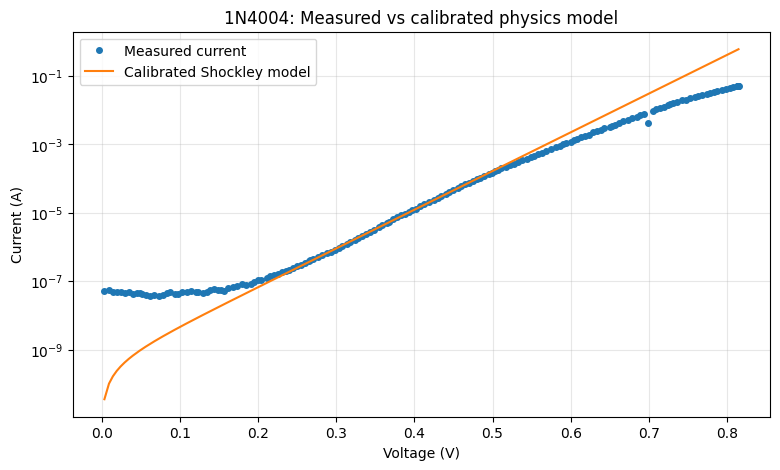

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Keep positive forward-bias measurements with positive current
fit_data = df[
    (df["v_meas"] > 0) &
    (df["i_meas"] > 0)
].copy()

# Fit only a moderate-current region initially.
# We will compare the result against the complete measured curve.
fit_data = fit_data[
    (fit_data["v_meas"] >= 0.30) &
    (fit_data["v_meas"] <= 0.50)
]

# Thermal voltage at 25°C
k = 1.380649e-23
q = 1.602176634e-19
temperature_k = 298.15
vt = k * temperature_k / q

# Fit ln(I) = slope*V + intercept
slope, intercept = np.polyfit(
    fit_data["v_meas"],
    np.log(fit_data["i_meas"]),
    1
)

ideality_factor = 1 / (slope * vt)
saturation_current = np.exp(intercept)

print("Measurements used:", len(fit_data))
print(f"Ideality factor n: {ideality_factor:.4f}")
print(f"Saturation current Is: {saturation_current:.4e} A")

# Predict across the full measured voltage sweep
voltage = df["v_meas"].to_numpy()
exponent = np.clip(
    voltage / (ideality_factor * vt),
    -745,
    700
)
predicted_current = saturation_current * np.expm1(exponent)

# Plot on a logarithmic current scale
plt.figure(figsize=(9, 5))
plt.semilogy(
    df.loc[df["i_meas"] > 0, "v_meas"],
    df.loc[df["i_meas"] > 0, "i_meas"],
    "o",
    markersize=4,
    label="Measured current"
)
plt.semilogy(
    voltage[voltage > 0],
    np.maximum(predicted_current[voltage > 0], 1e-15),
    label="Calibrated Shockley model"
)
plt.xlabel("Voltage (V)")
plt.ylabel("Current (A)")
plt.title("1N4004: Measured vs calibrated physics model")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

# Keep positive forward-current measurements
fit_df = df[
    (df["v_meas"] > 0) &
    (df["i_meas"] > 0)
].copy()

V = fit_df["v_meas"].to_numpy()
I = fit_df["i_meas"].to_numpy()

k = 1.380649e-23
q = 1.602176634e-19
T = 298.15
Vt = k * T / q

# Fit log-current residuals.
# Parameters are log(Is), ideality factor n, and series resistance Rs.
def residuals(params):
    log_Is, n, Rs = params
    Is = np.exp(log_Is)

    # Solve V = n*Vt*ln(1 + I/Is) + I*Rs
    # for predicted current at each measured voltage.
    # Use a bounded least-squares fit on log current instead.
    from scipy.optimize import brentq

    predicted = []
    for v in V:
        def equation(i):
            return n * Vt * np.log1p(i / Is) + i * Rs - v

        try:
            current = brentq(equation, 1e-15, 10.0)
        except ValueError:
            current = 1e-15
        predicted.append(current)

    predicted = np.maximum(predicted, 1e-15)
    return np.log10(predicted) - np.log10(I)

result = least_squares(
    residuals,
    x0=[np.log(1e-10), 1.5, 0.2],
    bounds=(
        [np.log(1e-20), 0.5, 0.0],
        [np.log(1e-3),  3.0, 100.0]
    ),
    max_nfev=300
)

log_Is, n_fit, Rs_fit = result.x
Is_fit = np.exp(log_Is)

print(f"Saturation current Is: {Is_fit:.4e} A")
print(f"Ideality factor n: {n_fit:.4f}")
print(f"Series resistance Rs: {Rs_fit:.4f} ohms")
print("Fit converged:", result.success)

Saturation current Is: 6.3692e-09 A
Ideality factor n: 1.9785
Series resistance Rs: 0.0000 ohms
Fit converged: True


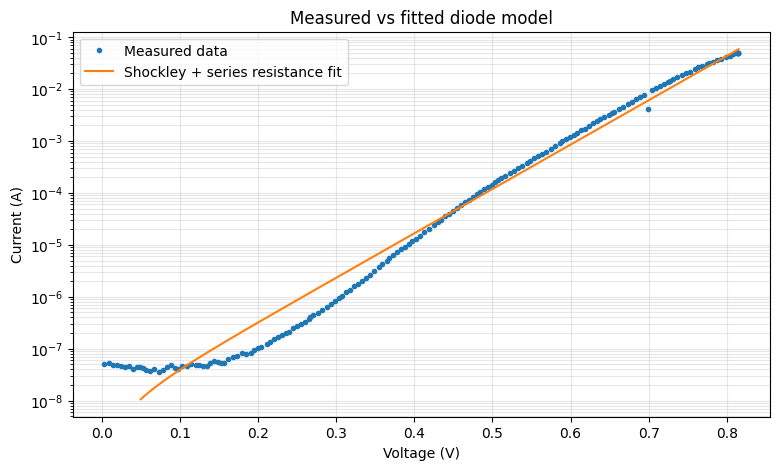

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

log_Is, n_fit, Rs_fit = result.x
Is_fit = np.exp(log_Is)

def predict_current(v):
    # Solve V = n*Vt*ln(1 + I/Is) + I*Rs
    # with a stable numerical bisection.
    low, high = 0.0, 10.0

    for _ in range(100):
        mid = (low + high) / 2
        voltage_mid = n_fit * Vt * np.log1p(mid / Is_fit) + mid * Rs_fit

        if voltage_mid < v:
            low = mid
        else:
            high = mid

    return (low + high) / 2

v_plot = np.linspace(0.05, 0.815, 250)
i_plot = np.array([predict_current(v) for v in v_plot])

plt.figure(figsize=(9, 5))
plt.semilogy(
    df.loc[df["i_meas"] > 0, "v_meas"],
    df.loc[df["i_meas"] > 0, "i_meas"],
    "o",
    markersize=3,
    label="Measured data"
)
plt.semilogy(v_plot, i_plot, label="Shockley + series resistance fit")
plt.xlabel("Voltage (V)")
plt.ylabel("Current (A)")
plt.title("Measured vs fitted diode model")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict at the measured voltages
predicted = np.array([predict_current(v) for v in V])

# Compare on a log-current scale, which is useful across many
# orders of magnitude in diode current.
log_actual = np.log10(I)
log_predicted = np.log10(np.maximum(predicted, 1e-15))

print("Log-current MAE:", mean_absolute_error(log_actual, log_predicted))
print("Log-current RMSE:", np.sqrt(mean_squared_error(log_actual, log_predicted)))
print("Log-current R²:", r2_score(log_actual, log_predicted))
print("Fitted series resistance:", Rs_fit, "ohms")

Log-current MAE: 0.26454858152430255
Log-current RMSE: 0.3883389052951194
Log-current R²: 0.9669153324364907
Fitted series resistance: 1.1148726254929681e-12 ohms


In [ ]:

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Sort measurements by voltage and keep positive forward currents
test_df = df[
    (df["v_meas"] > 0) & (df["i_meas"] > 0)
].sort_values("v_meas").reset_index(drop=True)

split = int(len(test_df) * 0.70)
train_df = test_df.iloc[:split]
heldout_df = test_df.iloc[split:]

V_train = train_df["v_meas"].to_numpy()
I_train = train_df["i_meas"].to_numpy()
V_test = heldout_df["v_meas"].to_numpy()
I_test = heldout_df["i_meas"].to_numpy()

# Fit the ideal Shockley equation on training data only
k = 1.380649e-23
q = 1.602176634e-19
Vt = k * 298.15 / q

slope, intercept = np.polyfit(V_train, np.log(I_train), 1)
n_test = 1 / (slope * Vt)
Is_test = np.exp(intercept)

# Predict held-out currents
I_pred = Is_test * np.expm1(
    np.clip(V_test / (n_test * Vt), -745, 700)
)
I_pred = np.maximum(I_pred, 1e-300)

# Score only the held-out measurements
log_actual = np.log10(I_test)
log_pred = np.log10(I_pred)

print("Training points:", len(train_df))
print("Held-out points:", len(heldout_df))
print(f"Fitted n: {n_test:.4f}")
print(f"Fitted Is: {Is_test:.4e} A")
print("Held-out log-current MAE:", mean_absolute_error(log_actual, log_pred))
print("Held-out log-current RMSE:", np.sqrt(mean_squared_error(log_actual, log_pred)))
print("Held-out log-current R²:", r2_score(log_actual, log_pred))


Training points: 117
Held-out points: 51
Fitted n: 2.0158
Fitted Is: 5.6637e-09 A
Held-out log-current MAE: 0.2566597680489346
Held-out log-current RMSE: 0.26819422385295
Held-out log-current R²: 0.7585921793908721


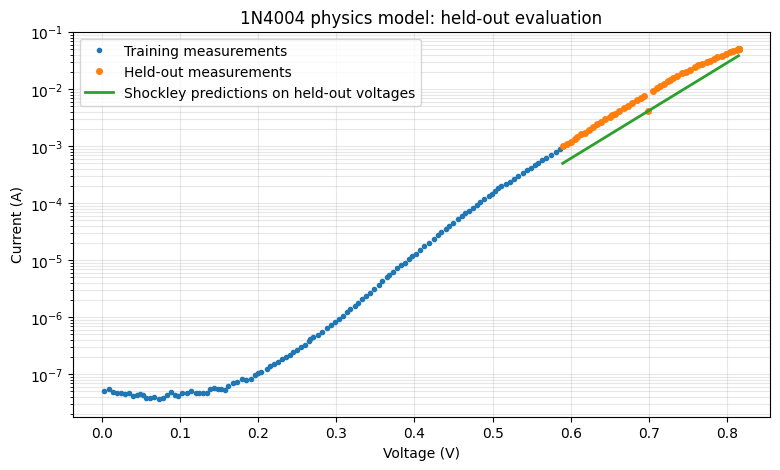

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 5))

plt.semilogy(
    V_train,
    I_train,
    "o",
    markersize=3,
    label="Training measurements",
)

plt.semilogy(
    V_test,
    I_test,
    "o",
    markersize=4,
    label="Held-out measurements",
)

plt.semilogy(
    V_test,
    I_pred,
    "-",
    linewidth=2,
    label="Shockley predictions on held-out voltages",
)

plt.xlabel("Voltage (V)")
plt.ylabel("Current (A)")
plt.title("1N4004 physics model: held-out evaluation")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()


In [ ]:

import numpy as np
from scipy.optimize import least_squares, brentq
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

V_train = train_df["v_meas"].to_numpy()
I_train = train_df["i_meas"].to_numpy()
V_test = heldout_df["v_meas"].to_numpy()
I_test = heldout_df["i_meas"].to_numpy()

def predict_series_resistance(voltage, log_Is, n, Rs):
    Is = np.exp(log_Is)
    result = []

    for v in np.asarray(voltage):
        if v <= 0:
            result.append(Is * np.expm1(v / (n * Vt)))
            continue

        def equation(i):
            return n * Vt * np.log1p(i / Is) + i * Rs - v

        upper = max(1.0, v / max(Rs, 1e-12))
        while equation(upper) < 0 and upper < 1e6:
            upper *= 10

        result.append(brentq(equation, 1e-15, upper))

    return np.maximum(np.asarray(result), 1e-300)

def residuals(params):
    pred = predict_series_resistance(V_train, *params)
    return np.log10(pred) - np.log10(I_train)

fit = least_squares(
    residuals,
    x0=[np.log(1e-9), 1.8, 0.1],
    bounds=(
        [np.log(1e-20), 0.5, 1e-6],
        [np.log(1e-3), 3.0, 100.0],
    ),
    max_nfev=500,
)

log_Is_fit, n_fit, Rs_fit = fit.x
Is_fit = np.exp(log_Is_fit)
I_test_pred = predict_series_resistance(V_test, *fit.x)

actual_log = np.log10(I_test)
pred_log = np.log10(I_test_pred)

print(f"Is = {Is_fit:.4e} A")
print(f"n = {n_fit:.4f}")
print(f"Rs = {Rs_fit:.6g} ohms")
print("Fit converged:", fit.success)
print("Held-out log-current MAE:", mean_absolute_error(actual_log, pred_log))
print("Held-out log-current RMSE:", np.sqrt(mean_squared_error(actual_log, pred_log)))
print("Held-out log-current R²:", r2_score(actual_log, pred_log))


Is = 8.5926e-09 A
n = 2.1188
Rs = 0.000358778 ohms
Fit converged: True
Held-out log-current MAE: 0.3659284344301217
Held-out log-current RMSE: 0.37094613619321837
Held-out log-current R²: 0.538178445667735


In [ ]:
import pandas as pd

df = pd.read_csv("classified_diode_measurements.csv")

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nMeasurements per material:")
print(df.groupby("material").size())

print("\nDevices per material:")
print(df.groupby("material")["device"].nunique())

print("\nMeasurements per temperature:")
print(df.groupby("temperature_K").size())

print("\nVoltage and current ranges:")
print(df[["voltage_V", "current_A"]].describe())

print("\nZero or negative currents:")
print((df["current_A"] <= 0).sum())

FileNotFoundError: [Errno 2] No such file or directory: 'classified_diode_measurements.csv'

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving classified_diode_measurements.csv to classified_diode_measurements.csv


In [ ]:
import pandas as pd

df = pd.read_csv("classified_diode_measurements.csv")

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nMeasurements per material:")
print(df.groupby("material").size())

print("\nDevices per material:")
print(df.groupby("material")["device"].nunique())

print("\nMeasurements per temperature:")
print(df.groupby("temperature_K").size())

print("\nVoltage and current ranges:")
print(df[["voltage_V", "current_A"]].describe())

print("\nZero or negative currents:")
print((df["current_A"] <= 0).sum())

Dataset shape: (5909, 7)

Missing values:
device           0
temperature_K    0
voltage_V        0
current_A        0
source_id        0
evidence_type    0
material         0
dtype: int64

Measurements per material:
material
gallium nitride    5189
silicon             492
silicon carbide     228
dtype: int64

Devices per material:
material
gallium nitride    1
silicon            9
silicon carbide    4
Name: device, dtype: int64

Measurements per temperature:
temperature_K
40     302
60     302
77     426
80     302
100    302
120    302
140    302
160    302
180    152
200    152
220    302
240    297
260    292
280    287
293    294
300    282
320    278
340    274
360    272
380    270
400    217
dtype: int64

Voltage and current ranges:
         voltage_V    current_A
count  5909.000000  5909.000000
mean     -0.345972     1.926403
std       0.964930     9.958768
min      -2.019998     0.000000
25%      -1.169999     0.000002
50%      -0.349999     0.000111
75%       0.440001     0.0

In [ ]:
print("Voltage direction by material:")
print(
    df.assign(
        voltage_region=df["voltage_V"].apply(
            lambda v: "Forward (V > 0)"
            if v > 0
            else "Reverse (V < 0)"
            if v < 0
            else "Zero voltage"
        )
    ).groupby(["material", "voltage_region"]).size().unstack(fill_value=0)
)

print("\nCurrent sign by material:")
print(
    df.assign(
        current_sign=df["current_A"].apply(
            lambda i: "Positive" if i > 0
            else "Zero" if i == 0
            else "Negative"
        )
    ).groupby(["material", "current_sign"]).size().unstack(fill_value=0)
)

Voltage direction by material:
voltage_region   Forward (V > 0)  Reverse (V < 0)  Zero voltage
material                                                       
gallium nitride             1621             3568             0
silicon                      474                0            18
silicon carbide              220                0             8

Current sign by material:
current_sign     Positive  Zero
material                       
gallium nitride      5189     0
silicon               474    18
silicon carbide       220     8


In [ ]:
gan_reverse = df[
    (df["material"] == "gallium nitride") &
    (df["voltage_V"] < 0)
].copy()

print("GaN reverse-bias rows:", len(gan_reverse))
print("\nVoltage range:")
print(gan_reverse["voltage_V"].agg(["min", "max"]))

print("\nCurrent range:")
print(gan_reverse["current_A"].agg(["min", "max"]))

print("\nFirst 10 reverse-bias measurements:")
print(
    gan_reverse[
        ["device", "temperature_K", "voltage_V", "current_A"]
    ].head(10).to_string(index=False)
)

GaN reverse-bias rows: 3568

Voltage range:
min   -2.019998
max   -0.009999
Name: voltage_V, dtype: float64

Current range:
min    1.630000e-11
max    2.193300e-03
Name: current_A, dtype: float64

First 10 reverse-bias measurements:
                    device  temperature_K  voltage_V    current_A
Au/Ni/n-GaN Schottky diode             40  -0.009999 2.085800e-10
Au/Ni/n-GaN Schottky diode             40  -0.019999 3.111200e-10
Au/Ni/n-GaN Schottky diode             40  -0.029999 4.524200e-10
Au/Ni/n-GaN Schottky diode             40  -0.039999 5.903200e-10
Au/Ni/n-GaN Schottky diode             40  -0.049999 7.338000e-10
Au/Ni/n-GaN Schottky diode             40  -0.059999 8.856900e-10
Au/Ni/n-GaN Schottky diode             40  -0.069999 1.049270e-09
Au/Ni/n-GaN Schottky diode             40  -0.079999 1.221060e-09
Au/Ni/n-GaN Schottky diode             40  -0.089999 1.396950e-09
Au/Ni/n-GaN Schottky diode             40  -0.099999 1.585780e-09


In [ ]:
gan_reverse = df[
    (df["material"] == "gallium nitride") &
    (df["voltage_V"] < 0)
].copy()

temperature_summary = (
    gan_reverse.groupby("temperature_K")
    .agg(
        measurements=("current_A", "size"),
        min_voltage=("voltage_V", "min"),
        max_voltage=("voltage_V", "max"),
        min_current=("current_A", "min"),
        max_current=("current_A", "max")
    )
    .round(8)
)

print(temperature_summary.to_string())

               measurements  min_voltage  max_voltage   min_current  max_current
temperature_K                                                                   
40                      201    -2.009998    -0.009999  0.000000e+00     0.000004
60                      201    -2.009998    -0.009999  0.000000e+00     0.000004
80                      201    -2.009998    -0.009999  0.000000e+00     0.000004
100                     201    -2.009998    -0.009999  0.000000e+00     0.000005
120                     201    -2.009998    -0.009999  0.000000e+00     0.000005
140                     201    -2.009998    -0.009999  0.000000e+00     0.000005
160                     201    -2.009998    -0.009999  0.000000e+00     0.000005
180                     101    -2.019998    -0.020000  3.000000e-08     0.000006
200                     101    -2.019998    -0.020000  0.000000e+00     0.000018
220                     201    -2.009998    -0.009999  0.000000e+00     0.000019
240                     201 

In [ ]:
gan_reverse = df[
    (df["material"] == "gallium nitride") &
    (df["voltage_V"] < 0)
].copy()

print("Exactly zero currents:", (gan_reverse["current_A"] == 0).sum())
print("Negative currents:", (gan_reverse["current_A"] < 0).sum())
print("Missing currents:", gan_reverse["current_A"].isna().sum())

print("\nRows with zero current:")
print(
    gan_reverse.loc[
        gan_reverse["current_A"] == 0,
        ["temperature_K", "voltage_V", "current_A"]
    ].head(15).to_string(index=False)
)

Exactly zero currents: 0
Negative currents: 0
Missing currents: 0

Rows with zero current:
Empty DataFrame
Columns: [temperature_K, voltage_V, current_A]
Index: []


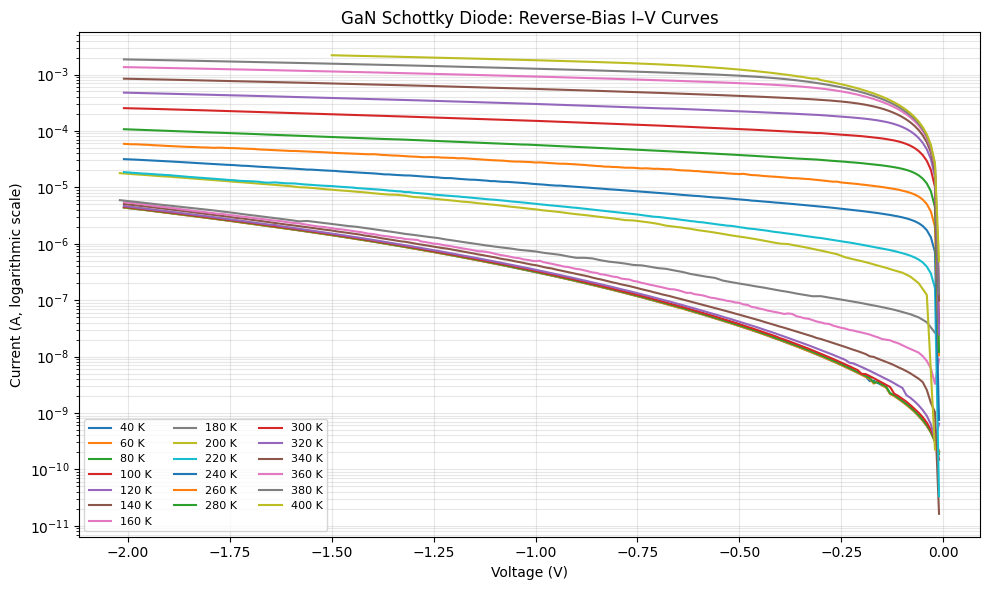

In [ ]:
import matplotlib.pyplot as plt

gan_reverse = df[
    (df["material"] == "gallium nitride") &
    (df["voltage_V"] < 0)
].copy()

plt.figure(figsize=(10, 6))

for temp in sorted(gan_reverse["temperature_K"].unique()):
    part = gan_reverse[gan_reverse["temperature_K"] == temp]
    plt.semilogy(
        part["voltage_V"],
        part["current_A"],
        label=f"{temp} K"
    )

plt.xlabel("Voltage (V)")
plt.ylabel("Current (A, logarithmic scale)")
plt.title("GaN Schottky Diode: Reverse-Bias I–V Curves")
plt.grid(True, which="both", alpha=0.3)
plt.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

gan_reverse = df[
    (df["material"] == "gallium nitride") &
    (df["voltage_V"] < 0)
].copy()

gan_reverse = gan_reverse.sort_values(
    ["temperature_K", "voltage_V"]
).reset_index(drop=True)

# Hold out every fifth point within each temperature
gan_reverse["point_number"] = (
    gan_reverse.groupby("temperature_K").cumcount()
)

test_mask = gan_reverse["point_number"] % 5 == 0

train_data = gan_reverse[~test_mask].copy()
test_data = gan_reverse[test_mask].copy()

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))
print(
    "Overlap in exact voltage-temperature pairs:",
    len(
        pd.merge(
            train_data[["temperature_K", "voltage_V"]],
            test_data[["temperature_K", "voltage_V"]],
            on=["temperature_K", "voltage_V"]
        )
    )
)

Training rows: 2840
Testing rows: 728
Overlap in exact voltage-temperature pairs: 0


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Actual currents are positive, so compare on a log10 scale
y_train_log = np.log10(train_data["current_A"])
y_test_log = np.log10(test_data["current_A"])

# Baseline: same median current for every test point
baseline_prediction = np.full(
    len(test_data),
    y_train_log.median()
)

print("Baseline log-current MAE:",
      mean_absolute_error(y_test_log, baseline_prediction))

print("Baseline log-current RMSE:",
      np.sqrt(mean_squared_error(y_test_log, baseline_prediction)))

print("Baseline log-current R²:",
      r2_score(y_test_log, baseline_prediction))

Baseline log-current MAE: 1.38471643552674
Baseline log-current RMSE: 1.6622281725020813
Baseline log-current R²: -0.0009522027474895278


In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

features = ["voltage_V", "temperature_K"]

X_train = train_data[features]
X_test = test_data[features]

y_train = np.log10(train_data["current_A"])
y_test = np.log10(test_data["current_A"])

model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Random Forest log-current MAE:",
      mean_absolute_error(y_test, predictions))

print("Random Forest log-current RMSE:",
      np.sqrt(mean_squared_error(y_test, predictions)))

print("Random Forest log-current R²:",
      r2_score(y_test, predictions))

Random Forest log-current MAE: 0.05422221001330304
Random Forest log-current RMSE: 0.3365947847689474
Random Forest log-current R²: 0.9589562694759828


In [ ]:
results = test_data[
    ["temperature_K", "voltage_V", "current_A"]
].copy()

results["actual_log_current"] = np.log10(
    results["current_A"]
)
results["predicted_log_current"] = predictions
results["absolute_log_error"] = abs(
    results["actual_log_current"]
    - results["predicted_log_current"]
)

print(
    results.sort_values(
        "absolute_log_error", ascending=False
    ).head(10).to_string(index=False)
)

 temperature_K  voltage_V    current_A  actual_log_current  predicted_log_current  absolute_log_error
           220  -0.009999 3.341000e-11          -10.476124              -6.578950            3.897174
           240  -0.009999 7.546900e-10           -9.122231              -5.878275            3.243957
           200  -0.020000 2.245600e-10           -9.648668              -6.685147            2.963521
           320  -0.009999 2.484700e-08           -7.604726              -4.658171            2.946555
           280  -0.009999 1.208930e-08           -7.917599              -5.125656            2.791942
           300  -0.009999 3.838400e-08           -7.415850              -4.711374            2.704476
           260  -0.009999 1.049240e-08           -7.979125              -5.435321            2.543804
           340  -0.009999 9.850600e-08           -7.006537              -4.763061            2.243476
           380  -0.009999 1.299090e-07           -6.886361              -4.814473 

In [ ]:
results["voltage_region"] = pd.cut(
    results["voltage_V"],
    bins=[-2.1, -1.0, -0.5, -0.1, 0.0],
    labels=[
        "-2.1 to -1.0 V",
        "-1.0 to -0.5 V",
        "-0.5 to -0.1 V",
        "-0.1 to 0 V"
    ]
)

print(
    results.groupby("voltage_region", observed=False)
    .agg(
        points=("absolute_log_error", "size"),
        mean_absolute_log_error=("absolute_log_error", "mean"),
        max_absolute_log_error=("absolute_log_error", "max")
    )
    .round(4)
)

                points  mean_absolute_log_error  max_absolute_log_error
voltage_region                                                         
-2.1 to -1.0 V     368                   0.0076                  0.0431
-1.0 to -0.5 V     180                   0.0089                  0.0310
-0.5 to -0.1 V     144                   0.0184                  0.1219
-0.1 to 0 V         36                   0.9004                  3.8972


In [ ]:
near_zero = results[
    results["voltage_V"] >= -0.1
].copy()

near_zero["actual_current_A"] = 10 ** near_zero["actual_log_current"]
near_zero["predicted_current_A"] = 10 ** near_zero["predicted_log_current"]

print(
    near_zero[
        [
            "temperature_K",
            "voltage_V",
            "actual_current_A",
            "predicted_current_A",
            "absolute_log_error"
        ]
    ].sort_values("temperature_K").to_string(index=False)
)

 temperature_K  voltage_V  actual_current_A  predicted_current_A  absolute_log_error
            40  -0.059999      8.856900e-10         7.603037e-10            0.066295
            40  -0.009999      2.085800e-10         3.280263e-10            0.196636
            60  -0.059999      8.781800e-10         7.648604e-10            0.060001
            60  -0.009999      2.089900e-10         3.275925e-10            0.195208
            80  -0.059999      9.118300e-10         7.831022e-10            0.066095
            80  -0.009999      1.878800e-10         3.327572e-10            0.248247
           100  -0.059999      1.010240e-09         8.454987e-10            0.077312
           100  -0.009999      1.488000e-10         3.499223e-10            0.371369
           120  -0.059999      1.362410e-09         9.657825e-10            0.149428
           120  -0.009999      6.444100e-10         3.787798e-10            0.230775
           140  -0.059999      4.042400e-09         3.212940e-09 

In [ ]:
print(
    df[
        (df["material"] == "gallium nitride") &
        (df["temperature_K"] == 220) &
        (df["voltage_V"] >= -0.1) &
        (df["voltage_V"] < 0)
    ][["temperature_K", "voltage_V", "current_A"]]
    .sort_values("voltage_V")
    .to_string(index=False)
)

 temperature_K  voltage_V    current_A
           220  -0.099999 6.804000e-07
           220  -0.089999 6.472900e-07
           220  -0.079999 6.123600e-07
           220  -0.069999 5.709000e-07
           220  -0.059999 5.238100e-07
           220  -0.049999 4.668900e-07
           220  -0.039999 3.926100e-07
           220  -0.029999 2.963700e-07
           220  -0.019999 1.641450e-07
           220  -0.009999 3.341000e-11


In [ ]:
boundary_check = df[
    (df["material"] == "gallium nitride") &
    (df["voltage_V"] >= -0.02) &
    (df["voltage_V"] < 0)
].copy()

print(
    boundary_check[
        ["temperature_K", "voltage_V", "current_A"]
    ]
    .sort_values(["temperature_K", "voltage_V"])
    .to_string(index=False)
)

 temperature_K  voltage_V    current_A
            40  -0.019999 3.111200e-10
            40  -0.009999 2.085800e-10
            60  -0.019999 3.119200e-10
            60  -0.009999 2.089900e-10
            80  -0.019999 3.176000e-10
            80  -0.009999 1.878800e-10
           100  -0.019999 3.534200e-10
           100  -0.009999 1.488000e-10
           120  -0.019999 3.389800e-10
           120  -0.009999 6.444100e-10
           140  -0.019999 1.031770e-09
           140  -0.009999 1.630000e-11
           160  -0.019999 3.272400e-09
           160  -0.009999 8.950700e-09
           180  -0.020000 2.647400e-08
           200  -0.020000 2.245600e-10
           220  -0.019999 1.641450e-07
           220  -0.009999 3.341000e-11
           240  -0.019999 7.153700e-07
           240  -0.009999 7.546900e-10
           260  -0.019999 1.998180e-06
           260  -0.009999 1.049240e-08
           280  -0.019999 4.444000e-06
           280  -0.009999 1.208930e-08
           300  -0.019999

In [ ]:
gan_boundary = df[
    (df["material"] == "gallium nitride") &
    (df["voltage_V"] >= -0.02) &
    (df["voltage_V"] < 0)
].copy()

duplicates = gan_boundary[
    gan_boundary.duplicated(
        subset=["temperature_K", "voltage_V"],
        keep=False
    )
].sort_values(["temperature_K", "voltage_V"])

print("Duplicate temperature-voltage rows:", len(duplicates))

if len(duplicates):
    print(
        duplicates[
            ["temperature_K", "voltage_V", "current_A", "source_id"]
        ].to_string(index=False)
    )
else:
    print("No duplicate temperature-voltage rows found.")

Duplicate temperature-voltage rows: 0
No duplicate temperature-voltage rows found.


In [ ]:
# Compare errors in the boundary region with the rest
near_zero = results["voltage_V"] >= -0.02

print("Points at or above -0.02 V:", near_zero.sum())
print("Points below -0.02 V:", (~near_zero).sum())

print("\nMean absolute log error:")
print("Boundary region:",
      results.loc[near_zero, "absolute_log_error"].mean())
print("Rest of reverse-bias curve:",
      results.loc[~near_zero, "absolute_log_error"].mean())

print("\nMaximum absolute log error:")
print("Boundary region:",
      results.loc[near_zero, "absolute_log_error"].max())
print("Rest of reverse-bias curve:",
      results.loc[~near_zero, "absolute_log_error"].max())

Points at or above -0.02 V: 18
Points below -0.02 V: 710

Mean absolute log error:
Boundary region: 1.7248644944964615
Rest of reverse-bias curve: 0.011867898575701835

Maximum absolute log error:
Boundary region: 3.897173828353081
Rest of reverse-bias curve: 0.14942847580643814


In [ ]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

extra_model = ExtraTreesRegressor(
    n_estimators=300,
    min_samples_leaf=1,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

extra_model.fit(X_train, y_train)
extra_predictions = extra_model.predict(X_test)

extra_errors = np.abs(y_test.to_numpy() - extra_predictions)
boundary_mask = test_data["voltage_V"].to_numpy() >= -0.02

print("Extra Trees overall MAE:", mean_absolute_error(y_test, extra_predictions))
print("Extra Trees overall RMSE:", np.sqrt(mean_squared_error(y_test, extra_predictions)))
print("Extra Trees overall R²:", r2_score(y_test, extra_predictions))
print("Boundary MAE:", extra_errors[boundary_mask].mean())
print("Rest-of-curve MAE:", extra_errors[~boundary_mask].mean())


Extra Trees overall MAE: 0.038744847170231
Extra Trees overall RMSE: 0.29756692871672946
Extra Trees overall R²: 0.9679224354790638
Boundary MAE: 1.5028715829016235
Rest-of-curve MAE: 0.0016261411939421828


In [ ]:
boundary_results = test_data[
    test_data["voltage_V"] >= -0.02
].copy()

boundary_results["actual_log_current"] = np.log10(
    boundary_results["current_A"]
)

boundary_results["rf_prediction"] = model.predict(
    boundary_results[["voltage_V", "temperature_K"]]
)

boundary_results["extra_prediction"] = extra_model.predict(
    boundary_results[["voltage_V", "temperature_K"]]
)

boundary_results["extra_abs_error"] = np.abs(
    boundary_results["actual_log_current"]
    - boundary_results["extra_prediction"]
)

print(
    boundary_results[
        [
            "temperature_K",
            "voltage_V",
            "current_A",
            "actual_log_current",
            "extra_prediction",
            "extra_abs_error",
        ]
    ].sort_values("extra_abs_error", ascending=False).to_string(index=False)
)

 temperature_K  voltage_V    current_A  actual_log_current  extra_prediction  extra_abs_error
           220  -0.009999 3.341000e-11          -10.476124         -6.784772         3.691351
           240  -0.009999 7.546900e-10           -9.122231         -6.145469         2.976762
           200  -0.020000 2.245600e-10           -9.648668         -6.917334         2.731333
           320  -0.009999 2.484700e-08           -7.604726         -4.921856         2.682870
           280  -0.009999 1.208930e-08           -7.917599         -5.361824         2.555775
           300  -0.009999 3.838400e-08           -7.415850         -5.017696         2.398154
           260  -0.009999 1.049240e-08           -7.979125         -5.699365         2.279760
           340  -0.009999 9.850600e-08           -7.006537         -5.135277         1.871260
           140  -0.009999 1.630000e-11          -10.787812         -8.986417         1.801395
           360  -0.009999 2.061600e-07           -6.685796  

In [ ]:
gan_check = df[
    (df["material"] == "gallium nitride") &
    (df["voltage_V"] >= -0.03) &
    (df["voltage_V"] < 0)
].copy()

gan_check["voltage_rounded"] = gan_check["voltage_V"].round(3)

current_table = gan_check.pivot(
    index="temperature_K",
    columns="voltage_rounded",
    values="current_A"
)

display(current_table)

voltage_rounded,-0.03,-0.02,-0.01
temperature_K,,,
40,4.524200e-10,3.111200e-10,2.085800e-10
60,4.491500e-10,3.119200e-10,2.089900e-10
80,4.633400e-10,3.176000e-10,1.878800e-10
100,4.996800e-10,3.534200e-10,1.488000e-10
120,6.301500e-10,3.389800e-10,6.444100e-10
140,1.511440e-09,1.031770e-09,1.630000e-11
160,6.172100e-09,3.272400e-09,8.950700e-09
180,NaN,2.647400e-08,NaN
200,NaN,2.245600e-10,NaN


In [ ]:
print("Source IDs:")
print(
    df.loc[
        df["material"] == "gallium nitride",
        "source_id"
    ].value_counts().to_string()
)

print("\nAvailable columns:")
print(df.columns.tolist())

Source IDs:
source_id
gan_schottky_measurement_zenodo    5189

Available columns:
['device', 'temperature_K', 'voltage_V', 'current_A', 'source_id', 'evidence_type', 'material']


In [ ]:
gan_summary = (
    df[df["material"] == "gallium nitride"]
    .groupby("temperature_K")
    .agg(
        number_of_points=("current_A", "size"),
        minimum_current=("current_A", "min"),
        maximum_current=("current_A", "max"),
    )
)

gan_summary["current_range_ratio"] = (
    gan_summary["maximum_current"] /
    gan_summary["minimum_current"]
)

display(gan_summary.round(10))

,number_of_points,minimum_current,maximum_current,current_range_ratio
temperature_K,,,,
40,302,1.000000e-10,0.000411,7.085764e+06
60,302,1.000000e-10,0.000406,6.534932e+06
80,302,0.000000e+00,0.000474,1.278365e+07
100,302,0.000000e+00,0.000568,2.774316e+07
120,302,3.000000e-10,0.000688,2.028674e+06
140,302,0.000000e+00,0.000888,5.448466e+07
160,302,3.300000e-09,0.001138,3.478945e+05
180,152,0.000000e+00,0.001474,3.202521e+07
200,152,2.000000e-10,0.001766,7.863778e+06


In [ ]:
gan = df[df["material"] == "gallium nitride"].copy()

print("Total GaN rows:", len(gan))
print("Zero-current rows:", (gan["current_A"] == 0).sum())
print("Negative-current rows:", (gan["current_A"] < 0).sum())
print("Positive-current rows:", (gan["current_A"] > 0).sum())

print("\nZero-current rows by temperature:")
print(
    gan.loc[gan["current_A"] == 0]
    .groupby("temperature_K")
    .size()
    .to_string()
)

Total GaN rows: 5189
Zero-current rows: 0
Negative-current rows: 0
Positive-current rows: 5189

Zero-current rows by temperature:
Series([], )


In [ ]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

gan_reverse = df[
    (df["material"] == "gallium nitride") &
    (df["voltage_V"] < 0)
].copy()

train_temp = gan_reverse[gan_reverse["temperature_K"] != 200]
test_temp = gan_reverse[gan_reverse["temperature_K"] == 200]

features = ["voltage_V", "temperature_K"]

X_train_temp = train_temp[features]
y_train_temp = np.log10(train_temp["current_A"])

X_test_temp = test_temp[features]
y_test_temp = np.log10(test_temp["current_A"])

temp_model = ExtraTreesRegressor(
    n_estimators=300,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

temp_model.fit(X_train_temp, y_train_temp)
temp_predictions = temp_model.predict(X_test_temp)

print("Training temperatures:", sorted(train_temp["temperature_K"].unique()))
print("Unseen test temperature: 200 K")
print("Test points:", len(test_temp))
print("MAE:", mean_absolute_error(y_test_temp, temp_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test_temp, temp_predictions)))
print("R²:", r2_score(y_test_temp, temp_predictions))

Training temperatures: [np.int64(40), np.int64(60), np.int64(80), np.int64(100), np.int64(120), np.int64(140), np.int64(160), np.int64(180), np.int64(220), np.int64(240), np.int64(260), np.int64(280), np.int64(300), np.int64(320), np.int64(340), np.int64(360), np.int64(380), np.int64(400)]
Unseen test temperature: 200 K
Test points: 101
MAE: 0.28749679514094095
RMSE: 0.36641511727838777
R²: 0.6974975446005307


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Baseline: use the average log-current from the training data
baseline_prediction = np.full(
    len(y_test_temp),
    y_train_temp.mean()
)

print("Baseline MAE:",
      mean_absolute_error(y_test_temp, baseline_prediction))
print("Baseline RMSE:",
      np.sqrt(mean_squared_error(y_test_temp, baseline_prediction)))
print("Baseline R²:",
      r2_score(y_test_temp, baseline_prediction))

print("\nExtra Trees MAE:",
      mean_absolute_error(y_test_temp, temp_predictions))
print("Extra Trees RMSE:",
      np.sqrt(mean_squared_error(y_test_temp, temp_predictions)))
print("Extra Trees R²:",
      r2_score(y_test_temp, temp_predictions))

Baseline MAE: 0.5210443626179248
Baseline RMSE: 0.7809925816114814
Baseline R²: -0.37428230674738194

Extra Trees MAE: 0.28749679514094095
Extra Trees RMSE: 0.36641511727838777
Extra Trees R²: 0.6974975446005307


In [ ]:
# Hold out all GaN reverse-bias measurements at 300 K
train_300 = gan_reverse[gan_reverse["temperature_K"] != 300]
test_300 = gan_reverse[gan_reverse["temperature_K"] == 300]

X_train_300 = train_300[features]
y_train_300 = np.log10(train_300["current_A"])

X_test_300 = test_300[features]
y_test_300 = np.log10(test_300["current_A"])

model_300 = ExtraTreesRegressor(
    n_estimators=300,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

model_300.fit(X_train_300, y_train_300)
pred_300 = model_300.predict(X_test_300)

baseline_300 = np.full(len(y_test_300), y_train_300.mean())

print("Held-out temperature: 300 K")
print("Test points:", len(test_300))

print("\nBaseline MAE:",
      mean_absolute_error(y_test_300, baseline_300))
print("Extra Trees MAE:",
      mean_absolute_error(y_test_300, pred_300))

print("\nBaseline RMSE:",
      np.sqrt(mean_squared_error(y_test_300, baseline_300)))
print("Extra Trees RMSE:",
      np.sqrt(mean_squared_error(y_test_300, pred_300)))

print("\nBaseline R²:",
      r2_score(y_test_300, baseline_300))
print("Extra Trees R²:",
      r2_score(y_test_300, pred_300))

Held-out temperature: 300 K
Test points: 201

Baseline MAE: 1.3362590135667987
Extra Trees MAE: 0.06605772543676294

Baseline RMSE: 1.3529377842987247
Extra Trees RMSE: 0.07019453166103376

Baseline R²: -16.65421740503539
Extra Trees R²: 0.9524774889341701


In [ ]:
# Evaluate the held-out 300 K curve near zero voltage
near_zero_300 = test_300["voltage_V"].to_numpy() >= -0.1

actual_log = y_test_300.to_numpy()
predicted_log = pred_300

print("Points near zero voltage:", near_zero_300.sum())
print("Near-zero MAE:",
      mean_absolute_error(
          actual_log[near_zero_300],
          predicted_log[near_zero_300]
      ))

print("Remaining-region MAE:",
      mean_absolute_error(
          actual_log[~near_zero_300],
          predicted_log[~near_zero_300]
      ))

Points near zero voltage: 10
Near-zero MAE: 0.12049182023039542
Remaining-region MAE: 0.06320777282976647


In [ ]:
train_400 = gan_reverse[gan_reverse["temperature_K"] != 400]
test_400 = gan_reverse[gan_reverse["temperature_K"] == 400]

X_train_400 = train_400[features]
y_train_400 = np.log10(train_400["current_A"])

X_test_400 = test_400[features]
y_test_400 = np.log10(test_400["current_A"])

model_400 = ExtraTreesRegressor(
    n_estimators=300,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

model_400.fit(X_train_400, y_train_400)
pred_400 = model_400.predict(X_test_400)

baseline_400 = np.full(len(y_test_400), y_train_400.mean())

print("Held-out temperature: 400 K")
print("Test points:", len(test_400))

print("\nBaseline MAE:",
      mean_absolute_error(y_test_400, baseline_400))
print("Extra Trees MAE:",
      mean_absolute_error(y_test_400, pred_400))

print("\nBaseline RMSE:",
      np.sqrt(mean_squared_error(y_test_400, baseline_400)))
print("Extra Trees RMSE:",
      np.sqrt(mean_squared_error(y_test_400, pred_400)))

print("\nBaseline R²:",
      r2_score(y_test_400, baseline_400))
print("Extra Trees R²:",
      r2_score(y_test_400, pred_400))

Held-out temperature: 400 K
Test points: 150

Baseline MAE: 2.2706492810633905
Extra Trees MAE: 0.12086355022516557

Baseline RMSE: 2.2960656829854154
Extra Trees RMSE: 0.13330865117487498

Baseline R²: -27.83417494032783
Extra Trees R²: 0.9028023908896444


In [ ]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np
import pandas as pd

all_results = []

for temp in sorted(gan_reverse["temperature_K"].unique()):
    train = gan_reverse[gan_reverse["temperature_K"] != temp]
    test = gan_reverse[gan_reverse["temperature_K"] == temp]

    X_train = train[["voltage_V", "temperature_K"]]
    y_train = np.log10(train["current_A"])

    X_test = test[["voltage_V", "temperature_K"]]
    y_test = np.log10(test["current_A"])

    model_temp = ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    )
    model_temp.fit(X_train, y_train)
    pred = model_temp.predict(X_test)

    baseline = np.full(len(y_test), y_train.mean())

    all_results.append({
        "temperature_K": temp,
        "test_points": len(test),
        "ExtraTrees_MAE": mean_absolute_error(y_test, pred),
        "Baseline_MAE": mean_absolute_error(y_test, baseline),
        "ExtraTrees_R2": r2_score(y_test, pred)
    })

results_by_temp = pd.DataFrame(all_results)

display(results_by_temp.round(4))

print("\nAverage Extra Trees MAE:",
      results_by_temp["ExtraTrees_MAE"].mean())
print("Average baseline MAE:",
      results_by_temp["Baseline_MAE"].mean())
print("Temperatures where Extra Trees beats baseline:",
      (results_by_temp["ExtraTrees_MAE"] <
       results_by_temp["Baseline_MAE"]).sum(),
      "of", len(results_by_temp))

,temperature_K,test_points,ExtraTrees_MAE,Baseline_MAE,ExtraTrees_R2
0,40,201,0.0015,1.7091,1.0000
1,60,201,0.0052,1.7095,1.0000
2,80,201,0.0041,1.7001,1.0000
3,100,201,0.0111,1.6827,0.9991
4,120,201,0.0486,1.6429,0.9903
5,140,201,0.0248,1.5348,0.9751
6,160,201,0.0509,1.3790,0.9813
7,180,101,0.2553,1.0913,0.7733
8,200,101,0.2875,0.5210,0.6975
9,220,201,0.1418,0.4217,0.9049



Average Extra Trees MAE: 0.06992334427916695
Average baseline MAE: 1.4068894315184617
Temperatures where Extra Trees beats baseline: 19 of 19


In [ ]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Hold out the near-zero voltage interval for every temperature
voltage_test_mask = (
    (gan_reverse["voltage_V"] >= -0.10) &
    (gan_reverse["voltage_V"] < 0)
)

train_voltage = gan_reverse[~voltage_test_mask]
test_voltage = gan_reverse[voltage_test_mask]

features = ["voltage_V", "temperature_K"]

X_train_v = train_voltage[features]
y_train_v = np.log10(train_voltage["current_A"])

X_test_v = test_voltage[features]
y_test_v = np.log10(test_voltage["current_A"])

voltage_model = ExtraTreesRegressor(
    n_estimators=300,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

voltage_model.fit(X_train_v, y_train_v)
pred_v = voltage_model.predict(X_test_v)

print("Training points:", len(train_voltage))
print("Held-out voltage points:", len(test_voltage))
print("Held-out voltage range:",
      test_voltage["voltage_V"].min(),
      "to",
      test_voltage["voltage_V"].max(),
      "V")

print("MAE:", mean_absolute_error(y_test_v, pred_v))
print("RMSE:", np.sqrt(mean_squared_error(y_test_v, pred_v)))
print("R²:", r2_score(y_test_v, pred_v))

Training points: 3388
Held-out voltage points: 180
Held-out voltage range: -0.09999961 to -0.009999329 V
MAE: 0.5148624086504606
RMSE: 0.9433268071551331
R²: 0.8054494087570148


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline_v = np.full(
    len(y_test_v),
    y_train_v.mean()
)

print("Baseline MAE:",
      mean_absolute_error(y_test_v, baseline_v))
print("Extra Trees MAE:",
      mean_absolute_error(y_test_v, pred_v))

print("\nBaseline RMSE:",
      np.sqrt(mean_squared_error(y_test_v, baseline_v)))
print("Extra Trees RMSE:",
      np.sqrt(mean_squared_error(y_test_v, pred_v)))

print("\nBaseline R²:",
      r2_score(y_test_v, baseline_v))
print("Extra Trees R²:",
      r2_score(y_test_v, pred_v))

Baseline MAE: 2.1802615839583015
Extra Trees MAE: 0.5148624086504606

Baseline RMSE: 2.672255586527595
Extra Trees RMSE: 0.9433268071551331

Baseline R²: -0.5612203006073548
Extra Trees R²: 0.8054494087570148


In [ ]:
voltage_errors = test_voltage[
    ["temperature_K", "voltage_V", "current_A"]
].copy()

voltage_errors["actual_log_current"] = y_test_v.to_numpy()
voltage_errors["predicted_log_current"] = pred_v
voltage_errors["absolute_log_error"] = np.abs(
    voltage_errors["actual_log_current"]
    - voltage_errors["predicted_log_current"]
)

print(
    voltage_errors.sort_values(
        "absolute_log_error",
        ascending=False
    ).head(5).to_string(index=False)
)

 temperature_K  voltage_V    current_A  actual_log_current  predicted_log_current  absolute_log_error
           220  -0.009999 3.341000e-11          -10.476124              -6.148509            4.327614
           320  -0.009999 2.484700e-08           -7.604726              -3.901799            3.702927
           240  -0.009999 7.546900e-10           -9.122231              -5.516855            3.605376
           380  -0.009999 1.299090e-07           -6.886361              -3.572498            3.313863
           340  -0.009999 9.850600e-08           -7.006537              -3.715892            3.290645


In [ ]:
voltage_errors["voltage_bin"] = (
    voltage_errors["voltage_V"].round(2)
)

error_by_voltage = (
    voltage_errors
    .groupby("voltage_bin")
    .agg(
        points=("absolute_log_error", "size"),
        mean_abs_log_error=("absolute_log_error", "mean"),
        max_abs_log_error=("absolute_log_error", "max")
    )
    .reset_index()
    .sort_values("voltage_bin")
)

display(error_by_voltage.round(4))

,voltage_bin,points,mean_abs_log_error,max_abs_log_error
0,-0.10,19,0.0356,0.0531
1,-0.09,17,0.0795,0.1682
2,-0.08,19,0.1204,0.2168
3,-0.07,17,0.1745,0.2779
4,-0.06,19,0.2288,0.3490
5,-0.05,17,0.3099,0.4329
6,-0.04,19,0.4033,0.5345
7,-0.03,17,0.5635,0.7112
8,-0.02,19,0.9202,3.1761
9,-0.01,17,2.4150,4.3276


In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

boost_model = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

boost_model.fit(X_train_v, y_train_v)
boost_pred = boost_model.predict(X_test_v)

print("Gradient Boosting MAE:",
      mean_absolute_error(y_test_v, boost_pred))
print("Gradient Boosting RMSE:",
      np.sqrt(mean_squared_error(y_test_v, boost_pred)))
print("Gradient Boosting R²:",
      r2_score(y_test_v, boost_pred))

Gradient Boosting MAE: 0.5314910995331825
Gradient Boosting RMSE: 0.9545017355195954
Gradient Boosting R²: 0.8008126988617681


In [ ]:
print("Training voltage range:")
print(X_train_v["voltage_V"].min(), "to",
      X_train_v["voltage_V"].max(), "V")

print("\nTraining temperature range:")
print(X_train_v["temperature_K"].min(), "to",
      X_train_v["temperature_K"].max(), "K")

print("\nTraining current range:")
print(train_voltage["current_A"].min(), "to",
      train_voltage["current_A"].max(), "A")


Training voltage range:
-2.019998 to -0.1099993 V

Training temperature range:
40 to 400 K

Training current range:
1.77921e-09 to 0.0021933 A


In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

physics_results = []

for temp in sorted(train_voltage["temperature_K"].unique()):
    part = train_voltage[
        train_voltage["temperature_K"] == temp
    ]

    X = part[["voltage_V"]]
    y = np.log10(part["current_A"])

    linear_model = LinearRegression()
    linear_model.fit(X, y)

    pred = linear_model.predict(X)

    physics_results.append({
        "temperature_K": temp,
        "points": len(part),
        "slope": linear_model.coef_[0],
        "training_MAE": mean_absolute_error(y, pred),
        "training_R2": r2_score(y, pred)
    })

physics_table = pd.DataFrame(physics_results)
display(physics_table.round(4))

,temperature_K,points,slope,training_MAE,training_R2
0,40,191,-1.6258,0.1519,0.9602
1,60,191,-1.6253,0.1521,0.9600
2,80,191,-1.6207,0.1511,0.9602
3,100,191,-1.6073,0.1479,0.9614
4,120,191,-1.5686,0.1365,0.9660
5,140,191,-1.4668,0.1127,0.9743
6,160,191,-1.3000,0.0722,0.9863
7,180,96,-1.0141,0.0398,0.9940
8,200,96,-0.8371,0.0669,0.9699
9,220,191,-0.7104,0.0486,0.9798


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_predictions = np.full(len(test_voltage), np.nan)

# Fit each temperature's line using training voltages only
for temp in sorted(test_voltage["temperature_K"].unique()):
    train_part = train_voltage[
        train_voltage["temperature_K"] == temp
    ]
    test_mask = test_voltage["temperature_K"].to_numpy() == temp

    line_model = LinearRegression()
    line_model.fit(
        train_part[["voltage_V"]],
        np.log10(train_part["current_A"])
    )

    linear_predictions[test_mask] = line_model.predict(
        test_voltage.loc[test_mask, ["voltage_V"]]
    )

print("Per-temperature linear extrapolation")
print("MAE:", mean_absolute_error(y_test_v, linear_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test_v, linear_predictions)))
print("R²:", r2_score(y_test_v, linear_predictions))

print("\nPrevious Extra Trees")
print("MAE:", mean_absolute_error(y_test_v, pred_v))
print("RMSE:", np.sqrt(mean_squared_error(y_test_v, pred_v)))
print("R²:", r2_score(y_test_v, pred_v))

Per-temperature linear extrapolation
MAE: 0.7795550546976034
RMSE: 1.1111541075103053
R²: 0.7300664946231853

Previous Extra Trees
MAE: 0.5148624086504606
RMSE: 0.9433268071551331
R²: 0.8054494087570148


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    Ridge(alpha=10.0)
)

poly_model.fit(X_train_v, y_train_v)
poly_pred = poly_model.predict(X_test_v)

print("Polynomial Ridge MAE:",
      mean_absolute_error(y_test_v, poly_pred))
print("Polynomial Ridge RMSE:",
      np.sqrt(mean_squared_error(y_test_v, poly_pred)))
print("Polynomial Ridge R²:",
      r2_score(y_test_v, poly_pred))

Polynomial Ridge MAE: 0.7792338726937345
Polynomial Ridge RMSE: 1.0909963571365977
Polynomial Ridge R²: 0.7397715329442741


In [ ]:
import pandas as pd

benchmark = pd.DataFrame([
    {
        "Model": "Extra Trees",
        "MAE": 0.5148624087,
        "RMSE": 0.9433268072,
        "R2": 0.8054494088
    },
    {
        "Model": "Gradient Boosting",
        "MAE": 0.5314910995,
        "RMSE": 0.9545017355,
        "R2": 0.8008126989
    },
    {
        "Model": "Polynomial Ridge",
        "MAE": 0.7792338727,
        "RMSE": 1.0909963571,
        "R2": 0.7397715329
    },
    {
        "Model": "Linear Extrapolation",
        "MAE": 0.7795550547,
        "RMSE": 1.1111541075,
        "R2": 0.7300664946
    }
])

benchmark = benchmark.sort_values("MAE")
benchmark.to_csv("voltage_model_benchmark.csv", index=False)

display(benchmark.round(4))
print("\nSaved as voltage_model_benchmark.csv")

,Model,MAE,RMSE,R2
0,Extra Trees,0.5149,0.9433,0.8054
1,Gradient Boosting,0.5315,0.9545,0.8008
2,Polynomial Ridge,0.7792,1.0910,0.7398
3,Linear Extrapolation,0.7796,1.1112,0.7301



Saved as voltage_model_benchmark.csv


In [ ]:
from pathlib import Path

file_path = Path("voltage_model_benchmark.csv")

print("File exists:", file_path.exists())

if file_path.exists():
    print("File size:", file_path.stat().st_size, "bytes")
    display(pd.read_csv(file_path))

File exists: False


In [ ]:
import pandas as pd
from google.colab import files

benchmark = pd.DataFrame([
    {"Model": "Extra Trees", "MAE": 0.5148624087, "RMSE": 0.9433268072, "R2": 0.8054494088},
    {"Model": "Gradient Boosting", "MAE": 0.5314910995, "RMSE": 0.9545017355, "R2": 0.8008126989},
    {"Model": "Polynomial Ridge", "MAE": 0.7792338727, "RMSE": 1.0909963571, "R2": 0.7397715329},
    {"Model": "Linear Extrapolation", "MAE": 0.7795550547, "RMSE": 1.1111541075, "R2": 0.7300664946}
]).sort_values("MAE")

benchmark.to_csv("/content/voltage_model_benchmark.csv", index=False)

display(benchmark.round(4))
files.download("/content/voltage_model_benchmark.csv")

,Model,MAE,RMSE,R2
0,Extra Trees,0.5149,0.9433,0.8054
1,Gradient Boosting,0.5315,0.9545,0.8008
2,Polynomial Ridge,0.7792,1.0910,0.7398
3,Linear Extrapolation,0.7796,1.1112,0.7301


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import pandas as pd
import numpy as np
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Check that the restored models and test data exist
print("Random Forest exists:", "rf_model" in globals())
print("Tuned SVR exists:", "best_svr" in globals())
print("Test data exists:", "X_test_random" in globals())

# Recreate the two simpler comparison models
linear_model = LinearRegression()
linear_model.fit(X_train_random, y_train_random)

mean_model = DummyRegressor(strategy="mean")
mean_model.fit(X_train_random, y_train_random)

# Compare all four models on the same held-out test data
models_to_evaluate = {
    "Random Forest": rf_model,
    "Tuned SVR": best_svr,
    "Linear Regression": linear_model,
    "Mean baseline": mean_model
}

results = []

for name, model in models_to_evaluate.items():
    predictions = model.predict(X_test_random)

    mae = mean_absolute_error(y_test_random, predictions)
    rmse = np.sqrt(mean_squared_error(y_test_random, predictions))
    r2 = r2_score(y_test_random, predictions)

    results.append({
        "Model": name,
        "MAE (A)": mae,
        "RMSE (A)": rmse,
        "R²": r2
    })

results_df = pd.DataFrame(results)
display(results_df.round(8))

Random Forest exists: False
Tuned SVR exists: False
Test data exists: False


NameError: name 'X_train_random' is not defined

In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split
url = "https://raw.githubusercontent.com/blueberrye-io/diode-iv-measurements/main/data/1n4004_forward.csv"
data = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Original shape:", data.shape)
display(data.head())

# Remove rows with missing voltage or current
data = data.dropna(subset=["v_meas", "i_meas"]).copy()

# Keep the columns needed for prediction
data = data[["v_meas", "i_meas"]].copy()
data = data.sort_values("v_meas").reset_index(drop=True)

# Input: measured voltage; target: measured current
X = data[["v_meas"]]
y = data["i_meas"]

# Split off 20% for final testing
X_trainval, X_test_random, y_trainval, y_test_random = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Split the remaining 80% into training and validation
X_train_random, X_val_random, y_train_random, y_val_random = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=42
)

print("Dataset rows:", len(data))
print("Training rows:", len(X_train_random))
print("Validation rows:", len(X_val_random))
print("Test rows:", len(X_test_random))
print("Minimum voltage:", data["v_meas"].min())
print("Maximum voltage:", data["v_meas"].max())


Dataset loaded successfully!
Original shape: (171, 3)


,v_set,v_meas,i_meas
0,0.000,NaN,NaN
1,0.005,0.000000,0.000000e+00
2,0.010,-0.000242,-1.595252e-05
3,0.015,0.003574,5.137439e-08
4,0.020,0.009415,5.388046e-08


Dataset rows: 170
Training rows: 102
Validation rows: 34
Test rows: 34
Minimum voltage: -0.0002423983
Maximum voltage: 0.8146680333333333


In [ ]:

import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

# Model 1: Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
rf_model.fit(X_train_random, y_train_random)

# Model 2: SVR with the settings selected earlier
best_svr = make_pipeline(
    StandardScaler(),
    SVR(C=100, epsilon=0.0001, gamma=1, kernel="rbf")
)
best_svr.fit(X_train_random, y_train_random)

# Save the trained models to files
joblib.dump(rf_model, "random_forest_model.joblib")
joblib.dump(best_svr, "tuned_svr_model.joblib")

print("Both models trained and saved successfully!")


Both models trained and saved successfully!


In [ ]:
import os

print("Random Forest saved:", os.path.exists("random_forest_model.joblib"))
print("Tuned SVR saved:", os.path.exists("tuned_svr_model.joblib"))

Random Forest saved: True
Tuned SVR saved: True


In [ ]:

import numpy as np
import pandas as pd

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Train the two simpler comparison models
linear_model = LinearRegression()
linear_model.fit(X_train_random, y_train_random)

mean_model = DummyRegressor(strategy="mean")
mean_model.fit(X_train_random, y_train_random)

# Compare all models on exactly the same test rows
models = {
    "Mean baseline": mean_model,
    "Linear Regression": linear_model,
    "Random Forest": rf_model,
    "Tuned SVR": best_svr
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test_random)

    mae = mean_absolute_error(y_test_random, predictions)
    rmse = np.sqrt(mean_squared_error(y_test_random, predictions))
    r2 = r2_score(y_test_random, predictions)

    results.append({
        "Model": name,
        "MAE (A)": mae,
        "RMSE (A)": rmse,
        "R²": r2
    })

results_df = pd.DataFrame(results)
display(results_df.round(8))


,Model,MAE (A),RMSE (A),R²
0,Mean baseline,0.008777,0.012815,-0.007052
1,Linear Regression,0.006944,0.009559,0.439677
2,Random Forest,0.000171,0.000422,0.998905
3,Tuned SVR,0.000263,0.000346,0.999267


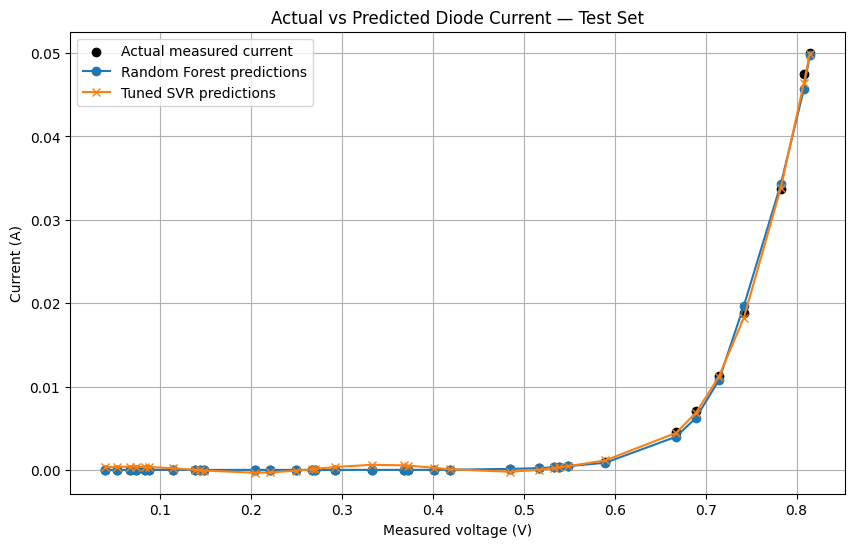

In [ ]:

import matplotlib.pyplot as plt

# Predict current for the same test voltages
rf_predictions = rf_model.predict(X_test_random)
svr_predictions = best_svr.predict(X_test_random)

# Sort by voltage so the graph is easier to read
plot_data = X_test_random.copy()
plot_data["Actual current"] = y_test_random.to_numpy()
plot_data["Random Forest"] = rf_predictions
plot_data["Tuned SVR"] = svr_predictions
plot_data = plot_data.sort_values("v_meas")

# Plot measured and predicted currents
plt.figure(figsize=(10, 6))

plt.scatter(
    plot_data["v_meas"],
    plot_data["Actual current"],
    label="Actual measured current",
    color="black"
)

plt.plot(
    plot_data["v_meas"],
    plot_data["Random Forest"],
    label="Random Forest predictions",
    marker="o"
)

plt.plot(
    plot_data["v_meas"],
    plot_data["Tuned SVR"],
    label="Tuned SVR predictions",
    marker="x"
)

plt.xlabel("Measured voltage (V)")
plt.ylabel("Current (A)")
plt.title("Actual vs Predicted Diode Current — Test Set")
plt.legend()
plt.grid(True)
plt.show()


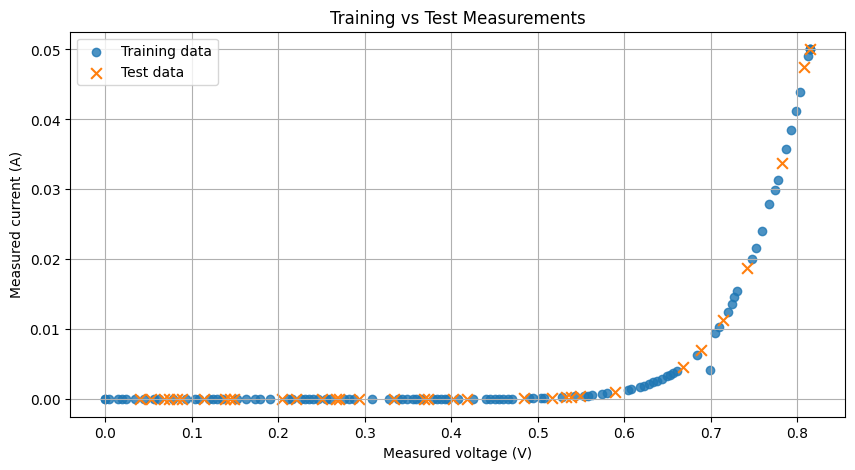

Training voltage range: -0.0002423983 to 0.8146433333333333
Test voltage range: 0.03986423 to 0.8146097000000001


In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.scatter(
    X_train_random["v_meas"],
    y_train_random,
    label="Training data",
    alpha=0.8
)

plt.scatter(
    X_test_random["v_meas"],
    y_test_random,
    label="Test data",
    marker="x",
    s=60
)

plt.xlabel("Measured voltage (V)")
plt.ylabel("Measured current (A)")
plt.title("Training vs Test Measurements")
plt.legend()
plt.grid(True)
plt.show()

print("Training voltage range:",
      X_train_random["v_meas"].min(),
      "to",
      X_train_random["v_meas"].max())

print("Test voltage range:",
      X_test_random["v_meas"].min(),
      "to",
      X_test_random["v_meas"].max())


Training measurements: 51
Test measurements: 119


,Model,MAE (A),RMSE (A),R²
0,Mean baseline,0.009049,0.011792,-0.076987
1,Linear Regression,0.007783,0.009426,0.311787
2,Random Forest,0.000270,0.000723,0.995955
3,Tuned SVR,0.000296,0.000376,0.998907


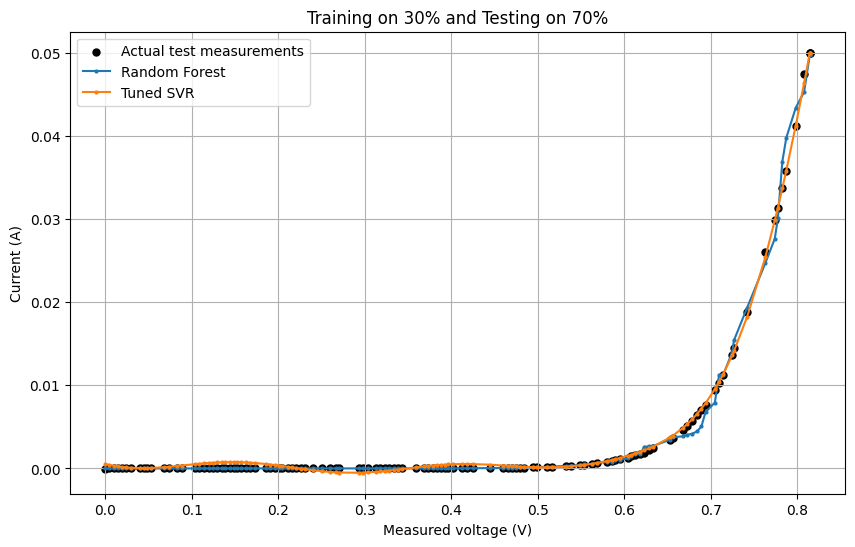

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Step 1: Split data: 30% training, 70% testing
X = data[["v_meas"]]
y = data["i_meas"]

X_train_30, X_test_70, y_train_30, y_test_70 = train_test_split(
    X, y, train_size=0.30, random_state=42
)

print("Training measurements:", len(X_train_30))
print("Test measurements:", len(X_test_70))

# Step 2: Create and train four models using only 30%
models_30 = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    ),
    "Tuned SVR": make_pipeline(
        StandardScaler(),
        SVR(C=100, epsilon=0.0001, gamma=1, kernel="rbf")
    )
}

for model in models_30.values():
    model.fit(X_train_30, y_train_30)

# Step 3: Evaluate on the remaining 70%
results_30 = []

for name, model in models_30.items():
    predictions = model.predict(X_test_70)

    results_30.append({
        "Model": name,
        "MAE (A)": mean_absolute_error(y_test_70, predictions),
        "RMSE (A)": np.sqrt(mean_squared_error(y_test_70, predictions)),
        "R²": r2_score(y_test_70, predictions)
    })

results_30_df = pd.DataFrame(results_30)
display(results_30_df.round(8))

# Step 4: Plot actual and predicted currents
plt.figure(figsize=(10, 6))

plt.scatter(
    X_test_70["v_meas"], y_test_70,
    color="black", s=25, label="Actual test measurements"
)

for name in ["Random Forest", "Tuned SVR"]:
    order = np.argsort(X_test_70["v_meas"].to_numpy())
    plt.plot(
        X_test_70["v_meas"].to_numpy()[order],
        models_30[name].predict(X_test_70)[order],
        marker=".", markersize=4, label=name
    )

plt.xlabel("Measured voltage (V)")
plt.ylabel("Current (A)")
plt.title("Training on 30% and Testing on 70%")
plt.legend()
plt.grid(True)
plt.show()


Training measurements: 51
Test measurements: 119
Training voltage range: -0.0002423983 to 0.2453038
Test voltage range: 0.2500544 to 0.8146680333333333


,Model,MAE (A),RMSE (A),R²
0,Mean baseline,0.007805,0.016293,-0.297873
1,Linear Regression,0.007802,0.016291,-0.297503
2,Random Forest,0.007805,0.016293,-0.297837
3,Tuned SVR,0.007813,0.016297,-0.298454


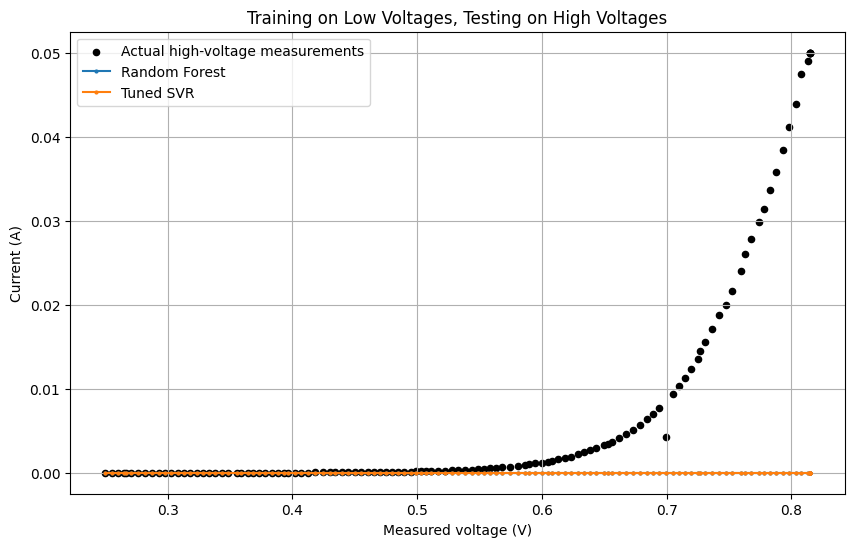

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Sort all measurements from lowest to highest voltage
ordered_data = data.sort_values("v_meas").reset_index(drop=True)

X_ordered = ordered_data[["v_meas"]]
y_ordered = ordered_data["i_meas"]

# Train on the lowest 30%; test on the highest 70%
n_train = int(len(ordered_data) * 0.30)

X_train_low = X_ordered.iloc[:n_train]
y_train_low = y_ordered.iloc[:n_train]

X_test_high = X_ordered.iloc[n_train:]
y_test_high = y_ordered.iloc[n_train:]

print("Training measurements:", len(X_train_low))
print("Test measurements:", len(X_test_high))
print("Training voltage range:",
      X_train_low["v_meas"].min(), "to",
      X_train_low["v_meas"].max())
print("Test voltage range:",
      X_test_high["v_meas"].min(), "to",
      X_test_high["v_meas"].max())

# Create models with the same settings as before
models_ordered = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    ),
    "Tuned SVR": make_pipeline(
        StandardScaler(),
        SVR(C=100, epsilon=0.0001, gamma=1, kernel="rbf")
    )
}

# Train only on low-voltage data
for model in models_ordered.values():
    model.fit(X_train_low, y_train_low)

# Evaluate predictions at higher voltages
results_ordered = []

for name, model in models_ordered.items():
    predictions = model.predict(X_test_high)

    results_ordered.append({
        "Model": name,
        "MAE (A)": mean_absolute_error(y_test_high, predictions),
        "RMSE (A)": np.sqrt(mean_squared_error(y_test_high, predictions)),
        "R²": r2_score(y_test_high, predictions)
    })

results_ordered_df = pd.DataFrame(results_ordered)
display(results_ordered_df.round(8))

# Plot actual measurements and model predictions
plt.figure(figsize=(10, 6))

plt.scatter(
    X_test_high["v_meas"], y_test_high,
    color="black", s=20, label="Actual high-voltage measurements"
)

for name in ["Random Forest", "Tuned SVR"]:
    predictions = models_ordered[name].predict(X_test_high)
    plt.plot(
        X_test_high["v_meas"], predictions,
        marker=".", markersize=4, label=name
    )

plt.xlabel("Measured voltage (V)")
plt.ylabel("Current (A)")
plt.title("Training on Low Voltages, Testing on High Voltages")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
import os

files_to_check = [
    "app.py",
    "random_forest_model.joblib",
    "tuned_svr_model.joblib",
    "diode_iv_data.csv"
]

for filename in files_to_check:
    print(filename, "exists:", os.path.exists(filename))

app.py exists: False
random_forest_model.joblib exists: True
tuned_svr_model.joblib exists: True
diode_iv_data.csv exists: False


In [ ]:
# Save the cleaned dataset for the website
data.to_csv("diode_iv_data.csv", index=False)

import os
print("Dataset file created:", os.path.exists("diode_iv_data.csv"))
print("Rows saved:", len(data))

Dataset file created: True
Rows saved: 170


In [ ]:
import sklearn
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


In [ ]:
import os

files = [
    "random_forest_model.joblib",
    "tuned_svr_model.joblib",
    "diode_iv_data.csv"
]

for file in files:
    print(f"{file}: {'Found' if os.path.exists(file) else 'Not found'}")

random_forest_model.joblib: Found
tuned_svr_model.joblib: Found
diode_iv_data.csv: Found


In [ ]:
import os
import pandas as pd

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]

    for file in files:
        if file.lower().endswith(".csv"):
            path = os.path.join(root, file)

            try:
                df = pd.read_csv(path)
                print("\n" + "=" * 60)
                print("FILE:", path)
                print("Rows:", len(df))
                print("Columns:", list(df.columns))

                temp_cols = [
                    c for c in df.columns
                    if "temp" in c.lower()
                    or c.lower() in ["temperature_k", "temperature_c"]
                ]

                for col in temp_cols:
                    print(
                        f"Temperatures in {col}:",
                        sorted(df[col].dropna().unique().tolist())[:30]
                    )

            except Exception as e:
                print("Could not read:", path, "|", e)


FILE: ./sample_data/california_housing_test.csv
Rows: 3000
Columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']

FILE: ./sample_data/mnist_train_small.csv
Rows: 19999
Columns: ['6', '0', '0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9', '0.10', '0.11', '0.12', '0.13', '0.14', '0.15', '0.16', '0.17', '0.18', '0.19', '0.20', '0.21', '0.22', '0.23', '0.24', '0.25', '0.26', '0.27', '0.28', '0.29', '0.30', '0.31', '0.32', '0.33', '0.34', '0.35', '0.36', '0.37', '0.38', '0.39', '0.40', '0.41', '0.42', '0.43', '0.44', '0.45', '0.46', '0.47', '0.48', '0.49', '0.50', '0.51', '0.52', '0.53', '0.54', '0.55', '0.56', '0.57', '0.58', '0.59', '0.60', '0.61', '0.62', '0.63', '0.64', '0.65', '0.66', '0.67', '0.68', '0.69', '0.70', '0.71', '0.72', '0.73', '0.74', '0.75', '0.76', '0.77', '0.78', '0.79', '0.80', '0.81', '0.82', '0.83', '0.84', '0.85', '0.86', '0.87', '0.88', '0.89', '0.90

In [ ]:
import os

for root, dirs, files in os.walk("."):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__", "sample_data"]
    ]

    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

In [ ]:
import os

print("Current folder:", os.getcwd())
print("\nFiles and folders here:")

for item in os.listdir("."):
    print(item)

Current folder: /content

Files and folders here:
.config
sample_data


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving diode-iv-predictor-Copy-main (1).zip to diode-iv-predictor-Copy-main (1).zip


In [ ]:
import zipfile
import os

zip_path = "/content/diode-iv-predictor-Copy-main.zip"
extract_path = "/content/diode_project"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP extracted successfully!")
print("Project folder contents:")

for item in os.listdir(extract_path):
    print(item)

ZIP extracted successfully!
Project folder contents:
diode-iv-predictor-Copy-main


In [ ]:
import os

project_path = "/content/diode_project/diode-iv-predictor-Copy-main"

print("=== CSV DATASETS ===")
for root, dirs, files in os.walk(project_path):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.relpath(os.path.join(root, file), project_path))

print("\n=== SAVED MODELS ===")
for root, dirs, files in os.walk(project_path):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]
    for file in files:
        if file.lower().endswith((".joblib", ".pkl")):
            print(os.path.relpath(os.path.join(root, file), project_path))

=== CSV DATASETS ===
diode_iv_data.csv
data/external/gan_schottky_measurements.csv
data/external/1n4004_reverse.csv
data/external/sb560_reverse.csv
data/external/1n5229b_reverse.csv
data/external/1n4004_reverse_10uA_range.csv
data/external/1n4004_forward.csv
data/external/sb560_forward.csv
data/external/cryogenic_diode_measurements.csv
data/processed/external_iv_measurements_review.csv
data/processed/classified_diode_measurements.csv

=== SAVED MODELS ===
random_forest_model.joblib
tuned_svr_model.joblib
trained_models/silicon_svr.joblib
trained_models/silicon_carbide_svr.joblib


In [ ]:
import os
import pandas as pd

project_path = "/content/diode_project/diode-iv-predictor-Copy-main"

for root, dirs, files in os.walk(project_path):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]

    for file in sorted(files):
        if not file.lower().endswith(".csv"):
            continue

        path = os.path.join(root, file)

        try:
            df = pd.read_csv(path)
            print("\n" + "=" * 60)
            print("FILE:", os.path.relpath(path, project_path))
            print("Rows:", len(df))
            print("Columns:", list(df.columns))

            for col in df.columns:
                name = col.lower()

                if "temp" in name:
                    values = sorted(df[col].dropna().unique().tolist())
                    print(f"{col}: {len(values)} unique values")
                    print("Temperature examples:", values[:15])

                elif name in ["material", "device", "diode", "part_number"]:
                    print(f"{col} values:",
                          df[col].dropna().unique().tolist()[:15])

        except Exception as e:
            print("Could not read:", file, "|", e)


FILE: diode_iv_data.csv
Rows: 170
Columns: ['v_meas', 'i_meas']

FILE: data/external/1n4004_forward.csv
Rows: 171
Columns: ['v_set', 'v_meas', 'i_meas']

FILE: data/external/1n4004_reverse.csv
Rows: 41
Columns: ['v_set', 'v_meas', 'i_meas']

FILE: data/external/1n4004_reverse_10uA_range.csv
Rows: 41
Columns: ['v_set', 'v_meas', 'i_meas']

FILE: data/external/1n5229b_reverse.csv
Rows: 121
Columns: ['v_set', 'v_meas', 'i_meas']

FILE: data/external/cryogenic_diode_measurements.csv
Rows: 4201
Columns: ['device', 'technology', 'temperature_K', 'voltage_V', 'current_A', 'source_id', 'evidence_type']
device values: ['1N1190', '1N3913', 'BYT65B800', 'A117M', '45L120', '1N11877R', '30FQ030', 'APT2X31D120J', 'BYT61 B800', 'BYS350', 'R18CR16A', 'STTH15RQ06DY', 'M079NYC200', 'FERD20H60CTS', 'SD1100C16C']
temperature_K: 2 unique values
Temperature examples: [77, 293]

FILE: data/external/gan_schottky_measurements.csv
Rows: 5189
Columns: ['Curve_ID', 'T_K', 'Raw_Row', 'V_V', 'I_A', 'log10_I_A', 'B

In [ ]:
import pandas as pd
import os

base = "/content/diode_project/diode-iv-predictor-Copy-main"

files = {
    "Classified data": "data/processed/classified_diode_measurements.csv",
    "GaN data": "data/external/gan_schottky_measurements.csv",
    "Cryogenic data": "data/external/cryogenic_diode_measurements.csv"
}

for name, relative_path in files.items():
    df = pd.read_csv(os.path.join(base, relative_path))

    print("\n" + "=" * 65)
    print(name, "| Total rows:", len(df))

    # Check each material
    if "material" in df.columns:
        print("\nRows per material:")
        print(df.groupby("material").size().to_string())

    # Check each device
    if "device" in df.columns:
        print("\nRows per device (top 15):")
        print(df["device"].value_counts().head(15).to_string())

    # Check the number of measurements at each temperature
    temp_col = next(
        (c for c in ["temperature_K", "T_K"]
         if c in df.columns),
        None
    )

    if temp_col:
        print("\nRows per temperature:")
        print(df.groupby(temp_col).size().to_string())

    # Check which individual devices have data at each temperature
    if temp_col and "device" in df.columns:
        print("\nDevice-temperature combinations:")
        counts = (
            df.groupby(["device", temp_col])
              .size()
              .rename("rows")
              .reset_index()
              .sort_values("rows", ascending=False)
        )
        print(counts.head(25).to_string(index=False))


Classified data | Total rows: 5909

Rows per material:
material
gallium nitride    5189
silicon             492
silicon carbide     228

Rows per device (top 15):
device
Au/Ni/n-GaN Schottky diode    5189
STPSC12065DY                    59
MBR4035                         58
FFSH3065B                       57
45L120                          56
1N3913                          56
C6D20065A                       56
FFSH3065B-F085                  56
BZW1347                         55
BZW1336                         55
BYX661000                       54
BZW12360                        54
1N11877R                        52
1N1190                          52

Rows per temperature:
temperature_K
40     302
60     302
77     426
80     302
100    302
120    302
140    302
160    302
180    152
200    152
220    302
240    297
260    292
280    287
293    294
300    282
320    278
340    274
360    272
380    270
400    217

Device-temperature combinations:
                    device  temperatu

In [ ]:
import os
import numpy as np
import pandas as pd

base = "/content/diode_project/diode-iv-predictor-Copy-main"

datasets = {
    "GaN": "data/external/gan_schottky_measurements.csv",
    "Cryogenic": "data/external/cryogenic_diode_measurements.csv",
    "Classified": "data/processed/classified_diode_measurements.csv",
    "1N4004 forward": "data/external/1n4004_forward.csv",
    "SB560 forward": "data/external/sb560_forward.csv",
}

for name, relative_path in datasets.items():
    df = pd.read_csv(os.path.join(base, relative_path))

    print("\n" + "=" * 60)
    print(name)

    # Select the appropriate voltage and current columns
    voltage_col = next(
        (c for c in ["voltage_V", "V_V", "v_meas"] if c in df.columns),
        None
    )
    current_col = next(
        (c for c in ["current_A", "I_A", "i_meas"] if c in df.columns),
        None
    )

    if voltage_col is None or current_col is None:
        print("Voltage/current columns not identified.")
        continue

    df[voltage_col] = pd.to_numeric(df[voltage_col], errors="coerce")
    df[current_col] = pd.to_numeric(df[current_col], errors="coerce")

    valid = df[[voltage_col, current_col]].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    print("Total rows:", len(df))
    print("Valid voltage-current rows:", len(valid))
    print("Voltage range:", valid[voltage_col].min(),
          "to", valid[voltage_col].max(), "V")
    print("Current range:", valid[current_col].min(),
          "to", valid[current_col].max(), "A")
    print("Distinct voltage values:", valid[voltage_col].nunique())

    if "temperature_K" in df.columns:
        print("Temperatures:", sorted(df["temperature_K"].dropna().unique()))

    if "material" in df.columns:
        print("Materials:", df["material"].dropna().unique().tolist())


GaN
Total rows: 5189
Valid voltage-current rows: 5189
Voltage range: -2.019998 to 1.0 V
Current range: 1.63e-11 to 0.00219782 A
Distinct voltage values: 408
Temperatures: [np.int64(40), np.int64(60), np.int64(80), np.int64(100), np.int64(120), np.int64(140), np.int64(160), np.int64(180), np.int64(200), np.int64(220), np.int64(240), np.int64(260), np.int64(280), np.int64(300), np.int64(320), np.int64(340), np.int64(360), np.int64(380), np.int64(400)]
Materials: ['gallium nitride']

Cryogenic
Total rows: 4201
Valid voltage-current rows: 4201
Voltage range: -0.0566 to 2.8262 V
Current range: 0.0 to 165.8 A
Distinct voltage values: 3473
Temperatures: [np.int64(77), np.int64(293)]

Classified
Total rows: 5909
Valid voltage-current rows: 5909
Voltage range: -2.019998 to 2.0558 V
Current range: 0.0 to 165.8 A
Distinct voltage values: 1082
Temperatures: [np.int64(40), np.int64(60), np.int64(77), np.int64(80), np.int64(100), np.int64(120), np.int64(140), np.int64(160), np.int64(180), np.int64(

In [ ]:

import os
import pandas as pd

base = "/content/diode_project/diode-iv-predictor-Copy-main"
path = os.path.join(
    base, "data/external/gan_schottky_measurements.csv"
)

df = pd.read_csv(path)

# Select measurements at one fixed temperature
fixed = df[df["temperature_K"] == 300].copy()

print("Temperature: 300 K")
print("Rows:", len(fixed))
print("Voltage range:",
      fixed["voltage_V"].min(), "to",
      fixed["voltage_V"].max(), "V")
print("Current range:",
      fixed["current_A"].min(), "to",
      fixed["current_A"].max(), "A")
print("Missing voltage values:",
      fixed["voltage_V"].isna().sum())
print("Missing current values:",
      fixed["current_A"].isna().sum())

print("\nFirst 5 measurements:")
print(fixed[["voltage_V", "current_A"]].head())


Temperature: 300 K
Rows: 282
Voltage range: -2.009998 to 0.8000002 V
Current range: 3.8384e-08 to 0.0021967 A
Missing voltage values: 0
Missing current values: 0

First 5 measurements:
      voltage_V  current_A
3596       0.80   0.002197
3597       0.79   0.002165
3598       0.78   0.002133
3599       0.77   0.002102
3600       0.76   0.002070


In [ ]:

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load the GaN measurements
base = "/content/diode_project/diode-iv-predictor-Copy-main"
path = os.path.join(base, "data/external/gan_schottky_measurements.csv")

df = pd.read_csv(path)
df = df[df["temperature_K"] == 300].copy()
df = df[["voltage_V", "current_A"]].dropna()

# 2. Separate input (voltage) and target (current)
X = df[["voltage_V"]]
y = df["current_A"]

# 3. Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 4. Train the Random Forest model
model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42
)
model.fit(X_train, y_train)

# 5. Predict current for the held-out test measurements
predictions = model.predict(X_test)

# 6. Calculate evaluation metrics
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("=== GaN Random Forest: 300 K ===")
print("Training measurements:", len(X_train))
print("Testing measurements:", len(X_test))
print(f"MAE:  {mae:.8g} A")
print(f"RMSE: {rmse:.8g} A")
print(f"R²:   {r2:.6f}")

# 7. Save the trained model
save_dir = os.path.join(base, "trained_models")
os.makedirs(save_dir, exist_ok=True)

model_path = os.path.join(save_dir, "gan_rf_300K.joblib")
joblib.dump(model, model_path)

print("\nSaved model to:", model_path)


=== GaN Random Forest: 300 K ===
Training measurements: 225
Testing measurements: 57
MAE:  4.2695362e-06 A
RMSE: 9.0320424e-06 A
R²:   0.999650

Saved model to: /content/diode_project/diode-iv-predictor-Copy-main/trained_models/gan_rf_300K.joblib


In [ ]:

import os
import pandas as pd

base = "/content/diode_project/diode-iv-predictor-Copy-main"
path = os.path.join(base, "data/external/gan_schottky_measurements.csv")

df = pd.read_csv(path)

print("Measurements at each temperature:")
print(df.groupby("temperature_K").size().to_string())

print("\nNumber of distinct temperatures:",
      df["temperature_K"].nunique())

print("\nVoltage range by temperature:")
print(
    df.groupby("temperature_K")["voltage_V"]
      .agg(["min", "max", "count"])
      .to_string()
)


Measurements at each temperature:
temperature_K
40     302
60     302
80     302
100    302
120    302
140    302
160    302
180    152
200    152
220    302
240    297
260    292
280    287
300    282
320    278
340    274
360    272
380    270
400    217

Number of distinct temperatures: 19

Voltage range by temperature:
                    min   max  count
temperature_K                       
40            -2.009998  1.00    302
60            -2.009998  1.00    302
80            -2.009998  1.00    302
100           -2.009998  1.00    302
120           -2.009998  1.00    302
140           -2.009998  1.00    302
160           -2.009998  1.00    302
180           -2.019998  1.00    152
200           -2.019998  1.00    152
220           -2.009998  1.00    302
240           -2.009998  0.95    297
260           -2.009998  0.90    292
280           -2.009998  0.85    287
300           -2.009998  0.80    282
320           -2.009998  0.76    278
340           -2.009998  0.72    274
360      

In [ ]:

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

base = "/content/diode_project/diode-iv-predictor-Copy-main"
path = os.path.join(base, "data/external/gan_schottky_measurements.csv")

# 1. Load and clean the measurements
df = pd.read_csv(path)
df = df[["voltage_V", "temperature_K", "current_A"]].dropna()

# Remove any infinite values, if present
df = df.replace([np.inf, -np.inf], np.nan).dropna()

# 2. Hold out every measurement at 300 K for testing
test_temp = 300
train_df = df[df["temperature_K"] != test_temp].copy()
test_df = df[df["temperature_K"] == test_temp].copy()

# 3. Use voltage and temperature as inputs
features = ["voltage_V", "temperature_K"]

X_train = train_df[features]
y_train = train_df["current_A"]

X_test = test_df[features]
y_test = test_df["current_A"]

# 4. Train the model
model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# 5. Predict current at the unseen temperature
predictions = model.predict(X_test)

# 6. Evaluate predictions in amperes
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("=== GaN Temperature-Aware Random Forest ===")
print("Training measurements:", len(X_train))
print("Testing measurements:", len(X_test))
print("Temperatures used for training:",
      sorted(train_df["temperature_K"].unique().tolist()))
print("Held-out temperature:", test_temp, "K")
print(f"MAE:  {mae:.8g} A")
print(f"RMSE: {rmse:.8g} A")
print(f"R²:   {r2:.6f}")

# 7. Save the trained model
save_dir = os.path.join(base, "trained_models")
os.makedirs(save_dir, exist_ok=True)

model_path = os.path.join(
    save_dir, "gan_rf_temperature_aware.joblib"
)
joblib.dump(model, model_path)

print("\nSaved model to:", model_path)


=== GaN Temperature-Aware Random Forest ===
Training measurements: 4907
Testing measurements: 282
Temperatures used for training: [40, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 320, 340, 360, 380, 400]
Held-out temperature: 300 K
MAE:  0.00010356369 A
RMSE: 0.0001104995 A
R²:   0.956749

Saved model to: /content/diode_project/diode-iv-predictor-Copy-main/trained_models/gan_rf_temperature_aware.joblib


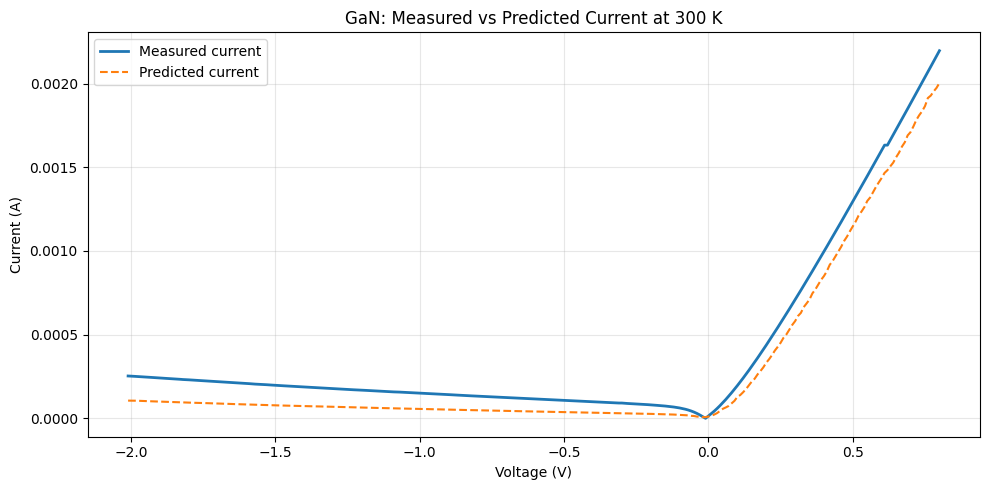

In [ ]:

import os
import matplotlib.pyplot as plt
import pandas as pd

base = "/content/diode_project/diode-iv-predictor-Copy-main"
path = os.path.join(base, "data/external/gan_schottky_measurements.csv")

df = pd.read_csv(path)
test_df = (
    df[df["temperature_K"] == 300]
    .dropna(subset=["voltage_V", "current_A"])
    .sort_values("voltage_V")
    .copy()
)

model_path = os.path.join(
    base, "trained_models/gan_rf_temperature_aware.joblib"
)
model = __import__("joblib").load(model_path)

X_test = test_df[["voltage_V", "temperature_K"]]
test_df["predicted_current_A"] = model.predict(X_test)

plt.figure(figsize=(10, 5))
plt.plot(
    test_df["voltage_V"],
    test_df["current_A"],
    label="Measured current",
    linewidth=2
)
plt.plot(
    test_df["voltage_V"],
    test_df["predicted_current_A"],
    label="Predicted current",
    linestyle="--"
)
plt.xlabel("Voltage (V)")
plt.ylabel("Current (A)")
plt.title("GaN: Measured vs Predicted Current at 300 K")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

import os
import pandas as pd

base = "/content/diode_project/diode-iv-predictor-Copy-main"
path = os.path.join(
    base, "data/processed/classified_diode_measurements.csv"
)

df = pd.read_csv(path)

# Count measurements for each material at each temperature
summary = (
    df.groupby(["material", "temperature_K"])
      .agg(
          rows=("current_A", "size"),
          devices=("device", "nunique"),
          voltage_min=("voltage_V", "min"),
          voltage_max=("voltage_V", "max")
      )
      .reset_index()
)

# Focus on silicon and silicon carbide
summary = summary[
    summary["material"].isin(["silicon", "silicon carbide"])
]

print(summary.to_string(index=False))


       material  temperature_K  rows  devices  voltage_min  voltage_max
        silicon             77   291        9          0.0       2.0558
        silicon            293   201        9          0.0       1.3302
silicon carbide             77   135        4          0.0       1.7627
silicon carbide            293    93        4          0.0       1.4586


In [ ]:

import os
import pandas as pd

base = "/content/diode_project/diode-iv-predictor-Copy-main"
path = os.path.join(
    base, "data/processed/classified_diode_measurements.csv"
)

df = pd.read_csv(path)

for material in ["silicon", "silicon carbide"]:
    subset = df[df["material"] == material]

    print("\n" + "=" * 60)
    print("MATERIAL:", material)

    counts = (
        subset.groupby(["device", "temperature_K"])
        .agg(
            rows=("current_A", "size"),
            voltage_min=("voltage_V", "min"),
            voltage_max=("voltage_V", "max")
        )
        .reset_index()
    )

    print(counts.to_string(index=False))



MATERIAL: silicon
   device  temperature_K  rows  voltage_min  voltage_max
 1N11877R             77    31          0.0       1.3415
 1N11877R            293    21          0.0       0.9421
   1N1190             77    31          0.0       1.2927
   1N1190            293    21          0.0       0.9783
   1N3913             77    37          0.0       2.0558
   1N3913            293    19          0.0       1.2984
   45L120             77    32          0.0       1.4102
   45L120            293    24          0.0       1.0907
BYX661000             77    31          0.0       1.3626
BYX661000            293    23          0.0       1.3302
 BZW12360             77    32          0.0       1.3377
 BZW12360            293    22          0.0       1.0269
  BZW1336             77    33          0.0       1.5159
  BZW1336            293    22          0.0       0.9772
  BZW1347             77    33          0.0       1.4553
  BZW1347            293    22          0.0       1.0636
  MBR4035   

In [ ]:

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

base = "/content/diode_project/diode-iv-predictor-Copy-main"
path = os.path.join(
    base, "data/processed/classified_diode_measurements.csv"
)

df = pd.read_csv(path)

# Select one silicon device at one fixed temperature
data = df[
    (df["material"] == "silicon") &
    (df["device"] == "1N3913") &
    (df["temperature_K"] == 293)
][["voltage_V", "current_A"]].dropna()

X = data[["voltage_V"]]
y = data["current_A"]

# Hold out 20% of the measurements for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42
)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("=== Silicon: 1N3913 at 293 K ===")
print("Total measurements:", len(data))
print("Training measurements:", len(X_train))
print("Testing measurements:", len(X_test))
print(f"MAE:  {mean_absolute_error(y_test, predictions):.8g} A")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predictions)):.8g} A")
print(f"R²:   {r2_score(y_test, predictions):.6f}")

# Save the model
save_dir = os.path.join(base, "trained_models")
os.makedirs(save_dir, exist_ok=True)

model_path = os.path.join(save_dir, "silicon_1N3913_293K_rf.joblib")
joblib.dump(model, model_path)

print("Saved model:", model_path)


=== Silicon: 1N3913 at 293 K ===
Total measurements: 19
Training measurements: 15
Testing measurements: 4
MAE:  3.5909012 A
RMSE: 3.7352201 A
R²:   0.923147
Saved model: /content/diode_project/diode-iv-predictor-Copy-main/trained_models/silicon_1N3913_293K_rf.joblib


In [ ]:

print("Current values for silicon 1N3913 at 293 K:")
print(data["current_A"].describe())

print("\nActual and predicted test values:")
comparison = pd.DataFrame({
    "Voltage (V)": X_test["voltage_V"].to_numpy(),
    "Actual current (A)": y_test.to_numpy(),
    "Predicted current (A)": predictions
})
print(comparison.to_string(index=False))


Current values for silicon 1N3913 at 293 K:
count    19.000000
mean     26.018789
std      22.565353
min       0.000000
25%       4.209500
50%      23.227000
75%      44.387000
max      64.457000
Name: current_A, dtype: float64

Actual and predicted test values:
 Voltage (V)  Actual current (A)  Predicted current (A)
      0.0000               0.000               3.901544
      0.9054               5.790               7.684317
      1.1435              32.564              37.231199
      0.0504               0.001               3.901544


In [ ]:

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

base = "/content/diode_project/diode-iv-predictor-Copy-main"
path = os.path.join(
    base, "data/processed/classified_diode_measurements.csv"
)

df = pd.read_csv(path)

data_sic = df[
    (df["material"] == "silicon carbide") &
    (df["device"] == "STPSC12065DY") &
    (df["temperature_K"] == 293)
][["voltage_V", "current_A"]].dropna()

X_sic = data_sic[["voltage_V"]]
y_sic = data_sic["current_A"]

X_train_sic, X_test_sic, y_train_sic, y_test_sic = train_test_split(
    X_sic, y_sic, test_size=0.20, random_state=42
)

model_sic = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42
)
model_sic.fit(X_train_sic, y_train_sic)

pred_sic = model_sic.predict(X_test_sic)

print("=== SiC: STPSC12065DY at 293 K ===")
print("Total measurements:", len(data_sic))
print("Training measurements:", len(X_train_sic))
print("Testing measurements:", len(X_test_sic))
print(f"MAE:  {mean_absolute_error(y_test_sic, pred_sic):.8g} A")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_sic, pred_sic)):.8g} A")
print(f"R²:   {r2_score(y_test_sic, pred_sic):.6f}")

save_dir = os.path.join(base, "trained_models")
os.makedirs(save_dir, exist_ok=True)

model_path = os.path.join(save_dir, "sic_STPSC12065DY_293K_rf.joblib")
joblib.dump(model_sic, model_path)

print("Saved model:", model_path)

print("\nCurrent range:")
print(data_sic["current_A"].describe())


=== SiC: STPSC12065DY at 293 K ===
Total measurements: 25
Training measurements: 20
Testing measurements: 5
MAE:  0.41436528 A
RMSE: 0.49983003 A
R²:   0.990959
Saved model: /content/diode_project/diode-iv-predictor-Copy-main/trained_models/sic_STPSC12065DY_293K_rf.joblib

Current range:
count    25.000000
mean      7.180604
std       5.393030
min       0.000000
25%       2.255000
50%       7.100000
75%      11.718000
max      15.968000
Name: current_A, dtype: float64


In [ ]:

from sklearn.metrics import mean_absolute_error
import pandas as pd

# Compare the held-out predictions from both models
silicon_results = pd.DataFrame({
    "Material": "Silicon",
    "Voltage (V)": X_test["voltage_V"].to_numpy(),
    "Actual current (A)": y_test.to_numpy(),
    "Predicted current (A)": predictions
})

sic_results = pd.DataFrame({
    "Material": "SiC",
    "Voltage (V)": X_test_sic["voltage_V"].to_numpy(),
    "Actual current (A)": y_test_sic.to_numpy(),
    "Predicted current (A)": pred_sic
})

results = pd.concat(
    [silicon_results, sic_results],
    ignore_index=True
)

results["Absolute error (A)"] = (
    results["Actual current (A)"] -
    results["Predicted current (A)"]
).abs()

print(results.round(5).to_string(index=False))


Material  Voltage (V)  Actual current (A)  Predicted current (A)  Absolute error (A)
 Silicon       0.0000               0.000                3.90154             3.90154
 Silicon       0.9054               5.790                7.68432             1.89432
 Silicon       1.1435              32.564               37.23120             4.66720
 Silicon       0.0504               0.001                3.90154             3.90054
     SiC       1.0629               3.883                4.18911             0.30611
     SiC       1.2671              10.209               10.28548             0.07648
     SiC       0.0000               0.000                0.36334             0.36334
     SiC       1.4339              15.292               14.36582             0.92618
     SiC       1.1431               6.300                6.69971             0.39971


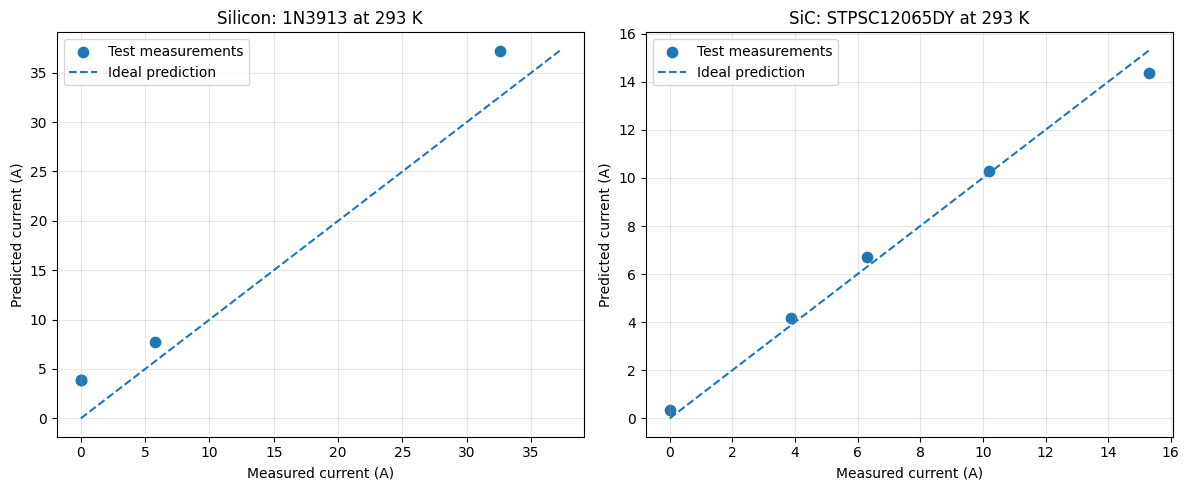

In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plots = [
    (axes[0], X_test, y_test, predictions,
     "Silicon: 1N3913 at 293 K"),
    (axes[1], X_test_sic, y_test_sic, pred_sic,
     "SiC: STPSC12065DY at 293 K")
]

for ax, X, actual, predicted, title in plots:
    ax.scatter(actual, predicted, s=55, label="Test measurements")

    # Ideal predictions lie on this diagonal
    low = min(actual.min(), predicted.min())
    high = max(actual.max(), predicted.max())
    ax.plot([low, high], [low, high], "--", label="Ideal prediction")

    ax.set_xlabel("Measured current (A)")
    ax.set_ylabel("Predicted current (A)")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import pandas as pd

# Train a simple model for silicon
silicon_linear = LinearRegression()
silicon_linear.fit(X_train, y_train)
silicon_linear_pred = silicon_linear.predict(X_test)

# Train a simple model for SiC
sic_linear = LinearRegression()
sic_linear.fit(X_train_sic, y_train_sic)
sic_linear_pred = sic_linear.predict(X_test_sic)

# Compare the errors
comparison = pd.DataFrame({
    "Material": ["Silicon", "Silicon", "SiC", "SiC"],
    "Model": [
        "Random Forest", "Linear Regression",
        "Random Forest", "Linear Regression"
    ],
    "Test MAE (A)": [
        mean_absolute_error(y_test, predictions),
        mean_absolute_error(y_test, silicon_linear_pred),
        mean_absolute_error(y_test_sic, pred_sic),
        mean_absolute_error(y_test_sic, sic_linear_pred)
    ]
})

print(comparison.round(5).to_string(index=False))


Material             Model  Test MAE (A)
 Silicon     Random Forest       3.59090
 Silicon Linear Regression      41.99319
     SiC     Random Forest       0.41437
     SiC Linear Regression       3.37498


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Create many voltage values spanning each device's measured range
silicon_voltage = np.linspace(
    data_silicon["voltage_V"].min(),
    data_silicon["voltage_V"].max(),
    300
)
sic_voltage = np.linspace(
    data_sic["voltage_V"].min(),
    data_sic["voltage_V"].max(),
    300
)

# Predict current at each voltage
silicon_curve = rf_model.predict(
    silicon_voltage.reshape(-1, 1)
)
sic_curve = rf_model_sic.predict(
    sic_voltage.reshape(-1, 1)
)

# Plot measured points and model predictions
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    data_silicon["voltage_V"], data_silicon["current_A"],
    s=18, label="Measured data"
)
axes[0].plot(
    silicon_voltage, silicon_curve,
    label="Random Forest prediction"
)
axes[0].set_title("Silicon at 293 K")
axes[0].set_xlabel("Voltage (V)")
axes[0].set_ylabel("Current (A)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].scatter(
    data_sic["voltage_V"], data_sic["current_A"],
    s=18, label="Measured data"
)
axes[1].plot(
    sic_voltage, sic_curve,
    label="Random Forest prediction"
)
axes[1].set_title("SiC at 293 K")
axes[1].set_xlabel("Voltage (V)")
axes[1].set_ylabel("Current (A)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


NameError: name 'data_silicon' is not defined

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

# Find the project folder
PROJECT = Path("/content/diode_project/diode-iv-predictor-Copy-main")

# Load the classified dataset
csv_path = PROJECT / "data/processed/classified_diode_measurements.csv"
df = pd.read_csv(csv_path)

# Select the same devices at 293 K
data_silicon = df[
    (df["material"].str.lower() == "silicon") &
    (df["device"] == "1N3913") &
    (df["temperature_K"] == 293)
].copy()


data_sic = df[
    (df["material"].str.lower().isin(["sic", "silicon carbide"])) &
    (df["device"] == "STPSC12065DY") &
    (df["temperature_K"] == 293)
].copy()

print("Silicon rows:", len(data_silicon))
print("SiC rows:", len(data_sic))
print("Silicon columns:", data_silicon.columns.tolist())
print("SiC columns:", data_sic.columns.tolist())


Silicon rows: 19
SiC rows: 25
Silicon columns: ['device', 'temperature_K', 'voltage_V', 'current_A', 'source_id', 'evidence_type', 'material']
SiC columns: ['device', 'temperature_K', 'voltage_V', 'current_A', 'source_id', 'evidence_type', 'material']


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


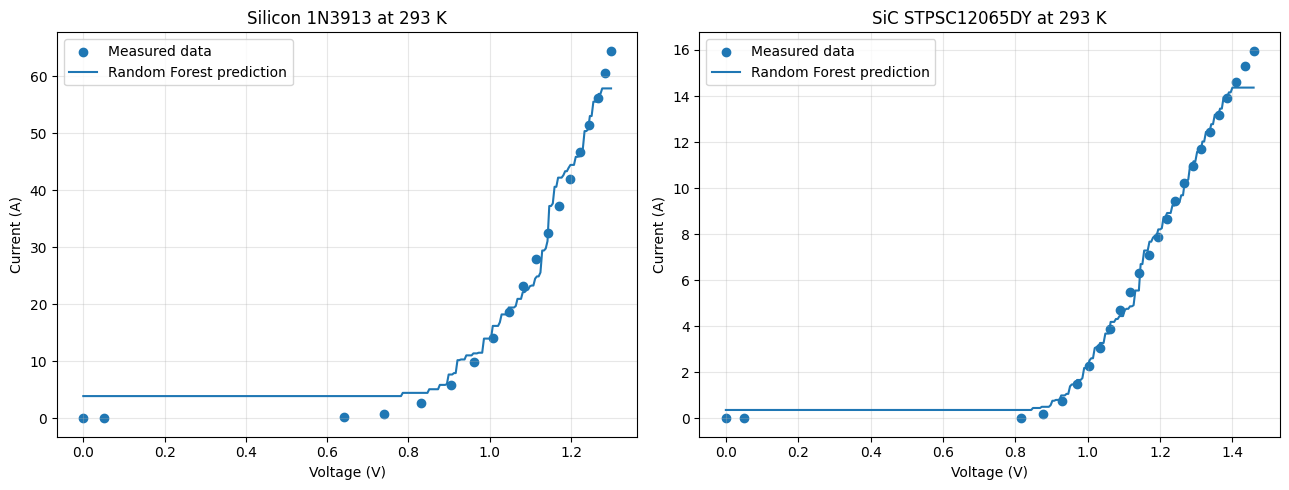

In [ ]:

import joblib
import numpy as np
import matplotlib.pyplot as plt

# Load the saved models
silicon_model = joblib.load(
    PROJECT / "trained_models/silicon_1N3913_293K_rf.joblib"
)
sic_model = joblib.load(
    PROJECT / "trained_models/sic_STPSC12065DY_293K_rf.joblib"
)

# Create voltage values for drawing smooth prediction curves
silicon_voltage = np.linspace(
    data_silicon["voltage_V"].min(),
    data_silicon["voltage_V"].max(), 300
)
sic_voltage = np.linspace(
    data_sic["voltage_V"].min(),
    data_sic["voltage_V"].max(), 300
)

# Predict current using voltage as the only input
silicon_predictions = silicon_model.predict(
    silicon_voltage.reshape(-1, 1)
)
sic_predictions = sic_model.predict(
    sic_voltage.reshape(-1, 1)
)

# Plot both devices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    data_silicon["voltage_V"], data_silicon["current_A"],
    label="Measured data"
)
axes[0].plot(
    silicon_voltage, silicon_predictions,
    label="Random Forest prediction"
)
axes[0].set_title("Silicon 1N3913 at 293 K")
axes[0].set_xlabel("Voltage (V)")
axes[0].set_ylabel("Current (A)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].scatter(
    data_sic["voltage_V"], data_sic["current_A"],
    label="Measured data"
)
axes[1].plot(
    sic_voltage, sic_predictions,
    label="Random Forest prediction"
)
axes[1].set_title("SiC STPSC12065DY at 293 K")
axes[1].set_xlabel("Voltage (V)")
axes[1].set_ylabel("Current (A)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd

# Scale voltage inputs and current targets so SVR can work
# with their different numerical ranges.
def make_svr_model():
    return TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            SVR(kernel="rbf", C=10, epsilon=0.1)
        ),
        transformer=StandardScaler()
    )

# Silicon
silicon_svr = make_svr_model()
silicon_svr.fit(X_train, y_train)
silicon_svr_pred = silicon_svr.predict(X_test)

# SiC
sic_svr = make_svr_model()

sic_svr.fit(X_train_sic, y_train_sic)
sic_svr_pred = sic_svr.predict(X_test_sic)

# Compare MAE on the same test points
comparison = pd.DataFrame({
    "Material": ["Silicon", "Silicon", "Silicon",
                 "SiC", "SiC", "SiC"],
    "Model": ["Random Forest", "Linear Regression", "SVR",
              "Random Forest", "Linear Regression", "SVR"],
    "Test MAE (A)": [
        mean_absolute_error(y_test, predictions),
        mean_absolute_error(y_test, silicon_linear_pred),
        mean_absolute_error(y_test, silicon_svr_pred),
        mean_absolute_error(y_test_sic, pred_sic),
        mean_absolute_error(y_test_sic, sic_linear_pred),
        mean_absolute_error(y_test_sic, sic_svr_pred)
    ]
})

print(comparison.round(5).to_string(index=False))


Material             Model  Test MAE (A)
 Silicon     Random Forest       3.59090
 Silicon Linear Regression      41.99319
 Silicon               SVR      13.73900
     SiC     Random Forest       0.41437
     SiC Linear Regression       3.37498
     SiC               SVR       0.25381


In [ ]:

import joblib

joblib.dump(
    silicon_svr,
    PROJECT / "trained_models/silicon_1N3913_293K_svr.joblib"
)

joblib.dump(
    sic_svr,
    PROJECT / "trained_models/sic_STPSC12065DY_293K_svr.joblib"
)

print("Both SVR models saved successfully.")


Both SVR models saved successfully.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


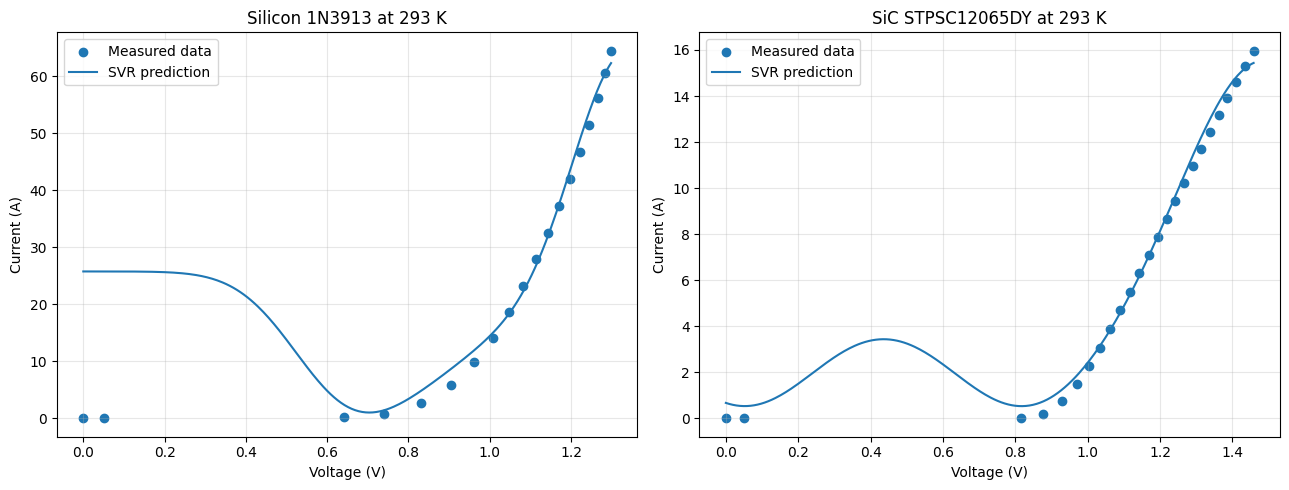

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plots = [
    (axes[0], data_silicon, silicon_svr,
     "Silicon 1N3913 at 293 K"),
    (axes[1], data_sic, sic_svr,
     "SiC STPSC12065DY at 293 K")
]

for ax, data, model, title in plots:
    voltage = np.linspace(
        data["voltage_V"].min(),

        data["voltage_V"].max(),
        300
    )

    current_pred = model.predict(voltage.reshape(-1, 1))

    ax.scatter(
        data["voltage_V"], data["current_A"],
        label="Measured data"
    )
    ax.plot(
        voltage, current_pred,
        label="SVR prediction"
    )
    ax.set_title(title)
    ax.set_xlabel("Voltage (V)")
    ax.set_ylabel("Current (A)")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
data_silicon =

SyntaxError: invalid syntax (2247061609.py, line 1)

In [ ]:
print("Silicon data:")
display(
    data_silicon[
        ["device", "temperature_K", "voltage_V", "current_A"]
    ].sort_values("voltage_V")
)

print("\nSiC data:")
display(
    data_sic[
        ["device", "temperature_K", "voltage_V", "current_A"]
    ].sort_values("voltage_V")
)

Silicon data:


,device,temperature_K,voltage_V,current_A
52,1N3913,293,0.0000,0.000
53,1N3913,293,0.0504,0.001
54,1N3913,293,0.6418,0.204
55,1N3913,293,0.7396,0.810
56,1N3913,293,0.8306,2.629
57,1N3913,293,0.9054,5.790
58,1N3913,293,0.9623,9.793
59,1N3913,293,1.0087,14.124
60,1N3913,293,1.0478,18.631
61,1N3913,293,1.0826,23.227



SiC data:


,device,temperature_K,voltage_V,current_A
216,STPSC12065DY,293,0.0000,0.0000
217,STPSC12065DY,293,0.0508,0.0010
218,STPSC12065DY,293,0.8168,0.0011
219,STPSC12065DY,293,0.8756,0.1960
220,STPSC12065DY,293,0.9291,0.7520
221,STPSC12065DY,293,0.9703,1.4730
222,STPSC12065DY,293,1.0046,2.2550
223,STPSC12065DY,293,1.0343,3.0720
224,STPSC12065DY,293,1.0629,3.8830
225,STPSC12065DY,293,1.0903,4.6950


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


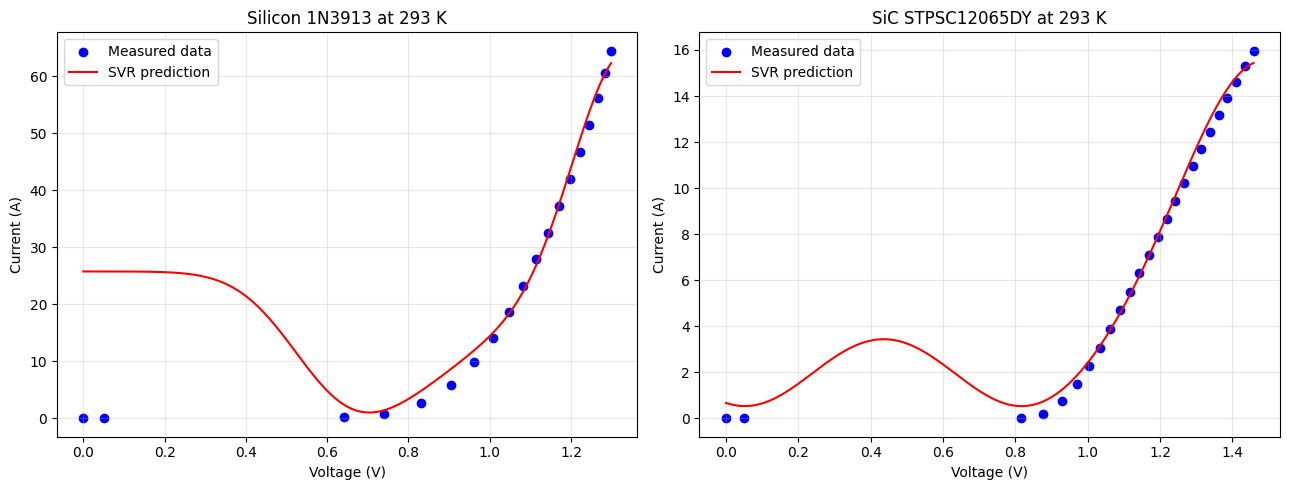

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

# Project folder
PROJECT = Path("/content/diode_project/diode-iv-predictor-Copy-main")

# Load measurements
df = pd.read_csv(
    PROJECT / "data/processed/classified_diode_measurements.csv"
)

# Models and devices
devices = [
    ("Silicon 1N3913 at 293 K", "1N3913",
     "silicon_1N3913_293K_svr.joblib"),
    ("SiC STPSC12065DY at 293 K", "STPSC12065DY",
     "sic_STPSC12065DY_293K_svr.joblib")
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (title, device, filename) in zip(axes, devices):
    data = df[
        (df["device"] == device) &
        (df["temperature_K"] == 293)
    ].sort_values("voltage_V")

    model = joblib.load(PROJECT / "trained_models" / filename)

    voltage = np.linspace(
        data["voltage_V"].min(),
        data["voltage_V"].max(),
        300
    )

    # Predict current using the saved SVR
    prediction = model.predict(voltage.reshape(-1, 1))

    ax.scatter(
        data["voltage_V"], data["current_A"],
        label="Measured data", color="blue"
    )
    ax.plot(
        voltage, prediction,
        label="SVR prediction", color="red"
    )

    ax.set_title(title)
    ax.set_xlabel("Voltage (V)")
    ax.set_ylabel("Current (A)")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


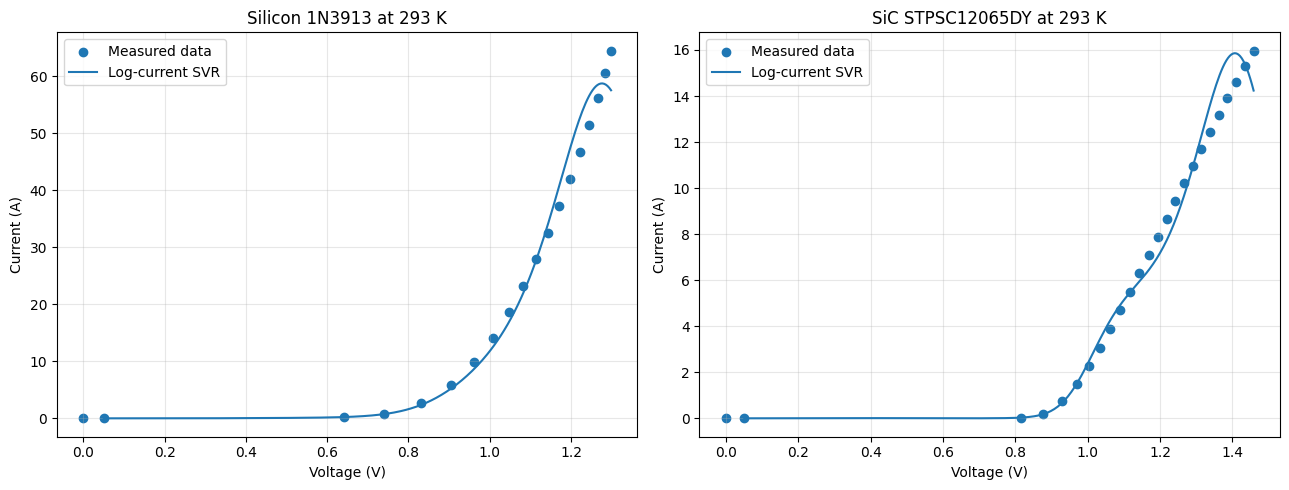

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor

def make_log_svr():
    return TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            SVR(kernel="rbf", C=10, epsilon=0.05)
        ),
        func=np.log10,
        inverse_func=lambda y: 10 ** y
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (title, data) in zip(
    axes,
    [
        ("Silicon 1N3913 at 293 K", data_silicon),
        ("SiC STPSC12065DY at 293 K", data_sic)
    ]
):
    clean = data[
        (data["current_A"] > 0) &
        data["voltage_V"].notna() &
        data["current_A"].notna()
    ].sort_values("voltage_V")

    X = clean[["voltage_V"]]
    y = clean["current_A"]

    model = make_log_svr()
    model.fit(X, y)

    voltage = np.linspace(
        clean["voltage_V"].min(),
        clean["voltage_V"].max(),
        300
    )
    predicted = model.predict(voltage.reshape(-1, 1))

    ax.scatter(
        data["voltage_V"], data["current_A"],
        label="Measured data"
    )
    ax.plot(
        voltage, predicted,
        label="Log-current SVR"
    )
    ax.set_title(title)
    ax.set_xlabel("Voltage (V)")
    ax.set_ylabel("Current (A)")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor
import numpy as np
import pandas as pd

def make_log_svr():
    return TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            SVR(kernel="rbf", C=10, epsilon=0.05)
        ),
        func=np.log10,
        inverse_func=lambda y: 10 ** y
    )

for name, data in [
    ("Silicon 1N3913", data_silicon),
    ("SiC STPSC12065DY", data_sic)
]:
    clean = data[
        (data["current_A"] > 0) &
        data["voltage_V"].notna() &
        data["current_A"].notna()
    ].sort_values("voltage_V").reset_index(drop=True)

    # Keep the split reproducible
    X = clean[["voltage_V"]]
    y = clean["current_A"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=42
    )

    model = make_log_svr()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    baseline = np.full(len(y_test), y_train.mean())

    print(f"\n=== {name} ===")
    print("Training points:", len(X_train))
    print("Testing points:", len(X_test))
    print(f"SVR MAE:      {mean_absolute_error(y_test, pred):.4f} A")
    print(f"Baseline MAE: {mean_absolute_error(y_test, baseline):.4f} A")
    print(f"SVR RMSE:     {np.sqrt(mean_squared_error(y_test, pred)):.4f} A")
    print(f"SVR R²:       {r2_score(y_test, pred):.4f}")
    print("Test voltages:", X_test["voltage_V"].round(4).tolist())



=== Silicon 1N3913 ===
Training points: 13
Testing points: 5
SVR MAE:      2.9859 A
Baseline MAE: 28.0987 A
SVR RMSE:     4.3748 A
SVR R²:       0.7516
Test voltages: [0.0504, 0.6418, 1.0826, 0.9623, 0.8306]

=== SiC STPSC12065DY ===
Training points: 18
Testing points: 6
SVR MAE:      0.4761 A
Baseline MAE: 3.5918 A
SVR RMSE:     0.5274 A
SVR R²:       0.9836
Test voltages: [1.0903, 1.2908, 0.0508, 1.3376, 1.1683, 1.1172]


In [ ]:

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import make_scorer, mean_absolute_error
import numpy as np

def make_log_svr():
    return TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            SVR(kernel="rbf", C=10, epsilon=0.05)
        ),
        func=np.log10,
        inverse_func=lambda y: 10 ** y
    )

for name, data in [
    ("Silicon 1N3913", data_silicon),
    ("SiC STPSC12065DY", data_sic)
]:
    clean = data[
        (data["current_A"] > 0) &
        data["voltage_V"].notna() &
        data["current_A"].notna()
    ].reset_index(drop=True)

    X = clean[["voltage_V"]]
    y = clean["current_A"]

    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    scores = cross_val_score(
        make_log_svr(),
        X, y,
        cv=cv,
        scoring=make_scorer(
            mean_absolute_error,
            greater_is_better=False
        )
    )

    print(f"\n{name}")
    print("Fold MAE (A):", np.round(-scores, 4))
    print(f"Mean MAE: {(-scores).mean():.4f} A")
    print(f"Standard deviation: {scores.std():.4f} A")



Silicon 1N3913
Fold MAE (A): [3.5028 2.5077 4.3918 2.3837 2.6632]
Mean MAE: 3.0898 A
Standard deviation: 0.7596 A

SiC STPSC12065DY
Fold MAE (A): [0.779  0.261  0.6205 1.9869 0.6737]
Mean MAE: 0.8642 A
Standard deviation: 0.5877 A


In [ ]:

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import make_scorer, mean_absolute_error
import pandas as pd
import numpy as np

def make_log_svr():
    return TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            SVR(kernel="rbf", C=10, epsilon=0.05)
        ),
        func=np.log10,
        inverse_func=lambda y: 10 ** y
    )

models = {
    "Log-current SVR": make_log_svr(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42
    ),
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    )
}

results = []

for name, data in [
    ("Silicon 1N3913", data_silicon),
    ("SiC STPSC12065DY", data_sic)
]:
    clean = data[
        (data["current_A"] > 0) &
        data["voltage_V"].notna() &
        data["current_A"].notna()
    ].reset_index(drop=True)

    X = clean[["voltage_V"]]
    y = clean["current_A"]

    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    for model_name, model in models.items():
        scores = cross_val_score(
            model, X, y,
            cv=cv,
            scoring=make_scorer(
                mean_absolute_error,
                greater_is_better=False
            )
        )

        results.append({
            "Device": name,
            "Model": model_name,
            "Mean MAE (A)": round(-scores.mean(), 4),
            "Std MAE (A)": round(scores.std(), 4)
        })

results_df = pd.DataFrame(results)
display(results_df.sort_values(["Device", "Mean MAE (A)"]))


,Device,Model,Mean MAE (A),Std MAE (A)
4,SiC STPSC12065DY,Random Forest,0.6624,0.4338
3,SiC STPSC12065DY,Log-current SVR,0.8642,0.5877
5,SiC STPSC12065DY,Linear Regression,3.1630,1.0742
0,Silicon 1N3913,Log-current SVR,3.0898,0.7596
1,Silicon 1N3913,Random Forest,4.3027,1.0160
2,Silicon 1N3913,Linear Regression,15.6984,8.6094


In [ ]:

import joblib
import numpy as np
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor

PROJECT = Path("/content/diode_project/diode-iv-predictor-Copy-main")
SAVE_DIR = PROJECT / "trained_models"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

def make_log_svr():
    return TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            SVR(kernel="rbf", C=10, epsilon=0.05)
        ),
        func=np.log10,
        inverse_func=lambda y: 10 ** y
    )

# Silicon: selected model is log-current SVR
silicon = data_silicon[
    (data_silicon["current_A"] > 0)
].dropna(subset=["voltage_V", "current_A"])

silicon_model = make_log_svr()
silicon_model.fit(
    silicon[["voltage_V"]],
    silicon["current_A"]
)

silicon_path = SAVE_DIR / "silicon_1N3913_293K_log_svr.joblib"
joblib.dump(silicon_model, silicon_path)

# SiC: selected model is Random Forest
sic = data_sic[
    (data_sic["current_A"] > 0)
].dropna(subset=["voltage_V", "current_A"])

sic_model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42
)
sic_model.fit(sic[["voltage_V"]], sic["current_A"])

sic_path = SAVE_DIR / "sic_STPSC12065DY_293K_rf_selected.joblib"
joblib.dump(sic_model, sic_path)

print("Saved Silicon model:", silicon_path)
print("Saved SiC model:", sic_path)
print("Silicon training points:", len(silicon))
print("SiC training points:", len(sic))


PicklingError: Can't pickle <function make_log_svr.<locals>.<lambda> at 0x7d901c4dd080>: it's not found as __main__.make_log_svr.<locals>.<lambda>

In [ ]:

import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor

def make_log_svr():
    return TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            SVR(kernel="rbf", C=10, epsilon=0.05)
        ),
        func=np.log10,
        inverse_func=np.power,
        check_inverse=False
    )


In [ ]:

def inverse_log10(y):
    return np.power(10.0, y)

def make_log_svr():
    return TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            SVR(kernel="rbf", C=10, epsilon=0.05)
        ),
        func=np.log10,
        inverse_func=inverse_log10
    )


In [ ]:

import joblib
import numpy as np
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor

PROJECT = Path("/content/diode_project/diode-iv-predictor-Copy-main")
SAVE_DIR = PROJECT / "trained_models"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

def make_log_svr():
    return TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            SVR(kernel="rbf", C=10, epsilon=0.05)
        ),
        func=np.log10,
        inverse_func=np.exp10
    )

# Silicon: selected model is log-current SVR
silicon = data_silicon[
    (data_silicon["current_A"] > 0)
].dropna(subset=["voltage_V", "current_A"])

silicon_model = make_log_svr()
silicon_model.fit(
    silicon[["voltage_V"]],
    silicon["current_A"]
)

silicon_path = SAVE_DIR / "silicon_1N3913_293K_log_svr.joblib"
joblib.dump(silicon_model, silicon_path)

# SiC: selected model is Random Forest
sic = data_sic[
    (data_sic["current_A"] > 0)
].dropna(subset=["voltage_V", "current_A"])

sic_model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42
)
sic_model.fit(sic[["voltage_V"]], sic["current_A"])

sic_path = SAVE_DIR / "sic_STPSC12065DY_293K_rf_selected.joblib"
joblib.dump(sic_model, sic_path)

print("Saved Silicon model:", silicon_path)
print("Saved SiC model:", sic_path)
print("Silicon training points:", len(silicon))
print("SiC training points:", len(sic))


AttributeError: module 'numpy' has no attribute 'exp10'

In [ ]:
import numpy as np
import joblib
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

silicon = data_silicon[
    data_silicon["current_A"] > 0
].dropna(subset=["voltage_V", "current_A"])

silicon_model = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=10, epsilon=0.05)
    ),
    func=np.log10,
    inverse_func=np.exp10
)

silicon_model.fit(
    silicon[["voltage_V"]],
    silicon["current_A"]
)

print("Silicon model recreated successfully.")

AttributeError: module 'numpy' has no attribute 'exp10'

In [ ]:
from sklearn.preprocessing import FunctionTransformer
import numpy as np

def inverse_log_transform(y):
    return np.power(10.0, y)

print("Inverse transformation ready.")

Inverse transformation ready.


In [ ]:
silicon_model = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=10, epsilon=0.05)
    ),
    func=np.log10,
    inverse_func=inverse_log_transform
)

silicon_model.fit(
    silicon[["voltage_V"]],
    silicon["current_A"]
)

print("Silicon model trained successfully.")

Silicon model trained successfully.


In [ ]:
silicon_path = SAVE_DIR / "silicon_1N3913_293K_log_svr.joblib"

joblib.dump(silicon_model, silicon_path)

print("Saved to:", silicon_path)

Saved to: /content/diode_project/diode-iv-predictor-Copy-main/trained_models/silicon_1N3913_293K_log_svr.joblib


In [ ]:
from sklearn.ensemble import RandomForestRegressor
import joblib

sic = data_sic[
    data_sic["current_A"] > 0
].dropna(subset=["voltage_V", "current_A"])

sic_model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42
)

sic_model.fit(
    sic[["voltage_V"]],
    sic["current_A"]
)

sic_path = SAVE_DIR / "sic_STPSC12065DY_293K_rf_selected.joblib"
joblib.dump(sic_model, sic_path)

print("SiC model saved to:", sic_path)

SiC model saved to: /content/diode_project/diode-iv-predictor-Copy-main/trained_models/sic_STPSC12065DY_293K_rf_selected.joblib


In [ ]:
import joblib
import pandas as pd

silicon_path = SAVE_DIR / "silicon_1N3913_293K_log_svr.joblib"
sic_path = SAVE_DIR / "sic_STPSC12065DY_293K_rf_selected.joblib"

silicon_check = joblib.load(silicon_path)
sic_check = joblib.load(sic_path)

silicon_test = silicon_check.predict(pd.DataFrame({"voltage_V": [0.9, 1.1]}))
sic_test = sic_check.predict(pd.DataFrame({"voltage_V": [1.0, 1.2]}))

print("Silicon predictions (A):", silicon_test)
print("SiC predictions (A):", sic_test)
print("Both models loaded and predicted successfully.")

Silicon predictions (A): [ 4.98311057 25.02200807]
SiC predictions (A): [2.0467267  8.18135442]
Both models loaded and predicted successfully.


In [ ]:
from pathlib import Path

app_path = PROJECT / "app.py"

print("app.py exists:", app_path.exists())
print("App path:", app_path)

print("\nNew model files:")
for path in sorted(SAVE_DIR.glob("*293K*")):
    print(path.name)

app.py exists: True
App path: /content/diode_project/diode-iv-predictor-Copy-main/app.py

New model files:
sic_STPSC12065DY_293K_rf.joblib
sic_STPSC12065DY_293K_rf_selected.joblib
sic_STPSC12065DY_293K_svr.joblib
silicon_1N3913_293K_log_svr.joblib
silicon_1N3913_293K_rf.joblib
silicon_1N3913_293K_svr.joblib


In [ ]:
app_text = app_path.read_text()

for i, line in enumerate(app_text.splitlines(), start=1):
    if any(word in line.lower() for word in [
        "joblib", "load(", "silicon_1n3913",
        "stpsc12065dy", "trained_models"
    ]):
        print(f"{i}: {line}")

2: import joblib
58:         ("Random Forest", "random_forest_model.joblib"),
59:         ("Tuned SVR", "tuned_svr_model.joblib"),
60:         ("Silicon SVR", "trained_models/silicon_svr.joblib"),
61:         ("SiC SVR", "trained_models/silicon_carbide_svr.joblib"),
65:                 loaded[label] = joblib.load(filename)
245:             "No saved models loaded. Confirm the model .joblib files "
280:                 "STPSC12065DY",


In [ ]:
lines = app_text.splitlines()

print("\n".join(
    f"{i+1}: {lines[i]}"
    for i in range(45, min(80, len(lines)))
))

46: hr { border-color:#203b5d; }
47: </style>
48: """, unsafe_allow_html=True)
49: 
50: # ---------- Load project assets ----------
51: 
52: @st.cache_resource
53: def load_models():
54:     loaded = {}
55:     errors = []
56: 
57:     for label, filename in [
58:         ("Random Forest", "random_forest_model.joblib"),
59:         ("Tuned SVR", "tuned_svr_model.joblib"),
60:         ("Silicon SVR", "trained_models/silicon_svr.joblib"),
61:         ("SiC SVR", "trained_models/silicon_carbide_svr.joblib"),
62:     ]:
63:         if os.path.exists(filename):
64:             try:
65:                 loaded[label] = joblib.load(filename)
66:             except Exception as exc:
67:                 errors.append(f"{filename}: {exc}")
68:         else:
69:             errors.append(f"Missing file: {filename}")
70: 
71:     return loaded, errors
72: 
73: 
74: @st.cache_data
75: def load_data():
76:     path = "diode_iv_data.csv"
77:     if not os.path.exists(path):
78:         return pd.DataF

In [ ]:
for i, line in enumerate(app_text.splitlines(), start=1):
    if 230 <= i <= 310:
        print(f"{i}: {line}")

230: # ---------- PREDICTOR ----------
231: 
232: elif st.session_state.page == "Predictor":
233:     st.markdown(
234:         '<div class="section-kicker">Interactive inference</div>',
235:         unsafe_allow_html=True,
236:     )
237:     st.title("Diode current predictor")
238:     st.write(
239:         "Choose a trained model and enter a voltage. "
240:         "Predictions outside the measured voltage range may be unreliable."
241:     )
242: 
243:     if not models:
244:         st.error(
245:             "No saved models loaded. Confirm the model .joblib files "
246:             "are in the repository."
247:         )
248:     else:
249:         model_name = st.selectbox("Choose a model", list(models.keys()))
250: 
251:         safe_min = max(0.0, vmin)
252:         voltage = st.number_input(
253:             "Measured voltage (V)",
254:             min_value=-0.1,
255:             max_value=max(1.5, vmax + 0.5),
256:             value=float(min(max(0.70, safe_min), vmax)),


In [ ]:
lines = app_text.splitlines()

print("\n".join(
    f"{i+1}: {lines[i]}"
    for i in range(295, min(365, len(lines)))
))

296:             max_value=500.0,
297:             value=293.0,
298:             step=1.0,
299:         )
300:         
301:         if model_name in ["Silicon SVR", "SiC SVR"]:
302:             if not 77.0 <= temperature <= 293.0:
303:                 st.warning(
304:                     "The SVR models were trained on data from "
305:                     "77 K to 293 K. Predictions outside this "
306:                     "temperature range may be unreliable."
307:                 )
308: 
309: 
310:         
311:         
312:         
313:         
314:         if st.button("Predict current", key="predict_button"):
315:             # Clear the previous result before attempting a new prediction.
316:             st.session_state.pop("last_prediction", None)
317: 
318:             try:
319:                 if model_name in ["Silicon SVR", "SiC SVR"]:
320:                     if training_data.empty:
321:                         st.error("The training dataset could not be loaded.")
322: 

In [ ]:
print("\n".join(
    f"{i+1}: {i_line}"
    for i, i_line in enumerate(app_text.splitlines()[364:410], start=364)
))

365:                                     "voltage": voltage,
366:                                     "temperature": temperature,
367:                                     "current": current,
368:                                 }
369: 
370:                 else:
371:                     # Original models use voltage as their only input.
372:                     current = float(
373:                         np.asarray(
374:                             models[model_name].predict(
375:                                 np.array([[voltage]])
376:                             )
377:                         ).reshape(-1)[0]
378:                     )
379: 
380:                     if not np.isfinite(current):
381:                         st.error("The model returned a non-finite prediction.")
382:                     else:
383:                         st.session_state.last_prediction = {
384:                             "model": model_name,
385:                             "device": device,
386

In [ ]:
from shutil import copy2

backup_path = PROJECT / "app.py.backup_before_new_models"
copy2(app_path, backup_path)

print("Backup created:", backup_path)

Backup created: /content/diode_project/diode-iv-predictor-Copy-main/app.py.backup_before_new_models


In [ ]:
old = '''    for label, filename in [
        ("Random Forest", "random_forest_model.joblib"),
        ("Tuned SVR", "tuned_svr_model.joblib"),
        ("Silicon SVR", "trained_models/silicon_svr.joblib"),
        ("SiC SVR", "trained_models/silicon_carbide_svr.joblib"),
    ]:'''

new = '''    for label, filename in [
        ("Random Forest", "random_forest_model.joblib"),
        ("Tuned SVR", "tuned_svr_model.joblib"),
        ("Silicon SVR", "trained_models/silicon_svr.joblib"),
        ("SiC SVR", "trained_models/silicon_carbide_svr.joblib"),
        ("Silicon 1N3913 (293 K) Log-SVR", "trained_models/silicon_1N3913_293K_log_svr.joblib"),
        ("SiC STPSC12065DY (293 K) Random Forest", "trained_models/sic_STPSC12065DY_293K_rf_selected.joblib"),
    ]:'''

if old not in app_text:
    print("STOP: exact model list not found; app.py was not changed.")
else:
    updated_app_text = app_text.replace(old, new, 1)
    app_path.write_text(updated_app_text)
    app_text = updated_app_text
    print("Model list updated successfully.")

Model list updated successfully.


In [ ]:
lines = app_path.read_text().splitlines()

print("\n".join(
    f"{i+1}: {lines[i]}"
    for i in range(245, min(315, len(lines)))
))

246:         st.error(
247:             "No saved models loaded. Confirm the model .joblib files "
248:             "are in the repository."
249:         )
250:     else:
251:         model_name = st.selectbox("Choose a model", list(models.keys()))
252: 
253:         safe_min = max(0.0, vmin)
254:         voltage = st.number_input(
255:             "Measured voltage (V)",
256:             min_value=-0.1,
257:             max_value=max(1.5, vmax + 0.5),
258:             value=float(min(max(0.70, safe_min), vmax)),
259:             step=0.005,
260:             format="%.5f",
261:         )
262: 
263:        
264:         
265:         if model_name == "Silicon SVR":
266:             device_options = [
267:                 "1N11877R",
268:                 "1N1190",
269:                 "1N3913",
270:                 "45L120",
271:                 "BYX661000",
272:                 "BZW12360",
273:                 "BZW1336",
274:                 "BZW1347",
275:                 "MBR4035",
27

In [ ]:
old = '''        if model_name == "Silicon SVR":
            device_options = [
                "1N11877R",
                "1N1190",
                "1N3913",
                "45L120",
                "BYX661000",
                "BZW12360",
                "BZW1336",
                "BZW1347",
                "MBR4035",
            ]
        elif model_name == "SiC SVR":
            device_options = [
                "C6D20065A",
                "FFSH3065B",
                "FFSH3065B-F085",
                "STPSC12065DY",
            ]
        else:'''

new = '''        if model_name == "Silicon 1N3913 (293 K) Log-SVR":
            device_options = ["1N3913"]
        elif model_name == "SiC STPSC12065DY (293 K) Random Forest":
            device_options = ["STPSC12065DY"]
        elif model_name == "Silicon SVR":
            device_options = [
                "1N11877R",
                "1N1190",
                "1N3913",
                "45L120",
                "BYX661000",
                "BZW12360",
                "BZW1336",
                "BZW1347",
                "MBR4035",
            ]
        elif model_name == "SiC SVR":
            device_options = [
                "C6D20065A",
                "FFSH3065B",
                "FFSH3065B-F085",
                "STPSC12065DY",
            ]
        else:'''

if old not in app_text:
    print("STOP: expected device-options section not found; no changes made.")
else:
    updated_app_text = app_text.replace(old, new, 1)
    app_path.write_text(updated_app_text)
    app_text = updated_app_text
    print("Device options updated successfully.")

Device options updated successfully.


In [ ]:
lines = app_path.read_text().splitlines()

print("\n".join(
    f"{i+1}: {lines[i]}"
    for i in range(290, min(315, len(lines)))
))

291:                 "Generic silicon",
292:                 "Silicon carbide",
293:                 "GaN Schottky",
294:             ]
295: 
296:         device = st.selectbox("Device", device_options)
297: 
298: 
299:         temperature = st.number_input(
300:             "Temperature (K)",
301:             min_value=1.0,
302:             max_value=500.0,
303:             value=293.0,
304:             step=1.0,
305:         )
306:         
307:         if model_name in ["Silicon SVR", "SiC SVR"]:
308:             if not 77.0 <= temperature <= 293.0:
309:                 st.warning(
310:                     "The SVR models were trained on data from "
311:                     "77 K to 293 K. Predictions outside this "
312:                     "temperature range may be unreliable."
313:                 )
314: 
315: 


In [ ]:
for device in ["1N3913", "STPSC12065DY"]:
    subset = df[df["device"] == device]
    print(f"\n{device}")
    print("Material:", subset["material"].unique())
    print("Temperatures (K):",
          sorted(subset["temperature_K"].dropna().unique()))
    print("Rows:", len(subset))


1N3913
Material: ['silicon']
Temperatures (K): [np.int64(77), np.int64(293)]
Rows: 56

STPSC12065DY
Material: ['silicon carbide']
Temperatures (K): [np.int64(77), np.int64(293)]
Rows: 59


In [ ]:
import pandas as pd

data_path = PROJECT / "data/processed/classified_diode_measurements.csv"
df = pd.read_csv(data_path)

summary = (
    df.dropna(subset=["material", "device", "temperature_K"])
      .groupby(["material", "device"])
      .agg(
          temperatures=("temperature_K", "nunique"),
          min_temp_K=("temperature_K", "min"),
          max_temp_K=("temperature_K", "max"),
          rows=("temperature_K", "size"),
      )
      .reset_index()
      .sort_values(["material", "device"])
)

print(summary.to_string(index=False))

       material                     device  temperatures  min_temp_K  max_temp_K  rows
gallium nitride Au/Ni/n-GaN Schottky diode            19          40         400  5189
        silicon                   1N11877R             2          77         293    52
        silicon                     1N1190             2          77         293    52
        silicon                     1N3913             2          77         293    56
        silicon                     45L120             2          77         293    56
        silicon                  BYX661000             2          77         293    54
        silicon                   BZW12360             2          77         293    54
        silicon                    BZW1336             2          77         293    55
        silicon                    BZW1347             2          77         293    55
        silicon                    MBR4035             2          77         293    58
silicon carbide                  C6D20065A 

In [ ]:
for (material, device), group in df.groupby(["material", "device"]):
    temps = sorted(group["temperature_K"].dropna().unique())
    print(f"{material} | {device}: {temps}")

gallium nitride | Au/Ni/n-GaN Schottky diode: [np.int64(40), np.int64(60), np.int64(80), np.int64(100), np.int64(120), np.int64(140), np.int64(160), np.int64(180), np.int64(200), np.int64(220), np.int64(240), np.int64(260), np.int64(280), np.int64(300), np.int64(320), np.int64(340), np.int64(360), np.int64(380), np.int64(400)]
silicon | 1N11877R: [np.int64(77), np.int64(293)]
silicon | 1N1190: [np.int64(77), np.int64(293)]
silicon | 1N3913: [np.int64(77), np.int64(293)]
silicon | 45L120: [np.int64(77), np.int64(293)]
silicon | BYX661000: [np.int64(77), np.int64(293)]
silicon | BZW12360: [np.int64(77), np.int64(293)]
silicon | BZW1336: [np.int64(77), np.int64(293)]
silicon | BZW1347: [np.int64(77), np.int64(293)]
silicon | MBR4035: [np.int64(77), np.int64(293)]
silicon carbide | C6D20065A: [np.int64(77), np.int64(293)]
silicon carbide | FFSH3065B: [np.int64(77), np.int64(293)]
silicon carbide | FFSH3065B-F085: [np.int64(77), np.int64(293)]
silicon carbide | STPSC12065DY: [np.int64(77), 

In [ ]:
print("Columns:")
print(df.columns.tolist())

print("\nCurrent values by material:")
print(
    df.groupby("material")["current_A"]
      .agg(
          rows="count",
          minimum="min",
          maximum="max",
          zero_currents=lambda s: (s == 0).sum(),
          negative_currents=lambda s: (s < 0).sum()
      )
      .to_string()
)

Columns:
['device', 'temperature_K', 'voltage_V', 'current_A', 'source_id', 'evidence_type', 'material']

Current values by material:
                 rows       minimum     maximum  zero_currents  negative_currents
material                                                                         
gallium nitride  5189  1.630000e-11    0.002198              0                  0
silicon           492  0.000000e+00  165.800000             18                  0
silicon carbide   228  0.000000e+00   25.089000              8                  0


In [ ]:
mask = df["device"].astype(str).str.contains(
    "1N4004", case=False, na=False
)

d = df.loc[mask]

print("1N4004 rows:", len(d))

if len(d):
    print("Materials:", d["material"].unique())
    print("Temperatures:", sorted(d["temperature_K"].unique()))
    print("Voltage range:", d["voltage_V"].min(), "to", d["voltage_V"].max())
    print("Current range:", d["current_A"].min(), "to", d["current_A"].max())
else:
    print("No 1N4004 measurements found in this dataset.")

1N4004 rows: 0
No 1N4004 measurements found in this dataset.


In [ ]:
app_text = app_path.read_text()

for i, line in enumerate(app_text.splitlines(), start=1):
    if "1N4004" in line or "forward" in line.lower() or "reverse" in line.lower():
        print(f"{i}: {line}")

178:     ax.set_title("1N4004 forward-bias I–V characteristics", color="#eaf4ff", pad=12, fontsize=13)
196:       <p>Explore how a 1N4004 diode responds to forward voltage. Compare regression models trained on measured I–V data, make predictions, and inspect the dataset in one interactive workspace.</p>
214:         st.markdown('<div class="content-card"><h3>⚡ Predictor</h3><p class="small-muted">Enter a voltage and estimate forward current using a saved model.</p></div>', unsafe_allow_html=True)
290:                 "1N4004",
439:                     f"1N4004 measured range ({vmin:.5f}–{vmax:.5f} V). "
464:                 st.markdown("### Original 1N4004 measured I–V curve")
470:             st.markdown("### Original 1N4004 measured I–V curve")
481:     "1N4004 dataset. The metrics are displayed from saved values rather "
539: st.markdown('<p class="small-muted">DiodeLab AI · Educational ML demonstration · Predictions are estimates based on one measured 1N4004 voltage sweep.</p>', un

In [ ]:
lines = app_path.read_text().splitlines()

print("\n".join(
    f"{i+1}: {lines[i]}"
    for i in range(150, min(225, len(lines)))
))

151: if valid_data:
152:     vmin = float(data["v_meas"].min())
153:     vmax = float(data["v_meas"].max())
154:     imin = float(data["i_meas"].min())
155:     imax = float(data["i_meas"].max())
156: else:
157:     vmin, vmax, imin, imax = 0.0, 0.815, 0.0, 0.05
158: 
159: # ---------- Shared plotting helper ----------
160: def draw_iv_curve(show_models=False, selected_model=None, highlight_voltage=None):
161:     fig, ax = plt.subplots(figsize=(9, 4.8))
162:     fig.patch.set_facecolor("#081326")
163:     ax.set_facecolor("#081326")
164:     if valid_data:
165:         ax.scatter(data["v_meas"], data["i_meas"], s=19, alpha=.78, label="Measured data")
166:     if show_models and models and valid_data:
167:         xs = np.linspace(vmin, vmax, 350).reshape(-1, 1)
168:         for label, model in models.items():
169:             if selected_model and label != selected_model:
170:                 continue
171:             try:
172:                 ys = np.asarray(model.predict(xs)).reshap

In [ ]:
lines = app_path.read_text().splitlines()

print("\n".join(
    f"{i+1}: {lines[i]}"
    for i in range(1, min(50, len(lines)))
))

2: import joblib
3: import numpy as np
4: import pandas as pd
5: import streamlit as st
6: import matplotlib.pyplot as plt
7: 
8: st.set_page_config(
9:     page_title="DiodeLab AI | I–V Predictor",
10:     page_icon="⚡",
11:     layout="wide",
12:     initial_sidebar_state="collapsed",
13: )
14: 
15: # ---------- Theme and styling ----------
16: st.markdown("""
17: <style>
18: @import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&display=swap');
19: html, body, [class*="css"] { font-family: 'Inter', sans-serif; }
20: :root { color-scheme: dark; }
21: .stApp { background: radial-gradient(ellipse at 50% -18%, rgba(0,153,255,.22), transparent 48%), radial-gradient(circle at 85% 25%, rgba(0,210,255,.08), transparent 28%), #050b18; color:#eaf4ff; }
22: header[data-testid="stHeader"] { height: 0.25rem; background: transparent; }
23: .block-container { max-width: 1320px; padding-top: .55rem !important; padding-bottom: 2.5rem; }
24: [data-testid="stSidebar"] { d

In [ ]:
lines = app_path.read_text().splitlines()

print("\n".join(
    f"{i+1}: {lines[i]}"
    for i in range(49, min(100, len(lines)))
))

50: # ---------- Load project assets ----------
51: 
52: @st.cache_resource
53: def load_models():
54:     loaded = {}
55:     errors = []
56: 
57:     for label, filename in [
58:         ("Random Forest", "random_forest_model.joblib"),
59:         ("Tuned SVR", "tuned_svr_model.joblib"),
60:         ("Silicon SVR", "trained_models/silicon_svr.joblib"),
61:         ("SiC SVR", "trained_models/silicon_carbide_svr.joblib"),
62:         ("Silicon 1N3913 (293 K) Log-SVR", "trained_models/silicon_1N3913_293K_log_svr.joblib"),
63:         ("SiC STPSC12065DY (293 K) Random Forest", "trained_models/sic_STPSC12065DY_293K_rf_selected.joblib"),
64:     ]:
65:         if os.path.exists(filename):
66:             try:
67:                 loaded[label] = joblib.load(filename)
68:             except Exception as exc:
69:                 errors.append(f"{filename}: {exc}")
70:         else:
71:             errors.append(f"Missing file: {filename}")
72: 
73:     return loaded, errors
74: 
75: 
76: @st

In [ ]:
lines = app_path.read_text().splitlines()

print("\n".join(
    f"{i+1}: {lines[i]}"
    for i in range(89, min(145, len(lines)))
))

90: def load_training_data():
91:     path = "data/processed/classified_diode_measurements.csv"
92: 
93:     if not os.path.exists(path):
94:         return pd.DataFrame()
95: 
96:     df = pd.read_csv(path)
97: 
98:     required_columns = {
99:         "device",
100:         "material",
101:         "voltage_V",
102:         "current_A",
103:         "temperature_K",
104:     }
105: 
106:     if not required_columns.issubset(df.columns):
107:         return pd.DataFrame()
108: 
109:     df = df.dropna(
110:         subset=["device", "voltage_V", "current_A", "temperature_K"]
111:     ).copy()
112: 
113:     return df
114: 
115: 
116: models, model_errors = load_models()
117: data = load_data()
118: training_data = load_training_data()
119: 
120: PAGES = ["Home", "Predictor", "Model Comparison", "Dataset Explorer"]
121: 
122: if "page" not in st.session_state:
123:     st.session_state.page = "Home"
124: if "navigation_radio" not in st.session_state:
125:     st.session_state.navigatio

In [ ]:
lines = app_path.read_text().splitlines()

print("\n".join(
    f"{i+1}: {lines[i]}"
    for i in range(140, min(160, len(lines)))
))

141:         st.button(label, key=f"topnav_{target}", use_container_width=True, on_click=go_to, args=(target,))
142: 
143: page = st.session_state.page
144: 
145: if model_errors:
146:     with st.expander("Asset loading notes", expanded=False):
147:         for error in model_errors:
148:             st.warning(error)
149: 
150: valid_data = not data.empty and {"v_meas", "i_meas"}.issubset(data.columns)
151: if valid_data:
152:     vmin = float(data["v_meas"].min())
153:     vmax = float(data["v_meas"].max())
154:     imin = float(data["i_meas"].min())
155:     imax = float(data["i_meas"].max())
156: else:
157:     vmin, vmax, imin, imax = 0.0, 0.815, 0.0, 0.05
158: 
159: # ---------- Shared plotting helper ----------
160: def draw_iv_curve(show_models=False, selected_model=None, highlight_voltage=None):


In [ ]:
print("App exists:", app_path.exists())
print("Backup exists:", backup_path.exists())
print("New Silicon model listed:", "Silicon 1N3913 (293 K) Log-SVR" in app_path.read_text())
print("New SiC model listed:", "SiC STPSC12065DY (293 K) Random Forest" in app_path.read_text())

App exists: True
Backup exists: True
New Silicon model listed: True
New SiC model listed: True


In [ ]:
from pathlib import Path

for path in PROJECT.rglob("*.py"):
    if any(word in path.name.lower() for word in ["train", "model", "experiment"]):
        print(path.relative_to(PROJECT))

In [ ]:
print("PROJECT exists:", "PROJECT" in globals())
print("df exists:", "df" in globals())
print("app_path exists:", "app_path" in globals())

PROJECT exists: True
df exists: True
app_path exists: True


In [ ]:
print("Dataset shape:", df.shape)
print("\nRows per material:")
print(df.groupby("material").size())

print("\nTemperature coverage:")
print(
    df.groupby("material")["temperature_K"]
      .agg(["nunique", "min", "max"])
)

print("\nNew model files:")
for name in [
    "silicon_1N3913_293K_log_svr.joblib",
    "sic_STPSC12065DY_293K_rf_selected.joblib",
]:
    path = PROJECT / "trained_models" / name
    print(f"{name}: {'exists' if path.exists() else 'missing'}")

Dataset shape: (5909, 7)

Rows per material:
material
gallium nitride    5189
silicon             492
silicon carbide     228
dtype: int64

Temperature coverage:
                 nunique  min  max
material                          
gallium nitride       19   40  400
silicon                2   77  293
silicon carbide        2   77  293

New model files:
silicon_1N3913_293K_log_svr.joblib: exists
sic_STPSC12065DY_293K_rf_selected.joblib: exists


In [ ]:
for material, device in [
    ("silicon", "1N3913"),
    ("silicon carbide", "STPSC12065DY"),
]:
    subset = df[
        (df["material"] == material) &
        (df["device"] == device)
    ]

    print(f"\n{material} — {device}")
    print(
        subset.groupby("temperature_K")
        .agg(
            rows=("current_A", "size"),
            positive_current_rows=("current_A", lambda s: (s > 0).sum()),
            voltage_min=("voltage_V", "min"),
            voltage_max=("voltage_V", "max"),
        ).to_string()
    )


silicon — 1N3913
               rows  positive_current_rows  voltage_min  voltage_max
temperature_K                                                       
77               37                     36          0.0       2.0558
293              19                     18          0.0       1.2984

silicon carbide — STPSC12065DY
               rows  positive_current_rows  voltage_min  voltage_max
temperature_K                                                       
77               34                     33          0.0       1.7280
293              25                     24          0.0       1.4586


In [ ]:
import numpy as np
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

silicon = df[
    (df["material"] == "silicon") &
    (df["device"] == "1N3913") &
    (df["current_A"] > 0)
].dropna(subset=["voltage_V", "temperature_K", "current_A"])

X = silicon[["voltage_V", "temperature_K"]]
y = silicon["current_A"]

silicon_temp_model = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=10, epsilon=0.05)
    ),
    func=np.log10,
    inverse_func=inverse_log_transform
)

silicon_temp_model.fit(X, y)

print("Temperature-aware Silicon model trained.")
print("Input features:", X.columns.tolist())
print("Training rows:", len(X))
print("Temperatures:", sorted(silicon["temperature_K"].unique()))

Temperature-aware Silicon model trained.
Input features: ['voltage_V', 'temperature_K']
Training rows: 54
Temperatures: [np.int64(77), np.int64(293)]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

for train_temp, test_temp in [(77, 293), (293, 77)]:
    train = silicon[silicon["temperature_K"] == train_temp]
    test = silicon[silicon["temperature_K"] == test_temp]

    model = TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            SVR(kernel="rbf", C=10, epsilon=0.05)
        ),
        func=np.log10,
        inverse_func=inverse_log_transform
    )

    model.fit(
        train[["voltage_V", "temperature_K"]],
        train["current_A"]
    )

    pred = model.predict(test[["voltage_V", "temperature_K"]])

    print(f"\nTrain {train_temp} K → Test {test_temp} K")
    print("Test rows:", len(test))
    print("MAE (A):", round(mean_absolute_error(test["current_A"], pred), 4))
    print("RMSE (A):", round(np.sqrt(mean_squared_error(test["current_A"], pred)), 4))
    print("R²:", round(r2_score(test["current_A"], pred), 4))


Train 77 K → Test 293 K
Test rows: 18
MAE (A): 27.2578
RMSE (A): 34.7975
R²: -1.5791

Train 293 K → Test 77 K
Test rows: 36
MAE (A): 7.3519
RMSE (A): 8.9265
R²: -2.0644


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

for train_temp, test_temp in [(77, 293), (293, 77)]:
    train = silicon[silicon["temperature_K"] == train_temp]
    test = silicon[silicon["temperature_K"] == test_temp]

    X_train = train[["voltage_V", "temperature_K"]]
    X_test = test[["voltage_V", "temperature_K"]]

    rf = RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42
    )
    rf.fit(X_train, np.log10(train["current_A"]))
    pred = 10 ** rf.predict(X_test)

    print(f"\nTrain {train_temp} K → Test {test_temp} K")
    print("Random Forest MAE (A):",
          round(mean_absolute_error(test["current_A"], pred), 4))
    print("Random Forest R²:",
          round(r2_score(test["current_A"], pred), 4))


Train 77 K → Test 293 K
Random Forest MAE (A): 26.9254
Random Forest R²: -1.4906

Train 293 K → Test 77 K
Random Forest MAE (A): 44.8389
Random Forest R²: -80.6679


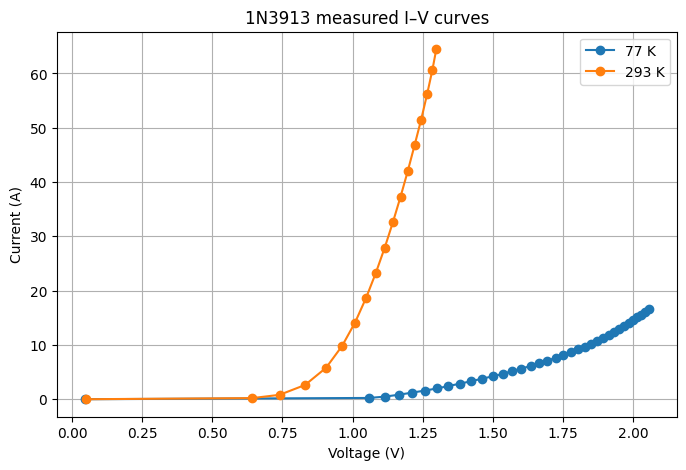

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

for temp in [77, 293]:
    subset = silicon[silicon["temperature_K"] == temp].sort_values("voltage_V")
    ax.plot(
        subset["voltage_V"],
        subset["current_A"],
        marker="o",
        label=f"{temp} K"
    )

ax.set_xlabel("Voltage (V)")
ax.set_ylabel("Current (A)")
ax.set_title("1N3913 measured I–V curves")
ax.legend()
ax.grid(True)
plt.show()

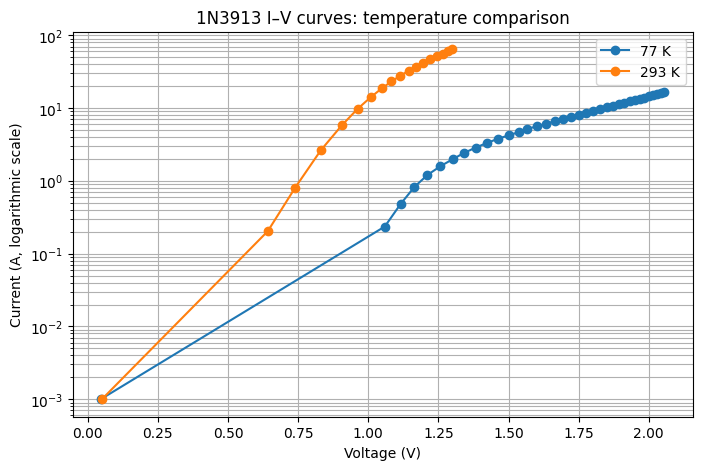

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

for temp in [77, 293]:
    subset = silicon[
        (silicon["temperature_K"] == temp) &
        (silicon["current_A"] > 0)
    ].sort_values("voltage_V")

    ax.plot(
        subset["voltage_V"],
        subset["current_A"],
        marker="o",
        label=f"{temp} K"
    )

ax.set_yscale("log")
ax.set_xlabel("Voltage (V)")
ax.set_ylabel("Current (A, logarithmic scale)")
ax.set_title("1N3913 I–V curves: temperature comparison")
ax.legend()
ax.grid(True, which="both")
plt.show()

In [ ]:
for temp in [77, 293]:
    subset = silicon[silicon["temperature_K"] == temp]
    print(
        f"{temp} K: "
        f"{subset['voltage_V'].min():.4f}–"
        f"{subset['voltage_V'].max():.4f} V"
    )

77 K: 0.0462–2.0558 V
293 K: 0.0504–1.2984 V


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import numpy as np

X = silicon[["voltage_V", "temperature_K"]]
y = silicon["current_A"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

model = clone(silicon_temp_model)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Held-out voltage-point validation")
print("Test rows:", len(y_test))
print("MAE (A):", round(mean_absolute_error(y_test, pred), 4))
print("RMSE (A):", round(np.sqrt(mean_squared_error(y_test, pred)), 4))
print("R²:", round(r2_score(y_test, pred), 4))

for temp in [77, 293]:
    mask = X_test["temperature_K"] == temp
    if mask.any():
        print(
            f"{temp} K test MAE (A):",
            round(mean_absolute_error(y_test[mask], pred[mask]), 4)
        )

Held-out voltage-point validation
Test rows: 14
MAE (A): 1.3979
RMSE (A): 2.8298
R²: 0.9759
77 K test MAE (A): 0.466
293 K test MAE (A): 2.3297


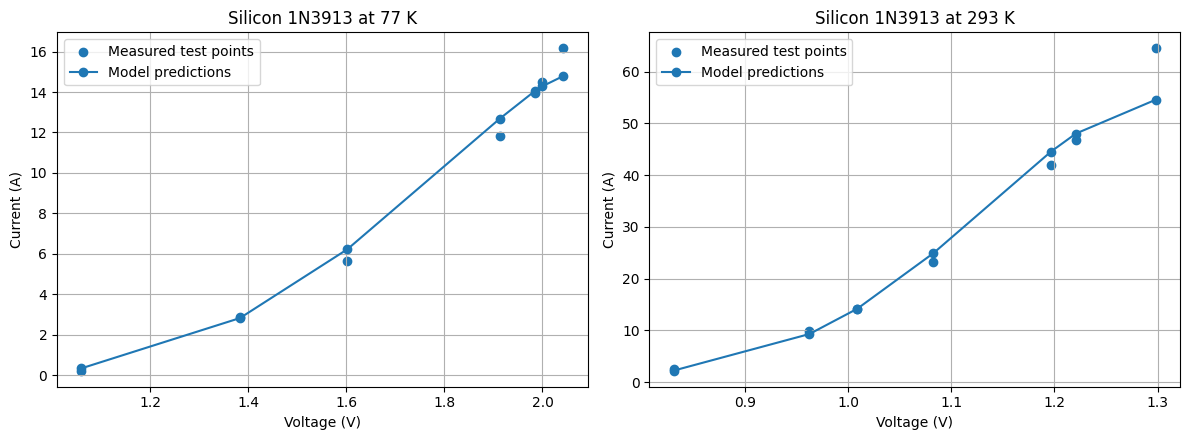

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, temp in zip(axes, [77, 293]):
    mask = X_test["temperature_K"] == temp
    x = X_test.loc[mask, "voltage_V"]
    actual = y_test.loc[mask]
    predicted = pred[mask]

    order = np.argsort(x.to_numpy())
    ax.scatter(x, actual, label="Measured test points")
    ax.plot(
        x.to_numpy()[order],
        predicted[order],
        marker="o",
        label="Model predictions"
    )
    ax.set_title(f"Silicon 1N3913 at {temp} K")
    ax.set_xlabel("Voltage (V)")
    ax.set_ylabel("Current (A)")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
results = pd.DataFrame({
    "temperature_K": X_test["temperature_K"].to_numpy(),
    "voltage_V": X_test["voltage_V"].to_numpy(),
    "actual_A": y_test.to_numpy(),
    "predicted_A": pred,
})

results["absolute_error_A"] = abs(
    results["actual_A"] - results["predicted_A"]
)

print(
    results.sort_values(["temperature_K", "voltage_V"])
    .round(4)
    .to_string(index=False)
)

 temperature_K  voltage_V  actual_A  predicted_A  absolute_error_A
            77     1.0589     0.236       0.3446            0.1086
            77     1.3828     2.866       2.8314            0.0346
            77     1.6019     5.652       6.2291            0.5771
            77     1.9131    11.804      12.6856            0.8816
            77     1.9839    13.965      14.0381            0.0731
            77     1.9996    14.509      14.2809            0.2281
            77     2.0428    16.152      14.7928            1.3592
           293     0.8306     2.629       2.2306            0.3984
           293     0.9623     9.793       9.2964            0.4966
           293     1.0087    14.124      14.1714            0.0474
           293     1.0826    23.227      24.9118            1.6848
           293     1.1967    42.013      44.5380            2.5250
           293     1.2209    46.761      48.0242            1.2632
           293     1.2984    64.457      54.5646            9.

In [ ]:
sic = df[
    (df["material"] == "silicon carbide") &
    (df["device"] == "STPSC12065DY") &
    (df["current_A"] > 0)
].dropna(subset=["voltage_V", "temperature_K", "current_A"])

X_sic = sic[["voltage_V", "temperature_K"]]
y_sic = sic["current_A"]

sic_temp_model = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=10, epsilon=0.05)
    ),
    func=np.log10,
    inverse_func=inverse_log_transform
)

sic_temp_model.fit(X_sic, y_sic)

print("Temperature-aware SiC model trained.")
print("Input features:", X_sic.columns.tolist())
print("Training rows:", len(X_sic))
print("Temperatures:", sorted(sic["temperature_K"].unique()))

Temperature-aware SiC model trained.
Input features: ['voltage_V', 'temperature_K']
Training rows: 57
Temperatures: [np.int64(77), np.int64(293)]


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X_sic, y_sic,
    test_size=0.25,
    random_state=42
)

sic_test_model = clone(sic_temp_model)
sic_test_model.fit(X_train, y_train)
pred_sic = sic_test_model.predict(X_test)

print("SiC held-out voltage-point validation")
print("Test rows:", len(y_test))
print("MAE (A):", round(mean_absolute_error(y_test, pred_sic), 4))
print("RMSE (A):", round(np.sqrt(mean_squared_error(y_test, pred_sic)), 4))
print("R²:", round(r2_score(y_test, pred_sic), 4))

for temp in [77, 293]:
    mask = X_test["temperature_K"] == temp
    if mask.any():
        print(
            f"{temp} K test MAE (A):",
            round(mean_absolute_error(y_test[mask], pred_sic[mask]), 4)
        )

SiC held-out voltage-point validation
Test rows: 15
MAE (A): 0.4408
RMSE (A): 0.5814
R²: 0.984
77 K test MAE (A): 0.4434
293 K test MAE (A): 0.4369


In [ ]:
for train_temp, test_temp in [(77, 293), (293, 77)]:
    train = sic[sic["temperature_K"] == train_temp]
    test = sic[sic["temperature_K"] == test_temp]

    model = TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            SVR(kernel="rbf", C=10, epsilon=0.05)
        ),
        func=np.log10,
        inverse_func=inverse_log_transform
    )

    model.fit(
        train[["voltage_V", "temperature_K"]],
        train["current_A"]
    )

    pred = model.predict(test[["voltage_V", "temperature_K"]])

    print(f"\nTrain {train_temp} K → Test {test_temp} K")
    print("MAE (A):", round(mean_absolute_error(test["current_A"], pred), 4))
    print("RMSE (A):", round(np.sqrt(mean_squared_error(test["current_A"], pred)), 4))
    print("R²:", round(r2_score(test["current_A"], pred), 4))


Train 77 K → Test 293 K
MAE (A): 7.3958
RMSE (A): 9.0166
R²: -2.0283

Train 293 K → Test 77 K
MAE (A): 7.4743
RMSE (A): 8.9853
R²: -2.2294


In [ ]:
gan = df[
    (df["material"] == "gallium nitride") &
    (df["current_A"] > 0)
].dropna(subset=["voltage_V", "temperature_K", "current_A"])

X_gan = gan[["voltage_V", "temperature_K"]]
y_gan = gan["current_A"]

gan_temp_model = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=10, epsilon=0.05)
    ),
    func=np.log10,
    inverse_func=inverse_log_transform
)

gan_temp_model.fit(X_gan, y_gan)

print("Temperature-aware GaN model trained.")
print("Training rows:", len(gan))
print("Temperatures:", sorted(gan["temperature_K"].unique()))
print("Voltage range:", gan["voltage_V"].min(), "to", gan["voltage_V"].max())

Temperature-aware GaN model trained.
Training rows: 5189
Temperatures: [np.int64(40), np.int64(60), np.int64(80), np.int64(100), np.int64(120), np.int64(140), np.int64(160), np.int64(180), np.int64(200), np.int64(220), np.int64(240), np.int64(260), np.int64(280), np.int64(300), np.int64(320), np.int64(340), np.int64(360), np.int64(380), np.int64(400)]
Voltage range: -2.019998 to 1.0


In [ ]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

results = []

for temp in sorted(gan["temperature_K"].unique()):
    train = gan[gan["temperature_K"] != temp]
    test = gan[gan["temperature_K"] == temp]

    model = clone(gan_temp_model)
    model.fit(
        train[["voltage_V", "temperature_K"]],
        train["current_A"]
    )

    pred = model.predict(test[["voltage_V", "temperature_K"]])

    results.append({
        "temperature_K": int(temp),
        "test_rows": len(test),
        "MAE_A": mean_absolute_error(test["current_A"], pred),
        "RMSE_A": np.sqrt(mean_squared_error(test["current_A"], pred)),
        "R2": r2_score(test["current_A"], pred)
    })

validation_results = pd.DataFrame(results)

print(validation_results.round(8).to_string(index=False))
print("\nMean MAE (A):", validation_results["MAE_A"].mean())
print("Mean RMSE (A):", validation_results["RMSE_A"].mean())
print("Mean R²:", validation_results["R2"].mean())

 temperature_K  test_rows    MAE_A   RMSE_A       R2
            40        302 0.000009 0.000023 0.936587
            60        302 0.000011 0.000030 0.892549
            80        302 0.000014 0.000037 0.887336
           100        302 0.000020 0.000052 0.854721
           120        302 0.000029 0.000072 0.820168
           140        302 0.000040 0.000096 0.821481
           160        302 0.000052 0.000123 0.825291
           180        152 0.000055 0.000127 0.891534
           200        152 0.000063 0.000137 0.913225
           220        302 0.000068 0.000154 0.916371
           240        297 0.000053 0.000118 0.957397
           260        292 0.000043 0.000088 0.976215
           280        287 0.000043 0.000072 0.983164
           300        282 0.000039 0.000061 0.987006
           320        278 0.000046 0.000067 0.980733
           340        274 0.000065 0.000086 0.960325
           360        272 0.000092 0.000111 0.934524
           380        270 0.000142 0.000172 0.

In [ ]:
from sklearn.base import clone
import numpy as np
import pandas as pd

relative_results = []

for temp in sorted(gan["temperature_K"].unique()):
    train = gan[gan["temperature_K"] != temp]
    test = gan[gan["temperature_K"] == temp]

    model = clone(gan_temp_model)
    model.fit(
        train[["voltage_V", "temperature_K"]],
        train["current_A"]
    )

    pred = model.predict(test[["voltage_V", "temperature_K"]])
    actual = test["current_A"].to_numpy()

    # Avoid unstable percentage errors when actual current is near zero.
    threshold = np.quantile(actual, 0.10)
    mask = actual > threshold

    relative_results.append({
        "temperature_K": int(temp),
        "MAE_A": np.mean(np.abs(actual - pred)),
        "MAPE_above_10th_percentile_pct": (
            np.mean(np.abs(actual[mask] - pred[mask]) / actual[mask]) * 100
            if mask.any() else np.nan
        )
    })

relative_df = pd.DataFrame(relative_results)
print(relative_df.round(4).to_string(index=False))
print(
    "\nMean percentage error across temperatures:",
    round(relative_df["MAPE_above_10th_percentile_pct"].mean(), 2),
    "%"
)

 temperature_K  MAE_A  MAPE_above_10th_percentile_pct
            40 0.0000                         36.4609
            60 0.0000                         50.6756
            80 0.0000                         44.8724
           100 0.0000                         36.6053
           120 0.0000                         31.7964
           140 0.0000                         28.3706
           160 0.0001                         35.5684
           180 0.0001                         43.6174
           200 0.0001                         47.9256
           220 0.0001                         21.4934
           240 0.0001                         15.7652
           260 0.0000                         11.3621
           280 0.0000                         19.7656
           300 0.0000                         10.0093
           320 0.0000                          7.9173
           340 0.0001                          8.1905
           360 0.0001                          8.5668
           380 0.0001       

In [ ]:
from sklearn.base import clone
import numpy as np
import pandas as pd

for temp in [40, 220, 400]:
    train = gan[gan["temperature_K"] != temp]
    test = gan[gan["temperature_K"] == temp].copy()

    model = clone(gan_temp_model)
    model.fit(
        train[["voltage_V", "temperature_K"]],
        train["current_A"]
    )

    test["predicted_current_A"] = model.predict(
        test[["voltage_V", "temperature_K"]]
    )
    test["absolute_error_A"] = np.abs(
        test["current_A"] - test["predicted_current_A"]
    )

    print(f"\n--- {temp} K ---")
    print(
        test[["voltage_V", "current_A",
              "predicted_current_A", "absolute_error_A"]]
        .sort_values("absolute_error_A", ascending=False)
        .head(5)
        .to_string(index=False, float_format=lambda x: f"{x:.8g}")
    )


--- 40 K ---
 voltage_V   current_A  predicted_current_A  absolute_error_A
         1  0.00041062        0.00028552457     0.00012509543
      0.99  0.00040093        0.00029466427     0.00010626573
      0.98  0.00039239        0.00030308278     8.9307215e-05
 0.6100004 0.000126033        4.4842934e-05     8.1190066e-05
 0.6000004 0.000119248         3.926008e-05      7.998792e-05

--- 220 K ---
 voltage_V  current_A  predicted_current_A  absolute_error_A
         1 0.00200561         0.0013154635     0.00069014652
      0.99 0.00197955         0.0013208385     0.00065871154
      0.98 0.00195349         0.0013282911     0.00062519894
      0.97 0.00192748         0.0013376729     0.00058980714
      0.96 0.00190161         0.0013488373     0.00055277275

--- 400 K ---
 voltage_V  current_A  predicted_current_A  absolute_error_A
 -1.329998 0.00205729         0.0013538158     0.00070347423
 -1.339998 0.00206534         0.0013619782     0.00070336179
 -1.319998 0.00204936         0.001

In [ ]:
for temp in [220, 400]:
    train = gan[gan["temperature_K"] != temp]
    test = gan[gan["temperature_K"] == temp].copy()

    model = clone(gan_temp_model)
    model.fit(
        train[["voltage_V", "temperature_K"]],
        train["current_A"]
    )

    test["predicted_current_A"] = model.predict(
        test[["voltage_V", "temperature_K"]]
    )
    test["absolute_error_A"] = np.abs(
        test["current_A"] - test["predicted_current_A"]
    )

    print(f"\n--- {temp} K ---")
    print(
        test[["voltage_V", "current_A",
              "predicted_current_A", "absolute_error_A"]]
        .sort_values("absolute_error_A", ascending=False)
        .head(5)
        .to_string(index=False, float_format=lambda x: f"{x:.8g}")
    )


--- 220 K ---
 voltage_V  current_A  predicted_current_A  absolute_error_A
         1 0.00200561         0.0013154635     0.00069014652
      0.99 0.00197955         0.0013208385     0.00065871154
      0.98 0.00195349         0.0013282911     0.00062519894
      0.97 0.00192748         0.0013376729     0.00058980714
      0.96 0.00190161         0.0013488373     0.00055277275

--- 400 K ---
 voltage_V  current_A  predicted_current_A  absolute_error_A
 -1.329998 0.00205729         0.0013538158     0.00070347423
 -1.339998 0.00206534         0.0013619782     0.00070336179
 -1.319998 0.00204936         0.0013461817      0.0007031783
 -1.349998 0.00207336         0.0013706674     0.00070269256
 -1.309998 0.00204127         0.0013390763     0.00070219365


In [ ]:
temp = 400

train = gan[gan["temperature_K"] != temp]
test = gan[gan["temperature_K"] == temp].copy()

model = clone(gan_temp_model)
model.fit(
    train[["voltage_V", "temperature_K"]],
    train["current_A"]
)

test["predicted_current_A"] = model.predict(
    test[["voltage_V", "temperature_K"]]
)
test["absolute_error_A"] = np.abs(
    test["current_A"] - test["predicted_current_A"]
)

print(
    test[["voltage_V", "current_A",
          "predicted_current_A", "absolute_error_A"]]
    .sort_values("absolute_error_A", ascending=False)
    .head(5)
    .to_string(index=False, float_format=lambda x: f"{x:.8g}")
)

 voltage_V  current_A  predicted_current_A  absolute_error_A
 -1.329998 0.00205729         0.0013538158     0.00070347423
 -1.339998 0.00206534         0.0013619782     0.00070336179
 -1.319998 0.00204936         0.0013461817      0.0007031783
 -1.349998 0.00207336         0.0013706674     0.00070269256
 -1.309998 0.00204127         0.0013390763     0.00070219365


In [ ]:
gan_summary = (
    gan.groupby("temperature_K")
    .agg(
        rows=("current_A", "size"),
        min_voltage_V=("voltage_V", "min"),
        max_voltage_V=("voltage_V", "max"),
        min_current_A=("current_A", "min"),
        max_current_A=("current_A", "max")
    )
    .reset_index()
)

print(gan_summary.to_string(
    index=False,
    float_format=lambda x: f"{x:.7g}"
))

 temperature_K  rows  min_voltage_V  max_voltage_V  min_current_A  max_current_A
            40   302      -2.009998              1      5.795e-11     0.00041062
            60   302      -2.009998              1      6.212e-11     0.00040595
            80   302      -2.009998              1      3.707e-11     0.00047389
           100   302      -2.009998              1      2.048e-11     0.00056818
           120   302      -2.009998              1     3.3898e-10     0.00068768
           140   302      -2.009998              1       1.63e-11      0.0008881
           160   302      -2.009998              1     3.2724e-09     0.00113845
           180   152      -2.019998              1      4.602e-11      0.0014738
           200   152      -2.019998              1     2.2456e-10     0.00176589
           220   302      -2.009998              1      3.341e-11     0.00200561
           240   297      -2.009998           0.95     7.5469e-10     0.00217205
           260   292      -2

In [ ]:
common_min_voltage = gan.groupby("temperature_K")["voltage_V"].min().max()
common_max_voltage = gan.groupby("temperature_K")["voltage_V"].max().min()

print(f"Shared voltage range: {common_min_voltage:.6f} V to {common_max_voltage:.6f} V")

for temp in [40, 220, 400]:
    subset = gan[gan["temperature_K"] == temp]
    common = subset[
        subset["voltage_V"].between(
            common_min_voltage, common_max_voltage
        )
    ]
    print(
        f"{temp} K: {len(common)} measured rows in shared range"
    )

Shared voltage range: -1.499998 V to 0.660000 V
40 K: 217 measured rows in shared range
220 K: 217 measured rows in shared range
400 K: 217 measured rows in shared range


In [ ]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np
import pandas as pd

vmin = -1.499998
vmax = 0.660000

gan_shared = gan[gan["voltage_V"].between(vmin, vmax)].copy()
results_shared = []

for temp in sorted(gan_shared["temperature_K"].unique()):
    train = gan_shared[gan_shared["temperature_K"] != temp]
    test = gan_shared[gan_shared["temperature_K"] == temp]

    model = clone(gan_temp_model)
    model.fit(
        train[["voltage_V", "temperature_K"]],
        train["current_A"]
    )

    pred = model.predict(test[["voltage_V", "temperature_K"]])
    actual = test["current_A"].to_numpy()

    results_shared.append({
        "temperature_K": int(temp),
        "test_rows": len(test),
        "MAE_A": mean_absolute_error(actual, pred),
        "R2": r2_score(actual, pred)
    })

shared_results_df = pd.DataFrame(results_shared)
print(shared_results_df.round(8).to_string(index=False))
print("\nMean MAE (A):", shared_results_df["MAE_A"].mean())
print("Mean R²:", shared_results_df["R2"].mean())

 temperature_K  test_rows    MAE_A       R2
            40        216 0.000003 0.891215
            60        216 0.000002 0.920359
            80        216 0.000002 0.974318
           100        216 0.000004 0.945740
           120        216 0.000008 0.897317
           140        216 0.000015 0.853596
           160        216 0.000024 0.786337
           180        107 0.000032 0.771914
           200        107 0.000042 0.784095
           220        216 0.000045 0.826151
           240        216 0.000046 0.872772
           260        216 0.000042 0.922300
           280        216 0.000045 0.951632
           300        216 0.000042 0.969828
           320        216 0.000047 0.974106
           340        216 0.000057 0.965636
           360        216 0.000072 0.953378
           380        216 0.000133 0.888856
           400        216 0.000319 0.617356

Mean MAE (A): 5.1551888267710215e-05
Mean R²: 0.8824688450674669


In [ ]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

baseline_results = []

for temp in sorted(gan_shared["temperature_K"].unique()):
    train = gan_shared[gan_shared["temperature_K"] != temp]
    test = gan_shared[gan_shared["temperature_K"] == temp]

    # Temperature-aware model
    aware = clone(gan_temp_model)
    aware.fit(train[["voltage_V", "temperature_K"]], train["current_A"])
    pred_aware = aware.predict(test[["voltage_V", "temperature_K"]])

    # Baseline: same SVR approach, but voltage is the only input
    baseline = TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            SVR(kernel="rbf", C=10, epsilon=0.05)
        ),
        func=np.log10,
        inverse_func=inverse_log_transform
    )
    baseline.fit(train[["voltage_V"]], train["current_A"])
    pred_baseline = baseline.predict(test[["voltage_V"]])

    actual = test["current_A"].to_numpy()

    baseline_results.append({
        "temperature_K": int(temp),
        "MAE_temperature_aware_A": mean_absolute_error(actual, pred_aware),
        "MAE_voltage_only_A": mean_absolute_error(actual, pred_baseline)
    })

baseline_df = pd.DataFrame(baseline_results)
print(baseline_df.round(8).to_string(index=False))
print("\nMean temperature-aware MAE:",
      baseline_df["MAE_temperature_aware_A"].mean())
print("Mean voltage-only MAE:",
      baseline_df["MAE_voltage_only_A"].mean())

 temperature_K  MAE_temperature_aware_A  MAE_voltage_only_A
            40                 0.000003            0.000156
            60                 0.000002            0.000156
            80                 0.000002            0.000152
           100                 0.000004            0.000147
           120                 0.000008            0.000137
           140                 0.000015            0.000122
           160                 0.000024            0.000104
           180                 0.000032            0.000076
           200                 0.000042            0.000049
           220                 0.000045            0.000027
           240                 0.000046            0.000032
           260                 0.000042            0.000077
           280                 0.000045            0.000117
           300                 0.000042            0.000205
           320                 0.000047            0.000316
           340                 0.000057 

In [ ]:
from pathlib import Path
import joblib

gan_model_path = SAVE_DIR / "gan_temperature_aware_svr.joblib"

joblib.dump(gan_temp_model, gan_model_path)

print("Saved model to:", gan_model_path)
print("File exists:", gan_model_path.exists())
print("File size (KB):", round(gan_model_path.stat().st_size / 1024, 2))

Saved model to: /content/diode_project/diode-iv-predictor-Copy-main/trained_models/gan_temperature_aware_svr.joblib
File exists: True
File size (KB): 101.4


In [ ]:
import joblib
import numpy as np
import pandas as pd

loaded_gan_model = joblib.load(gan_model_path)

test_input = pd.DataFrame({
    "voltage_V": [0.5],
    "temperature_K": [300]
})

prediction = loaded_gan_model.predict(test_input)[0]

print("Test input: 0.5 V at 300 K")
print("Predicted current (A):", prediction)
print("Prediction is finite and positive:",
      bool(np.isfinite(prediction) and prediction > 0))

Test input: 0.5 V at 300 K
Predicted current (A): 0.00139068077413304
Prediction is finite and positive: True


In [ ]:
app_text = app_path.read_text()

for i, line in enumerate(app_text.splitlines(), start=1):
    if any(term in line.lower() for term in [
        "load_models", "device_options", "model_name",
        "temperature_k", "predict("
    ]):
        print(f"{i}: {line}")

53: def load_models():
103:         "temperature_K",
110:         subset=["device", "voltage_V", "current_A", "temperature_K"]
116: models, model_errors = load_models()
172:                 ys = np.asarray(model.predict(xs)).reshape(-1)
251:         model_name = st.selectbox("Choose a model", list(models.keys()))
265:         if model_name == "Silicon 1N3913 (293 K) Log-SVR":
266:             device_options = ["1N3913"]
267:         elif model_name == "SiC STPSC12065DY (293 K) Random Forest":
268:             device_options = ["STPSC12065DY"]
269:         elif model_name == "Silicon SVR":
270:             device_options = [
281:         elif model_name == "SiC SVR":
282:             device_options = [
289:             device_options = [
296:         device = st.selectbox("Device", device_options)
307:         if model_name in ["Silicon SVR", "SiC SVR"]:
325:                 if model_name in ["Silicon SVR", "SiC SVR"]:
331:                             & (training_data["temperature_K"] =

In [ ]:
lines = app_path.read_text().splitlines()

for start, end in [(45, 125), (240, 405)]:
    print(f"\n{'=' * 20} Lines {start}-{end} {'=' * 20}")
    for i in range(start, min(end, len(lines)) + 1):
        print(f"{i}: {lines[i - 1]}")


==================== Lines 45-125 ====================
45: @keyframes rise { from {opacity:0; transform:translateY(12px)} to {opacity:1; transform:translateY(0)} }
46: hr { border-color:#203b5d; }
47: </style>
48: """, unsafe_allow_html=True)
49: 
50: # ---------- Load project assets ----------
51: 
52: @st.cache_resource
53: def load_models():
54:     loaded = {}
55:     errors = []
56: 
57:     for label, filename in [
58:         ("Random Forest", "random_forest_model.joblib"),
59:         ("Tuned SVR", "tuned_svr_model.joblib"),
60:         ("Silicon SVR", "trained_models/silicon_svr.joblib"),
61:         ("SiC SVR", "trained_models/silicon_carbide_svr.joblib"),
62:         ("Silicon 1N3913 (293 K) Log-SVR", "trained_models/silicon_1N3913_293K_log_svr.joblib"),
63:         ("SiC STPSC12065DY (293 K) Random Forest", "trained_models/sic_STPSC12065DY_293K_rf_selected.joblib"),
64:     ]:
65:         if os.path.exists(filename):
66:             try:
67:                 loaded[label] =

In [ ]:
app_text = app_path.read_text()

old = '''        ("SiC STPSC12065DY (293 K) Random Forest", "trained_models/sic_STPSC12065DY_293K_rf_selected.joblib"),
    ]:'''

new = '''        ("SiC STPSC12065DY (293 K) Random Forest", "trained_models/sic_STPSC12065DY_293K_rf_selected.joblib"),
        ("GaN Temperature-Aware SVR", "trained_models/gan_temperature_aware_svr.joblib"),
    ]:'''

if old not in app_text:
    print("STOP: Could not find the exact model-loader text. No changes made.")
else:
    app_path.write_text(app_text.replace(old, new, 1))
    print("Added GaN model to app.py")

Added GaN model to app.py


In [ ]:
app_text = app_path.read_text()

old = '''        if model_name == "Silicon 1N3913 (293 K) Log-SVR":
            device_options = ["1N3913"]'''

new = '''        if model_name == "GaN Temperature-Aware SVR":
            device_options = ["Au/Ni/n-GaN Schottky diode"]
        elif model_name == "Silicon 1N3913 (293 K) Log-SVR":
            device_options = ["1N3913"]'''

if old not in app_text:
    print("STOP: Could not find the expected device-selection code. No changes made.")
else:
    app_path.write_text(app_text.replace(old, new, 1))
    print("Added the GaN device option.")

Added the GaN device option.


In [ ]:
app_text = app_path.read_text()

old = '''        safe_min = max(0.0, vmin)
        voltage = st.number_input(
            "Measured voltage (V)",
            min_value=-0.1,
            max_value=max(1.5, vmax + 0.5),
            value=float(min(max(0.70, safe_min), vmax)),
            step=0.005,
            format="%.5f",
        )'''

new = '''        if model_name == "GaN Temperature-Aware SVR":
            voltage_min, voltage_max = -1.499998, 0.660000
            voltage_default = 0.5
        else:
            voltage_min = -0.1
            voltage_max = max(1.5, vmax + 0.5)
            safe_min = max(0.0, vmin)
            voltage_default = float(min(max(0.70, safe_min), vmax))

        voltage = st.number_input(
            "Measured voltage (V)",
            min_value=voltage_min,
            max_value=voltage_max,
            value=voltage_default,
            step=0.005,
            format="%.5f",
        )'''

if old not in app_text:
    print("STOP: Expected voltage-input code not found. No changes made.")
else:
    app_path.write_text(app_text.replace(old, new, 1))
    print("Added model-specific voltage limits.")

Added model-specific voltage limits.


In [ ]:
app_text = app_path.read_text()

old = '''                if model_name in ["Silicon SVR", "SiC SVR"]:
                    if training_data.empty:'''

new = '''                if model_name == "GaN Temperature-Aware SVR":
                    if not 40.0 <= temperature <= 400.0:
                        st.error("GaN model supports temperatures from 40 K to 400 K.")
                    elif not -1.499998 <= voltage <= 0.660000:
                        st.error("GaN voltage must be within -1.499998 V to 0.660000 V.")
                    else:
                        model_input = pd.DataFrame([{
                            "voltage_V": voltage,
                            "temperature_K": temperature,
                        }])
                        current = float(
                            np.asarray(
                                models[model_name].predict(model_input)
                            ).reshape(-1)[0]
                        )

                        if not np.isfinite(current) or current <= 0:
                            st.error("GaN model returned an invalid current.")
                        else:
                            st.session_state.last_prediction = {
                                "model": model_name,
                                "device": device,
                                "voltage": voltage,
                                "temperature": temperature,
                                "current": current,
                            }

                elif model_name in ["Silicon SVR", "SiC SVR"]:
                    if training_data.empty:'''

if old not in app_text:
    print("STOP: Expected prediction branch not found. No changes made.")
else:
    app_path.write_text(app_text.replace(old, new, 1))
    print("Added dedicated GaN prediction logic.")

Added dedicated GaN prediction logic.


In [ ]:
import ast

try:
    ast.parse(app_path.read_text())
    print("✅ app.py syntax is valid.")
except SyntaxError as exc:
    print(f"❌ Syntax error on line {exc.lineno}: {exc.msg}")

✅ app.py syntax is valid.


In [ ]:
import joblib
import ast

app_text = app_path.read_text()
ast.parse(app_text)

print("GaN model file exists:", gan_model_path.exists())
print("Existing model files preserved:")
for filename in [
    "trained_models/silicon_svr.joblib",
    "trained_models/silicon_carbide_svr.joblib",
]:
    print(f"  {filename}: {(PROJECT / filename).exists()}")

GaN model file exists: True
Existing model files preserved:
  trained_models/silicon_svr.joblib: True
  trained_models/silicon_carbide_svr.joblib: True


In [ ]:
import ast

app_text = app_path.read_text()
ast.parse(app_text)

checks = {
    "GaN option added": "GaN Temperature-Aware SVR" in app_text,
    "Voltage passed to model": '"voltage_V": voltage' in app_text,
    "Temperature passed to model": '"temperature_K": temperature' in app_text,
    "GaN prediction branch exists": 'model_name == "GaN Temperature-Aware SVR"' in app_text,
    "Original Silicon model preserved": (PROJECT / "trained_models/silicon_svr.joblib").exists(),
    "Original SiC model preserved": (PROJECT / "trained_models/silicon_carbide_svr.joblib").exists(),
}

for name, passed in checks.items():
    print(f"{'✅' if passed else '❌'} {name}: {passed}")

✅ GaN option added: True
✅ Voltage passed to model: True
✅ Temperature passed to model: True
✅ GaN prediction branch exists: True
✅ Original Silicon model preserved: True
✅ Original SiC model preserved: True


In [ ]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "streamlit", "run", str(app_path),
     "--server.headless", "true", "--server.port", "8501"],
    cwd=str(PROJECT),
    capture_output=True,
    text=True,
    timeout=20
)

print("Return code:", result.returncode)
print("Output:")
print(result.stdout[-3000:])
print("Errors:")
print(result.stderr[-3000:])

Return code: 1
Output:

Errors:
/usr/bin/python3: No module named streamlit



In [ ]:
import subprocess

def git(*args):
    result = subprocess.run(
        ["git", *args],
        cwd=str(PROJECT),
        capture_output=True,
        text=True
    )
    print(result.stdout or result.stderr)

git("status", "--short")

fatal: not a git repository (or any of the parent directories): .git



In [ ]:
from pathlib import Path

print("Project folder:", PROJECT)
print("Project exists:", PROJECT.exists())
print("Git metadata exists:", (PROJECT / ".git").exists())
print("\nProject contents:")
for item in sorted(PROJECT.iterdir()):
    print(item.name)

Project folder: /content/diode_project/diode-iv-predictor-Copy-main
Project exists: True
Git metadata exists: False

Project contents:
.devcontainer
README.md
app.py
app.py.backup_before_new_models
data
diode_iv_data.csv
diode_physics.py
prepare_external_data.py
random_forest_model.joblib
requirements.txt
runtime.txt
test_diode_physics.py
trained_models
tuned_svr_model.joblib


In [ ]:
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/SainathGangasagare/diode-iv-predictor-Copy.git"
CLONE_DIR = Path("/content/diode_project/github-copy")

result = subprocess.run(
    ["git", "clone", "--branch", "main", REPO_URL, str(CLONE_DIR)],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)
print("Clone successful:", (CLONE_DIR / ".git").exists())


Cloning into '/content/diode_project/github-copy'...

Clone successful: True


In [ ]:
import shutil

source_app = PROJECT / "app.py"
source_model = PROJECT / "trained_models" / "gan_temperature_aware_svr.joblib"

target_app = CLONE_DIR / "app.py"
target_model = CLONE_DIR / "trained_models" / "gan_temperature_aware_svr.joblib"

assert source_app.exists(), "Updated app.py is missing"
assert source_model.exists(), "GaN model file is missing"
assert target_model.parent.exists(), "GitHub trained_models folder is missing"

shutil.copy2(source_app, target_app)
shutil.copy2(source_model, target_model)

print("app.py copied:", source_app.read_bytes() == target_app.read_bytes())
print("GaN model copied:", source_model.read_bytes() == target_model.read_bytes())

app.py copied: True
GaN model copied: True


In [ ]:
import subprocess

result = subprocess.run(
    ["git", "status", "--short"],
    cwd=str(CLONE_DIR),
    capture_output=True,
    text=True
)

print(result.stdout)

 M app.py
?? trained_models/gan_temperature_aware_svr.joblib



In [ ]:
import subprocess

def run_git(args):
    result = subprocess.run(
        ["git", *args],
        cwd=str(CLONE_DIR),
        capture_output=True,
        text=True
    )
    print(result.stdout or result.stderr)
    if result.returncode != 0:
        raise RuntimeError("Git command failed.")

run_git([
    "add",
    "app.py",
    "trained_models/gan_temperature_aware_svr.joblib"
])

run_git([
    "commit",
    "-m",
    "Add temperature-aware GaN predictor"
])


Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@1f4693bff7c1.(none)')



RuntimeError: Git command failed.

In [ ]:
import subprocess

subprocess.run(
    ["git", "config", "user.name", "YOUR NAME"],
    cwd=str(CLONE_DIR),
    check=True
)

subprocess.run(
    ["git", "config", "user.email", "YOUR EMAIL"],
    cwd=str(CLONE_DIR),
    check=True
)

print("Git identity configured for this repository.")

Git identity configured for this repository.


In [ ]:
subprocess.run(
    ["git", "commit", "-m", "Add temperature-aware GaN predictor"],
    cwd=str(CLONE_DIR),
    check=True
)

CompletedProcess(args=['git', 'commit', '-m', 'Add temperature-aware GaN predictor'], returncode=0)

In [ ]:
import subprocess

result = subprocess.run(
    ["git", "push", "origin", "main"],
    cwd=str(CLONE_DIR),
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

if result.returncode == 0:
    print("✅ Successfully pushed to GitHub!")
else:
    print("⚠️ Push failed. Send me the error output.")


fatal: could not read Username for 'https://github.com': No such device or address

⚠️ Push failed. Send me the error output.


In [ ]:
from google.colab import files

files.download(str(PROJECT / "app.py"))
files.download(str(PROJECT / "trained_models" / "gan_temperature_aware_svr.joblib"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import glob

print("========== CURRENT COLAB STATE ==========")
print("Working directory:", os.getcwd())

print("\n========== DATASETS ==========")
for f in glob.glob("/content/**/*.csv", recursive=True):
    print(f)

print("\n========== TRAINED MODEL FILES ==========")
model_extensions = ["*.joblib", "*.pkl", "*.pickle"]
for ext in model_extensions:
    for f in glob.glob("/content/**/" + ext, recursive=True):
        print(f)

print("\n========== NOTEBOOK VARIABLES ==========")
important_vars = [
    "data", "df", "models", "X_train", "X_test",
    "y_train", "y_test", "classified_data"
]
for name in important_vars:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}",
              getattr(obj, "shape", ""))
    else:
        print(f"{name}: not currently defined")

========== CURRENT COLAB STATE ==========
Working directory: /content

========== DATASETS ==========
/content/sample_data/california_housing_test.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv
/content/sample_data/mnist_train_small.csv

========== TRAINED MODEL FILES ==========

========== NOTEBOOK VARIABLES ==========
data: not currently defined
df: not currently defined
models: not currently defined
X_train: not currently defined
X_test: not currently defined
y_train: not currently defined
y_test: not currently defined
classified_data: not currently defined


In [ ]:
import os
import zipfile
import urllib.request

# Your existing repository
repo_url = "https://github.com/sainathgangasagare/diode-iv-predictor-copy/archive/refs/heads/main.zip"
zip_path = "/content/diode_project.zip"
extract_path = "/content/diode_project"

print("Downloading existing repository...")

urllib.request.urlretrieve(repo_url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("\nRepository extracted successfully.")

for root, dirs, files in os.walk(extract_path):
    # Avoid printing unnecessary Git metadata
    dirs[:] = [d for d in dirs if d != ".git"]
    for file in files:
        if file.endswith((".csv", ".joblib", ".pkl", ".pickle")):
            print(os.path.relpath(os.path.join(root, file), extract_path))


Repository extracted successfully.
diode-iv-predictor-Copy-main/tuned_svr_model.joblib
diode-iv-predictor-Copy-main/diode_iv_data.csv
diode-iv-predictor-Copy-main/random_forest_model.joblib
diode-iv-predictor-Copy-main/trained_models/silicon_svr.joblib
diode-iv-predictor-Copy-main/trained_models/silicon_carbide_svr.joblib
diode-iv-predictor-Copy-main/trained_models/gan_temperature_aware_svr.joblib
diode-iv-predictor-Copy-main/data/external/1n4004_reverse_10uA_range.csv
diode-iv-predictor-Copy-main/data/external/sb560_forward.csv
diode-iv-predictor-Copy-main/data/external/1n4004_forward.csv
diode-iv-predictor-Copy-main/data/external/1n4004_reverse.csv
diode-iv-predictor-Copy-main/data/external/cryogenic_diode_measurements.csv
diode-iv-predictor-Copy-main/data/external/gan_schottky_measurements.csv
diode-iv-predictor-Copy-main/data/external/1n5229b_reverse.csv
diode-iv-predictor-Copy-main/data/external/sb560_reverse.csv
diode-iv-predictor-Copy-main/data/processed/external_iv_measurement

In [ ]:
import os
import pandas as pd

PROJECT = "/content/diode_project/diode-iv-predictor-Copy-main"

print("=" * 60)
print("DATASET SUMMARY")
print("=" * 60)

for root, dirs, files in os.walk(os.path.join(PROJECT, "data")):
    for file in files:
        if file.endswith(".csv"):
            path = os.path.join(root, file)
            try:
                df = pd.read_csv(path)
                print(f"\nFile: {os.path.relpath(path, PROJECT)}")
                print("Rows:", len(df))
                print("Columns:", list(df.columns))
            except Exception as e:
                print(f"\nCould not read {file}: {e}")

print("\n" + "=" * 60)
print("SAVED MODEL FILES")
print("=" * 60)

for root, dirs, files in os.walk(PROJECT):
    for file in files:
        if file.endswith((".joblib", ".pkl", ".pickle")):
            print(os.path.relpath(os.path.join(root, file), PROJECT))

DATASET SUMMARY

File: data/external/1n4004_reverse_10uA_range.csv
Rows: 41
Columns: ['v_set', 'v_meas', 'i_meas']

File: data/external/sb560_forward.csv
Rows: 121
Columns: ['v_set', 'v_meas', 'i_meas']

File: data/external/1n4004_forward.csv
Rows: 171
Columns: ['v_set', 'v_meas', 'i_meas']

File: data/external/1n4004_reverse.csv
Rows: 41
Columns: ['v_set', 'v_meas', 'i_meas']

File: data/external/cryogenic_diode_measurements.csv
Rows: 4201
Columns: ['device', 'technology', 'temperature_K', 'voltage_V', 'current_A', 'source_id', 'evidence_type']

File: data/external/gan_schottky_measurements.csv
Rows: 5189
Columns: ['Curve_ID', 'T_K', 'Raw_Row', 'V_V', 'I_A', 'log10_I_A', 'Bias_Region', 'Equal_T_Weight_Normalized', 'Source_File', 'device', 'material', 'temperature_K', 'voltage_V', 'current_A', 'source_id', 'evidence_type']

File: data/external/1n5229b_reverse.csv
Rows: 121
Columns: ['v_set', 'v_meas', 'i_meas']

File: data/external/sb560_reverse.csv
Rows: 41
Columns: ['v_set', 'v_meas'

In [ ]:
import os
import joblib

PROJECT = "/content/diode_project/diode-iv-predictor-Copy-main"

model_paths = [
    "tuned_svr_model.joblib",
    "random_forest_model.joblib",
    "trained_models/silicon_svr.joblib",
    "trained_models/silicon_carbide_svr.joblib",
    "trained_models/gan_temperature_aware_svr.joblib",
]

for relative_path in model_paths:
    path = os.path.join(PROJECT, relative_path)

    print("\n" + "=" * 60)
    print("Model:", relative_path)

    try:
        model = joblib.load(path)
        print("Type:", type(model).__name__)

        if hasattr(model, "n_features_in_"):
            print("Number of input features:", model.n_features_in_)

        if hasattr(model, "feature_names_in_"):
            print("Input feature names:", list(model.feature_names_in_))

        if hasattr(model, "named_steps"):
            print("Pipeline steps:", list(model.named_steps.keys()))

    except Exception as e:
        print("Could not inspect model:", repr(e))


Model: tuned_svr_model.joblib
Type: Pipeline
Number of input features: 1
Input feature names: ['v_meas']
Pipeline steps: ['standardscaler', 'svr']

Model: random_forest_model.joblib
Type: RandomForestRegressor
Number of input features: 1
Input feature names: ['v_meas']

Model: trained_models/silicon_svr.joblib
Type: Pipeline
Number of input features: 3
Input feature names: ['device', 'voltage_V', 'temperature_K']
Pipeline steps: ['columntransformer', 'svr']

Model: trained_models/silicon_carbide_svr.joblib
Type: Pipeline
Number of input features: 3
Input feature names: ['device', 'voltage_V', 'temperature_K']
Pipeline steps: ['columntransformer', 'svr']

Model: trained_models/gan_temperature_aware_svr.joblib
Could not inspect model: AttributeError("Can't get attribute 'inverse_log_transform' on <module '__main__'>")


In [ ]:
import numpy as np
import joblib
import os

PROJECT = "/content/diode_project/diode-iv-predictor-Copy-main"

# Recreate the custom function used when the model was saved.
def inverse_log_transform(x):
    return np.power(10, x)

# Make the function available to joblib's unpickling process.
import __main__
__main__.inverse_log_transform = inverse_log_transform

model_path = os.path.join(
    PROJECT,
    "trained_models",
    "gan_temperature_aware_svr.joblib"
)

try:
    gan_model = joblib.load(model_path)
    print("GaN model loaded successfully.")
    print("Model type:", type(gan_model).__name__)

    if hasattr(gan_model, "n_features_in_"):
        print("Number of input features:", gan_model.n_features_in_)

    if hasattr(gan_model, "feature_names_in_"):
        print("Input features:", list(gan_model.feature_names_in_))

    if hasattr(gan_model, "named_steps"):
        print("Pipeline steps:", list(gan_model.named_steps.keys()))

except Exception as e:
    print("Loading failed:", repr(e))

GaN model loaded successfully.
Model type: TransformedTargetRegressor
Number of input features: 2
Input features: ['voltage_V', 'temperature_K']


In [ ]:
from sklearn.compose import TransformedTargetRegressor

print("Model type:", type(gan_model).__name__)

if isinstance(gan_model, TransformedTargetRegressor):
    print("\nTarget transformation:")
    print("Function:", gan_model.func)
    print("Inverse function:", gan_model.inverse_func)

    print("\nUnderlying regressor:")
    print(gan_model.regressor_)

    print("\nUnderlying model input features:")
    if hasattr(gan_model.regressor_, "feature_names_in_"):
        print(list(gan_model.regressor_.feature_names_in_))

Model type: TransformedTargetRegressor

Target transformation:
Function: <ufunc 'log10'>
Inverse function: <function inverse_log_transform at 0x7991f09fd620>

Underlying regressor:
Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svr', SVR(C=10, epsilon=0.05))])

Underlying model input features:
['voltage_V', 'temperature_K']


In [ ]:
import pandas as pd
import numpy as np
import os

PROJECT = "/content/diode_project/diode-iv-predictor-Copy-main"
path = os.path.join(PROJECT, "data/external/gan_schottky_measurements.csv")

gan = pd.read_csv(path)

print("Dataset shape:", gan.shape)
print("\nMissing values:")
print(gan[["voltage_V", "current_A", "temperature_K"]].isna().sum())

print("\nVoltage range (V):")
print(gan["voltage_V"].min(), "to", gan["voltage_V"].max())

print("\nCurrent range (A):")
print(gan["current_A"].min(), "to", gan["current_A"].max())

print("\nNegative current rows:", (gan["current_A"] < 0).sum())
print("Zero current rows:", (gan["current_A"] == 0).sum())

print("\nDistinct temperatures (K):")
print(sorted(gan["temperature_K"].dropna().unique()))

print("\nCurrent statistics:")
print(gan["current_A"].describe())

Dataset shape: (5189, 16)

Missing values:
voltage_V        0
current_A        0
temperature_K    0
dtype: int64

Voltage range (V):
-2.019998 to 1.0

Current range (A):
1.63e-11 to 0.00219782

Negative current rows: 0
Zero current rows: 0

Distinct temperatures (K):
[np.int64(40), np.int64(60), np.int64(80), np.int64(100), np.int64(120), np.int64(140), np.int64(160), np.int64(180), np.int64(200), np.int64(220), np.int64(240), np.int64(260), np.int64(280), np.int64(300), np.int64(320), np.int64(340), np.int64(360), np.int64(380), np.int64(400)]

Current statistics:
count    5.189000e+03
mean     3.635384e-04
std      5.517639e-04
min      1.630000e-11
25%      1.309470e-06
50%      4.605900e-05
75%      5.291400e-04
max      2.197820e-03
Name: current_A, dtype: float64


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select measurements at 300 K
gan_300 = gan[gan["temperature_K"] == 300].copy()

X_test = gan_300[["voltage_V", "temperature_K"]]
y_test = gan_300["current_A"]

# Predict current using the existing saved model
y_pred = gan_model.predict(X_test)

# Evaluation metrics, in amperes
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("GaN model evaluation at 300 K")
print("-" * 40)
print("Number of measurements:", len(gan_300))
print("MAE (A):", mae)
print("RMSE (A):", rmse)
print("R²:", r2)

# Show a few actual and predicted values
comparison = pd.DataFrame({
    "Voltage (V)": X_test["voltage_V"].to_numpy(),
    "Actual current (A)": y_test.to_numpy(),
    "Predicted current (A)": y_pred
})

comparison["Absolute error (A)"] = np.abs(
    comparison["Actual current (A)"] -
    comparison["Predicted current (A)"]
)

print("\nFirst 10 predictions:")
print(comparison.head(10).to_string(index=False))

GaN model evaluation at 300 K
----------------------------------------
Number of measurements: 282
MAE (A): 3.861919242505977e-05
RMSE (A): 6.27164977295513e-05
R²: 0.9860672689200984

First 10 predictions:
 Voltage (V)  Actual current (A)  Predicted current (A)  Absolute error (A)
        0.80            0.002197               0.002020            0.000177
        0.79            0.002165               0.002024            0.000141
        0.78            0.002133               0.002027            0.000106
        0.77            0.002102               0.002029            0.000073
        0.76            0.002070               0.002030            0.000040
        0.75            0.002039               0.002029            0.000010
        0.74            0.002007               0.002027            0.000020
        0.73            0.001976               0.002023            0.000047
        0.72            0.001944               0.002017            0.000073
        0.71            0.001913 

In [ ]:
from pathlib import Path

project_dir = Path(
    "/content/diode_project/diode-iv-predictor-Copy-main"
)

keywords = [
    "gan_temperature_aware_svr",
    "TransformedTargetRegressor",
    "temperature_K",
    "log10",
]

for file in project_dir.rglob("*.py"):
    try:
        lines = file.read_text(
            encoding="utf-8",
            errors="ignore"
        ).splitlines()

        matches = [
            (i, line)
            for i, line in enumerate(lines)
            if any(word in line for word in keywords)
        ]

        if matches:
            print(f"\n--- {file.relative_to(project_dir)} ---")

            shown = set()
            for i, _ in matches:
                start = max(0, i - 3)
                end = min(len(lines), i + 5)

                for j in range(start, end):
                    if j not in shown:
                        print(f"{j + 1}: {lines[j]}")
                        shown.add(j)

    except Exception as e:
        print(f"Could not read {file.name}: {e}")


--- app.py ---
131:         "material",
132:         "voltage_V",
133:         "current_A",
134:         "temperature_K",
135:     }
136: 
137:     if not required_columns.issubset(df.columns):
138:         return pd.DataFrame()
139: 
140:     df = df.dropna(
141:         subset=["device", "voltage_V", "current_A", "temperature_K"]
142:     ).copy()
143: 
144:     return df
145: 
496: 
497:                 available_temperatures = sorted(
498:                     pd.to_numeric(
499:                         device_rows["temperature_K"], errors="coerce"
500:                     )
501:                     .dropna()
502:                     .unique()
503:                     .astype(float)
553: 
554:                 available_temperatures = sorted(
555:                     pd.to_numeric(
556:                         device_rows["temperature_K"], errors="coerce"
557:                     )
558:                     .dropna()
559:                     .unique()
560:                     .astype

In [ ]:
from pathlib import Path
import joblib

project_dir = Path(
    "/content/diode_project/diode-iv-predictor-Copy-main"
)

model_path = project_dir / "trained_models" / "gan_temperature_aware_svr.joblib"
model = joblib.load(model_path)

print("MODEL TYPE:", type(model).__name__)
print("\nMODEL ATTRIBUTES THAT MAY CONTAIN TRAINING INFORMATION:")

for attr in ["n_features_in_", "feature_names_in_", "n_samples_seen_"]:
    if hasattr(model, attr):
        print(f"{attr}: {getattr(model, attr)}")

print("\nNOTEBOOK FILES:")
notebooks = list(project_dir.rglob("*.ipynb"))

if notebooks:
    for notebook in notebooks:
        print(notebook.relative_to(project_dir))
else:
    print("No notebooks found in the project folder.")

MODEL TYPE: TransformedTargetRegressor

MODEL ATTRIBUTES THAT MAY CONTAIN TRAINING INFORMATION:
n_features_in_: 2
feature_names_in_: ['voltage_V' 'temperature_K']

NOTEBOOK FILES:
No notebooks found in the project folder.


In [ ]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the existing GaN dataset and saved model
gan_data = gan.copy()

# Keep valid rows
gan_data = gan_data.dropna(
    subset=["voltage_V", "temperature_K", "current_A"]
).copy()

# Current must be positive because this model uses a logarithmic target
gan_data = gan_data[gan_data["current_A"] > 0].copy()

# Separate 300 K measurements from all other temperatures
train_data = gan_data[gan_data["temperature_K"] != 300].copy()
test_data = gan_data[gan_data["temperature_K"] == 300].copy()

X_train = train_data[["voltage_V", "temperature_K"]]
y_train = train_data["current_A"]

X_test = test_data[["voltage_V", "temperature_K"]]
y_test = test_data["current_A"]

print("Training measurements:", len(train_data))
print("Test measurements at 300 K:", len(test_data))

# Create a fresh copy of the saved model
gan_test_model = clone(gan_model)

# Train only on temperatures other than 300 K
gan_test_model.fit(X_train, y_train)

# Predict the unseen 300 K measurements
y_pred = gan_test_model.predict(X_test)

# Evaluate predictions
print("\nEvaluation on unseen 300 K measurements")
print("----------------------------------------")
print("MAE (A):", mean_absolute_error(y_test, y_pred))
print("RMSE (A):", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:", r2_score(y_test, y_pred))

comparison = pd.DataFrame({
    "Voltage (V)": X_test["voltage_V"].to_numpy(),
    "Actual current (A)": y_test.to_numpy(),
    "Predicted current (A)": y_pred
})

comparison["Absolute error (A)"] = np.abs(
    comparison["Actual current (A)"] -
    comparison["Predicted current (A)"]
)

print("\nFirst 10 predictions:")
print(comparison.head(10).to_string(index=False))

Training measurements: 4907
Test measurements at 300 K: 282

Evaluation on unseen 300 K measurements
----------------------------------------
MAE (A): 3.911148992545982e-05
RMSE (A): 6.0566365367899925e-05
R²: 0.987006214812008

First 10 predictions:
 Voltage (V)  Actual current (A)  Predicted current (A)  Absolute error (A)
        0.80            0.002197               0.002055            0.000142
        0.79            0.002165               0.002055            0.000110
        0.78            0.002133               0.002055            0.000079
        0.77            0.002102               0.002053            0.000049
        0.76            0.002070               0.002050            0.000020
        0.75            0.002039               0.002046            0.000007
        0.74            0.002007               0.002040            0.000033
        0.73            0.001976               0.002033            0.000057
        0.72            0.001944               0.002024          

In [ ]:
from pathlib import Path
import pandas as pd

project_dir = Path(
    "/content/diode_project/diode-iv-predictor-Copy-main"
)

data_dir = project_dir / "data"

print("AVAILABLE DATASETS")
print("=" * 60)

for folder in ["external", "processed"]:
    folder_path = data_dir / folder

    if not folder_path.exists():
        continue

    for file in sorted(folder_path.glob("*.csv")):
        try:
            df = pd.read_csv(file)
            print(f"\nFile: {file.relative_to(project_dir)}")
            print("Rows:", len(df))
            print("Columns:", list(df.columns))
        except Exception as e:
            print(f"\nCould not read {file.name}: {e}")

print("\nSAVED MODEL FILES")
print("=" * 60)

for file in sorted(project_dir.rglob("*.joblib")):
    print(file.relative_to(project_dir))

AVAILABLE DATASETS

File: data/external/1n4004_forward.csv
Rows: 171
Columns: ['v_set', 'v_meas', 'i_meas']

File: data/external/1n4004_reverse.csv
Rows: 41
Columns: ['v_set', 'v_meas', 'i_meas']

File: data/external/1n4004_reverse_10uA_range.csv
Rows: 41
Columns: ['v_set', 'v_meas', 'i_meas']

File: data/external/1n5229b_reverse.csv
Rows: 121
Columns: ['v_set', 'v_meas', 'i_meas']

File: data/external/cryogenic_diode_measurements.csv
Rows: 4201
Columns: ['device', 'technology', 'temperature_K', 'voltage_V', 'current_A', 'source_id', 'evidence_type']

File: data/external/gan_schottky_measurements.csv
Rows: 5189
Columns: ['Curve_ID', 'T_K', 'Raw_Row', 'V_V', 'I_A', 'log10_I_A', 'Bias_Region', 'Equal_T_Weight_Normalized', 'Source_File', 'device', 'material', 'temperature_K', 'voltage_V', 'current_A', 'source_id', 'evidence_type']

File: data/external/sb560_forward.csv
Rows: 121
Columns: ['v_set', 'v_meas', 'i_meas']

File: data/external/sb560_reverse.csv
Rows: 41
Columns: ['v_set', 'v_me

In [ ]:
from pathlib import Path
import pandas as pd

project_dir = Path(
    "/content/diode_project/diode-iv-predictor-Copy-main"
)

data_dir = project_dir / "data" / "external"

files = [
    "1n4004_forward.csv",
    "1n4004_reverse.csv",
    "1n4004_reverse_10uA_range.csv",
    "1n5229b_reverse.csv",
    "sb560_forward.csv",
    "sb560_reverse.csv",
]

for filename in files:
    path = data_dir / filename
    df = pd.read_csv(path)

    df["v_meas"] = pd.to_numeric(df["v_meas"], errors="coerce")
    df["i_meas"] = pd.to_numeric(df["i_meas"], errors="coerce")

    clean = df.dropna(subset=["v_meas", "i_meas"])

    print("\n" + "=" * 55)
    print("Dataset:", filename)
    print("Original rows:", len(df))
    print("Valid measurements:", len(clean))
    print("Voltage range (V):",
          clean["v_meas"].min(), "to", clean["v_meas"].max())
    print("Current range (A):",
          clean["i_meas"].min(), "to", clean["i_meas"].max())
    print("Zero-current rows:", (clean["i_meas"] == 0).sum())
    print("Negative-current rows:", (clean["i_meas"] < 0).sum())
    print("Duplicate voltage values:", clean["v_meas"].duplicated().sum())

# Check whether the restricted 1N4004 reverse dataset
# is contained in the full reverse dataset.
full = pd.read_csv(data_dir / "1n4004_reverse.csv")
restricted = pd.read_csv(data_dir / "1n4004_reverse_10uA_range.csv")

print("\n" + "=" * 55)
print("1N4004 reverse dataset overlap check")
print("Full dataset rows:", len(full))
print("Restricted dataset rows:", len(restricted))
print("Exact matching voltage-current pairs:",
      len(
          pd.merge(
              full[["v_meas", "i_meas"]],
              restricted[["v_meas", "i_meas"]].drop_duplicates(),
              on=["v_meas", "i_meas"],
              how="inner"
          )
      ))


Dataset: 1n4004_forward.csv
Original rows: 171
Valid measurements: 170
Voltage range (V): -0.0002423983 to 0.8146680333333333
Current range (A): -1.595252e-05 to 0.0500351066666666
Zero-current rows: 1
Negative-current rows: 1
Duplicate voltage values: 0

Dataset: 1n4004_reverse.csv
Original rows: 41
Valid measurements: 41
Voltage range (V): -20.000098 to -0.0007055427
Current range (A): -9.224250800000003e-08 to 6.515776e-08
Zero-current rows: 1
Negative-current rows: 2
Duplicate voltage values: 0

Dataset: 1n4004_reverse_10uA_range.csv
Original rows: 41
Valid measurements: 41
Voltage range (V): -20.000218666666672 to -0.00072218864
Current range (A): -1.10726812e-08 to 7.836677466666666e-10
Zero-current rows: 0
Negative-current rows: 40
Duplicate voltage values: 0

Dataset: 1n5229b_reverse.csv
Original rows: 121
Valid measurements: 120
Voltage range (V): -4.452992 to -0.0002043501
Current range (A): -0.01997947 to 5.263703e-08
Zero-current rows: 0
Negative-current rows: 109
Duplicat

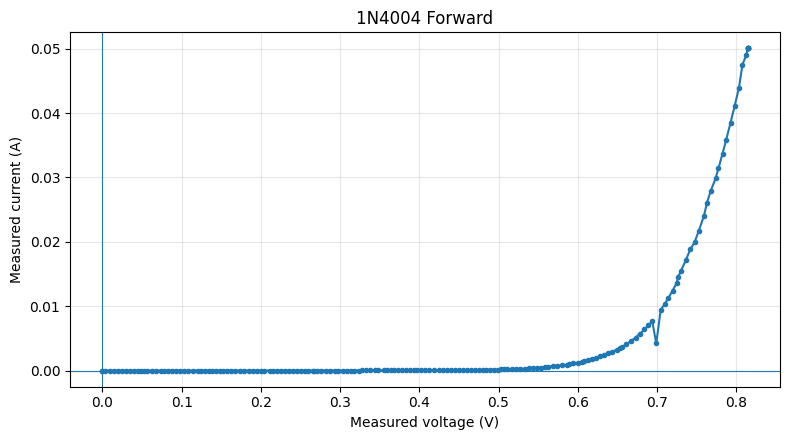

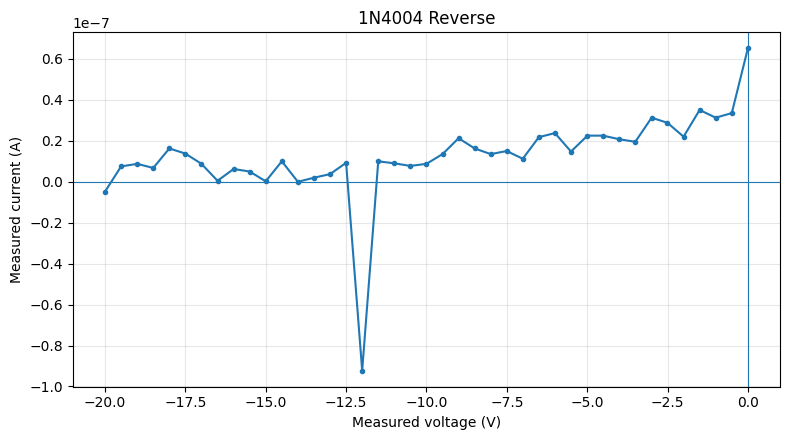

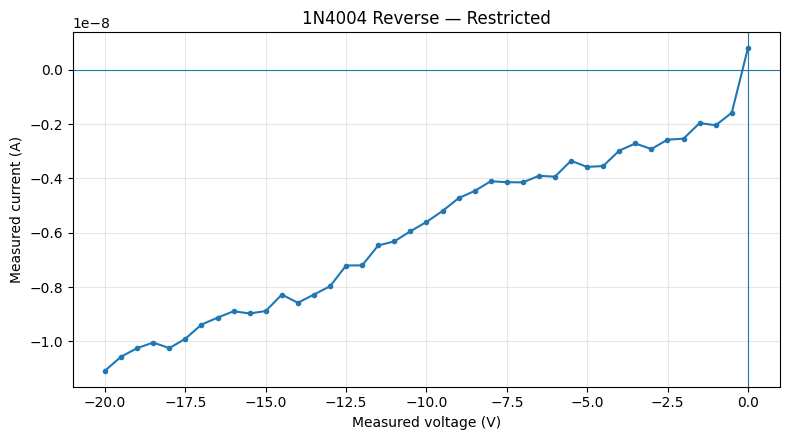

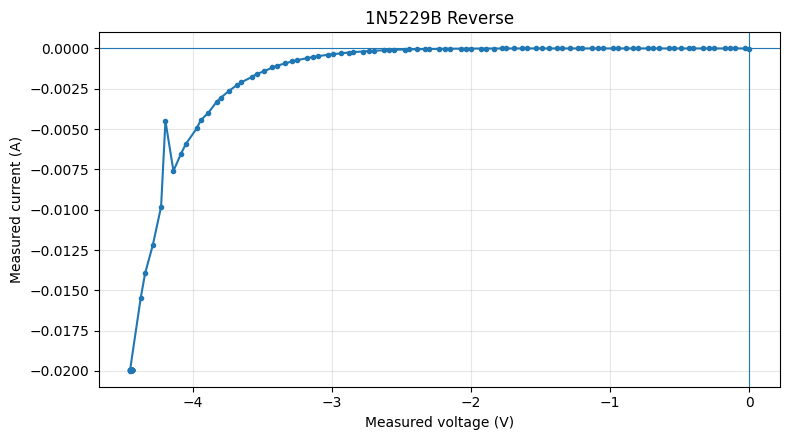

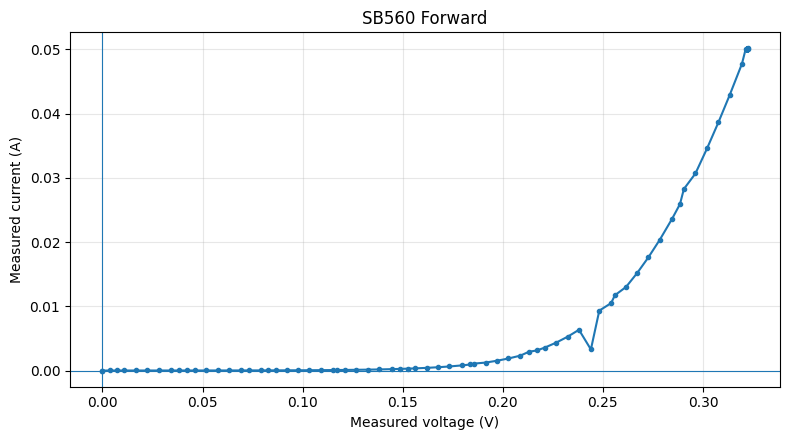

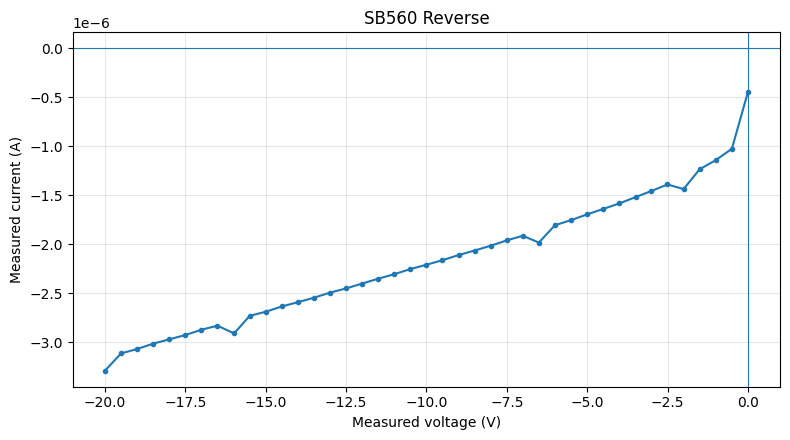

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path(
    "/content/diode_project/diode-iv-predictor-Copy-main/data/external"
)

files = [
    ("1N4004 Forward", "1n4004_forward.csv"),
    ("1N4004 Reverse", "1n4004_reverse.csv"),
    ("1N4004 Reverse — Restricted", "1n4004_reverse_10uA_range.csv"),
    ("1N5229B Reverse", "1n5229b_reverse.csv"),
    ("SB560 Forward", "sb560_forward.csv"),
    ("SB560 Reverse", "sb560_reverse.csv"),
]

for title, filename in files:
    df = pd.read_csv(data_dir / filename)

    df["v_meas"] = pd.to_numeric(df["v_meas"], errors="coerce")
    df["i_meas"] = pd.to_numeric(df["i_meas"], errors="coerce")
    df = df.dropna(subset=["v_meas", "i_meas"])

    plt.figure(figsize=(8, 4.5))
    plt.plot(df["v_meas"], df["i_meas"], "o-", markersize=3)
    plt.axhline(0, linewidth=0.8)
    plt.axvline(0, linewidth=0.8)

    plt.title(title)
    plt.xlabel("Measured voltage (V)")
    plt.ylabel("Measured current (A)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the restricted 1N4004 reverse-bias dataset
project_dir = Path(
    "/content/diode_project/diode-iv-predictor-Copy-main"
)

file_path = (
    project_dir / "data" / "external"
    / "1n4004_reverse_10uA_range.csv"
)

df = pd.read_csv(file_path)
df["v_meas"] = pd.to_numeric(df["v_meas"], errors="coerce")
df["i_meas"] = pd.to_numeric(df["i_meas"], errors="coerce")
df = df.dropna(subset=["v_meas", "i_meas"])

# Sort by voltage before splitting
df = df.sort_values("v_meas").reset_index(drop=True)

X = df[["v_meas"]]
y = df["i_meas"]

# First 80% for training, last 20% for testing
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE (A)": mean_absolute_error(y_test, predictions),
        "RMSE (A)": np.sqrt(mean_squared_error(y_test, predictions)),
        "R²": r2_score(y_test, predictions),
    })

results_df = pd.DataFrame(results).sort_values("MAE (A)")

print("Dataset rows:", len(df))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training voltage range:",
      X_train["v_meas"].min(), "to", X_train["v_meas"].max())
print("Testing voltage range:",
      X_test["v_meas"].min(), "to", X_test["v_meas"].max())

print("\nModel comparison:")
print(results_df.to_string(index=False))

# Show actual and predicted currents for the test set
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]
best_predictions = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Voltage (V)": X_test["v_meas"].to_numpy(),
    "Actual current (A)": y_test.to_numpy(),
    "Predicted current (A)": best_predictions,
})

comparison["Absolute error (A)"] = np.abs(
    comparison["Actual current (A)"]
    - comparison["Predicted current (A)"]
)

print("\nTest predictions using the lowest-MAE model:")
print(comparison.to_string(index=False))

Dataset rows: 41
Training rows: 32
Testing rows: 9
Training voltage range: -20.000218666666672 to -4.503039666666667
Testing voltage range: -4.002749266666666 to -0.00072218864

Model comparison:
            Model      MAE (A)     RMSE (A)         R²
Linear regression 7.709925e-10 8.235076e-10   0.436137
    Random forest 4.935160e-09 5.055543e-09 -20.250738
    Mean baseline 4.948442e-09 5.068510e-09 -20.359892

Test predictions using the lowest-MAE model:
 Voltage (V)  Actual current (A)  Predicted current (A)  Absolute error (A)
   -4.002749       -2.978576e-09          -2.636287e-09        3.422888e-10
   -3.502438       -2.713374e-09          -2.371196e-09        3.421777e-10
   -3.002150       -2.918654e-09          -2.106118e-09        8.125360e-10
   -2.501687       -2.573462e-09          -1.840948e-09        7.325144e-10
   -2.001421       -2.536477e-09          -1.575882e-09        9.605955e-10
   -1.501182       -1.960774e-09          -1.310830e-09        6.499446e-10
   -1.

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the dataset
project_dir = Path(
    "/content/diode_project/diode-iv-predictor-Copy-main"
)

file_path = (
    project_dir / "data" / "external"
    / "1n4004_reverse_10uA_range.csv"
)

df = pd.read_csv(file_path)
df["v_meas"] = pd.to_numeric(df["v_meas"], errors="coerce")
df["i_meas"] = pd.to_numeric(df["i_meas"], errors="coerce")
df = df.dropna(subset=["v_meas", "i_meas"])

X = df[["v_meas"]]
y = df["i_meas"]

# Randomly split the data, keeping 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE (A)": mean_absolute_error(y_test, predictions),
        "RMSE (A)": np.sqrt(mean_squared_error(y_test, predictions)),
        "R²": r2_score(y_test, predictions),
    })

results_df = pd.DataFrame(results).sort_values("MAE (A)")

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining voltage range:",
      X_train["v_meas"].min(), "to", X_train["v_meas"].max())
print("Testing voltage range:",
      X_test["v_meas"].min(), "to", X_test["v_meas"].max())

print("\nRandom-split model comparison:")
print(results_df.to_string(index=False))

Training rows: 32
Testing rows: 9

Training voltage range: -19.000224 to -0.00072218864
Testing voltage range: -20.000218666666672 to -2.0014214000000004

Random-split model comparison:
            Model      MAE (A)     RMSE (A)        R²
Linear regression 2.361843e-10 3.185346e-10  0.988300
    Mean baseline 2.661133e-09 3.052567e-09 -0.074482
    Random forest 2.662845e-09 3.056659e-09 -0.077365


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load SB560 reverse-bias data
project_dir = Path(
    "/content/diode_project/diode-iv-predictor-Copy-main"
)
file_path = project_dir / "data" / "external" / "sb560_reverse.csv"

df = pd.read_csv(file_path)
df["v_meas"] = pd.to_numeric(df["v_meas"], errors="coerce")
df["i_meas"] = pd.to_numeric(df["i_meas"], errors="coerce")
df = df.dropna(subset=["v_meas", "i_meas"])

# Sort by voltage before splitting
df = df.sort_values("v_meas").reset_index(drop=True)

X = df[["v_meas"]]
y = df["i_meas"]

# First 80% for training, final 20% for testing
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE (A)": mean_absolute_error(y_test, predictions),
        "RMSE (A)": np.sqrt(mean_squared_error(y_test, predictions)),
        "R²": r2_score(y_test, predictions),
    })

print("Dataset rows:", len(df))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training voltage range:",
      X_train["v_meas"].min(), "to", X_train["v_meas"].max())
print("Testing voltage range:",
      X_test["v_meas"].min(), "to", X_test["v_meas"].max())

print("\nSB560 reverse — voltage-ordered evaluation")
print(pd.DataFrame(results).sort_values("MAE (A)").to_string(index=False))

Dataset rows: 41
Training rows: 32
Testing rows: 9
Training voltage range: -19.99863 to -4.503063
Testing voltage range: -4.0027798 to -0.0006017853

SB560 reverse — voltage-ordered evaluation
            Model      MAE (A)     RMSE (A)         R²
Linear regression 1.784697e-07 2.866651e-07   0.249812
    Random forest 4.230279e-07 5.371166e-07  -1.633649
    Mean baseline 1.182323e-06 1.227774e-06 -12.761244


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

project_dir = Path(
    "/content/diode_project/diode-iv-predictor-Copy-main"
)

file_path = project_dir / "data" / "external" / "sb560_reverse.csv"

df = pd.read_csv(file_path)
df["v_meas"] = pd.to_numeric(df["v_meas"], errors="coerce")
df["i_meas"] = pd.to_numeric(df["i_meas"], errors="coerce")
df = df.dropna(subset=["v_meas", "i_meas"])

X = df[["v_meas"]]
y = df["i_meas"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE (A)": mean_absolute_error(y_test, predictions),
        "RMSE (A)": np.sqrt(mean_squared_error(y_test, predictions)),
        "R²": r2_score(y_test, predictions),
    })

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nSB560 reverse — random-split evaluation")
print(pd.DataFrame(results).sort_values("MAE (A)").to_string(index=False))

Training rows: 32
Testing rows: 9

SB560 reverse — random-split evaluation
            Model      MAE (A)     RMSE (A)        R²
Linear regression 7.744753e-08 1.013976e-07  0.970678
    Random forest 8.698232e-08 1.176065e-07  0.960554
    Mean baseline 5.204604e-07 6.305462e-07 -0.133896


In [ ]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

path = "data/external/sb560_forward.csv"
df = pd.read_csv(path)

# Use measured voltage and current
df = df[["v_meas", "i_meas"]].dropna()
df = df.sort_values("v_meas").reset_index(drop=True)

X = df[["v_meas"]]
y = df["i_meas"]

# Random 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    )
}

print("SB560 forward — random-split evaluation")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(
        f"{name}: "
        f"MAE={mean_absolute_error(y_test, pred):.6e} A, "
        f"RMSE={np.sqrt(mean_squared_error(y_test, pred)):.6e} A, "
        f"R²={r2_score(y_test, pred):.6f}"
    )

# Mean baseline: always predict the training-set mean current
baseline = np.full(len(y_test), y_train.mean())

print(
    f"Mean baseline: "
    f"MAE={mean_absolute_error(y_test, baseline):.6e} A, "
    f"RMSE={np.sqrt(mean_squared_error(y_test, baseline)):.6e} A, "
    f"R²={r2_score(y_test, baseline):.6f}"
)


FileNotFoundError: [Errno 2] No such file or directory: 'data/external/sb560_forward.csv'

In [ ]:

import os

print("Current working folder:")
print(os.getcwd())

print("\nSearching for sb560_forward.csv...")
matches = []

for root, dirs, files in os.walk("/content"):
    if "sb560_forward.csv" in files:
        matches.append(os.path.join(root, "sb560_forward.csv"))

if matches:
    for path in matches:
        print(path)
else:
    print("Dataset not found under /content.")


Current working folder:
/content

Searching for sb560_forward.csv...
/content/diode_project/diode-iv-predictor-Copy-main/data/external/sb560_forward.csv


In [ ]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

path = "/content/diode_project/diode-iv-predictor-Copy-main/data/external/sb560_forward.csv"

df = pd.read_csv(path)
df = df[["v_meas", "i_meas"]].dropna()
df = df.sort_values("v_meas").reset_index(drop=True)

X = df[["v_meas"]]
y = df["i_meas"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    )
}

print("SB560 forward — random-split evaluation")
print("Total rows:", len(df))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(
        f"{name}: "
        f"MAE={mean_absolute_error(y_test, pred):.6e} A, "
        f"RMSE={np.sqrt(mean_squared_error(y_test, pred)):.6e} A, "
        f"R²={r2_score(y_test, pred):.6f}"
    )

baseline = np.full(len(y_test), y_train.mean())

print(
    f"Mean baseline: "
    f"MAE={mean_absolute_error(y_test, baseline):.6e} A, "
    f"RMSE={np.sqrt(mean_squared_error(y_test, baseline)):.6e} A, "
    f"R²={r2_score(y_test, baseline):.6f}"
)


SB560 forward — random-split evaluation
Total rows: 120
Training rows: 96
Testing rows: 24
Linear regression: MAE=1.012891e-02 A, RMSE=1.186036e-02 A, R²=0.737351
Random forest: MAE=2.102222e-04 A, RMSE=5.523498e-04 A, R²=0.999430
Mean baseline: MAE=2.295811e-02 A, RMSE=2.342430e-02 A, R²=-0.024502


In [ ]:

import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

path = "/content/diode_project/diode-iv-predictor-Copy-main/data/external/sb560_forward.csv"

df = pd.read_csv(path)
df = df[["v_meas", "i_meas"]].dropna()
df = df.sort_values("v_meas").reset_index(drop=True)

X = df[["v_meas"]]
y = df["i_meas"]

split = int(len(df) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("SB560 forward — voltage-ordered evaluation")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training voltage range:", X_train["v_meas"].min(), "to", X_train["v_meas"].max())
print("Testing voltage range:", X_test["v_meas"].min(), "to", X_test["v_meas"].max())

models = {
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(n_estimators=200, random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(
        f"{name}: "
        f"MAE={mean_absolute_error(y_test, pred):.6e} A, "
        f"RMSE={np.sqrt(mean_squared_error(y_test, pred)):.6e} A, "
        f"R²={r2_score(y_test, pred):.6f}"
    )

baseline = np.full(len(y_test), y_train.mean())

print(
    f"Mean baseline: "
    f"MAE={mean_absolute_error(y_test, baseline):.6e} A, "
    f"RMSE={np.sqrt(mean_squared_error(y_test, baseline)):.6e} A, "
    f"R²={r2_score(y_test, baseline):.6f}"
)


SB560 forward — voltage-ordered evaluation
Training rows: 96
Testing rows: 24
Training voltage range: -7.96453e-05 to 0.322057
Testing voltage range: 0.3220586 to 0.3223357
Linear regression: MAE=1.008502e-02 A, RMSE=1.008505e-02 A, R²=-96852.602236
Random forest: MAE=1.060323e-05 A, RMSE=3.396036e-05 A, R²=-0.098258
Mean baseline: MAE=3.010481e-02 A, RMSE=3.010482e-02 A, R²=-863040.868551


In [ ]:

import pandas as pd

path = "/content/diode_project/diode-iv-predictor-Copy-main/data/external/sb560_forward.csv"

df = pd.read_csv(path)[["v_meas", "i_meas"]].dropna()
df = df.sort_values("v_meas").reset_index(drop=True)

print("Voltage distribution:")
print(df["v_meas"].describe())

print("\nLast 30 measurements:")
print(df.tail(30).to_string(index=False))

print("\nVoltage values rounded to 4 decimal places:")
print(df["v_meas"].round(4).value_counts().sort_index().tail(15))


Voltage distribution:
count    120.000000
mean       0.230373
std        0.109261
min       -0.000080
25%        0.143066
50%        0.289468
75%        0.322033
max        0.322336
Name: v_meas, dtype: float64

Last 30 measurements:
  v_meas   i_meas
0.322036 0.050020
0.322042 0.050020
0.322043 0.050021
0.322046 0.050022
0.322051 0.050021
0.322057 0.050022
0.322059 0.050022
0.322064 0.050021
0.322065 0.050022
0.322067 0.050022
0.322071 0.050022
0.322077 0.050022
0.322082 0.050022
0.322086 0.050021
0.322093 0.050021
0.322096 0.050021
0.322098 0.050021
0.322098 0.050022
0.322106 0.050021
0.322111 0.050020
0.322117 0.050021
0.322126 0.050021
0.322134 0.050022
0.322139 0.050022
0.322145 0.050023
0.322154 0.050024
0.322162 0.050024
0.322178 0.050031
0.322305 0.050122
0.322336 0.050154

Voltage values rounded to 4 decimal places:
v_meas
0.2727     1
0.2785     1
0.2846     1
0.2885     1
0.2904     1
0.2962     1
0.3020     1
0.3077     1
0.3133     1
0.3195     1
0.3213     1
0.3220    27


In [ ]:

import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

path = "/content/diode_project/diode-iv-predictor-Copy-main/data/external/sb560_forward.csv"

df = pd.read_csv(path)[["v_meas", "i_meas"]].dropna()
df = df.sort_values("v_meas").reset_index(drop=True)

X = df[["v_meas"]]
y = df["i_meas"]

# First 70% for training; final 30% for testing
split = int(len(df) * 0.7)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training voltage range:", X_train["v_meas"].min(), "to", X_train["v_meas"].max())
print("Testing voltage range:", X_test["v_meas"].min(), "to", X_test["v_meas"].max())
print("Test current range:", y_test.min(), "to", y_test.max())

models = {
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(n_estimators=200, random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(
        f"{name}: "
        f"MAE={mean_absolute_error(y_test, pred):.6e} A, "
        f"RMSE={np.sqrt(mean_squared_error(y_test, pred)):.6e} A, "
        f"R²={r2_score(y_test, pred):.6f}"
    )

baseline = np.full(len(y_test), y_train.mean())

print(
    f"Mean baseline: "
    f"MAE={mean_absolute_error(y_test, baseline):.6e} A, "
    f"RMSE={np.sqrt(mean_squared_error(y_test, baseline)):.6e} A, "
    f"R²={r2_score(y_test, baseline):.6f}"
)


Training rows: 84
Testing rows: 36
Training voltage range: -7.96453e-05 to 0.3220105
Testing voltage range: 0.3220135 to 0.3223357
Test current range: 0.05001987 to 0.05015422
Linear regression: MAE=1.363101e-02 A, RMSE=1.363102e-02 A, R²=-255498.520315
Random forest: MAE=7.325955e-06 A, RMSE=2.777411e-05 A, R²=-0.060752
Mean baseline: MAE=3.440024e-02 A, RMSE=3.440025e-02 A, R²=-1627257.520159


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

path = "/content/diode_project/diode-iv-predictor-Copy-main/data/external/1n4004_reverse.csv"

df = pd.read_csv(path)
print("Columns:", df.columns.tolist())
print("Original rows:", len(df))

# Display the columns before selecting voltage and current
print(df.head())

Columns: ['v_set', 'v_meas', 'i_meas']
Original rows: 41
   v_set    v_meas        i_meas
0    0.0 -0.000706  6.515776e-08
1   -0.5 -0.500739  3.358131e-08
2   -1.0 -1.000960  3.132585e-08
3   -1.5 -1.501168  3.508495e-08
4   -2.0 -2.001407  2.205339e-08


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

path = "/content/diode_project/diode-iv-predictor-Copy-main/data/external/1n4004_reverse.csv"

df = pd.read_csv(path)
df = df[["v_meas", "i_meas"]].dropna()

X = df[["v_meas"]]
y = df["i_meas"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    )
}

print("1N4004 reverse — random-split evaluation")
print("Total rows:", len(df))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(
        f"{name}: "
        f"MAE={mean_absolute_error(y_test, pred):.6e} A, "
        f"RMSE={np.sqrt(mean_squared_error(y_test, pred)):.6e} A, "
        f"R²={r2_score(y_test, pred):.6f}"
    )

baseline = np.full(len(y_test), y_train.mean())

print(
    f"Mean baseline: "
    f"MAE={mean_absolute_error(y_test, baseline):.6e} A, "
    f"RMSE={np.sqrt(mean_squared_error(y_test, baseline)):.6e} A, "
    f"R²={r2_score(y_test, baseline):.6f}"
)

1N4004 reverse — random-split evaluation
Total rows: 41
Training rows: 32
Testing rows: 9
Linear regression: MAE=1.507378e-08 A, RMSE=3.502578e-08 A, R²=-0.067330
Random forest: MAE=1.798472e-08 A, RMSE=3.653991e-08 A, R²=-0.161604
Mean baseline: MAE=1.883071e-08 A, RMSE=3.714041e-08 A, R²=-0.200097


In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

path = "/content/diode_project/diode-iv-predictor-Copy-main/data/external/1n4004_reverse.csv"

df = pd.read_csv(path)[["v_meas", "i_meas"]].dropna()
df = df.sort_values("v_meas").reset_index(drop=True)

X = df[["v_meas"]]
y = df["i_meas"]

# First 80% for training; final 20% for testing
split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("1N4004 reverse — voltage-ordered evaluation")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training voltage range:", X_train["v_meas"].min(), "to", X_train["v_meas"].max())
print("Testing voltage range:", X_test["v_meas"].min(), "to", X_test["v_meas"].max())

models = {
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(
        f"{name}: "
        f"MAE={mean_absolute_error(y_test, pred):.6e} A, "
        f"RMSE={np.sqrt(mean_squared_error(y_test, pred)):.6e} A, "
        f"R²={r2_score(y_test, pred):.6f}"
    )

baseline = np.full(len(y_test), y_train.mean())

print(
    f"Mean baseline: "
    f"MAE={mean_absolute_error(y_test, baseline):.6e} A, "
    f"RMSE={np.sqrt(mean_squared_error(y_test, baseline)):.6e} A, "
    f"R²={r2_score(y_test, baseline):.6f}"
)

1N4004 reverse — voltage-ordered evaluation
Training rows: 32
Testing rows: 9
Training voltage range: -20.000098 to -4.503041
Testing voltage range: -4.0027552 to -0.0007055427
Linear regression: MAE=1.417005e-08 A, RMSE=1.854031e-08 A, R²=-1.059845
Random forest: MAE=1.792512e-08 A, RMSE=2.209498e-08 A, R²=-1.925418
Mean baseline: MAE=2.465230e-08 A, RMSE=2.783189e-08 A, R²=-3.641796


In [ ]:
import pandas as pd

path = "/content/diode_project/diode-iv-predictor-Copy-main/data/external/1n5229b_reverse.csv"

df = pd.read_csv(path)

print("Columns:", df.columns.tolist())
print("Original rows:", len(df))
print(df.head())

Columns: ['v_set', 'v_meas', 'i_meas']
Original rows: 121
   v_set    v_meas        i_meas
0   0.00       NaN           NaN
1  -0.05 -0.000204 -1.681692e-05
2  -0.10 -0.029033 -4.135012e-08
3  -0.15 -0.100642  1.503641e-08
4  -0.20 -0.140788 -4.510922e-08


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

path = "/content/diode_project/diode-iv-predictor-Copy-main/data/external/1n5229b_reverse.csv"

df = pd.read_csv(path)
df = df[["v_meas", "i_meas"]].dropna()

X = df[["v_meas"]]
y = df["i_meas"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    )
}

print("1N5229B reverse — random-split evaluation")
print("Valid rows:", len(df))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Voltage range:", X["v_meas"].min(), "to", X["v_meas"].max())
print("Current range:", y.min(), "to", y.max())

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(
        f"{name}: "
        f"MAE={mean_absolute_error(y_test, pred):.6e} A, "
        f"RMSE={np.sqrt(mean_squared_error(y_test, pred)):.6e} A, "
        f"R²={r2_score(y_test, pred):.6f}"
    )

baseline = np.full(len(y_test), y_train.mean())

print(
    f"Mean baseline: "
    f"MAE={mean_absolute_error(y_test, baseline):.6e} A, "
    f"RMSE={np.sqrt(mean_squared_error(y_test, baseline)):.6e} A, "
    f"R²={r2_score(y_test, baseline):.6f}"
)

1N5229B reverse — random-split evaluation
Valid rows: 120
Training rows: 96
Testing rows: 24
Voltage range: -4.452992 to -0.0002043501
Current range: -0.01997947 to 5.263703e-08
Linear regression: MAE=4.851885e-03 A, RMSE=5.358014e-03 A, R²=0.577418
Random forest: MAE=4.369742e-05 A, RMSE=1.455840e-04 A, R²=0.999688
Mean baseline: MAE=7.771548e-03 A, RMSE=8.354727e-03 A, R²=-0.027466


In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

path = "/content/diode_project/diode-iv-predictor-Copy-main/data/external/1n5229b_reverse.csv"

df = pd.read_csv(path)[["v_meas", "i_meas"]].dropna()
df = df.sort_values("v_meas").reset_index(drop=True)

X = df[["v_meas"]]
y = df["i_meas"]

split = int(len(df) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("1N5229B reverse — voltage-ordered evaluation")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training voltage range:", X_train["v_meas"].min(), "to", X_train["v_meas"].max())
print("Testing voltage range:", X_test["v_meas"].min(), "to", X_test["v_meas"].max())

models = {
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(n_estimators=200, random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(
        f"{name}: "
        f"MAE={mean_absolute_error(y_test, pred):.6e} A, "
        f"RMSE={np.sqrt(mean_squared_error(y_test, pred)):.6e} A, "
        f"R²={r2_score(y_test, pred):.6f}"
    )

baseline = np.full(len(y_test), y_train.mean())

print(
    f"Mean baseline: "
    f"MAE={mean_absolute_error(y_test, baseline):.6e} A, "
    f"RMSE={np.sqrt(mean_squared_error(y_test, baseline)):.6e} A, "
    f"R²={r2_score(y_test, baseline):.6f}"
)

1N5229B reverse — voltage-ordered evaluation
Training rows: 96
Testing rows: 24
Training voltage range: -4.452992 to -1.200982
Testing voltage range: -1.130163 to -0.0002043501
Linear regression: MAE=1.105528e-02 A, RMSE=1.130064e-02 A, R²=-11323367.598395
Random forest: MAE=7.309322e-07 A, RMSE=3.432978e-06 A, R²=-0.044989
Mean baseline: MAE=7.661803e-03 A, RMSE=7.661804e-03 A, R²=-5205132.203159


In [ ]:
import pandas as pd

results_1n5229b = pd.DataFrame([
    {
        "Dataset": "1N5229B reverse",
        "Split": "Random",
        "Model": "Linear Regression",
        "MAE (A)": 4.851885e-03,
        "RMSE (A)": 5.358014e-03,
        "R2": 0.577418
    },
    {
        "Dataset": "1N5229B reverse",
        "Split": "Random",
        "Model": "Random Forest",
        "MAE (A)": 4.369742e-05,
        "RMSE (A)": 1.455840e-04,
        "R2": 0.999688
    },
    {
        "Dataset": "1N5229B reverse",
        "Split": "Voltage-ordered",
        "Model": "Linear Regression",
        "MAE (A)": 1.105528e-02,
        "RMSE (A)": 1.130064e-02,
        "R2": -11323367.598395
    },
    {
        "Dataset": "1N5229B reverse",
        "Split": "Voltage-ordered",
        "Model": "Random Forest",
        "MAE (A)": 7.309322e-07,
        "RMSE (A)": 3.432978e-06,
        "R2": -0.044989
    }
])

display(results_1n5229b)

,Dataset,Split,Model,MAE (A),RMSE (A),R2
0,1N5229B reverse,Random,Linear Regression,4.851885e-03,0.005358,5.774180e-01
1,1N5229B reverse,Random,Random Forest,4.369742e-05,0.000146,9.996880e-01
2,1N5229B reverse,Voltage-ordered,Linear Regression,1.105528e-02,0.011301,-1.132337e+07
3,1N5229B reverse,Voltage-ordered,Random Forest,7.309322e-07,0.000003,-4.498900e-02


In [ ]:
import pandas as pd

columns = [
    "Dataset",
    "Split",
    "Model",
    "MAE (A)",
    "RMSE (A)",
    "R2"
]

if "all_results" not in globals():
    all_results = pd.DataFrame(columns=columns)

display(all_results)

,Dataset,Split,Model,MAE (A),RMSE (A),R2


In [ ]:
import pandas as pd

all_results = pd.DataFrame([
    # 1N4004 reverse
    ["1N4004 reverse", "Random", "Linear Regression", 1.507378e-08, 3.502578e-08, -0.067330],
    ["1N4004 reverse", "Random", "Random Forest", 1.798472e-08, 3.653991e-08, -0.161604],
    ["1N4004 reverse", "Voltage-ordered", "Linear Regression", 1.417005e-08, 1.854031e-08, -1.059845],
    ["1N4004 reverse", "Voltage-ordered", "Random Forest", 1.792512e-08, 2.209498e-08, -1.925418],

    # 1N4004 reverse, restricted-current range
    ["1N4004 reverse (restricted)", "Random", "Linear Regression", 2.361843e-10, 3.185346e-10, 0.988300],
    ["1N4004 reverse (restricted)", "Random", "Random Forest", 2.662845e-09, 3.056659e-09, -0.077365],
    ["1N4004 reverse (restricted)", "Voltage-ordered", "Linear Regression", 7.709925e-10, 8.235076e-10, 0.436137],
    ["1N4004 reverse (restricted)", "Voltage-ordered", "Random Forest", 4.935160e-09, 5.055543e-09, -20.250738],

    # SB560 forward
    ["SB560 forward", "Random", "Linear Regression", 1.012891e-02, 1.186036e-02, 0.737351],
    ["SB560 forward", "Random", "Random Forest", 2.102222e-04, 5.523498e-04, 0.999430],
    ["SB560 forward", "Voltage-ordered", "Linear Regression", 1.363101e-02, 1.363102e-02, -255498.520315],
    ["SB560 forward", "Voltage-ordered", "Random Forest", 7.325955e-06, 2.777411e-05, -0.060752],

    # SB560 reverse
    ["SB560 reverse", "Random", "Linear Regression", 7.744753e-08, 1.013976e-07, 0.970678],
    ["SB560 reverse", "Random", "Random Forest", 8.698232e-08, 1.176065e-07, 0.960554],
    ["SB560 reverse", "Voltage-ordered", "Linear Regression", 1.784697e-07, 2.866651e-07, 0.249812],
    ["SB560 reverse", "Voltage-ordered", "Random Forest", 4.230279e-07, 5.371166e-07, -1.633649],

    # 1N5229B reverse
    ["1N5229B reverse", "Random", "Linear Regression", 4.851885e-03, 5.358014e-03, 0.577418],
    ["1N5229B reverse", "Random", "Random Forest", 4.369742e-05, 1.455840e-04, 0.999688],
    ["1N5229B reverse", "Voltage-ordered", "Linear Regression", 1.105528e-02, 1.130064e-02, -11323367.598395],
    ["1N5229B reverse", "Voltage-ordered", "Random Forest", 7.309322e-07, 3.432978e-06, -0.044989],
], columns=["Dataset", "Split", "Model", "MAE (A)", "RMSE (A)", "R2"])

display(all_results)

,Dataset,Split,Model,MAE (A),RMSE (A),R2
0,1N4004 reverse,Random,Linear Regression,1.507378e-08,3.502578e-08,-6.733000e-02
1,1N4004 reverse,Random,Random Forest,1.798472e-08,3.653991e-08,-1.616040e-01
2,1N4004 reverse,Voltage-ordered,Linear Regression,1.417005e-08,1.854031e-08,-1.059845e+00
3,1N4004 reverse,Voltage-ordered,Random Forest,1.792512e-08,2.209498e-08,-1.925418e+00
4,1N4004 reverse (restricted),Random,Linear Regression,2.361843e-10,3.185346e-10,9.883000e-01
5,1N4004 reverse (restricted),Random,Random Forest,2.662845e-09,3.056659e-09,-7.736500e-02
6,1N4004 reverse (restricted),Voltage-ordered,Linear Regression,7.709925e-10,8.235076e-10,4.361370e-01
7,1N4004 reverse (restricted),Voltage-ordered,Random Forest,4.935160e-09,5.055543e-09,-2.025074e+01
8,SB560 forward,Random,Linear Regression,1.012891e-02,1.186036e-02,7.373510e-01
9,SB560 forward,Random,Random Forest,2.102222e-04,5.523498e-04,9.994300e-01


In [ ]:
print("Checking previously saved evaluation results...\n")

for name in [
    "all_results",
    "results",
    "results_df",
    "comparison_df"
]:
    if name in globals():
        obj = globals()[name]
        print(f"Found: {name} ({type(obj).__name__})")
        if hasattr(obj, "head"):
            display(obj.head())

Checking previously saved evaluation results...

Found: all_results (DataFrame)


,Dataset,Split,Model,MAE (A),RMSE (A),R2
0,1N4004 reverse,Random,Linear Regression,1.507378e-08,3.502578e-08,-0.067330
1,1N4004 reverse,Random,Random Forest,1.798472e-08,3.653991e-08,-0.161604
2,1N4004 reverse,Voltage-ordered,Linear Regression,1.417005e-08,1.854031e-08,-1.059845
3,1N4004 reverse,Voltage-ordered,Random Forest,1.792512e-08,2.209498e-08,-1.925418
4,1N4004 reverse (restricted),Random,Linear Regression,2.361843e-10,3.185346e-10,0.988300


Found: results (list)
Found: results_df (DataFrame)


,Model,MAE (A),RMSE (A),R²
1,Linear regression,2.361843e-10,3.185346e-10,0.988300
0,Mean baseline,2.661133e-09,3.052567e-09,-0.074482
2,Random forest,2.662845e-09,3.056659e-09,-0.077365


In [ ]:
import pandas as pd
import os

path = "/content/diode_project/diode-iv-predictor-Copy-main/data/external/1n4004_forward.csv"

if os.path.exists(path):
    df_forward = pd.read_csv(path)

    print("Dataset found!")
    print("Rows:", len(df_forward))
    print("Columns:", df_forward.columns.tolist())
    print("\nFirst five rows:")
    display(df_forward.head())

    print("\nMissing values:")
    print(df_forward.isnull().sum())
else:
    print("Dataset not found at:", path)

Dataset found!
Rows: 171
Columns: ['v_set', 'v_meas', 'i_meas']

First five rows:


,v_set,v_meas,i_meas
0,0.000,NaN,NaN
1,0.005,0.000000,0.000000e+00
2,0.010,-0.000242,-1.595252e-05
3,0.015,0.003574,5.137439e-08
4,0.020,0.009415,5.388046e-08



Missing values:
v_set     0
v_meas    1
i_meas    1
dtype: int64


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

path = "/content/diode_project/diode-iv-predictor-Copy-main/data/external/1n4004_forward.csv"

df = pd.read_csv(path)[["v_meas", "i_meas"]].dropna()
X = df[["v_meas"]]
y = df["i_meas"]

print("Valid rows:", len(df))
print("Voltage range:", X["v_meas"].min(), "to", X["v_meas"].max())
print("Current range:", y.min(), "to", y.max())

def evaluate_split(X_train, X_test, y_train, y_test, split_name):
    models = {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(
            n_estimators=200, random_state=42
        )
    }

    print(f"\n--- {split_name} ---")
    print("Training rows:", len(X_train))
    print("Testing rows:", len(X_test))

    for name, model in models.items():
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        print(
            f"{name}: "
            f"MAE={mean_absolute_error(y_test, predictions):.6e} A, "
            f"RMSE={np.sqrt(mean_squared_error(y_test, predictions)):.6e} A, "
            f"R²={r2_score(y_test, predictions):.6f}"
        )

    baseline = np.full(len(y_test), y_train.mean())
    print(
        f"Mean baseline: "
        f"MAE={mean_absolute_error(y_test, baseline):.6e} A, "
        f"RMSE={np.sqrt(mean_squared_error(y_test, baseline)):.6e} A, "
        f"R²={r2_score(y_test, baseline):.6f}"
    )

# Random split: test points are distributed across the voltage range.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
evaluate_split(X_train, X_test, y_train, y_test, "Random split")

# Voltage-ordered split: test points occupy the highest voltage range.
df_sorted = df.sort_values("v_meas").reset_index(drop=True)
X_sorted = df_sorted[["v_meas"]]
y_sorted = df_sorted["i_meas"]

split = int(len(df_sorted) * 0.8)
X_train_ordered, X_test_ordered = X_sorted.iloc[:split], X_sorted.iloc[split:]
y_train_ordered, y_test_ordered = y_sorted.iloc[:split], y_sorted.iloc[split:]

print("\nTraining voltage range:",
      X_train_ordered["v_meas"].min(), "to",
      X_train_ordered["v_meas"].max())
print("Testing voltage range:",
      X_test_ordered["v_meas"].min(), "to",
      X_test_ordered["v_meas"].max())

evaluate_split(
    X_train_ordered, X_test_ordered,
    y_train_ordered, y_test_ordered,
    "Voltage-ordered split"
)

Valid rows: 170
Voltage range: -0.0002423983 to 0.8146680333333333
Current range: -1.595252e-05 to 0.0500351066666666

--- Random split ---
Training rows: 136
Testing rows: 34
Linear Regression: MAE=6.751139e-03 A, RMSE=9.620578e-03 A, R²=0.432392
Random Forest: MAE=8.773221e-05 A, RMSE=2.590915e-04 A, R²=0.999588
Mean baseline: MAE=8.329979e-03 A, RMSE=1.277532e-02 A, R²=-0.000897

Training voltage range: -0.0002423983 to 0.6674781
Testing voltage range: 0.6730717 to 0.8146680333333333

--- Voltage-ordered split ---
Training rows: 136
Testing rows: 34
Linear Regression: MAE=2.436417e-02 A, RMSE=2.908031e-02 A, R²=-2.303851
Random Forest: MAE=2.155883e-02 A, RMSE=2.684124e-02 A, R²=-1.814671
Mean baseline: MAE=2.551617e-02 A, RMSE=3.011707e-02 A, R²=-2.543626


In [ ]:
new_results = pd.DataFrame([
    ["1N4004 forward", "Random", "Linear Regression",
     6.751139e-03, 9.620578e-03, 0.432392],

    ["1N4004 forward", "Random", "Random Forest",
     8.773221e-05, 2.590915e-04, 0.999588],

    ["1N4004 forward", "Random", "Mean baseline",
     8.329979e-03, 1.277532e-02, -0.000897],

    ["1N4004 forward", "Voltage-ordered", "Linear Regression",
     2.436417e-02, 2.908031e-02, -2.303851],

    ["1N4004 forward", "Voltage-ordered", "Random Forest",
     2.155883e-02, 2.684124e-02, -1.814671],

    ["1N4004 forward", "Voltage-ordered", "Mean baseline",
     2.551617e-02, 3.011707e-02, -2.543626],
], columns=all_results.columns)

all_results = pd.concat([all_results, new_results], ignore_index=True)

display(all_results)

,Dataset,Split,Model,MAE (A),RMSE (A),R2
0,1N4004 reverse,Random,Linear Regression,1.507378e-08,3.502578e-08,-6.733000e-02
1,1N4004 reverse,Random,Random Forest,1.798472e-08,3.653991e-08,-1.616040e-01
2,1N4004 reverse,Voltage-ordered,Linear Regression,1.417005e-08,1.854031e-08,-1.059845e+00
3,1N4004 reverse,Voltage-ordered,Random Forest,1.792512e-08,2.209498e-08,-1.925418e+00
4,1N4004 reverse (restricted),Random,Linear Regression,2.361843e-10,3.185346e-10,9.883000e-01
5,1N4004 reverse (restricted),Random,Random Forest,2.662845e-09,3.056659e-09,-7.736500e-02
6,1N4004 reverse (restricted),Voltage-ordered,Linear Regression,7.709925e-10,8.235076e-10,4.361370e-01
7,1N4004 reverse (restricted),Voltage-ordered,Random Forest,4.935160e-09,5.055543e-09,-2.025074e+01
8,SB560 forward,Random,Linear Regression,1.012891e-02,1.186036e-02,7.373510e-01
9,SB560 forward,Random,Random Forest,2.102222e-04,5.523498e-04,9.994300e-01


In [ ]:
import os

project_path = "/content/diode_project/diode-iv-predictor-Copy-main"

model_paths = [
    "random_forest_model.joblib",
    "tuned_svr_model.joblib",
    "trained_models/silicon_svr.joblib",
    "trained_models/silicon_carbide_svr.joblib",
    "trained_models/gan_rf_300K.joblib",
    "trained_models/gan_rf_temperature_aware.joblib",
    "trained_models/gan_temperature_aware_svr.joblib"
]

print("Checking saved models:\n")

for relative_path in model_paths:
    full_path = os.path.join(project_path, relative_path)
    status = "FOUND" if os.path.exists(full_path) else "NOT FOUND"
    print(f"{relative_path}: {status}")

Checking saved models:

random_forest_model.joblib: FOUND
tuned_svr_model.joblib: FOUND
trained_models/silicon_svr.joblib: FOUND
trained_models/silicon_carbide_svr.joblib: FOUND
trained_models/gan_rf_300K.joblib: NOT FOUND
trained_models/gan_rf_temperature_aware.joblib: NOT FOUND
trained_models/gan_temperature_aware_svr.joblib: FOUND


In [ ]:
import pandas as pd
import os

project_path = "/content/diode_project/diode-iv-predictor-Copy-main"
data_path = os.path.join(
    project_path,
    "data/processed/classified_diode_measurements.csv"
)

data = pd.read_csv(data_path)

for material in ["silicon", "silicon carbide"]:
    subset = data[data["material"] == material]

    print(f"\n{'='*50}")
    print(f"Material: {material}")
    print(f"Total rows: {len(subset)}")

    print("\nRows per temperature (K):")
    print(subset["temperature_K"].value_counts().sort_index())

    print("\nDevices:")
    print(subset["device"].value_counts().to_string())

    print("\nVoltage range (V):")
    print(subset["voltage_V"].agg(["min", "max"]))

    print("\nCurrent range (A):")
    print(subset["current_A"].agg(["min", "max"]))


Material: silicon
Total rows: 492

Rows per temperature (K):
temperature_K
77     291
293    201
Name: count, dtype: int64

Devices:
device
MBR4035      58
45L120       56
1N3913       56
BZW1347      55
BZW1336      55
BZW12360     54
BYX661000    54
1N1190       52
1N11877R     52

Voltage range (V):
min    0.0000
max    2.0558
Name: voltage_V, dtype: float64

Current range (A):
min      0.0
max    165.8
Name: current_A, dtype: float64

Material: silicon carbide
Total rows: 228

Rows per temperature (K):
temperature_K
77     135
293     93
Name: count, dtype: int64

Devices:
device
STPSC12065DY      59
FFSH3065B         57
FFSH3065B-F085    56
C6D20065A         56

Voltage range (V):
min    0.0000
max    1.7627
Name: voltage_V, dtype: float64

Current range (A):
min     0.000
max    25.089
Name: current_A, dtype: float64


In [ ]:
import os
import joblib

project_path = "/content/diode_project/diode-iv-predictor-Copy-main"

model_files = {
    "Silicon SVR": "trained_models/silicon_svr.joblib",
    "Silicon carbide SVR": "trained_models/silicon_carbide_svr.joblib",
    "GaN temperature-aware SVR": "trained_models/gan_temperature_aware_svr.joblib",
}

for name, relative_path in model_files.items():
    path = os.path.join(project_path, relative_path)
    print(f"\n{'='*50}\n{name}")

    try:
        model = joblib.load(path)
        print("Model type:", type(model).__name__)

        if hasattr(model, "feature_names_in_"):
            print("Expected input features:", list(model.feature_names_in_))
        elif hasattr(model, "named_steps"):
            print("Pipeline steps:", list(model.named_steps.keys()))
            for step_name, step in model.named_steps.items():
                if hasattr(step, "feature_names_in_"):
                    print(
                        f"Features recorded by {step_name}:",
                        list(step.feature_names_in_)
                    )
        elif hasattr(model, "regressor_"):
            regressor = model.regressor_
            if hasattr(regressor, "feature_names_in_"):
                print("Expected input features:",
                      list(regressor.feature_names_in_))

    except Exception as e:
        print("Could not load model:", repr(e))


Silicon SVR
Model type: Pipeline
Expected input features: ['device', 'voltage_V', 'temperature_K']

Silicon carbide SVR
Model type: Pipeline
Expected input features: ['device', 'voltage_V', 'temperature_K']

GaN temperature-aware SVR
Model type: TransformedTargetRegressor
Expected input features: ['voltage_V', 'temperature_K']


In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

project_path = "/content/diode_project/diode-iv-predictor-Copy-main"

data_path = os.path.join(
    project_path, "data/processed/classified_diode_measurements.csv"
)

data = pd.read_csv(data_path)

model_files = {
    "silicon": "trained_models/silicon_svr.joblib",
    "silicon carbide": "trained_models/silicon_carbide_svr.joblib"
}

for material, relative_path in model_files.items():
    print(f"\n{'='*60}")
    print(f"Material: {material}")

    subset = data[
        (data["material"] == material) &
        (data["temperature_K"] == 293)
    ].copy()

    subset = subset.dropna(
        subset=["device", "voltage_V", "temperature_K", "current_A"]
    )

    if len(subset) < 5:
        print("Not enough valid rows to evaluate.")
        continue

    # Keep the same test split reproducible.
    train_idx, test_idx = train_test_split(
        subset.index, test_size=0.2, random_state=42
    )
    test = subset.loc[test_idx]

    model_path = os.path.join(project_path, relative_path)
    model = joblib.load(model_path)

    X_test = test[["device", "voltage_V", "temperature_K"]]
    y_test = test["current_A"].to_numpy()
    predictions = np.asarray(model.predict(X_test)).ravel()

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    print("Total rows at 293 K:", len(subset))
    print("Test rows:", len(test))
    print(f"MAE:  {mae:.6g} A")
    print(f"RMSE: {rmse:.6g} A")
    print(f"R²:   {r2:.6f}")

    comparison = test[["device", "voltage_V", "current_A"]].copy()
    comparison["predicted_current_A"] = predictions
    comparison["absolute_error_A"] = np.abs(y_test - predictions)

    print("\nExample predictions:")
    print(comparison.head(10).to_string(index=False))


Material: silicon
Total rows at 293 K: 201
Test rows: 41
MAE:  20.8713 A
RMSE: 34.8329 A
R²:   -0.496335

Example predictions:
   device  voltage_V  current_A  predicted_current_A  absolute_error_A
  MBR4035     0.3493     11.558             0.895836         10.662164
   1N1190     0.9440     24.322             1.377964         22.944036
   1N3913     1.0826     23.227             1.395842         21.831158
BYX661000     0.7394      0.213            -0.494559          0.707559
  BZW1336     0.9473     17.628             1.232065         16.395935
  BZW1336     0.7675      0.457             0.063027          0.393973
 1N11877R     0.8107      1.960             0.431981          1.528019
BYX661000     1.2041     23.705             1.392334         22.312666
BYX661000     1.2795     32.172             1.497458         30.674542
   45L120     0.7710      9.269             0.945282          8.323718

Material: silicon carbide
Total rows at 293 K: 93
Test rows: 19
MAE:  8.11298 A
RMSE: 10.0

In [ ]:
import os
import joblib

project_path = "/content/diode_project/diode-iv-predictor-Copy-main"

model_files = {
    "Silicon SVR": "trained_models/silicon_svr.joblib",
    "SiC SVR": "trained_models/silicon_carbide_svr.joblib",
}

for name, relative_path in model_files.items():
    print(f"\n{'='*55}")
    print(name)

    model = joblib.load(os.path.join(project_path, relative_path))

    if hasattr(model, "named_steps"):
        for step_name, step in model.named_steps.items():
            print(f"\nStep: {step_name}")
            print("Type:", type(step).__name__)

            if hasattr(step, "get_params"):
                params = step.get_params(deep=False)
                print("Parameters:", params)

            if hasattr(step, "mean_"):
                print("Scaler mean:", step.mean_)

            if hasattr(step, "scale_"):
                print("Scaler scale:", step.scale_)

    if hasattr(model, "feature_names_in_"):
        print("\nInput features:", list(model.feature_names_in_))


Silicon SVR

Step: columntransformer
Type: ColumnTransformer
Parameters: {'force_int_remainder_cols': True, 'n_jobs': None, 'remainder': 'drop', 'sparse_threshold': 0.3, 'transformer_weights': None, 'transformers': [('device', OneHotEncoder(handle_unknown='ignore'), ['device']), ('numeric', StandardScaler(), ['voltage_V', 'temperature_K'])], 'verbose': False, 'verbose_feature_names_out': True}

Step: svr
Type: SVR
Parameters: {'C': 1, 'cache_size': 200, 'coef0': 0.0, 'degree': 3, 'epsilon': 0.01, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'shrinking': True, 'tol': 0.001, 'verbose': False}

Input features: ['device', 'voltage_V', 'temperature_K']

SiC SVR

Step: columntransformer
Type: ColumnTransformer
Parameters: {'force_int_remainder_cols': True, 'n_jobs': None, 'remainder': 'drop', 'sparse_threshold': 0.3, 'transformer_weights': None, 'transformers': [('device', OneHotEncoder(handle_unknown='ignore'), ['device']), ('numeric', StandardScaler(), ['voltage_V', 'temperature_K']

In [ ]:
import os

project_path = "/content/diode_project/diode-iv-predictor-Copy-main"

for root, dirs, files in os.walk(project_path):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__", ".venv", "venv"]
    ]

    for filename in files:
        if filename.endswith(".py"):
            path = os.path.join(root, filename)

            try:
                with open(path, "r", encoding="utf-8") as f:
                    content = f.read()

                if (
                    "silicon_carbide_svr" in content
                    or "silicon_svr" in content
                    or (
                        "SVR(" in content
                        and "temperature_K" in content
                        and "current_A" in content
                    )
                ):
                    print(f"\n{'='*60}")
                    print("File:", os.path.relpath(path, project_path))

                    for line_number, line in enumerate(
                        content.splitlines(), start=1
                    ):
                        if any(term in line.lower() for term in [
                            "silicon_svr", "silicon_carbide_svr",
                            "transformedtargetregressor", "log10",
                            "current_a", "svr(", "fit(", "train_test_split",
                            "standardscaler"
                        ]):
                            print(f"{line_number}: {line.strip()}")

            except (UnicodeDecodeError, OSError):
                pass


File: app.py
93: ("Silicon SVR", "trained_models/silicon_svr.joblib"),
94: ("SiC SVR", "trained_models/silicon_carbide_svr.joblib"),
133: "current_A",
141: subset=["device", "voltage_V", "current_A", "temperature_K"]
175: ("v_meas", "i_meas"), ("voltage_V", "current_A"),
494: & (training_data["current_A"] > 0)
551: & (training_data["current_A"] > 0)
680: & (training_data["current_A"] > 0)
701: # log10(current), so convert back to amperes.
1048: return np.sign(values) * np.log10(


In [ ]:
import os

project_path = "/content/diode_project/diode-iv-predictor-Copy-main"
app_path = os.path.join(project_path, "app.py")

with open(app_path, "r", encoding="utf-8") as f:
    lines = f.readlines()

# Print the sections around the relevant model-training code.
for start, end in [(460, 580), (650, 720), (1020, 1070)]:
    print(f"\n{'='*65}")
    print(f"app.py lines {start}-{end}")
    print("="*65)

    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1}: {lines[i]}", end="")


app.py lines 460-580
460:                     .str.lower()
461:                     .eq("silicon"),
462:                     "device",
463:                 ]
464:                 .dropna()
465:                 .astype(str)
466:                 .unique()
467:             )
468: 
469:             if device_options:
470:                 device = st.selectbox(
471:                     "2. Choose device",
472:                     device_options,
473:                     key="predict_silicon_device",
474:                 )
475: 
476:                 available_models = (
477:                     ["Silicon SVR"] if "Silicon SVR" in models else []
478:                 )
479: 
480:                 if available_models:
481:                     model_name = st.selectbox(
482:                         "3. Choose model",
483:                         available_models,
484:                         key="predict_model_silicon",
485:                     )
486:                 else:
487:                  

In [ ]:
import os
import joblib

project_path = "/content/diode_project/diode-iv-predictor-Copy-main"

model_files = {
    "Silicon SVR": "trained_models/silicon_svr.joblib",
    "SiC SVR": "trained_models/silicon_carbide_svr.joblib",
}

for name, relative_path in model_files.items():
    path = os.path.join(project_path, relative_path)
    model = joblib.load(path)

    print(f"\n{'='*50}")
    print(name)
    print("Model type:", type(model).__name__)

    if hasattr(model, "regressor_"):
        print("Uses a wrapped regressor:", True)
        print("Wrapped regressor type:", type(model.regressor_).__name__)
        print("Target transformer:", getattr(model, "transformer_", None))
    else:
        print("Uses a wrapped regressor:", False)

    if hasattr(model, "named_steps"):
        print("Pipeline steps:", list(model.named_steps.keys()))


Silicon SVR
Model type: Pipeline
Uses a wrapped regressor: False
Pipeline steps: ['columntransformer', 'svr']

SiC SVR
Model type: Pipeline
Uses a wrapped regressor: False
Pipeline steps: ['columntransformer', 'svr']


In [ ]:
import os
import joblib
import numpy as np
import pandas as pd

project_path = "/content/diode_project/diode-iv-predictor-Copy-main"

data_path = os.path.join(
    project_path, "data/processed/classified_diode_measurements.csv"
)
data = pd.read_csv(data_path)

model_files = {
    "silicon": "trained_models/silicon_svr.joblib",
    "silicon carbide": "trained_models/silicon_carbide_svr.joblib",
}

for material, relative_path in model_files.items():
    print(f"\n{'='*60}")
    print(material)

    subset = data[
        (data["material"] == material) &
        (data["temperature_K"] == 293) &
        (data["current_A"] > 0)
    ].dropna(subset=["device", "voltage_V", "temperature_K", "current_A"])

    model = joblib.load(os.path.join(project_path, relative_path))

    # Use a few rows to inspect scale, not to claim model accuracy.
    sample = subset.head(5)
    X = sample[["device", "voltage_V", "temperature_K"]]
    actual = sample["current_A"].to_numpy()
    raw_prediction = np.asarray(model.predict(X)).ravel()

    result = pd.DataFrame({
        "device": sample["device"].to_numpy(),
        "voltage_V": sample["voltage_V"].to_numpy(),
        "actual_A": actual,
        "model_output": raw_prediction,
        "if_raw_A": raw_prediction,
        "if_log10_A": np.power(10.0, np.clip(raw_prediction, -300, 300)),
    })

    print(result.to_string(index=False))


silicon
device  voltage_V  actual_A  model_output  if_raw_A  if_log10_A
1N1190     0.0515     0.001     -2.989858 -2.989858    0.001024
1N1190     0.6960     0.239     -0.219532 -0.219532    0.603210
1N1190     0.7512     0.906      0.161023  0.161023    1.448850
1N1190     0.7949     2.264      0.458125  0.458125    2.871605
1N1190     0.8239     4.063      0.650745  0.650745    4.474508

silicon carbide
      device  voltage_V  actual_A  model_output  if_raw_A  if_log10_A
STPSC12065DY     0.0508    0.0010     -3.010064 -3.010064    0.000977
STPSC12065DY     0.8168    0.0011     -1.466212 -1.466212    0.034181
STPSC12065DY     0.8756    0.1960     -0.717884 -0.717884    0.191477
STPSC12065DY     0.9291    0.7520     -0.181079 -0.181079    0.659053
STPSC12065DY     0.9703    1.4730      0.137832  0.137832    1.373511


In [ ]:
import os

project_path = "/content/diode_project/diode-iv-predictor-Copy-main"

search_terms = [
    "silicon_svr.joblib",
    "silicon_carbide_svr.joblib",
    "np.log10",
    "np.log10(",
    "np.log10(current",
    "np.log10(y",
    "current_A"
]

for root, dirs, files in os.walk(project_path):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__", ".venv", "venv"]
    ]

    for filename in files:
        if filename.endswith((".py", ".ipynb")):
            path = os.path.join(root, filename)

            try:
                with open(path, "r", encoding="utf-8") as f:
                    content = f.read()

                matches = [
                    (i, line.strip())
                    for i, line in enumerate(content.splitlines(), 1)
                    if any(term.lower() in line.lower() for term in search_terms)
                ]

                if matches:
                    print(f"\n{'='*60}")
                    print("File:", os.path.relpath(path, project_path))
                    for line_number, line in matches:
                        print(f"{line_number}: {line}")

            except (UnicodeDecodeError, OSError):
                pass


File: diode_physics.py
33: saturation_current_a: Number = 1e-12,
43: isat = float(saturation_current_a)
58: def diode_current_array(
60: saturation_current_a: Number = 1e-12,
69: isat = float(saturation_current_a)
117: saturation_current_a = math.exp(float(np.clip(intercept, -700, 700)))
120: "saturation_current_a": saturation_current_a,

File: app.py
93: ("Silicon SVR", "trained_models/silicon_svr.joblib"),
94: ("SiC SVR", "trained_models/silicon_carbide_svr.joblib"),
133: "current_A",
141: subset=["device", "voltage_V", "current_A", "temperature_K"]
175: ("v_meas", "i_meas"), ("voltage_V", "current_A"),
494: & (training_data["current_A"] > 0)
551: & (training_data["current_A"] > 0)
680: & (training_data["current_A"] > 0)
1048: return np.sign(values) * np.log10(

File: test_diode_physics.py
8: from diode_physics import diode_current, diode_current_array, thermal_voltage
35: currents = diode_current_array(voltages)

File: prepare_external_data.py
79: "current_A": df["i_meas"],


In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

project_path = "/content/diode_project/diode-iv-predictor-Copy-main"
data_path = os.path.join(
    project_path, "data/processed/classified_diode_measurements.csv"
)
data = pd.read_csv(data_path)

model_files = {
    "silicon": "trained_models/silicon_svr.joblib",
    "silicon carbide": "trained_models/silicon_carbide_svr.joblib",
}

for material, relative_path in model_files.items():
    subset = data[
        (data["material"] == material) &
        (data["temperature_K"] == 293) &
        (data["current_A"] > 0)
    ].dropna(subset=["device", "voltage_V", "temperature_K", "current_A"])

    model = joblib.load(os.path.join(project_path, relative_path))
    X = subset[["device", "voltage_V", "temperature_K"]]
    actual = subset["current_A"].to_numpy()
    output = np.asarray(model.predict(X)).ravel()
    converted = np.power(10.0, np.clip(output, -300, 300))

    print(f"\n{'='*55}\n{material}")
    print("Positive-current rows:", len(subset))
    print("Model output range:", output.min(), "to", output.max())
    print("Actual current range:", actual.min(), "to", actual.max())
    print("Converted current range:", converted.min(), "to", converted.max())
    print("MAE if output is raw A:",
          mean_absolute_error(actual, output))
    print("MAE if output is log10(A):",
          mean_absolute_error(actual, converted))



silicon
Positive-current rows: 192
Model output range: -2.9901022064863314 to 2.2094543267892472
Actual current range: 0.001 to 165.28
Converted current range: 0.001023052199731405 to 161.97736390957044
MAE if output is raw A: 21.594279990918665
MAE if output is log10(A): 1.3532223896470665

silicon carbide
Positive-current rows: 89
Model output range: -3.0100641357537374 to 1.4095656834904005
Actual current range: 0.001 to 25.089
Converted current range: 0.0009770929151433658 to 25.67826541513872
MAE if output is raw A: 8.214291516801111
MAE if output is log10(A): 0.15734467619338655


In [ ]:
import os
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the existing dataset
project_path = "/content/diode_project/diode-iv-predictor-Copy-main"
data_path = os.path.join(
    project_path, "data/processed/classified_diode_measurements.csv"
)

data = pd.read_csv(data_path)

# Select silicon measurements at 293 K with positive current
df = data[
    (data["material"] == "silicon") &
    (data["temperature_K"] == 293) &
    (data["current_A"] > 0)
].copy()

df = df.dropna(
    subset=["device", "voltage_V", "temperature_K", "current_A"]
)

print("Valid measurements:", len(df))
print("Devices:", df["device"].nunique())
print("Current range (A):", df["current_A"].min(), "to", df["current_A"].max())

# Inputs and logarithmic target
X = df[["device", "voltage_V", "temperature_K"]]
y = np.log10(df["current_A"].to_numpy())

# Separate training and test data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Process device names and numerical features appropriately
preprocessor = ColumnTransformer([
    ("device", OneHotEncoder(handle_unknown="ignore"), ["device"]),
    ("numeric", StandardScaler(), ["voltage_V", "temperature_K"])
])

# Create and train the model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("svr", SVR(C=1, epsilon=0.01, kernel="rbf"))
])

model.fit(X_train, y_train)

# Predict log10(current), then convert back to amperes
predicted_log_current = model.predict(X_test)
predicted_current = 10 ** predicted_log_current
actual_current = 10 ** y_test

# Evaluate predictions in amperes
mae = mean_absolute_error(actual_current, predicted_current)
rmse = np.sqrt(mean_squared_error(actual_current, predicted_current))
r2 = r2_score(actual_current, predicted_current)

print("\nSILICON SVR — 293 K")
print("Training measurements:", len(X_train))
print("Test measurements:", len(X_test))
print(f"MAE:  {mae:.6f} A")
print(f"RMSE: {rmse:.6f} A")
print(f"R²:   {r2:.6f}")

# Display example predictions
results = X_test[["device", "voltage_V"]].copy()
results["actual_current_A"] = actual_current
results["predicted_current_A"] = predicted_current
results["absolute_error_A"] = np.abs(actual_current - predicted_current)

print("\nExample predictions:")
print(results.head(10).to_string(index=False))

Valid measurements: 192
Devices: 9
Current range (A): 0.001 to 165.28

SILICON SVR — 293 K
Training measurements: 153
Test measurements: 39
MAE:  1.457849 A
RMSE: 5.147914 A
R²:   0.962740

Example predictions:
  device  voltage_V  actual_current_A  predicted_current_A  absolute_error_A
  45L120     0.8661            32.680            31.070116          1.609884
 BZW1347     0.9309            15.734            15.130757          0.603243
1N11877R     0.9193            15.057            14.855054          0.201946
 BZW1347     1.0152            34.851            36.073058          1.222058
 BZW1336     0.8692             5.234             5.150573          0.083427
BZW12360     0.8741             2.040             1.941726          0.098274
  1N1190     0.9516            26.376            26.748779          0.372779
  1N1190     0.9726            32.528            33.350063          0.822063
  1N1190     0.9588            28.431            28.951311          0.520311
  1N1190     0.8996

In [ ]:
import os
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

project_path = "/content/diode_project/diode-iv-predictor-Copy-main"

data_path = os.path.join(
    project_path, "data/processed/classified_diode_measurements.csv"
)

data = pd.read_csv(data_path)

# Select positive-current SiC measurements at 293 K
df = data[
    (data["material"] == "silicon carbide") &
    (data["temperature_K"] == 293) &
    (data["current_A"] > 0)
].copy()

df = df.dropna(
    subset=["device", "voltage_V", "temperature_K", "current_A"]
)

print("Valid measurements:", len(df))
print("Devices:", df["device"].nunique())
print("Current range (A):", df["current_A"].min(), "to", df["current_A"].max())

X = df[["device", "voltage_V", "temperature_K"]]
y = np.log10(df["current_A"].to_numpy())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

preprocessor = ColumnTransformer([
    ("device", OneHotEncoder(handle_unknown="ignore"), ["device"]),
    ("numeric", StandardScaler(), ["voltage_V", "temperature_K"])
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("svr", SVR(C=100, epsilon=0.01, kernel="rbf"))
])

model.fit(X_train, y_train)

predicted_log_current = model.predict(X_test)
predicted_current = 10 ** predicted_log_current
actual_current = 10 ** y_test

mae = mean_absolute_error(actual_current, predicted_current)
rmse = np.sqrt(mean_squared_error(actual_current, predicted_current))
r2 = r2_score(actual_current, predicted_current)

print("\nSiC SVR — 293 K")
print("Training measurements:", len(X_train))
print("Test measurements:", len(X_test))
print(f"MAE:  {mae:.6f} A")
print(f"RMSE: {rmse:.6f} A")
print(f"R²:   {r2:.6f}")

results = X_test[["device", "voltage_V"]].copy()
results["actual_current_A"] = actual_current
results["predicted_current_A"] = predicted_current
results["absolute_error_A"] = np.abs(actual_current - predicted_current)

print("\nExample predictions:")
print(results.head(10).to_string(index=False))

Valid measurements: 89
Devices: 4
Current range (A): 0.001 to 25.089

SiC SVR — 293 K
Training measurements: 71
Test measurements: 18
MAE:  0.214513 A
RMSE: 0.278311 A
R²:   0.998505

Example predictions:
        device  voltage_V  actual_current_A  predicted_current_A  absolute_error_A
     FFSH3065B     1.3305            23.634            23.698577          0.064577
FFSH3065B-F085     1.0671             6.605             6.991134          0.386134
     FFSH3065B     1.0496             5.350             5.275987          0.074013
  STPSC12065DY     1.1938             7.884             7.666091          0.217909
FFSH3065B-F085     0.9665             1.478             1.127756          0.350244
  STPSC12065DY     0.0508             0.001             0.001306          0.000306
FFSH3065B-F085     1.2778            21.138            21.784566          0.646566
  STPSC12065DY     1.3376            12.456            12.592846          0.136846
  STPSC12065DY     1.1431             6.300     

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the dataset
file_path = (
    "/content/diode_project/diode-iv-predictor-Copy-main/"
    "data/processed/classified_diode_measurements.csv"
)
df = pd.read_csv(file_path)

# Keep only silicon and silicon carbide measurements at 77 K
df = df[
    df["material"].str.lower().isin(["silicon", "silicon carbide"])
    & np.isclose(df["temperature_K"], 77)
].copy()

# Remove missing values and zero/negative currents
df = df.dropna(
    subset=["material", "device", "voltage_V", "temperature_K", "current_A"]
)
df = df[df["current_A"] > 0].copy()

results = []

for material, C_value in [
    ("silicon", 1),
    ("silicon carbide", 100)
]:
    data = df[df["material"].str.lower() == material].copy()

    print(f"\n{'=' * 45}")
    print(f"Material: {material.title()}")
    print(f"Valid measurements: {len(data)}")
    print(f"Different devices: {data['device'].nunique()}")

    if len(data) < 10:
        print("Not enough measurements for a reliable 80/20 evaluation.")
        continue

    # Inputs: device, voltage and temperature
    X = data[["device", "voltage_V", "temperature_K"]]

    # Predict log10(current), then convert predictions back to amperes
    y = np.log10(data["current_A"])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    # Treat device names as categories; scale numerical inputs
    preprocessor = ColumnTransformer([
        ("device", OneHotEncoder(handle_unknown="ignore"), ["device"]),
        ("numbers", StandardScaler(), ["voltage_V", "temperature_K"])
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("svr", SVR(kernel="rbf", C=C_value, epsilon=0.01))
    ])

    model.fit(X_train, y_train)

    # Convert predicted log10(current) into current in amperes
    predicted_current = 10 ** model.predict(X_test)
    actual_current = 10 ** y_test.to_numpy()

    mae = mean_absolute_error(actual_current, predicted_current)
    rmse = np.sqrt(mean_squared_error(actual_current, predicted_current))
    r2 = r2_score(actual_current, predicted_current)

    results.append({
        "Material": material.title(),
        "Test rows": len(X_test),
        "MAE (A)": mae,
        "RMSE (A)": rmse,
        "R²": r2
    })

    print(f"Training rows: {len(X_train)}")
    print(f"Testing rows:  {len(X_test)}")
    print(f"MAE:  {mae:.6f} A")
    print(f"RMSE: {rmse:.6f} A")
    print(f"R²:   {r2:.6f}")

    # Show a few predictions for comparison
    examples = pd.DataFrame({
        "Voltage (V)": X_test["voltage_V"].to_numpy(),
        "Actual current (A)": actual_current,
        "Predicted current (A)": predicted_current
    })

    print("\nFirst 5 test predictions:")
    display(examples.head().round(6))

print("\n\n========== SUMMARY: 77 K ==========")
if results:
    display(pd.DataFrame(results).round(6))


Material: Silicon
Valid measurements: 282
Different devices: 9
Training rows: 225
Testing rows:  57
MAE:  1.838699 A
RMSE: 3.472471 A
R²:   0.987206

First 5 test predictions:


,Voltage (V),Actual current (A),Predicted current (A)
0,1.3846,137.740,132.080869
1,1.3928,143.540,133.268869
2,1.4162,6.805,7.132764
3,1.3358,18.374,17.798221
4,1.1897,3.410,3.110827



Material: Silicon Carbide
Valid measurements: 131
Different devices: 4
Training rows: 104
Testing rows:  27
MAE:  0.184269 A
RMSE: 0.247688 A
R²:   0.998846

First 5 test predictions:


,Voltage (V),Actual current (A),Predicted current (A)
0,1.6748,15.564,15.875221
1,1.3707,3.924,4.079141
2,1.5787,9.045,9.005655
3,1.7218,15.584,15.478354
4,1.4718,2.770,2.704258




========== SUMMARY: 77 K ==========


,Material,Test rows,MAE (A),RMSE (A),R²
0,Silicon,57,1.838699,3.472471,0.987206
1,Silicon Carbide,27,0.184269,0.247688,0.998846


In [ ]:
import os
import pandas as pd

# Path to your existing project dataset
DATA_PATH = (
    "/content/diode_project/diode-iv-predictor-Copy-main/"
    "data/processed/classified_diode_measurements.csv"
)

# Check that the file exists
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at:\n{DATA_PATH}\n"
        "Please check whether your project folder is still available in Colab."
    )

# Load the data
df = pd.read_csv(DATA_PATH)

print("DATASET OVERVIEW")
print("-" * 45)
print("Total rows:", len(df))
print("Columns:", df.columns.tolist())

# Check available materials
print("\nMEASUREMENTS PER MATERIAL")
print(df["material"].value_counts(dropna=False))

# Check the number of rows at each temperature for each material
print("\nMEASUREMENTS PER MATERIAL AND TEMPERATURE")
temperature_summary = (
    df.groupby(["material", "temperature_K"])
      .agg(
          measurements=("current_A", "size"),
          devices=("device", "nunique")
      )
      .reset_index()
      .sort_values(["material", "temperature_K"])
)

display(temperature_summary)

# Check which temperatures are available for individual devices
print("\nTEMPERATURE COVERAGE PER DEVICE")
device_summary = (
    df.groupby(["material", "device"])
      .agg(
          measurements=("current_A", "size"),
          temperatures=("temperature_K", "nunique")
      )
      .reset_index()
      .sort_values(["material", "device"])
)

display(device_summary)

print("\nMissing values in important columns:")
display(
    df[
        ["material", "device", "temperature_K", "voltage_V", "current_A"]
    ].isna().sum()
)

DATASET OVERVIEW
---------------------------------------------
Total rows: 5909
Columns: ['device', 'temperature_K', 'voltage_V', 'current_A', 'source_id', 'evidence_type', 'material']

MEASUREMENTS PER MATERIAL
material
gallium nitride    5189
silicon             492
silicon carbide     228
Name: count, dtype: int64

MEASUREMENTS PER MATERIAL AND TEMPERATURE


,material,temperature_K,measurements,devices
0,gallium nitride,40,302,1
1,gallium nitride,60,302,1
2,gallium nitride,80,302,1
3,gallium nitride,100,302,1
4,gallium nitride,120,302,1
5,gallium nitride,140,302,1
6,gallium nitride,160,302,1
7,gallium nitride,180,152,1
8,gallium nitride,200,152,1
9,gallium nitride,220,302,1



TEMPERATURE COVERAGE PER DEVICE


,material,device,measurements,temperatures
0,gallium nitride,Au/Ni/n-GaN Schottky diode,5189,19
1,silicon,1N11877R,52,2
2,silicon,1N1190,52,2
3,silicon,1N3913,56,2
4,silicon,45L120,56,2
5,silicon,BYX661000,54,2
6,silicon,BZW12360,54,2
7,silicon,BZW1336,55,2
8,silicon,BZW1347,55,2
9,silicon,MBR4035,58,2



Missing values in important columns:


,0
material,0
device,0
temperature_K,0
voltage_V,0
current_A,0


In [ ]:
import os
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import TransformedTargetRegressor

# Project paths
PROJECT_DIR = "/content/diode_project/diode-iv-predictor-Copy-main"
DATA_PATH = os.path.join(
    PROJECT_DIR, "data/processed/classified_diode_measurements.csv"
)
MODEL_DIR = os.path.join(PROJECT_DIR, "trained_models")
os.makedirs(MODEL_DIR, exist_ok=True)

# Load data
df = pd.read_csv(DATA_PATH)

# Keep valid measurements with positive current.
# Log10(current) cannot be calculated for zero or negative current.
df = df.dropna(
    subset=["material", "device", "temperature_K", "voltage_V", "current_A"]
).copy()
df = df[df["current_A"] > 0].copy()

results = []
saved_models = {}

# Train a separate multi-temperature model for each material
settings = {
    "silicon": {"C": 1, "use_device": True},
    "silicon carbide": {"C": 100, "use_device": True},
    "gallium nitride": {"C": 100, "use_device": False},
}

for material, config in settings.items():
    data = df[df["material"].str.lower() == material].copy()

    print("\n" + "=" * 55)
    print("Material:", material.title())
    print("Positive-current measurements:", len(data))
    print("Available temperatures:", sorted(data["temperature_K"].unique()))
    print("Devices:", data["device"].nunique())

    # Features: voltage and temperature, plus device for silicon and SiC
    feature_columns = ["voltage_V", "temperature_K"]
    categorical_columns = []

    if config["use_device"]:
        feature_columns = ["device"] + feature_columns
        categorical_columns = ["device"]

    X = data[feature_columns]
    y = np.log10(data["current_A"].to_numpy())

    # Hold out 20% of rows for testing
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    numerical_columns = ["voltage_V", "temperature_K"]

    transformers = [
        ("numbers", StandardScaler(), numerical_columns)
    ]

    if categorical_columns:
        transformers.append(
            ("device", OneHotEncoder(handle_unknown="ignore"),
             categorical_columns)
        )

    preprocessor = ColumnTransformer(transformers)

    svr_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("svr", SVR(
            kernel="rbf",
            C=config["C"],
            epsilon=0.01
        ))
    ])

    # The model learns log10(current), then converts predictions back to amperes.
    model = TransformedTargetRegressor(
        regressor=svr_pipeline,
        func=np.log10,
        inverse_func=np.power
    )

    # TransformedTargetRegressor expects current in amperes as the target.
    y_train_amperes = 10 ** y_train
    y_test_amperes = 10 ** y_test

    model.fit(X_train, y_train_amperes)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test_amperes, predictions)
    rmse = np.sqrt(mean_squared_error(y_test_amperes, predictions))
    r2 = r2_score(y_test_amperes, predictions)

    print("Training rows:", len(X_train))
    print("Testing rows:", len(X_test))
    print(f"MAE:  {mae:.6f} A")
    print(f"RMSE: {rmse:.6f} A")
    print(f"R²:   {r2:.6f}")

    # Save model
    safe_name = material.replace(" ", "_")
    model_path = os.path.join(
        MODEL_DIR, f"{safe_name}_multi_temperature_svr.joblib"
    )
    joblib.dump(model, model_path)

    saved_models[material] = model
    results.append({
        "Material": material.title(),
        "Measurements": len(data),
        "Temperatures": data["temperature_K"].nunique(),
        "Devices": data["device"].nunique(),
        "Test rows": len(X_test),
        "MAE (A)": mae,
        "RMSE (A)": rmse,
        "R²": r2,
        "Model file": model_path
    })

    print("Saved model:", model_path)

# Save evaluation summary
results_df = pd.DataFrame(results)
summary_path = os.path.join(MODEL_DIR, "multi_temperature_evaluation.csv")
results_df.to_csv(summary_path, index=False)

print("\n" + "=" * 55)
print("FINAL SUMMARY")
display(results_df.round(6))
print("Evaluation summary saved to:", summary_path)


Material: Silicon
Positive-current measurements: 474
Available temperatures: [np.int64(77), np.int64(293)]
Devices: 9


TypeError: power() takes from 2 to 3 positional arguments but 1 were given

In [ ]:
import os
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROJECT_DIR = "/content/diode_project/diode-iv-predictor-Copy-main"
DATA_PATH = os.path.join(
    PROJECT_DIR, "data/processed/classified_diode_measurements.csv"
)
MODEL_DIR = os.path.join(PROJECT_DIR, "trained_models")
os.makedirs(MODEL_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df = df.dropna(
    subset=["material", "device", "temperature_K", "voltage_V", "current_A"]
)
df = df[df["current_A"] > 0].copy()

settings = {
    "silicon": {"C": 1, "use_device": True},
    "silicon carbide": {"C": 100, "use_device": True},
    "gallium nitride": {"C": 100, "use_device": False},
}

results = []

for material, config in settings.items():
    data = df[df["material"].str.lower() == material].copy()

    feature_columns = ["voltage_V", "temperature_K"]
    categorical_columns = []

    if config["use_device"]:
        feature_columns = ["device"] + feature_columns
        categorical_columns = ["device"]

    X = data[feature_columns]
    y = data["current_A"].to_numpy()

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    transformers = [
        ("numbers", StandardScaler(), ["voltage_V", "temperature_K"])
    ]

    if categorical_columns:
        transformers.append(
            ("device", OneHotEncoder(handle_unknown="ignore"),
             categorical_columns)
        )

    preprocessor = ColumnTransformer(transformers)

    svr_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("svr", SVR(kernel="rbf", C=config["C"], epsilon=0.01))
    ])

    # Correct inverse transformation: 10 raised to the predicted log-current
    model = TransformedTargetRegressor(
        regressor=svr_pipeline,
        func=np.log10,
        inverse_func=lambda x: 10 ** x
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    safe_name = material.replace(" ", "_")
    model_path = os.path.join(
        MODEL_DIR, f"{safe_name}_multi_temperature_svr.joblib"
    )
    joblib.dump(model, model_path)

    results.append({
        "Material": material.title(),
        "Measurements": len(data),
        "Temperatures": data["temperature_K"].nunique(),
        "Devices": data["device"].nunique(),
        "Test rows": len(X_test),
        "MAE (A)": mae,
        "RMSE (A)": rmse,
        "R²": r2,
        "Model file": model_path
    })

    print(f"\n{material.title()}")
    print(f"MAE:  {mae:.6f} A")
    print(f"RMSE: {rmse:.6f} A")
    print(f"R²:   {r2:.6f}")
    print("Saved:", model_path)

results_df = pd.DataFrame(results)
summary_path = os.path.join(MODEL_DIR, "multi_temperature_evaluation.csv")
results_df.to_csv(summary_path, index=False)

print("\nFINAL SUMMARY")
display(results_df.round(6))
print("Summary saved:", summary_path)

PicklingError: Can't pickle <function <lambda> at 0x7991ee3aa520>: it's not found as __main__.<lambda>

In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor

# A named function can be saved reliably by joblib
def inverse_log_current(x):
    return np.power(10.0, x)

# Rebuild and save each model using the named function
PROJECT_DIR = "/content/diode_project/diode-iv-predictor-Copy-main"
DATA_PATH = os.path.join(
    PROJECT_DIR, "data/processed/classified_diode_measurements.csv"
)
MODEL_DIR = os.path.join(PROJECT_DIR, "trained_models")
os.makedirs(MODEL_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df = df.dropna(
    subset=["material", "device", "temperature_K", "voltage_V", "current_A"]
)
df = df[df["current_A"] > 0].copy()

settings = {
    "silicon": {"C": 1, "use_device": True},
    "silicon carbide": {"C": 100, "use_device": True},
    "gallium nitride": {"C": 100, "use_device": False},
}

results = []

for material, config in settings.items():
    data = df[df["material"].str.lower() == material].copy()

    feature_columns = ["voltage_V", "temperature_K"]
    categorical_columns = []

    if config["use_device"]:
        feature_columns = ["device"] + feature_columns
        categorical_columns = ["device"]

    X = data[feature_columns]
    y = data["current_A"].to_numpy()

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    transformers = [
        ("numbers", StandardScaler(), ["voltage_V", "temperature_K"])
    ]

    if categorical_columns:
        transformers.append(
            ("device", OneHotEncoder(handle_unknown="ignore"),
             categorical_columns)
        )

    preprocessor = ColumnTransformer(transformers)

    svr_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("svr", SVR(kernel="rbf", C=config["C"], epsilon=0.01))
    ])

    model = TransformedTargetRegressor(
        regressor=svr_pipeline,
        func=np.log10,
        inverse_func=inverse_log_current
    )

    model.fit(X_train, y)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    filename = material.replace(" ", "_") + "_multi_temperature_svr.joblib"
    model_path = os.path.join(MODEL_DIR, filename)
    joblib.dump(model, model_path)

    # Verify the saved file can be loaded
    loaded_model = joblib.load(model_path)
    sample_predictions = loaded_model.predict(X_test.head(3))

    results.append({
        "Material": material.title(),
        "Measurements": len(data),
        "Temperatures": data["temperature_K"].nunique(),
        "Devices": data["device"].nunique(),
        "Test rows": len(X_test),
        "MAE (A)": mae,
        "RMSE (A)": rmse,
        "R²": r2,
        "Saved and reloaded": len(sample_predictions) == 3
    })

    print(f"\n{material.title()}: model saved and reloaded successfully.")
    print(f"MAE: {mae:.6f} A | RMSE: {rmse:.6f} A | R²: {r2:.6f}")

summary = pd.DataFrame(results)
summary_path = os.path.join(MODEL_DIR, "multi_temperature_evaluation.csv")
summary.to_csv(summary_path, index=False)

print("\nFINAL SUMMARY")
display(summary.round(6))
print("\nFiles saved in:", MODEL_DIR)

ValueError: Found input variables with inconsistent numbers of samples: [379, 474]

In [ ]:
import os
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# This named function allows the saved model to be loaded again
def inverse_log_current(x):
    return np.power(10.0, x)

PROJECT_DIR = "/content/diode_project/diode-iv-predictor-Copy-main"
DATA_PATH = os.path.join(
    PROJECT_DIR, "data/processed/classified_diode_measurements.csv"
)
MODEL_DIR = os.path.join(PROJECT_DIR, "trained_models")
os.makedirs(MODEL_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df = df.dropna(
    subset=["material", "device", "temperature_K", "voltage_V", "current_A"]
)
df = df[df["current_A"] > 0].copy()

settings = {
    "silicon": {"C": 1, "use_device": True},
    "silicon carbide": {"C": 100, "use_device": True},
    "gallium nitride": {"C": 100, "use_device": False},
}

results = []

for material, config in settings.items():
    data = df[df["material"].str.lower() == material].copy()

    feature_columns = ["voltage_V", "temperature_K"]
    categorical_columns = []

    if config["use_device"]:
        feature_columns = ["device"] + feature_columns
        categorical_columns = ["device"]

    X = data[feature_columns]
    y = data["current_A"].to_numpy()

    # Split inputs and targets together, keeping their rows aligned
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    transformers = [
        ("numbers", StandardScaler(), ["voltage_V", "temperature_K"])
    ]

    if categorical_columns:
        transformers.append(
            ("device", OneHotEncoder(handle_unknown="ignore"),
             categorical_columns)
        )

    preprocessor = ColumnTransformer(transformers)

    svr_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("svr", SVR(kernel="rbf", C=config["C"], epsilon=0.01))
    ])

    model = TransformedTargetRegressor(
        regressor=svr_pipeline,
        func=np.log10,
        inverse_func=inverse_log_current
    )

    # IMPORTANT: train only on the training inputs and training targets
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    filename = material.replace(" ", "_") + "_multi_temperature_svr.joblib"
    model_path = os.path.join(MODEL_DIR, filename)

    joblib.dump(model, model_path)

    # Verify that the saved model can be loaded and used
    loaded_model = joblib.load(model_path)
    sample_predictions = loaded_model.predict(X_test.head(3))

    assert len(sample_predictions) == 3

    results.append({
        "Material": material.title(),
        "Measurements": len(data),
        "Temperatures": data["temperature_K"].nunique(),
        "Devices": data["device"].nunique(),
        "Test rows": len(X_test),
        "MAE (A)": mae,
        "RMSE (A)": rmse,
        "R²": r2,
        "Saved and verified": True
    })

    print(f"\n{material.title()}: saved and verified")
    print(f"MAE: {mae:.6f} A")
    print(f"RMSE: {rmse:.6f} A")
    print(f"R²: {r2:.6f}")
    print("File:", model_path)

summary = pd.DataFrame(results)
summary_path = os.path.join(MODEL_DIR, "multi_temperature_evaluation.csv")
summary.to_csv(summary_path, index=False)

print("\nFINAL SUMMARY")
display(summary.round(6))
print("\nEvaluation saved to:", summary_path)


Silicon: saved and verified
MAE: 0.974620 A
RMSE: 2.241743 A
R²: 0.995511
File: /content/diode_project/diode-iv-predictor-Copy-main/trained_models/silicon_multi_temperature_svr.joblib

Silicon Carbide: saved and verified
MAE: 0.187943 A
RMSE: 0.251970 A
R²: 0.998697
File: /content/diode_project/diode-iv-predictor-Copy-main/trained_models/silicon_carbide_multi_temperature_svr.joblib

Gallium Nitride: saved and verified
MAE: 0.000033 A
RMSE: 0.000082 A
R²: 0.977871
File: /content/diode_project/diode-iv-predictor-Copy-main/trained_models/gallium_nitride_multi_temperature_svr.joblib

FINAL SUMMARY


,Material,Measurements,Temperatures,Devices,Test rows,MAE (A),RMSE (A),R²,Saved and verified
0,Silicon,474,2,9,95,0.974620,2.241743,0.995511,True
1,Silicon Carbide,220,2,4,44,0.187943,0.251970,0.998697,True
2,Gallium Nitride,5189,19,1,1038,0.000033,0.000082,0.977871,True



Evaluation saved to: /content/diode_project/diode-iv-predictor-Copy-main/trained_models/multi_temperature_evaluation.csv


In [ ]:
import pandas as pd
import numpy as np

PROJECT_DIR = "/content/diode_project/diode-iv-predictor-Copy-main"

df = pd.read_csv(
    f"{PROJECT_DIR}/data/processed/classified_diode_measurements.csv"
)

df = df.dropna(
    subset=["material", "device", "temperature_K", "voltage_V", "current_A"]
)
df = df[df["current_A"] > 0]

summary = df.groupby("material")["current_A"].agg(
    ["count", "min", "median", "max", "mean"]
)

summary.columns = [
    "Measurements",
    "Minimum current (A)",
    "Median current (A)",
    "Maximum current (A)",
    "Mean current (A)"
]

display(summary)

,Measurements,Minimum current (A),Median current (A),Maximum current (A),Mean current (A)
material,,,,,
gallium nitride,5189,1.630000e-11,0.000046,0.002198,0.000364
silicon,474,1.000000e-03,10.471000,165.800000,20.129216
silicon carbide,220,1.000000e-03,6.637000,25.089000,8.363550


In [ ]:
import os
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROJECT_DIR = "/content/diode_project/diode-iv-predictor-Copy-main"
DATA_PATH = os.path.join(
    PROJECT_DIR, "data/processed/classified_diode_measurements.csv"
)
MODEL_DIR = os.path.join(PROJECT_DIR, "trained_models")

df = pd.read_csv(DATA_PATH)
df = df.dropna(
    subset=["material", "device", "temperature_K", "voltage_V", "current_A"]
)
df = df[df["current_A"] > 0].copy()

settings = {
    "silicon": ("silicon_multi_temperature_svr.joblib", True),
    "silicon carbide": ("silicon_carbide_multi_temperature_svr.joblib", True),
    "gallium nitride": ("gallium_nitride_multi_temperature_svr.joblib", False),
}

results = []

for material, (filename, use_device) in settings.items():
    data = df[df["material"].str.lower() == material].copy()

    features = ["voltage_V", "temperature_K"]
    if use_device:
        features = ["device"] + features

    X = data[features]
    y = data["current_A"].to_numpy()

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    model_path = os.path.join(MODEL_DIR, filename)
    model = joblib.load(model_path)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    results.append({
        "Material": material.title(),
        "Test measurements": len(y_test),
        "Actual median current (A)": np.median(y_test),
        "Actual maximum current (A)": np.max(y_test),
        "MAE (A)": mae,
        "MAE / median current (%)": 100 * mae / np.median(y_test),
        "RMSE (A)": rmse,
        "R²": r2_score(y_test, predictions),
        "Within factor of 2 (%)": 100 * np.mean(
            (predictions >= y_test / 2) &
            (predictions <= y_test * 2)
        )
    })

display(pd.DataFrame(results).round(6))

,Material,Test measurements,Actual median current (A),Actual maximum current (A),MAE (A),MAE / median current (%),RMSE (A),R²,Within factor of 2 (%)
0,Silicon,95,9.460000,165.800000,0.974620,10.302535,2.241743,0.995511,91.578947
1,Silicon Carbide,44,8.562000,23.770000,0.187943,2.195081,0.251970,0.998697,97.727273
2,Gallium Nitride,1038,0.000047,0.002189,0.000033,70.455684,0.000082,0.977871,89.113680


In [ ]:
import os
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

PROJECT_DIR = "/content/diode_project/diode-iv-predictor-Copy-main"

df = pd.read_csv(
    f"{PROJECT_DIR}/data/processed/classified_diode_measurements.csv"
)

df = df.dropna(
    subset=["material", "device", "temperature_K", "voltage_V", "current_A"]
)

data = df[
    (df["material"].str.lower() == "gallium nitride") &
    (df["current_A"] > 0)
].copy()

features = ["voltage_V", "temperature_K"]
X = data[features]
y = data["current_A"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = joblib.load(
    f"{PROJECT_DIR}/trained_models/gallium_nitride_multi_temperature_svr.joblib"
)

predictions = model.predict(X_test)

inspection = X_test.copy()
inspection["Actual current (A)"] = y_test
inspection["Predicted current (A)"] = predictions
inspection["Absolute error (A)"] = np.abs(y_test - predictions)

inspection["Current range"] = pd.cut(
    inspection["Actual current (A)"],
    bins=[0, 1e-8, 1e-6, 1e-4, np.inf],
    labels=["Below 10 nA", "10 nA–1 µA", "1–100 µA", "Above 100 µA"]
)

print("Error by actual current range:")
display(
    inspection.groupby("Current range", observed=False)
    .agg(
        Measurements=("Actual current (A)", "size"),
        Median_actual_A=("Actual current (A)", "median"),
        MAE_A=("Absolute error (A)", "mean")
    )
)

print("\nSample predictions:")
display(inspection.sort_values("Actual current (A)").head(10).round(10))

Error by actual current range:


,Measurements,Median_actual_A,MAE_A
Current range,,,
Below 10 nA,55,3.444400e-09,1.622192e-08
10 nA–1 µA,201,1.910450e-07,1.523293e-06
1–100 µA,323,8.600200e-06,1.042290e-05
Above 100 µA,459,6.321600e-04,6.729786e-05



Sample predictions:


,voltage_V,temperature_K,Actual current (A),Predicted current (A),Absolute error (A),Current range
2331,-9.999329e-03,140,0.000000e+00,8.760000e-08,8.760000e-08,Below 10 nA
820,6.706000e-07,40,1.000000e-10,5.200000e-09,5.100000e-09,Below 10 nA
1425,-9.999329e-03,80,2.000000e-10,8.100000e-09,8.000000e-09,Below 10 nA
822,-1.999933e-02,40,3.000000e-10,4.500000e-09,4.200000e-09,Below 10 nA
816,4.000067e-02,40,6.000000e-10,7.300000e-09,6.700000e-09,Below 10 nA
1730,-3.999933e-02,100,7.000000e-10,1.190000e-08,1.120000e-08,Below 10 nA
815,5.000067e-02,40,8.000000e-10,8.000000e-09,7.200000e-09,Below 10 nA
826,-5.999932e-02,40,9.000000e-10,3.700000e-09,2.800000e-09,Below 10 nA
2332,-1.999933e-02,140,1.000000e-09,7.760000e-08,7.660000e-08,Below 10 nA
1722,4.000067e-02,100,1.000000e-09,2.830000e-08,2.730000e-08,Below 10 nA


In [ ]:
# Reuse the GaN test predictions from the previous cell.

results = inspection.copy()

# Use the underlying numerical values, not rounded table displays.
actual = results["Actual current (A)"].to_numpy()
predicted = results["Predicted current (A)"].to_numpy()

# Exclude non-positive values from ratio calculations.
valid = (actual > 0) & (predicted > 0)

results = results.loc[valid].copy()
actual = actual[valid]
predicted = predicted[valid]

results["Factor error"] = np.maximum(
    predicted / actual,
    actual / predicted
)

results["Absolute log10 error"] = np.abs(
    np.log10(predicted) - np.log10(actual)
)

print("GaN prediction quality by actual current range:")

display(
    results.groupby("Current range", observed=False)
    .agg(
        Measurements=("Factor error", "size"),
        Median_factor_error=("Factor error", "median"),
        Within_factor_2_percent=(
            "Factor error",
            lambda x: 100 * (x <= 2).mean()
        ),
        Median_log10_error=("Absolute log10 error", "median")
    )
    .round(3)
)

GaN prediction quality by actual current range:


,Measurements,Median_factor_error,Within_factor_2_percent,Median_log10_error
Current range,,,,
Below 10 nA,55,4.006,36.364,0.603
10 nA–1 µA,201,1.154,91.045,0.062
1–100 µA,323,1.070,84.211,0.029
Above 100 µA,459,1.062,98.039,0.026


In [ ]:
import os

folder = "/content/diode_project/diode-iv-predictor-Copy-main/trained_models"

for filename in os.listdir(folder):
    print(filename)

silicon_svr.joblib
.gitkeep
silicon_carbide_svr.joblib
multi_temperature_evaluation.csv
gan_temperature_aware_svr.joblib
silicon_multi_temperature_svr.joblib
silicon_carbide_multi_temperature_svr.joblib
gallium_nitride_multi_temperature_svr.joblib


In [ ]:
import os
import zipfile

folder = "/content/diode_project/diode-iv-predictor-Copy-main/trained_models"

files_to_zip = [
    "silicon_multi_temperature_svr.joblib",
    "silicon_carbide_multi_temperature_svr.joblib",
    "gallium_nitride_multi_temperature_svr.joblib",
    "multi_temperature_evaluation.csv"
]

zip_path = "/content/multi_temperature_models.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in files_to_zip:
        path = os.path.join(folder, filename)
        if os.path.exists(path):
            z.write(path, arcname=filename)
            print("Added:", filename)
        else:
            print("MISSING:", filename)

from google.colab import files
files.download(zip_path)


Added: silicon_multi_temperature_svr.joblib
Added: silicon_carbide_multi_temperature_svr.joblib
Added: gallium_nitride_multi_temperature_svr.joblib
Added: multi_temperature_evaluation.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
from google.colab import files

# Upload the reverse-bias CSV file
uploaded = files.upload()

# Read the uploaded file
file_name = next(iter(uploaded))
df_reverse = pd.read_csv(file_name)

# Display the dataset
print("Dataset shape:", df_reverse.shape)
print("\nColumns:")
print(df_reverse.columns.tolist())

print("\nFirst 5 rows:")
display(df_reverse.head())

print("\nDataset information:")
df_reverse.info()

Saving 1n4004_reverse.csv to 1n4004_reverse.csv
Dataset shape: (41, 3)

Columns:
['v_set', 'v_meas', 'i_meas']

First 5 rows:


,v_set,v_meas,i_meas
0,0.0,-0.000706,6.515776e-08
1,-0.5,-0.500739,3.358131e-08
2,-1.0,-1.000960,3.132585e-08
3,-1.5,-1.501168,3.508495e-08
4,-2.0,-2.001407,2.205339e-08



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   v_set   41 non-null     float64
 1   v_meas  41 non-null     float64
 2   i_meas  41 non-null     float64
dtypes: float64(3)
memory usage: 1.1 KB


Voltage range: -20.000098 to -0.0007055427 V
Current range: -9.224250800000003e-08 to 6.515776e-08 A
Missing values:
 v_set     0
v_meas    0
i_meas    0
dtype: int64
Duplicate rows: 0


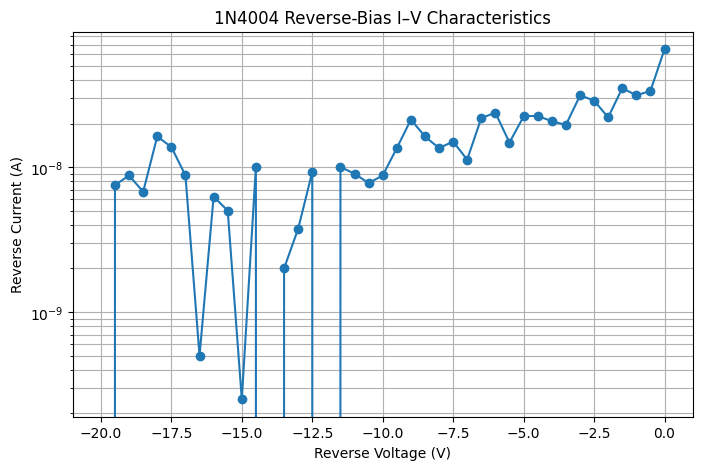

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Check the measurements
print("Voltage range:", df_reverse["v_meas"].min(),
      "to", df_reverse["v_meas"].max(), "V")

print("Current range:", df_reverse["i_meas"].min(),
      "to", df_reverse["i_meas"].max(), "A")

print("Missing values:\n", df_reverse.isnull().sum())
print("Duplicate rows:", df_reverse.duplicated().sum())

# Plot reverse-bias measurements
plt.figure(figsize=(8, 5))
plt.semilogy(
    df_reverse["v_meas"],
    df_reverse["i_meas"],
    "o-"
)
plt.xlabel("Reverse Voltage (V)")
plt.ylabel("Reverse Current (A)")
plt.title("1N4004 Reverse-Bias I–V Characteristics")
plt.grid(True, which="both")
plt.show()

In [ ]:
# Show measurements with negative or zero current
unusual = df_reverse[df_reverse["i_meas"] <= 0]

print("Negative or zero current measurements:")
display(unusual)

# Show all measurements sorted by voltage
print("All measurements sorted by voltage:")
display(df_reverse.sort_values("v_meas").reset_index(drop=True))

Negative or zero current measurements:


,v_set,v_meas,i_meas
24,-12.0,-12.000058,-9.224251e-08
28,-14.0,-14.000110,0.000000e+00
40,-20.0,-20.000098,-4.761532e-09


All measurements sorted by voltage:


,v_set,v_meas,i_meas
0,-20.0,-20.000098,-4.761532e-09
1,-19.5,-19.500090,7.518203e-09
2,-19.0,-19.000140,8.771237e-09
3,-18.5,-18.500134,6.766384e-09
4,-18.0,-18.000130,1.628944e-08
5,-17.5,-17.500080,1.378337e-08
6,-17.0,-17.000050,8.771237e-09
7,-16.5,-16.500082,5.012142e-10
8,-16.0,-16.000110,6.265170e-09
9,-15.5,-15.500140,5.012136e-09


Original measurements: 41
Measurements retained: 38
Measurements excluded: 3

Cleaned dataset:


,v_set,v_meas,i_meas
0,-19.5,-19.500090,7.518203e-09
1,-19.0,-19.000140,8.771237e-09
2,-18.5,-18.500134,6.766384e-09
3,-18.0,-18.000130,1.628944e-08
4,-17.5,-17.500080,1.378337e-08


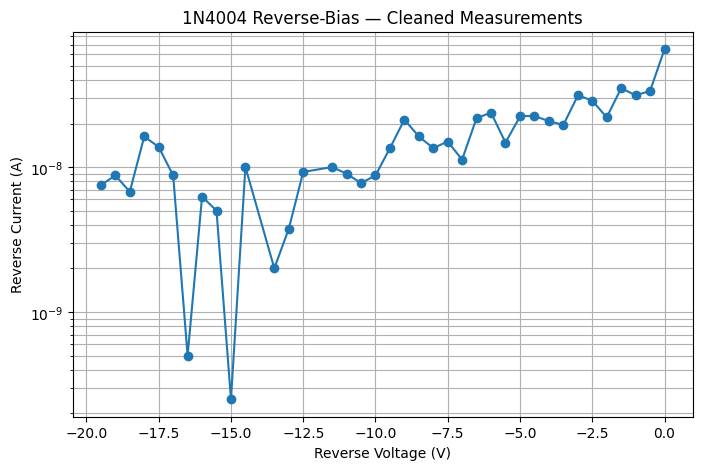

In [ ]:
# Keep only measurements with positive current
df_reverse_clean = df_reverse[
    df_reverse["i_meas"] > 0
].copy()

# Sort by measured voltage
df_reverse_clean = df_reverse_clean.sort_values(
    "v_meas"
).reset_index(drop=True)

print("Original measurements:", len(df_reverse))
print("Measurements retained:", len(df_reverse_clean))
print("Measurements excluded:", len(df_reverse) - len(df_reverse_clean))

print("\nCleaned dataset:")
display(df_reverse_clean.head())

# Plot cleaned measurements
plt.figure(figsize=(8, 5))
plt.semilogy(
    df_reverse_clean["v_meas"],
    df_reverse_clean["i_meas"],
    "o-"
)
plt.xlabel("Reverse Voltage (V)")
plt.ylabel("Reverse Current (A)")
plt.title("1N4004 Reverse-Bias — Cleaned Measurements")
plt.grid(True, which="both")
plt.show()

In [ ]:
# Sort measurements by voltage
df_reverse_clean = df_reverse_clean.sort_values(
    "v_meas"
).reset_index(drop=True)

# Select 8 test rows spread across the voltage range
test_indices = list(range(2, 38, 5))

test_data = df_reverse_clean.iloc[test_indices].copy()
train_data = df_reverse_clean.drop(test_indices).copy()

# Input: measured voltage
X_train = train_data[["v_meas"]]
X_test = test_data[["v_meas"]]

# Target: log10 of reverse-current magnitude
y_train = np.log10(train_data["i_meas"])
y_test = np.log10(test_data["i_meas"])

print("Training measurements:", len(X_train))
print("Testing measurements:", len(X_test))

print("\nTraining voltage range:")
print(X_train.min(), "to", X_train.max())

print("\nTesting measurements:")
display(test_data[["v_meas", "i_meas"]])

Training measurements: 30
Testing measurements: 8

Training voltage range:
v_meas   -19.50009
dtype: float64 to v_meas   -0.500739
dtype: float64

Testing measurements:


,v_meas,i_meas
2,-18.500134,6.766384e-09
7,-16.000110,6.265170e-09
12,-13.000180,3.759101e-09
17,-10.000270,8.771237e-09
22,-7.503940,1.503641e-08
27,-4.991236,2.255461e-08
32,-2.501673,2.881978e-08
37,-0.000706,6.515776e-08


In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

# Define the four models
models = {
    "Mean baseline": DummyRegressor(strategy="mean"),

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),

    "SVR": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=10, epsilon=0.05)
    )
}

results = []
trained_models = {}

# Train and evaluate each model
for name, model in models.items():

    model.fit(X_train, y_train)

    # Predict log-current
    predicted_log = model.predict(X_test)

    # Convert predictions back to current in amperes
    predicted_current = 10 ** predicted_log
    actual_current = 10 ** y_test

    # Calculate errors
    mae = mean_absolute_error(actual_current, predicted_current)
    rmse = np.sqrt(mean_squared_error(actual_current, predicted_current))
    r2 = r2_score(y_test, predicted_log)

    results.append({
        "Model": name,
        "MAE (A)": mae,
        "RMSE (A)": rmse,
        "R² (log scale)": r2
    })

    trained_models[name] = model

# Display comparison
results_df = pd.DataFrame(results)
display(results_df.sort_values("MAE (A)"))

,Model,MAE (A),RMSE (A),R² (log scale)
3,SVR,5.544070e-09,1.080349e-08,0.860048
1,Linear Regression,6.188024e-09,1.152754e-08,0.786826
2,Random Forest,6.543093e-09,1.196322e-08,0.706814
0,Mean baseline,1.325083e-08,2.094689e-08,-0.044512


In [ ]:
# Get predictions from the trained SVR model
svr_model = trained_models["SVR"]

predicted_log = svr_model.predict(X_test)

# Convert log-current predictions back to amperes
predicted_current = 10 ** predicted_log
actual_current = 10 ** y_test

# Calculate errors
comparison = pd.DataFrame({
    "Voltage (V)": X_test["v_meas"].values,
    "Actual Current (A)": actual_current,
    "Predicted Current (A)": predicted_current
})

comparison["Absolute Error (A)"] = abs(
    comparison["Actual Current (A)"] -
    comparison["Predicted Current (A)"]
)

comparison["Percentage Error (%)"] = (
    comparison["Absolute Error (A)"] /
    comparison["Actual Current (A)"]
) * 100

display(comparison.round(12))

print(
    "Mean percentage error:",
    comparison["Percentage Error (%)"].mean()
)

NameError: name 'trained_models' is not defined

In [ ]:
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Recreate and train the SVR model
svr_model = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=10, epsilon=0.05)
)

svr_model.fit(X_train, y_train)

# Predict test currents
predicted_log = svr_model.predict(X_test)

predicted_current = 10 ** predicted_log
actual_current = 10 ** y_test.to_numpy()

# Compare actual and predicted values
comparison = pd.DataFrame({
    "Voltage (V)": X_test["v_meas"].to_numpy(),
    "Actual Current (A)": actual_current,
    "Predicted Current (A)": predicted_current
})

comparison["Absolute Error (A)"] = abs(
    comparison["Actual Current (A)"] -
    comparison["Predicted Current (A)"]
)

comparison["Percentage Error (%)"] = (
    comparison["Absolute Error (A)"] /
    comparison["Actual Current (A)"]
) * 100

display(comparison.round(12))

print(
    "Mean percentage error:",
    comparison["Percentage Error (%)"].mean()
)

NameError: name 'X_train' is not defined

In [ ]:
import pandas as pd
import numpy as np

from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Check whether the original dataset is available
if "df_reverse" not in globals():
    from google.colab import files
    uploaded = files.upload()
    file_name = next(iter(uploaded))
    df_reverse = pd.read_csv(file_name)

# 2. Keep positive-current measurements
df_reverse_clean = df_reverse[
    df_reverse["i_meas"] > 0
].copy()

# 3. Sort by voltage
df_reverse_clean = df_reverse_clean.sort_values(
    "v_meas"
).reset_index(drop=True)

# 4. Recreate the same training/testing split
test_indices = list(range(2, 38, 5))

test_data = df_reverse_clean.iloc[test_indices].copy()
train_data = df_reverse_clean.drop(test_indices).copy()

X_train = train_data[["v_meas"]]
X_test = test_data[["v_meas"]]

y_train = np.log10(train_data["i_meas"])
y_test = np.log10(test_data["i_meas"])

# 5. Train SVR
svr_model = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=10, epsilon=0.05)
)

svr_model.fit(X_train, y_train)

# 6. Predict test currents
predicted_log = svr_model.predict(X_test)

predicted_current = 10 ** predicted_log
actual_current = 10 ** y_test.to_numpy()

# 7. Compare predictions
comparison = pd.DataFrame({
    "Voltage (V)": X_test["v_meas"].to_numpy(),
    "Actual Current (A)": actual_current,
    "Predicted Current (A)": predicted_current
})

comparison["Absolute Error (A)"] = abs(
    comparison["Actual Current (A)"] -
    comparison["Predicted Current (A)"]
)

comparison["Percentage Error (%)"] = (
    comparison["Absolute Error (A)"] /
    comparison["Actual Current (A)"]
) * 100

display(comparison)

# 8. Evaluation
print("Training measurements:", len(X_train))
print("Testing measurements:", len(X_test))
print("MAE (A):", mean_absolute_error(actual_current, predicted_current))
print("RMSE (A):", np.sqrt(mean_squared_error(actual_current, predicted_current)))
print("R² (log scale):", r2_score(y_test, predicted_log))
print("Mean percentage error (%):", comparison["Percentage Error (%)"].mean())

Saving 1n4004_reverse.csv to 1n4004_reverse.csv


,Voltage (V),Actual Current (A),Predicted Current (A),Absolute Error (A),Percentage Error (%)
0,-18.500134,6.766384e-09,9.424234e-09,2.657851e-09,39.280227
1,-16.000110,6.265170e-09,6.205630e-09,5.953981e-11,0.950330
2,-13.000180,3.759101e-09,6.024339e-09,2.265238e-09,60.260101
3,-10.000270,8.771237e-09,1.249110e-08,3.719858e-09,42.409734
4,-7.503940,1.503641e-08,1.555008e-08,5.136717e-10,3.416185
5,-4.991236,2.255461e-08,1.887424e-08,3.680365e-09,16.317574
6,-2.501673,2.881978e-08,2.721864e-08,1.601141e-09,5.555703
7,-0.000706,6.515776e-08,3.530286e-08,2.985490e-08,45.819401


Training measurements: 30
Testing measurements: 8
MAE (A): 5.544070106150688e-09
RMSE (A): 1.0803493359362025e-08
R² (log scale): 0.8600478897431922
Mean percentage error (%): 26.75115707887161


In [ ]:
# Search previously executed notebook cells for the reverse-bias SVR code

keywords = ["SVR", "svr_model", "train_test_split",
            "StandardScaler", "mean_absolute_error"]

for i, cell in enumerate(In, start=1):
    if any(word.lower() in cell.lower() for word in keywords):
        print(f"\n{'='*60}")
        print(f"CELL {i}")
        print('='*60)
        print(cell)


CELL 2
# Get predictions from the trained SVR model
svr_model = trained_models["SVR"]

predicted_log = svr_model.predict(X_test)

# Convert log-current predictions back to amperes
predicted_current = 10 ** predicted_log
actual_current = 10 ** y_test

# Calculate errors
comparison = pd.DataFrame({
    "Voltage (V)": X_test["v_meas"].values,
    "Actual Current (A)": actual_current,
    "Predicted Current (A)": predicted_current
})

comparison["Absolute Error (A)"] = abs(
    comparison["Actual Current (A)"] -
    comparison["Predicted Current (A)"]
)

comparison["Percentage Error (%)"] = (
    comparison["Absolute Error (A)"] /
    comparison["Actual Current (A)"]
) * 100

display(comparison.round(12))

print(
    "Mean percentage error:",
    comparison["Percentage Error (%)"].mean()
)

CELL 3
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Recreate and train the SVR model

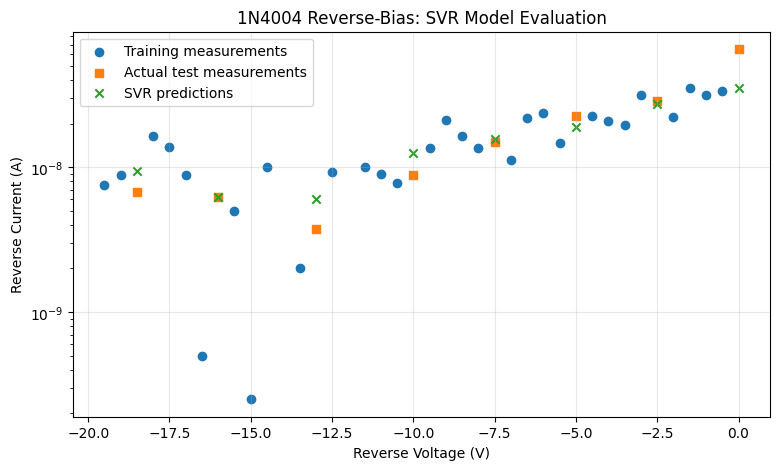

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.scatter(
    X_train["v_meas"],
    10**y_train,
    label="Training measurements"
)

plt.scatter(
    X_test["v_meas"],
    10**y_test,
    label="Actual test measurements",
    marker="s"
)

plt.scatter(
    X_test["v_meas"],
    predicted_current,
    label="SVR predictions",
    marker="x"
)

plt.yscale("log")
plt.xlabel("Reverse Voltage (V)")
plt.ylabel("Reverse Current (A)")
plt.title("1N4004 Reverse-Bias: SVR Model Evaluation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, KFold

# Create the SVR pipeline
pipeline = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf")
)

# Parameter combinations to compare
param_grid = {
    "svr__C": [0.1, 1, 10, 100],
    "svr__epsilon": [0.01, 0.05, 0.1, 0.2],
    "svr__gamma": ["scale", 0.1, 1]
}

# Five-fold cross-validation on training data only
cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

# Fit using training data only
grid_search.fit(X_train, y_train)

# Display the best parameters
print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation MAE (log-current scale):")
print(-grid_search.best_score_)

Best parameters:
{'svr__C': 100, 'svr__epsilon': 0.1, 'svr__gamma': 'scale'}

Best cross-validation MAE (log-current scale):
0.19814962299519637


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Get the best tuned model
best_svr = grid_search.best_estimator_

# Predict test data
tuned_predicted_log = best_svr.predict(X_test)

# Convert log current to amperes
tuned_predicted_current = 10 ** tuned_predicted_log
actual_current = 10 ** y_test.to_numpy()

# Calculate metrics
mae = mean_absolute_error(actual_current, tuned_predicted_current)
rmse = np.sqrt(mean_squared_error(actual_current, tuned_predicted_current))
r2 = r2_score(y_test, tuned_predicted_log)

print("Tuned SVR Test Results")
print("----------------------")
print("MAE (A):", mae)
print("RMSE (A):", rmse)
print("R² (log scale):", r2)

# Compare predictions
comparison_tuned = pd.DataFrame({
    "Voltage (V)": X_test["v_meas"].to_numpy(),
    "Actual Current (A)": actual_current,
    "Predicted Current (A)": tuned_predicted_current
})

display(comparison_tuned)

Tuned SVR Test Results
----------------------
MAE (A): 7.3495309325973895e-09
RMSE (A): 1.4425923018605269e-08
R² (log scale): 0.7453527216854352


,Voltage (V),Actual Current (A),Predicted Current (A)
0,-18.500134,6.766384e-09,1.258535e-08
1,-16.000110,6.265170e-09,5.092527e-09
2,-13.000180,3.759101e-09,3.891350e-09
3,-10.000270,8.771237e-09,1.404876e-08
4,-7.503940,1.503641e-08,1.703338e-08
5,-4.991236,2.255461e-08,1.979833e-08
6,-2.501673,2.881978e-08,2.701418e-08
7,-0.000706,6.515776e-08,2.532175e-08


In [ ]:
print("Original SVR:", svr_model)
print("Tuned SVR:", best_svr)
print("Original model fitted:", hasattr(svr_model[-1], "support_vectors_"))

Original SVR: Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svr', SVR(C=10, epsilon=0.05))])
Tuned SVR: Pipeline(steps=[('standardscaler', StandardScaler()), ('svr', SVR(C=100))])
Original model fitted: True


In [ ]:
import joblib
import os

# Save the original fitted SVR pipeline
model_path = "/content/1n4004_reverse_svr_model.joblib"

joblib.dump(svr_model, model_path)

print("Model saved successfully!")
print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")

# Download model
from google.colab import files
files.download(model_path)

Model saved successfully!
File size: 2.68 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>